# Quantile Alpha
### A rules-based U.S. large-cap momentum strategy

**2270 Financial Modeling · Group assignment · Research notebook**

| | |
|---|---|
| Moodle group | BC |
| Group members | Benedikt Proebstl, Leo Johannes Oskar Heppe, Elias Jannis Wolf, Fabian Oscar Bergvall, Frederik Ronning, Mareike Adriana Czakert |
| Investor prospectus | `investor_prospectus.pdf` in the repository. Its figures and every number it quotes are produced in section 12.6. |
| Streamlit app | *to be completed by the group: the URL is entered here once the app (`tracker_app.py` in the repository) has been deployed and the link checked* |
| GitHub repository | <https://github.com/benediktproebstl/quantile-alpha> |

This notebook reproduces every number, table and figure of the prospectus. It runs from top to bottom in a fresh Google Colab session; all data are retrieved through APIs and nothing has to be uploaded.

---

## 0. The strategy in brief

**What the portfolio holds.** Individual U.S. large-cap stocks: the fifth of the S&P 500's members with the strongest risk-adjusted price momentum, about 75 to 100 stocks, **weighted by company size and momentum score**. Long-only, fully invested, in USD, without leverage, short selling, derivatives or any market-timing overlay.

**How it is managed.** The strategy applies the published construction rules of the **S&P 500 Momentum index**. Twice a year, at the end of February and August, every eligible index member is scored by its price change over twelve months, leaving out the most recent month, divided by the volatility of its daily price changes. The best fifth is selected, with a buffer that favours stocks already held. Each selected stock is weighted by its market value times its momentum score, with a limit of 9% per stock when the weights are set. The trades are made at the end of March and September; in between nothing is traded and the weights drift with prices. Every dollar bought or sold is charged 10 basis points.

**What that means in practice.** Because weights follow company size, **a small number of very large companies make up a large part of the portfolio**: the ten largest positions hold about half of the money. This concentration is the strategy's main specific risk (sections 6.4, 8.3 and 9).

**Benchmarks.** The primary benchmark is **SPY**, the S&P 500 index fund a U.S. retail investor would hold instead. A second benchmark, the **cap-weighted universe** (all eligible stocks by market value, same schedule and costs), separates what the momentum rules add from what the data add. The backtest is also checked against **SPMO**, a real fund that has tracked the S&P 500 Momentum index since 2015.

**Sample.** January 2016 to December 2025 (120 monthly returns). The start is set by the data: Yahoo Finance reports share counts, which the weights need, from October 2015.

### Target client

A **U.S. retail investor** with USD as home currency who

* invests for **at least ten years** and does not need to withdraw from this money in the meantime,
* has a **high tolerance for risk**: equity-like drawdowns of 25% or more, large positions in a few companies and several years of lagging the market must be bearable, financially and psychologically,
* already holds a diversified core portfolio and is looking for a rules-based **satellite** position in U.S. equities,
* can use a broker with commission-free trading and **fractional shares**, ideally in a tax-advantaged account.

**Why these assets suit that client.** S&P 500 stocks are the most liquid equities in the client's home market: they trade at tight spreads, are available in fractional shares at every large U.S. retail broker, carry no currency risk for a USD investor, and are companies the client knows. A transparent ranking rule on public prices can be checked by the client line by line, which a discretionary product cannot.

**Who it does not suit.** Anyone who needs the money within a few years, cannot tolerate a large temporary loss, would abandon the rule after a bad stretch, has only a small amount to invest (section 9.2), or holds it in a taxable account without regard to the tax drag. There is **no capital protection and no guaranteed return, and past performance is not a reliable guide to future performance**. Whether the strategy is worth holding next to or instead of the index fund is what this notebook examines; the answer is in section 12.

### Why momentum might work, and why it might not

Stocks that have outperformed over the past three to twelve months have, on average, continued to outperform over the following months. Jegadeesh and Titman (1993) documented this for U.S. stocks from 1965 to 1989, and Carhart (1997) made a momentum factor a standard ingredient of performance evaluation. Asness, Moskowitz and Pedersen (2013) find the pattern in many countries and asset classes.

The explanations fall into two groups, and none is settled:

* **Behavioural.** Investors may underreact to news, so that information is absorbed into prices gradually (Hong and Stein, 1999; Barberis, Shleifer and Vishny, 1998); overconfidence can make them push trends too far (Daniel, Hirshleifer and Subrahmanyam, 1998); and the reluctance to sell losers and eagerness to sell winners slows price adjustment (Grinblatt and Han, 2005). Investors who chase recent winners, professional ones included, can reinforce the trend (the "momentum traders" in Hong and Stein's model), and the mispricing can persist because arbitrage is risky and capital-constrained (Shleifer and Vishny, 1997).
* **Risk-based.** Momentum returns may be compensation for a risk that shows up rarely but severely. Daniel and Moskowitz (2016) show that momentum strategies suffer "crashes", mostly when markets rebound after a decline and past losers recover fastest.

Three reasons for caution apply specifically to this strategy. The effect is weaker among large, widely followed stocks than among small ones (Hong, Lim and Stein, 2000). Trading costs matter: Lesmond, Schill and Zhou (2004) argue that momentum profits largely disappear after costs, while Korajczyk and Sadka (2004) find them robust only up to moderate fund sizes. And most academic evidence concerns **long-short** portfolios; a long-only portfolio of winners keeps full market exposure and has to beat the index, not cash. The most recent month is skipped because of the short-term reversal documented by Jegadeesh (1990). Dividing momentum by volatility, as the index rules do, favours stocks that rose steadily over stocks that rose in a few jumps.

None of these studies proves that momentum *causes* higher returns, and none guarantees the pattern continues. Full references are in section 12.

### Contents

1. Setup, dependencies and configuration
2. Data: sources, retrieval and adjustments
3. Historical universe and data quality
4. Methodology: momentum score, selection, weights, timing, accounting, performance measures
5. Backtest and checks against real funds
6. Performance and risk
7. Does the momentum score predict returns here? Quintiles, spread, regressions
8. Robustness
9. Sector exposure, retail implementation, risk and bias audit
10. Monte Carlo simulation
11. Validation
12. Conclusions, references, AI disclosure, and the figures of the prospectus

## 1. Setup, dependencies and configuration

**How to run.** In Google Colab choose *Runtime → Run all*. Nothing has to be uploaded: every number, table and figure below is rebuilt from data pulled live through APIs. A full run takes about five to fifteen minutes, most of it two Yahoo Finance downloads: daily prices and the history of shares outstanding for roughly 700 symbols.

**Credentials.** None are required. The FRED series are read from the official FRED API when a `FRED_API_KEY` is available (Colab *Secrets* panel or an environment variable) and otherwise from FRED's official key-less CSV endpoint. The notebook prints which route it used; the key is never printed. A free key can be requested at <https://fred.stlouisfed.org/docs/api/api_key.html>.

**Code layout.** Cells that start with `# [engine]` hold the calculation engine. They are exported unchanged to `quantile_alpha/engine.py` in the GitHub repository, so the notebook, the automated tests and the future Streamlit app all run the same code.

In [1]:
# Colab ships with every package used here. This cell only installs what is missing,
# so it also works in a bare local environment (see requirements.txt in the repository).
import importlib.util, subprocess, sys

REQUIRED = {"yfinance": "yfinance", "statsmodels": "statsmodels", "lxml": "lxml",
            "scipy": "scipy", "matplotlib": "matplotlib", "requests": "requests"}
missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("installed now:", missing if missing else "nothing (all dependencies already present)")

installed now: nothing (all dependencies already present)


In [2]:
# [engine] exported to the repo by tools/export_engine.py - see the README
import os, io, re, math, time, logging, warnings, datetime as dt
from dataclasses import dataclass, replace, asdict

import numpy as np
import pandas as pd
import requests
import statsmodels.api as sm
import yfinance as yf

logging.getLogger("yfinance").setLevel(logging.CRITICAL)   # failed (delisted) tickers are logged by us instead

USER_AGENT = "quantile-alpha-student-notebook/1.0 (python-requests)"   # sent to Wikipedia only
DATA_LOG = []   # one provenance record per data request: provider, query, returned range, retrieval time


@dataclass(frozen=True)
class Config:
    """Every assumption of the strategy and the backtest in one place."""
    # --- sample: holding months, inclusive. Hard-coded. Yahoo's share counts start in October 2015
    first_holding_month: str = "2016-01"           # Jan 2016 - Dec 2025 (120 months)
    last_holding_month: str = "2025-12"
    # --- raw daily data window. NOTE: yfinance treats `end` as exclusive
    data_start: str = "2014-06-01"                 # the first signal needs prices from October 2014
    data_end_exclusive: str = "2026-01-01"
    # --- signal (S&P Momentum Indices Methodology, Appendix A and B)
    lookback: int = 12                             # momentum value: price change over 12 months ...
    fallback_lookback: int = 9                     # ... or over 9 months for a stock without a price 12 months back
    skip: int = 1                                  # ... ending one month before the reference date
    min_trading_days: int = 150                    # traded on at least 150 days of the measurement period
    risk_adjust: bool = True                       # momentum value divided by the volatility of daily price changes
    winsor_z: float = 3.0                          # z-scores are capped at +/- 3
    # --- selection and weights
    n_groups: int = 5                              # quintiles; the strategy holds the highest one
    target_count: int = 0                          # number of stocks held; 0 = one fifth of the eligible stocks
    target_shift: int = 0                          # added to that fifth (-1 or +1: how much does the last place matter?)
    buffer: float = 0.20                           # 20% buffer rule that favours stocks already held
    weighting: str = "cap_score"                   # market capitalisation x momentum score
    max_weight: float = 0.09                       # on the reference date a stock's weight is at most 9% ...
    max_cap_multiple: float = 3.0                  # ... and at most 3 times its market-cap weight among the holdings
    cap_reference: str = "holdings"                # "holdings" (base case) or "universe": see section 4.3
    reference_lag: int = 1                         # reference date = month-end before the trade date
    rebalance_months: tuple = (3, 9)               # trade at the last close of March and September
    cost_rate: float = 0.0010                      # 10 basis points per dollar bought or sold
    # --- market capitalisation: Yahoo's share counts
    share_confirm: float = 0.25                    # a count more than 25% away from the last one needs a second count (None = off)
    share_gap_days: int = 180                      # a silence of more than 180 days counts as a gap in a stock's share counts
    share_skip_before_outage: bool = True          # leave out the count directly before Yahoo's general outage of 2017-18
    share_carry_back_days: int = 120               # a stock's first count may be carried back at most this far (flagged)
    share_ticker_history: bool = True              # read counts under the ticker of the time (False: today's symbol only)
    # --- benchmarks and risk-free proxy
    benchmark: str = "SPY"                         # investable S&P 500 total-return proxy
    momentum_fund: str = "SPMO"                    # real fund on the S&P 500 Momentum index: check of the replication
    market_index: str = "^SP500TR"                 # long history for the Monte Carlo regime estimates
    rf_series: str = "DGS3MO"                      # 3-month Treasury constant-maturity yield (FRED)
    recession_series: str = "USREC"                # NBER recession indicator (FRED)
    # --- historical index membership: pinned Wikipedia revisions (identical tables on every run)
    wiki_constituents_revid: int = 1384572480      # "List of S&P 500 companies", revision of 2026-11-08
    wiki_changes_revid: int = 1387311792           # "Historical components of the S&P 500", revision of 2026-11-23
    # --- data-quality gates
    gate_min_names: int = 400
    gate_min_coverage: float = 0.95
    gate_min_tracking: float = 0.99                # correlation of the cap-weighted universe with SPY
    # --- statistics and simulation
    seed: int = 2270
    bootstrap_reps: int = 2000
    bootstrap_block: int = 6
    random_portfolios: int = 1000
    mc_paths: int = 10000
    mc_years: int = 10
    mc_regime_start: str = "1947-01"               # post-war business cycles for the transition matrix
    mc_market_start: str = "1988-01"               # first full month of the S&P 500 total-return index on Yahoo


CFG = Config()


def P(month):
    """Month label -> pandas monthly Period."""
    return pd.Period(month, freq="M")

In [3]:
import platform, scipy, matplotlib, statsmodels
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RUN_STARTED = dt.datetime.now(dt.timezone.utc)
print("run started (UTC):", RUN_STARTED.strftime("%Y-%m-%d %H:%M"))
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__,
      "| matplotlib", matplotlib.__version__, "| yfinance", yf.__version__, "| requests", requests.__version__)

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
warnings.filterwarnings("ignore", category=FutureWarning)

display(pd.Series(asdict(CFG), name="value").to_frame())

# ---- presentation helpers (no calculations here) ----
# Colours: white background, navy text, blue / teal accents. The three series colours and the five-step
# blue ramp for the quintiles were checked for colour-blind separation before use.
INK, INK2, MUTED, GRID, AXIS = "#14213d", "#43506b", "#7a8599", "#e6e8ee", "#c2c8d3"
BLUE, TEAL, ORANGE, RED, GREY = "#2a78d6", "#1baf7a", "#eb6834", "#e34948", "#9aa3b2"
RAMP5 = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]          # Q1 (light) ... Q5 (dark)
LABEL = {"Strategy": "Quantile Alpha", "SPY": "S&P 500 (SPY)", "Universe": "Cap-weighted universe",
         "SPMO": "S&P 500 Momentum fund (SPMO)"}
COLOR = {"Strategy": BLUE, "SPY": TEAL, "Universe": ORANGE, "SPMO": GREY}
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "figure.dpi": 110,
    "savefig.dpi": 200, "font.size": 9.5, "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS,
    "axes.titlecolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "legend.frameon": False, "legend.fontsize": 9})

OUT_DIR = os.environ.get("QA_OUTPUT_DIR", "outputs")
os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True); os.makedirs(os.path.join(OUT_DIR, "tables"), exist_ok=True)

def savefig(fig, name):
    """Save a figure for the prospectus (200 dpi PNG) and show it."""
    fig.savefig(os.path.join(OUT_DIR, "figures", name + ".png"), bbox_inches="tight")
    plt.show()

def savetable(df, name):
    """Save a table for the prospectus at full precision."""
    df.to_csv(os.path.join(OUT_DIR, "tables", name + ".csv"))
    return df

def say(text):
    """Text whose numbers are filled in from the results of this run."""
    display(Markdown(text))

def pct(x, d=1):  return "n/a" if pd.isna(x) else f"{x * 100:.{d}f}%"
def pp(x, d=1):   return "n/a" if pd.isna(x) else f"{x * 100:+.{d}f} pp"
def num(x, d=2):  return "n/a" if pd.isna(x) else f"{x:.{d}f}"
def pick(flag, yes, no): return yes if flag else no

def end_label(ax, x, y, text, color):
    """Marker with a white ring at the end of a line and a label in text colour next to it."""
    ax.plot([x], [y], marker="o", ms=7, color=color, mec="white", mew=1.6, zorder=5, clip_on=False)
    ax.annotate(text, (x, y), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK,
                annotation_clip=False)

def percent_axis(ax, which="y", decimals=None):
    """Percent tick labels that never round a tick away (2.5% is shown as 2.5%, not 2%)."""
    from matplotlib.ticker import FuncFormatter
    def fmt(v, _):
        d = decimals if decimals is not None else (0 if abs(v * 100 - round(v * 100)) < 1e-6 else 1)
        return f"{v * 100:.{d}f}%"
    (ax.yaxis if which == "y" else ax.xaxis).set_major_formatter(FuncFormatter(fmt))

def days(n):
    """Bar width on a date axis (a plain number would be read as nanoseconds)."""
    return pd.Timedelta(days=n)

def end_labels(ax, x, values, colors, texts, min_gap, shift_days=60):
    """Markers at the line ends with value labels in a column to the right. Labels that would collide are moved
    apart and tied to their marker with a thin leader line, so no label floats away from its line."""
    order = sorted(values, key=values.get)
    pos, last = {}, -np.inf
    for k in order:
        pos[k] = max(values[k], last + min_gap); last = pos[k]
    x_text = x + np.timedelta64(shift_days, "D")
    for k in order:
        ax.plot([x], [values[k]], marker="o", ms=7, color=colors[k], mec="white", mew=1.6, zorder=5, clip_on=False)
        moved = abs(pos[k] - values[k]) > 1e-12
        ax.annotate(texts[k], xy=(x, values[k]), xytext=(x_text, pos[k]), textcoords="data", va="center", ha="left",
                    fontsize=9, color=INK, annotation_clip=False,
                    arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8, shrinkA=1, shrinkB=5) if moved else None)

def bar_labels(ax, xs, values, texts, fills):
    """Value labels inside the top of each bar: white on dark fills, dark on light fills."""
    dark = {"#2a78d6", "#1c5cab", "#0d366b"}
    for xk, v, t, f in zip(xs, values, texts, fills):
        ax.annotate(t, (xk, v), xytext=(0, -5), textcoords="offset points", ha="center", va="top", fontsize=8.5,
                    color="white" if f in dark else INK)

run started (UTC): 2026-11-25 03:16
python 3.11.4 | numpy 2.4.6 | pandas 2.2.3 | scipy 1.16.3 | statsmodels 0.15.0 | matplotlib 3.10.0 | yfinance 0.2.66 | requests 2.32.4


,value
first_holding_month,2016-01
last_holding_month,2025-12
data_start,2014-06-01
data_end_exclusive,2026-01-01
lookback,12
fallback_lookback,9
skip,1
min_trading_days,150
risk_adjust,True
winsor_z,3.0


## 2. Data: sources, retrieval and adjustments

| What | Source | How it is retrieved | Frequency | Adjustments |
|---|---|---|---|---|
| Stock, SPY and SPMO prices | Yahoo Finance | `yfinance` (an unofficial, open-source interface to Yahoo's public data) | daily, turned into month-end | `auto_adjust=False` is set explicitly. **Returns** use **Adj Close**, which Yahoo adjusts for splits, dividends and spin-off distributions, so ratios of adjusted prices approximate total returns. The **momentum signal** uses **Close** (adjusted for splits only), because the index rules measure price changes without dividends. |
| Shares outstanding | Yahoo Finance | `yfinance` (`get_shares_full`), one request per symbol, including the former ticker symbols of renamed companies | irregular: about one count per quarter until mid-2017, almost none from August 2017 to mid-November 2018, several per month since | joined into one series per company, converted to today's split units and cleaned (rules below); market capitalisation = shares × price |
| Risk-free proxy | FRED, series `DGS3MO` | official FRED API (with key) or official FRED CSV endpoint (no key) | daily | annualised percentage yield converted to a monthly return, lagged so that only already-published values are used |
| Recession indicator | FRED, series `USREC` | same as above | monthly | none; used only in the Monte Carlo section, never for trading |
| S&P 500 total-return index | Yahoo Finance, `^SP500TR` | `yfinance` | daily, turned into month-end | none; used only for the Monte Carlo regime estimates |
| Index membership through time | Wikipedia, two pinned page revisions | MediaWiki API | event dates | none |

**Where the rules come from.** The construction rules follow the *S&P Momentum Indices Methodology* published by S&P Dow Jones Indices (edition of November 2026). Its list of changes shows none for the S&P 500 Momentum index during the sample period: one shortly before it (September 2015, the treatment of spin-offs) and one after it (September 2026, when the 9% limit was moved from each share class to the company as a whole). The document supplies rules only, no data. Section 4 states each rule and every point where this notebook has to deviate from it.

**Why a third source for membership.** Neither Yahoo Finance nor FRED publishes which companies were in the S&P 500 on a past date. Using today's members would let the backtest "know" which companies later became large enough to join, which is survivorship bias. The membership tables are therefore read from Wikipedia through its API, at fixed revision numbers so that every run sees exactly the same tables. They supply ticker lists and dates only; **all prices, returns and rates come from Yahoo Finance and FRED**. The use of this supplementary source was approved for the group on 24 November 2026 (to be confirmed by all members).

**One correction to Yahoo's adjusted prices.** Yahoo records some spin-offs twice, once as a split factor that is already built into its closing prices and once as a dividend, and its adjusted close then counts the distribution twice. The adjusted series shows a jump that never happened (Danaher on 5 July 2016: +61% instead of +4%). On every day on which a security has both a split factor and a dividend, the notebook therefore compares the adjusted-close return with the plain close return and uses the close return if it is the one nearer to the market's return that day. All such days and the decision taken are listed in section 3; nothing else in Yahoo's adjustments is changed. On days with a very large ordinary distribution (a special dividend of half the share price, for example) Yahoo's adjusted return assumes the payment is reinvested before that day's price move; this convention is kept.

**Share counts and market capitalisation.** Yahoo reports the number of shares outstanding as a series of dated counts. They are the weakest data in this notebook, so the rules that turn them into market values are stated in full, and section 3.2 shows what each rule does to the data.

1. *The right company.* As a rule, Yahoo files a count under the ticker the company had **at the time**, while the price history moves to the company's current symbol. Under its current symbol a renamed company then has no counts before the change of ticker, or it has the counts of whoever used that ticker before. (For some companies Yahoo carries the earlier counts over to the new symbol; those need no entry.) The table `TICKER_HISTORY` in section 3.1 lists the former symbols of the renamed index members; their counts are downloaded under those symbols and joined into one series per company. Where Yahoo has nothing under a former symbol, the company has no share count for that time and cannot be ranked.
2. *Split units.* Yahoo restates its closing prices for later stock splits, so each count is multiplied by the split factors that came after its date, including splits after December 2025 (the factors up to the day of the price download are used). Yahoo also lists spin-offs as "split factors" and divides the earlier prices by them, although a spin-off does not change the number of shares; these factors are undone on the price side instead. Market value = shares × Close × later spin-off factors, which is the share count times the price that was actually quoted on that day.
3. *Unit errors near splits.* Near a real stock split Yahoo's counts are unreliable about the unit: some are already post-split before the split date, others still pre-split after it. A count within 120 days of a split is therefore read in whichever unit is closest to the stock's counts further away from any split, earlier and later ones. Only the unit is chosen; the reported number itself is never changed.
4. *Yahoo's outage.* Between August 2017 and mid-November 2018 Yahoo has almost no counts for any company. The last count before this gap cannot be trusted: for the stocks that split inside the gap, most of these counts turn out to be in post-split units already, and for many other stocks they equal the first count after the gap to the last digit (section 3.2). These counts are left out, and the count before them is used instead. The count in use is therefore about four months old at the reference date of August 2017, and ten and sixteen months old at those of February and August 2018.
5. *A change needs a second count.* Yahoo's series contain one-off wrong values, and for companies with several share classes the classes are sometimes reported in turn. A count that differs from the last accepted one by more than a factor of 1.25 (more than 25% above or 20% below it) is therefore used only once the next count agrees with it. A real change, such as a merger paid in shares, takes effect with the second count that shows it: within days since late 2018, up to a quarter or more later before, and only after the outage where the second count is one that rule 4 leaves out.
6. *One figure per month-end.* The share count at a month-end is the latest accepted count on or before it. Yahoo's history starts in October 2015. A stock's first count is therefore carried **backwards** by at most 120 days and flagged; further back the stock has no share count and is not ranked. Section 8 shows the result without any carried-back count and with unlimited carrying back.

Later information enters in three stated places: the unit of a count near a split (rule 3), the removal of the count before the outage (rule 4, which takes information away and adds none) and the carried-back first count (rule 6). Everything else uses only counts dated on or before the reference date; section 11 rebuilds every share count used from those counts alone. A date, however, is what Yahoo says it is: its very first counts, from late 2015, show the same sign of later entry as the counts before the outage (section 3.2), and the first purchase rests on a first count for every stock.

What the rules cannot repair: Yahoo's counts are total shares, not the free float that the index uses; they are per company, so one share class per issuer carries the whole company's value, and for firms whose listed shares are only part of the firm (Interactive Brokers, Blackstone) the count covers the whole firm; a wrong value that Yahoo repeats over several counts is accepted; rule 3 can choose the wrong unit when a count near a split is wrong for another reason; and a ticker that changed hands without leaving a trace would go unnoticed. Yahoo also sometimes restates past prices without listing a factor; one such case was found inside the sample and is corrected by hand (`UNLISTED_PRICE_FACTORS`), others may exist. Section 5.2 tests the resulting market values against the SPY fund.

**All amounts are in USD.** The sample dates are set in `Config` above.

In [4]:
# [engine] exported to the repo by tools/export_engine.py - see the README
FRED_API_URL = "https://api.stlouisfed.org/fred/series/observations"
FRED_CSV_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv"
WIKI_API_URL = "https://en.wikipedia.org/w/api.php"


def http_get(url, params=None, headers=None, timeout=30, retries=4, pause=2.0):
    """GET with a timeout and bounded retries. The error message never contains query parameters (no key leaks)."""
    last = "no response"
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, timeout=timeout, headers=headers)
            if r.status_code == 200:
                return r
            last = f"HTTP {r.status_code}"
            if r.status_code in (400, 401, 403, 404):      # a retry cannot fix these
                break
        except requests.RequestException as exc:
            last = type(exc).__name__
        time.sleep(pause * (attempt + 1))
    raise RuntimeError(f"Request to {url} failed ({last}). This is an access/network problem, not missing data.")


def get_fred_api_key():
    """FRED key from the environment or from Colab Secrets; None if there is none. The key is never printed."""
    key = os.environ.get("FRED_API_KEY")
    if not key:
        try:
            from google.colab import userdata          # only exists inside Colab
            key = userdata.get("FRED_API_KEY")
        except Exception:
            key = None
    return key.strip() if key else None


def fred_series(series_id, start, end, api_key=None):
    """One FRED series as a float Series indexed by date (NaN where FRED reports no value, e.g. holidays)."""
    if api_key:
        r = http_get(FRED_API_URL, {"series_id": series_id, "api_key": api_key, "file_type": "json",
                                    "observation_start": start, "observation_end": end})
        obs = r.json()["observations"]
        raw = pd.Series([o["value"] for o in obs], index=[o["date"] for o in obs], dtype="object")
        route = "official FRED API (api.stlouisfed.org), key from environment / Colab secret"
    else:
        r = http_get(FRED_CSV_URL, {"id": series_id, "cosd": start, "coed": end})
        table = pd.read_csv(io.StringIO(r.text))
        raw = pd.Series(table.iloc[:, 1].values, index=table.iloc[:, 0].values, dtype="object")
        route = "official FRED CSV endpoint (fred.stlouisfed.org/graph/fredgraph.csv), no key"
    s = pd.to_numeric(raw, errors="coerce")
    s.index = pd.to_datetime(s.index)
    s = s.sort_index().rename(series_id)
    if s.notna().sum() == 0:
        raise RuntimeError(f"FRED returned no observations for {series_id}")
    DATA_LOG.append({"provider": "FRED", "query": series_id, "route": route, "requested": f"{start} to {end}",
                     "returned": f"{s.dropna().index[0].date()} to {s.dropna().index[-1].date()}", "rows": int(s.notna().sum()),
                     "retrieved_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M")})
    return s


def monthly_rf(yield_pct, sessions):
    """Monthly risk-free return for every holding month.

    yield_pct : daily DGS3MO, an annualised yield in percent.
    sessions  : Series, month (Period) -> last trading session of that month.
    The return for holding month m uses the last yield published strictly BEFORE the trade date
    (the final session of month m-1), so it was known when the month began:
        RF(m) = (1 + y / 100) ** (1 / 12) - 1
    A yield older than ten days is not used (the result is NaN): if the yield series stops before the price data
    do, the last value must not be carried forward silently.
    """
    y = yield_pct.dropna()
    out = {}
    for m in sessions.index[1:]:
        trade_date = sessions[m - 1]
        known = y.loc[: trade_date - pd.Timedelta(days=1)]
        fresh = len(known) > 0 and (trade_date - known.index[-1]).days <= 10
        out[m] = (1.0 + known.iloc[-1] / 100.0) ** (1.0 / 12.0) - 1.0 if fresh else np.nan
    return pd.Series(out, name="rf")


NO_DATA = "no data on Yahoo (delisted or unknown symbol)"
YAHOO_FIELDS = ["Close", "Adj Close", "Volume", "Dividends", "Stock Splits"]
RETRYABLE_MARKERS = ("rate limit", "too many requests", "timed out", "timeout", "connection", "temporarily", "429", "502", "503")


def _yahoo_messages():
    """Per-symbol error messages of the last yfinance download, where the installed version exposes them."""
    try:
        import yfinance.shared as shared
        return {k: str(v) for k, v in dict(getattr(shared, "_ERRORS", {})).items()}
    except Exception:
        return {}


def _yahoo_batch(symbols, start, end_exclusive):
    """One yfinance request. Returns ({symbol: frame with prices, volume, dividends, split factors}, {symbol: message})."""
    raw = yf.download(symbols, start=start, end=end_exclusive, auto_adjust=False, actions=True,
                      group_by="ticker", threads=True, progress=False, timeout=30)
    frames = {}
    for t in symbols:
        try:
            sub = raw[t] if isinstance(raw.columns, pd.MultiIndex) else raw
            df = sub.reindex(columns=YAHOO_FIELDS)
            df = df[df[["Close", "Adj Close"]].notna().any(axis=1)]
        except (KeyError, TypeError):
            continue
        if len(df):
            df.index = pd.to_datetime(df.index).tz_localize(None)
            frames[t] = df
    return frames, _yahoo_messages()


def yahoo_daily(tickers, start, end_exclusive, batch=100, retries=3, pause=1.0, canary="SPY"):
    """Daily Close, Adj Close, Volume, dividends and split factors for many tickers from Yahoo Finance.

    Returns a dict of tables (close, adj, volume, dividends, splits) and `status`, which records the outcome
    for EVERY requested ticker.
    A symbol Yahoo no longer carries must not be confused with a failed request, so every batch also asks for a
    reference symbol that certainly exists (`canary`): if not even that comes back, the request failed and the
    batch is retried; if it persists, the run stops instead of silently treating everything as missing. Symbols
    that return nothing are asked for a second time before they are finally recorded as having no data.
    """
    frames, status = {}, {}
    todo = list(dict.fromkeys(tickers))
    for attempt in range(retries + 1):
        failed = []
        for i in range(0, len(todo), batch):
            chunk = todo[i:i + batch]
            try:
                got, messages = _yahoo_batch(chunk if canary in chunk else chunk + [canary], start, end_exclusive)
            except Exception as exc:
                got, messages = {}, {t: type(exc).__name__ for t in chunk}
            if canary not in got:                       # nothing usable came back: a failed request, not missing data
                for t in chunk:
                    status[t] = "request failed"
                failed += chunk
                continue
            for t in chunk:
                message = messages.get(t, "")
                if t in got:
                    frames[t], status[t] = got[t], "ok"
                elif any(marker in message.lower() for marker in RETRYABLE_MARKERS):
                    status[t] = "request failed: " + message[:90]
                    failed.append(t)
                else:
                    status[t] = NO_DATA
            time.sleep(pause)
        todo = failed
        if not todo:
            break
        if attempt < retries:
            time.sleep(15 * (attempt + 1))
    if todo:
        raise RuntimeError(f"Yahoo requests kept failing for {len(todo)} tickers (e.g. {todo[:5]}): network or rate "
                           "limit problem, not missing data. Wait a few minutes and run the cell again.")
    missing = [t for t, outcome in status.items() if outcome == NO_DATA]
    for i in range(0, len(missing), batch):             # second look: a transient glitch must not pass as missing data
        chunk = missing[i:i + batch]
        try:
            got, _ = _yahoo_batch(chunk + [canary], start, end_exclusive)
        except Exception:
            got = {}
        for t in chunk:
            if t in got:
                frames[t], status[t] = got[t], "ok"
        time.sleep(pause)
    table = lambda field: pd.DataFrame({t: f[field] for t, f in frames.items()}).sort_index()
    close, adj, volume = table("Close"), table("Adj Close"), table("Volume")
    dividends, splits = table("Dividends").fillna(0.0), table("Stock Splits").fillna(0.0)
    DATA_LOG.append({"provider": "Yahoo Finance (yfinance " + yf.__version__ + ")",
                     "query": f"{len(status)} tickers, daily, auto_adjust=False, actions=True", "route": "yfinance.download",
                     "requested": f"{start} to {end_exclusive} (end exclusive)",
                     "returned": f"{adj.index[0].date()} to {adj.index[-1].date()}" if len(adj) else "nothing",
                     "rows": int(adj.notna().sum().sum()),
                     "retrieved_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M")})
    return {"close": close, "adj": adj, "volume": volume, "dividends": dividends, "splits": splits,
            "status": pd.Series(status, name="status")}


def repair_double_adjustments(adj, close, dividends, splits, calendar_ticker, min_gap=0.02):
    """Undo spin-offs that Yahoo adjusts twice.

    Yahoo records some spin-offs both as a split factor (already built into Close) and as a dividend, and its
    adjusted close then applies both: the distribution is counted twice and the adjusted series shows a jump that
    never happened (Danaher, 5 July 2016: +61% instead of +4%). Rule, applied on every day on which a security has
    a split factor AND a dividend: if the adjusted-close return and the close return differ by more than `min_gap`
    and the close return is the one nearer to the market's return that day, the adjusted prices before that day
    are rescaled so that the day shows the close return. Days on which the adjusted return is the nearer one (a
    real split and a real distribution on the same day) are left alone.

    Returns (adjusted prices to use, table of every split-and-dividend day with what was done).
    """
    market = adj[calendar_ticker].dropna()
    r_market = market / market.shift(1) - 1.0
    both = (splits.reindex(index=adj.index, columns=adj.columns).fillna(0.0) > 0) & \
           (dividends.reindex(index=adj.index, columns=adj.columns).fillna(0.0) > 0)
    fixed, rows = adj.copy(), []
    for t in adj.columns[both.any().to_numpy()]:
        for day in both.index[both[t].to_numpy()]:
            a, c = adj[t].loc[:day].dropna(), close[t].loc[:day].dropna()
            if len(a) < 2 or len(c) < 2 or a.index[-1] != day or c.index[-1] != day or day not in r_market.index:
                continue
            r_adj, r_close, r_mkt = a.iloc[-1] / a.iloc[-2] - 1.0, c.iloc[-1] / c.iloc[-2] - 1.0, r_market[day]
            use_close = bool(abs(r_adj - r_close) > min_gap and abs(r_close - r_mkt) < abs(r_adj - r_mkt))
            if use_close:
                fixed.loc[fixed.index < day, t] *= (1.0 + r_adj) / (1.0 + r_close)
            decision = "close return used" if use_close else "adjusted return kept"
            if min(abs(r_adj - r_mkt), abs(r_close - r_mkt)) > 0.20:
                decision += " (unresolved: neither return is near the market)"
            rows.append({"security": t, "day": day.date(), "split_factor": float(splits.at[day, t]),
                         "dividend": float(dividends.at[day, t]), "adj_close_return": r_adj, "close_return": r_close,
                         "market_return": r_mkt, "decision": decision})
    table = pd.DataFrame(rows, columns=["security", "day", "split_factor", "dividend", "adj_close_return", "close_return",
                                        "market_return", "decision"])
    return fixed, table


def later_split_factor(splits, date):
    """Product of all split factors after `date`, per security. Yahoo restates Close for later splits, so the price
    that was actually quoted on `date` is Close times this factor."""
    after = splits.loc[splits.index > pd.Timestamp(date)]
    return after.where(after > 0, 1.0).prod()


def is_share_split(factor, max_denominator=4):
    """True for a real stock split (2-for-1, 3-for-2, 1-for-8 ...). Yahoo also lists spin-offs as "split factors",
    with odd ratios such as 1.319; those change the price but not the number of shares."""
    f = float(factor)
    for den in range(1, max_denominator + 1):
        up = round(f * den)                               # forward split: f = up / den
        if up >= 1 and abs(f - up / den) <= 2e-4 * f:
            return True
        down = round(den / f)                             # reverse split: f = den / down (Yahoo rounds to 4 decimals)
        if down >= 1 and abs(f - den / down) <= 6e-5:
            return True
    return False


def _yahoo_share_history(symbol, start, end_exclusive):
    """One symbol's reported shares outstanding (yfinance get_shares_full); None if Yahoo has none."""
    s = yf.Ticker(symbol).get_shares_full(start=start, end=end_exclusive)
    if s is None or len(s) == 0:
        return None
    s = pd.Series(np.asarray(s, dtype=float), index=pd.DatetimeIndex(s.index).tz_localize(None).normalize())
    s = s[s > 0]
    return s[~s.index.duplicated(keep="last")].sort_index() if len(s) else None


def yahoo_shares(symbols, start, end_exclusive, workers=8, retries=3, pause=1.5, canary="AAPL"):
    """Reported shares outstanding through time for many symbols -> {"shares": {symbol: Series}, "status": Series}.

    Yahoo answers one symbol per request. A symbol without share data must not be confused with a failed request:
    the reference symbol `canary` is asked first and must return data, and a symbol that returns nothing or raises
    an error is asked again up to `retries` times before it is recorded as having no share counts.
    """
    from concurrent.futures import ThreadPoolExecutor

    def one(symbol):
        outcome = "no share counts on Yahoo"
        for attempt in range(retries + 1):
            try:
                s = _yahoo_share_history(symbol, start, end_exclusive)
                if s is not None:
                    return symbol, s, "ok"
                outcome = "no share counts on Yahoo"
            except Exception as exc:
                outcome = "request failed: " + type(exc).__name__
            time.sleep(pause * (attempt + 1))
        return symbol, None, outcome

    if one(canary)[1] is None:
        raise RuntimeError(f"Yahoo returned no share counts for {canary}: network or rate limit problem, not missing "
                           "data. Wait a few minutes and run the cell again.")
    todo = list(dict.fromkeys(symbols))
    shares, status = {}, {}
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for symbol, s, outcome in pool.map(one, todo):
            status[symbol] = outcome
            if s is not None:
                shares[symbol] = s
    failed = [t for t, o in status.items() if o.startswith("request failed")]
    if len(failed) > 0.05 * len(todo):
        raise RuntimeError(f"Yahoo share-count requests failed for {len(failed)} symbols (e.g. {failed[:5]}): network or "
                           "rate limit problem. Wait a few minutes and run the cell again.")
    first = min(s.index[0] for s in shares.values()); last = max(s.index[-1] for s in shares.values())
    DATA_LOG.append({"provider": "Yahoo Finance (yfinance " + yf.__version__ + ")",
                     "query": f"shares outstanding, {len(todo)} tickers", "route": "yfinance Ticker.get_shares_full",
                     "requested": f"{start} to {end_exclusive} (end exclusive)",
                     "returned": f"{first.date()} to {last.date()}", "rows": int(sum(len(s) for s in shares.values())),
                     "retrieved_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M")})
    return {"shares": shares, "status": pd.Series(status, name="status")}


def splice_ticker_history(counts, history):
    """One share-count series per CURRENT Yahoo symbol (see TICKER_HISTORY).

    counts  : {symbol: Series of reported counts}, former symbols included
    history : {current symbol: [(symbol, day), ...]} in time order: the counts filed under `symbol` are the
              company's until `day` (exclusive); from the last `day` on, the counts under the current symbol are.
    Counts that a company took from a former symbol are removed from that symbol's own series, so that today's user
    of the ticker does not inherit them.
    Returns ({symbol: Series}, table with one row per change of ticker: the last count before it and the first
    count after it, which agree when nothing but the ticker changed).
    """
    out = {k: v for k, v in counts.items() if k not in history}
    rows, nothing = [], pd.Series(dtype=float, index=pd.DatetimeIndex([]))
    for sym, hist in history.items():
        chain = [(s, pd.Timestamp(d)) for s, d in hist] + [(sym, None)]
        parts, lower = [], None
        for src, until in chain:
            seg = counts.get(src)
            seg = nothing if seg is None else seg
            if lower is not None:
                seg = seg[seg.index >= lower]
            if until is not None:
                seg = seg[seg.index < until]
            parts.append(seg)
            if src != sym and src in out and len(seg):      # these counts belong to `sym`, not to today's user of `src`
                out[src] = out[src].drop(seg.index)
            lower = until
        for k in range(len(chain) - 1):
            before, after = parts[k], parts[k + 1]
            rows.append({"company (Yahoo symbol)": sym, "counts filed under": chain[k][0], "until": chain[k][1].date(),
                         "last count before": float(before.iloc[-1]) if len(before) else np.nan,
                         "dated": before.index[-1].date() if len(before) else None,
                         "then under": chain[k + 1][0],
                         "first count after": float(after.iloc[0]) if len(after) else np.nan,
                         "dated ": after.index[0].date() if len(after) else None})
        joined = pd.concat([p for p in parts if len(p)]) if any(len(p) for p in parts) else nothing
        if len(joined):
            out[sym] = joined[~joined.index.duplicated(keep="last")].sort_index()
    table = pd.DataFrame(rows)
    if len(table):
        table["ratio"] = table["first count after"] / table["last count before"]
    return out, table


def clean_share_counts(counts, splits, window_days=120, span_days=730):
    """Yahoo's reported shares outstanding -> shares in today's split units, one Series per symbol.

    Each count is multiplied by the REAL stock-split factors that came after its date (is_share_split). Yahoo's Close
    is restated for those splits and also for spin-offs; a spin-off changes the price but not the number of shares,
    so spin-off factors are applied on the price side when market value is computed (price_only_factors).
    Near a real split Yahoo's counts are unreliable about the unit: some are already post-split before the split
    date, others still pre-split after it. A count within `window_days` of a real split is therefore read in
    whichever unit (as dated, times the factor, or divided by it) is closest to the stock's counts further away from
    any split (their median within `span_days`, before AND after it). This is the one place where a stock's later
    counts help to read an earlier one: they decide the unit only, the reported number is never changed.
    Returns ({symbol: Series}, number of counts whose unit was changed).
    """
    out, changed = {}, 0
    for sym, s in counts.items():
        if sym not in splits.columns:
            continue
        s = s[s > 0]
        s = s[~s.index.duplicated(keep="last")].sort_index()
        if not len(s):
            continue
        ev = splits[sym]
        ev = ev[ev > 0]
        real = ev[[is_share_split(f) for f in ev.to_numpy()]] if len(ev) else ev
        base = s.to_numpy(dtype=float)
        if len(real):
            suffix = np.append(np.cumprod(real.to_numpy(dtype=float)[::-1])[::-1], 1.0)   # product of the factors from j on
            base = base * suffix[np.searchsorted(real.index.values, s.index.values, side="right")]
            gap = np.abs((s.index.values[:, None] - real.index.values[None, :]) / np.timedelta64(1, "D"))
            near = gap.min(axis=1) <= window_days
            fixed = base.copy()
            for i in np.flatnonzero(near):
                calm = (~near) & (np.abs((s.index - s.index[i]).days) <= span_days)
                if not calm.any():
                    calm = ~near
                if not calm.any():
                    continue                              # no count away from a split: nothing to compare with
                level = np.median(base[calm])
                best, best_gap = base[i], abs(math.log(base[i] / level))
                for f in real[gap[i] <= window_days].to_numpy(dtype=float):
                    for candidate in (base[i] * f, base[i] / f):
                        g = abs(math.log(candidate / level))
                        if g < best_gap - 1e-9:
                            best, best_gap = candidate, g
                changed += int(best != base[i])
                fixed[i] = best
            base = fixed
        out[sym] = pd.Series(base, index=s.index)
    return out, changed


def price_only_factors(splits, sessions):
    """For each month-end session and symbol: the product of Yahoo's LATER "split factors" that are not real stock
    splits (spin-offs and similar events). Yahoo divides earlier Close prices by them although the number of shares
    did not change, so shares (in today's split units) x Close x this factor is the market value on that day."""
    arr = splits.to_numpy(dtype=float)
    g = np.ones_like(arr)
    for i, j in zip(*np.nonzero(arr > 0)):
        if not is_share_split(arr[i, j]):
            g[i, j] = arr[i, j]
    after = np.ones_like(g)
    after[:-1] = np.cumprod(g[::-1], axis=0)[::-1][1:]                # product of the factors AFTER each day
    out = pd.DataFrame(after, index=splits.index, columns=splits.columns).reindex(sessions.to_numpy())
    if out.isna().any().any():
        raise ValueError("a month-end session is missing from the table of split factors")
    out.index = sessions.index
    return out


def reporting_outage(counts, gap_days=180, majority=0.5):
    """Yahoo's general outage in reported share counts: the longest period during which more than `majority` of the
    symbols are inside a gap of more than `gap_days` between two of their own counts. Returns (first day, last day)
    or None if there is no such period."""
    marks, n = {}, 0
    for s in counts.values():
        if len(s) < 2:
            continue
        n += 1
        d = s.index.values
        for i in np.flatnonzero((d[1:] - d[:-1]) > np.timedelta64(int(gap_days), "D")):
            marks[d[i]] = marks.get(d[i], 0) + 1
            marks[d[i + 1]] = marks.get(d[i + 1], 0) - 1
    best, start, inside = None, None, 0
    for day in sorted(marks):
        inside += marks[day]
        if inside > majority * n and start is None:
            start = day
        elif inside <= majority * n and start is not None:
            if best is None or day - start > best[1] - best[0]:
                best = (start, day)
            start = None
    return None if best is None else (pd.Timestamp(best[0]), pd.Timestamp(best[1]))


def skip_before_outage(s, outage, gap_days=180):
    """Drop a count that is directly followed by a gap of more than `gap_days` of which more than `gap_days` lie in
    Yahoo's outage. Such a count cannot be trusted: where a stock split during the outage, the data show that most
    of these counts are already in post-split units or equal the first count after the outage."""
    if outage is None or len(s) < 2:
        return s
    d = s.index
    lo = np.maximum(d[:-1].values, np.datetime64(outage[0]))
    hi = np.minimum(d[1:].values, np.datetime64(outage[1]))
    long_gap = (d[1:].values - d[:-1].values) > np.timedelta64(int(gap_days), "D")
    drop = long_gap & ((hi - lo) > np.timedelta64(int(gap_days), "D"))
    return s[np.append(~drop, True)]


def confirmed_counts(s, tolerance=0.25):
    """Keep a count if it is within a factor of 1 + `tolerance` of the last kept count (with 0.25: at most 25% above
    or 20% below it), or if it agrees in that sense with the count before it: a change of level is believed once two
    consecutive counts show it. One-off wrong values, and share classes
    reported in turn, are thereby left out; a real change (a merger) takes effect with the second count after it.
    Each decision uses only the counts up to that date. Returns the kept counts."""
    if tolerance is None or not len(s):
        return s
    band = math.log1p(tolerance)
    keep, level, pending = [], None, None
    for i, c in enumerate(s.to_numpy(dtype=float)):
        if level is None or abs(math.log(c / level)) <= band or (pending is not None and abs(math.log(c / pending)) <= band):
            keep.append(i)
            level, pending = c, None
        else:
            pending = c
    return s.iloc[keep]


def month_end_shares(kept, sessions, columns, carry_back_days=120):
    """Share count known at each month-end: the latest kept count on or before it. Up to `carry_back_days` before a
    stock's first count, that first count is carried BACK and flagged; further back there is no share count.
    Returns (shares, carried_back, age_days): month x symbol tables; age_days is the age of the count used."""
    months = list(sessions.index)
    dates = sessions.to_numpy().astype("datetime64[ns]")
    reach = np.timedelta64(int(carry_back_days), "D")
    day = np.timedelta64(1, "D")
    shares, back, age = {}, {}, {}
    for sym in columns:
        s = kept.get(sym)
        col, flag, old = np.full(len(months), np.nan), np.zeros(len(months), dtype=bool), np.full(len(months), np.nan)
        if s is not None and len(s):
            idx, val = s.index.values.astype("datetime64[ns]"), s.to_numpy(dtype=float)
            hi = np.searchsorted(idx, dates, side="right")
            seen = hi > 0
            col[seen], old[seen] = val[hi[seen] - 1], (dates[seen] - idx[hi[seen] - 1]) / day
            early = ~seen & (idx[0] - dates <= reach)
            col[early], flag[early], old[early] = val[0], True, (dates[early] - idx[0]) / day
        shares[sym], back[sym], age[sym] = col, flag, old
    return (pd.DataFrame(shares, index=months), pd.DataFrame(back, index=months), pd.DataFrame(age, index=months))


def wiki_tables(revid):
    """All HTML tables of one pinned Wikipedia revision, through the MediaWiki API."""
    r = http_get(WIKI_API_URL, {"action": "parse", "oldid": int(revid), "prop": "text", "format": "json", "formatversion": 2},
                 headers={"User-Agent": USER_AGENT})       # Wikipedia asks API clients to identify themselves
    parsed = r.json()["parse"]
    tables = pd.read_html(io.StringIO(parsed["text"]))
    DATA_LOG.append({"provider": "Wikipedia (MediaWiki API)", "query": parsed["title"], "route": f"action=parse, oldid={revid}",
                     "requested": f"revision {revid}", "returned": f"{len(tables)} tables", "rows": int(len(tables[0])),
                     "retrieved_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M")})
    return tables


def month_end_sessions(trading_days):
    """Last trading session of every month in a DatetimeIndex -> Series indexed by monthly Period.
    A final month whose data stop more than three days before the end of the month is dropped as incomplete."""
    days = pd.DatetimeIndex(trading_days).sort_values()
    s = pd.Series(days, index=days.to_period("M")).groupby(level=0).max()
    if len(s) and s.iloc[-1].day < s.iloc[-1].days_in_month - 3:
        s = s.iloc[:-1]                    # the data stop inside the last month: that day is not a month-end
    return s


def first_regular_trading_day(close, volume, window=60):
    """For each security, the first day from which Yahoo reports trading volume on every one of the next `window`
    days that have a price. For nearly all securities this is the first day of the data, or a few days later. For a
    few, Yahoo shows an earlier price history from a foreign line with little or no trading; it ends where regular
    trading begins. NaT if the security never trades regularly."""
    out = {}
    for sym in close.columns:
        c = close[sym].dropna()
        day = pd.NaT
        if len(c):
            v = (volume[sym].reindex(c.index).fillna(0.0) > 0).to_numpy(dtype=float)
            ahead = np.convolve(v[::-1], np.ones(window), mode="full")[:len(v)][::-1]      # days with volume among this day and the next window - 1
            ok = np.flatnonzero(ahead >= np.minimum(window, np.arange(len(v), 0, -1)) - 1e-9)
            day = c.index[ok[0]] if len(ok) else pd.NaT
        out[sym] = day
    return pd.Series(out, dtype="datetime64[ns]")


def build_monthly_panel(adj, close, volume, calendar_ticker):
    """Turn daily Yahoo data into the monthly tables the backtest uses.

    px        : adjusted price on the exact final scheduled session of each month. No forward fill, so a
                stale earlier price never counts as a month-end observation (used for eligibility).
    px_close  : Yahoo's Close (adjusted for splits, not for dividends) on the same sessions: the price that turns
                share counts into market capitalisation.
    px_signal : the same Close from the security's first regular trading day on (first_regular_trading_day): the
                prices the momentum signal compares. For a few symbols Yahoo shows a price history from before the
                US listing, taken from a foreign line that trades rarely or not at all; those prices are not the
                listed stock's and do not count.
    daily_close: the daily Close on the market's trading days from the first regular trading day on, for the
                volatility of daily price changes and the number of days traded.
    ret       : monthly simple total return used to value positions. Inside a security's life a position is
                valued at its last traded price; after the last quote ever, the return is NaN (handled as
                delisting proceeds by the accounting engine, never as zero).
    stale     : True where `ret` relied on a stale price (gap month or final partial month): logged, not hidden.
    last_month: month of the last quote for series that end before the data window does, else NaT.
    """
    calendar = adj[calendar_ticker].dropna().index            # the market's trading days
    sessions = month_end_sessions(calendar)
    px = adj.reindex(sessions.values); px.index = sessions.index
    px_close = close.reindex(sessions.values); px_close.index = sessions.index
    listed_from = first_regular_trading_day(close, volume)
    traded = close.where(close.index.values[:, None] >= listed_from.reindex(close.columns).values[None, :])
    px_signal = traded.reindex(sessions.values); px_signal.index = sessions.index
    first_date = adj.apply(lambda s: s.first_valid_index())
    last_date = adj.apply(lambda s: s.last_valid_index())
    val = adj.reindex(calendar).ffill().reindex(sessions.values); val.index = sessions.index
    ended = last_date < calendar[-1]                           # series stops before the data window ends
    for t in adj.columns[ended.values]:
        val.loc[val.index > pd.Period(last_date[t], freq="M"), t] = np.nan
    ret = val / val.shift(1) - 1.0
    stale = val.notna() & px.isna()
    last_month = pd.Series([pd.Period(d, freq="M") if e else pd.NaT for d, e in zip(last_date.values, ended.values)],
                           index=adj.columns)
    dollar_volume = (close * volume).reindex(calendar)
    adv = dollar_volume.groupby(calendar.to_period("M")).median()   # median daily dollar volume per month
    return {"sessions": sessions, "px": px, "px_close": px_close, "px_signal": px_signal, "ret": ret, "stale": stale,
            "first_date": first_date, "last_date": last_date, "last_month": last_month, "adv": adv,
            "daily_close": traded.reindex(calendar), "listed_from": listed_from}


def add_market_caps(panel, share_units, cfg, outage=None):
    """Add month-end share counts and market capitalisation to the panel (in place).

    share_units : {symbol: Series} from clean_share_counts; outage : from reporting_outage. The rules are applied in
    this order: counts directly before Yahoo's outage are left out (cfg.share_skip_before_outage), a change of level
    must be confirmed by a second count (cfg.share_confirm), the latest remaining count on or before each month-end
    is used, and a stock's first count is carried back by at most cfg.share_carry_back_days.
    Adds shares, shares_carried_back, shares_age_days and mcap = shares x Close x price-only factor.
    """
    kept = {}
    for sym, s in share_units.items():
        if cfg.share_skip_before_outage:
            s = skip_before_outage(s, outage, cfg.share_gap_days)
        kept[sym] = confirmed_counts(s, cfg.share_confirm)
    shares, back, age = month_end_shares(kept, panel["sessions"], list(panel["px_close"].columns), cfg.share_carry_back_days)
    panel["shares"], panel["shares_carried_back"], panel["shares_age_days"] = shares, back, age
    panel["mcap"] = shares * panel["px_close"] * panel["price_only_factor"]
    return panel


def yahoo_splits_after(symbols, after, canary="SPY"):
    """Split factors that Yahoo records after the end of the price window, up to today (dates x symbols).

    Yahoo restates every earlier Close for all later splits, including those after the sample. Share counts must
    be converted with the same factors, otherwise a company that split after the sample looks too small.
    """
    symbols = list(dict.fromkeys(symbols))
    tomorrow = (dt.datetime.now(dt.timezone.utc) + dt.timedelta(days=1)).strftime("%Y-%m-%d")
    if pd.Timestamp(after) > pd.Timestamp(tomorrow) - pd.Timedelta(days=7):
        return pd.DataFrame(columns=symbols, dtype=float)
    recent = yahoo_daily(symbols + [canary], str(pd.Timestamp(after).date()), tomorrow, canary=canary)
    return recent["splits"].reindex(columns=symbols).fillna(0.0)

def yahoo_market_data(symbols, cfg):
    """Daily prices (yahoo_daily) plus, under "later_splits", the split factors Yahoo records after the price
    window. Both are taken in one go, so that they describe the same state of Yahoo's data: every Close is restated
    for exactly the splits in the two tables."""
    out = yahoo_daily(symbols, cfg.data_start, cfg.data_end_exclusive)
    stocks = [c for c in out["close"].columns if c not in (cfg.benchmark, cfg.momentum_fund)]
    out["later_splits"] = yahoo_splits_after(stocks, cfg.data_end_exclusive)
    return out


# Restatements of past prices for which Yahoo lists no factor: (symbol, day) -> factor by which Yahoo divides the
# earlier Close prices. Found through Yahoo's own dividend history, which is restated in the same way.
UNLISTED_PRICE_FACTORS = {
    ("HWM", "2020-04-01"): 1.304,     # separation of Arconic Corp.: a dividend of $0.09 paid in 2016 appears as $0.069018
}


def all_split_factors(raw):
    """Yahoo's split factors inside the price window and after it, in one table (dates x symbols), completed by the
    price restatements for which Yahoo lists no factor (UNLISTED_PRICE_FACTORS)."""
    splits, later = raw["splits"], raw.get("later_splits")
    if later is not None and len(later):
        splits = pd.concat([splits, later.reindex(columns=splits.columns).fillna(0.0)]).sort_index()
    else:
        splits = splits.copy()
    for (sym, day), factor in UNLISTED_PRICE_FACTORS.items():
        day = pd.Timestamp(day)
        if sym in splits.columns and day in splits.index and splits.at[day, sym] == 0:
            splits.at[day, sym] = factor
    return splits

FRED access route: official key-less CSV endpoint (no FRED_API_KEY found; this is an explicit, documented alternative)
[cache] fred_DGS3MO: reused the download of 2026-11-25 02:14 UTC
[cache] fred_USREC: reused the download of 2026-11-25 02:14 UTC
DGS3MO: 11,567 rows | 1981-09-01 to 2025-12-31 | missing 485 | min 0.00 max 17.01
USREC: 2,053 rows | 1854-12-01 to 2025-12-01 | missing 0 | min 0.00 max 1.00


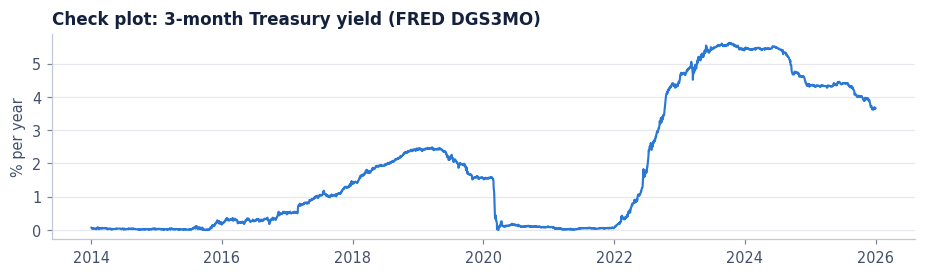

[cache] wiki_1384572480: reused the download of 2026-11-25 02:14 UTC
[cache] wiki_1387311792: reused the download of 2026-11-25 02:14 UTC
constituents table: 503 rows | change log: 414 rows


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888


Effective Date  Added             Removed                                                                     Reason Refs
     Effective Date Ticker    Security  Ticker                Security                                             Reason Refs
0  October 30, 2026   OKTA  Okta, Inc.    KVUE                  Kenvue  S&P 500 constituent Kimberly-Clark acquired Ke...  [2]
1   October 6, 2026   TWLO      Twilio     WBD  Warner Bros. Discovery  Paramount Skydance acquired Warner Bros. Disco...  [3]
2   October 6, 2026    NaN         NaN    CTVA                 Corteva                     Market capitalization changes.  [3]

In [5]:
# ---- a small cache so that re-running cells on the same day does not download everything again ----
# In a fresh Colab session the cache is empty, so everything is downloaded. On your own computer a download is
# reused until the end of the day (UTC) and then made again, because Yahoo revises its data: a later split, for
# example, changes every earlier closing price. Set USE_CACHE = False to download again at once.
CACHE_DIR = os.environ.get("QA_CACHE_DIR", os.path.join(os.path.expanduser("~"), ".cache", "quantile_alpha"))
CACHE_STAMP = os.environ.get("QA_CACHE_STAMP", dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d"))
USE_CACHE = os.environ.get("QA_USE_CACHE", "1") != "0"
os.makedirs(CACHE_DIR, exist_ok=True)

def cached(name, builder):
    """Run `builder()` once per day and keep its result (plus its provenance records) on local disk."""
    path = os.path.join(CACHE_DIR, f"{name}_{CACHE_STAMP}.pkl")
    if USE_CACHE and os.path.exists(path):
        try:
            obj, log = pd.read_pickle(path)
            DATA_LOG.extend(log)
            print(f"[cache] {name}: reused the download of {log[0]['retrieved_utc'] if log else 'earlier'} UTC")
            return obj
        except Exception:                      # unreadable cache (e.g. written by another pandas version): download again
            pass
    n_before = len(DATA_LOG)
    obj = builder()
    pd.to_pickle((obj, DATA_LOG[n_before:]), path)
    return obj

# ---- FRED: risk-free proxy and recession indicator ----
fred_key = get_fred_api_key()
print("FRED access route:", "official API with key" if fred_key else
      "official key-less CSV endpoint (no FRED_API_KEY found; this is an explicit, documented alternative)")
FRED_END = str(P(CFG.last_holding_month).end_time.date())          # last day of the sample
dgs3mo = cached("fred_DGS3MO", lambda: fred_series(CFG.rf_series, "1981-09-01", FRED_END, fred_key))
usrec = cached("fred_USREC", lambda: fred_series(CFG.recession_series, "1854-12-01", FRED_END, fred_key))

# the four checks from Lecture 3: shape, date range, missing values, plot
for s in (dgs3mo, usrec):
    print(f"{s.name}: {len(s):,} rows | {s.index[0].date()} to {s.index[-1].date()} | missing {int(s.isna().sum()):,} "
          f"| min {s.min():.2f} max {s.max():.2f}")
fig, ax = plt.subplots(figsize=(8.5, 2.6))
ax.plot(dgs3mo.loc["2014":].dropna(), color=BLUE, lw=1.4)
ax.set_title("Check plot: 3-month Treasury yield (FRED DGS3MO)"); ax.set_ylabel("% per year")
plt.tight_layout(); plt.show()

# ---- Wikipedia: pinned membership tables ----
constituents_raw = cached(f"wiki_{CFG.wiki_constituents_revid}", lambda: wiki_tables(CFG.wiki_constituents_revid)[0])
changes_raw = cached(f"wiki_{CFG.wiki_changes_revid}", lambda: max(wiki_tables(CFG.wiki_changes_revid), key=len))
print(f"constituents table: {constituents_raw.shape[0]} rows | change log: {changes_raw.shape[0]} rows")
display(constituents_raw.head(3)); display(changes_raw.head(3))

## 3. Historical universe: who was in the S&P 500, and for whom do we have prices?

### 3.1 Reconstructing membership at each date

The starting point is the list of today's constituents. The change log (additions and removals with effective dates) is then replayed **backwards**: undoing an addition removes that company from the set, undoing a removal puts it back. The result is a table of *membership spells*, one row per continuous stay of a security in the index, from which the members on any past date can be read.

Four kinds of manual, documented corrections are needed, and they are all defined in the cell below so that nothing is hidden:

1. **Ticker changes inside the index** (`ADD_ALIASES`). The log records a company under the ticker it had when it joined (Facebook as `FB`), while the constituents table uses today's ticker (`META`). Without the link the replay would never remove Facebook when going back past its entry date.
2. **Mapping to Yahoo symbols** (`YAHOO_ALIASES`). Yahoo keeps a company's price history under its *current* symbol, so a former member is looked up under the symbol that carries its history today (Gap Inc.: `GPS` → `GAP`). Only renames of the same listed security are mapped.
3. **Reused tickers** (`REUSED_TICKERS` and an automatic rule). Yahoo recycles symbols: `EP` was El Paso Corporation until 2012 and is Empire Petroleum today. Using such a series would silently feed another company's prices into the backtest. A Yahoo series is rejected for a former member if it only starts after that member joined the index (it cannot be the same security), or if it is on the explicit list of cases identified by comparing company names. One current member is rejected for part of the sample (`FOREIGN_PRICES_BEFORE`): the history Yahoo shows under `JCI` before September 2016 is that of Tyco International, which took over the name and ticker of Johnson Controls in their merger, so Johnson Controls cannot be ranked before that date.
4. **Share counts under former tickers** (`TICKER_HISTORY`). Yahoo usually files share counts under the ticker a company had at the time (section 2, rule 1). For the index members whose counts under today's symbol start late or belong to another company, the table gives the earlier symbols and the day of each change. The entries were written by hand, from the change log where it states the change and otherwise from general knowledge of the companies; section 3.2 compares each of them with Yahoo's own data.

One share class per issuer is kept (`SECONDARY_SHARE_CLASSES`). Yahoo's share counts are per company, so the primary class carries the whole company's market value and Alphabet, Fox or News Corp cannot enter the portfolio twice. (The index itself lists each share class separately and, until September 2026, applied the 9% limit to each class on its own, so a company with two listed classes could weigh more in the index than it can here.)

In [6]:
# [engine] exported to the repo by tools/export_engine.py - see the README
# (effective date, ticker in the change log) -> ticker under which the same security appears later in the tables
ADD_ALIASES = {
    ("2026-03-23", "SATS"): "ECHO",    # EchoStar changed its ticker
    ("2021-09-20", "CDAY"): "DAY",     # Ceridian -> Dayforce
    ("2018-06-20", "FLT"): "CPAY",     # FleetCor -> Corpay
    ("2017-06-19", "RE"): "EG",        # Everest Re -> Everest Group
    ("2016-04-08", "UA.C"): "UA",      # Under Armour class C, later ticker UA
    ("2015-09-18", "FOX"): "TFCF",     # 21st Century Fox class B, later ticker TFCF
    ("2014-05-01", "UA"): "UAA",       # Under Armour class A, later ticker UAA
    ("2014-04-03", "GOOGL"): "GOOG",   # the security added that day was the new class C (today GOOG)
    ("2013-12-23", "FB"): "META",      # Facebook -> Meta Platforms
    ("2013-11-13", "KORS"): "CPRI",    # Michael Kors -> Capri Holdings
    ("2012-12-21", "DLPH"): "APTV",    # Delphi Automotive -> Aptiv
    ("2011-02-25", "JOYG"): "JOY",     # Joy Global changed its ticker
    ("2010-11-17", "IR"): "TT",        # Ingersoll-Rand -> Trane Technologies
    ("2009-11-03", "PCLN"): "BKNG",    # Priceline -> Booking Holdings
}

# change-log ticker -> Yahoo symbol that carries this security's price history today (same listed security, renamed)
YAHOO_ALIASES = {
    "WLTW": "WTW",   # Willis Towers Watson, ticker change 2022 (stated in the change log)
    "DWDP": "DD",    # DowDuPont renamed DuPont de Nemours, 2019 (stated in the change log)
    "KFT": "MDLZ",   # Kraft Foods renamed Mondelez, 2012 (stated in the change log)
    "ARNC": "HWM",   # Arconic renamed Howmet Aerospace, 2020 (stated in the change log)
    "GPS": "GAP",    # Gap Inc. ticker change, 2024
    "FBHS": "FBIN",  # Fortune Brands Home & Security -> Fortune Brands Innovations, 2022
    "HFC": "DINO",   # HollyFrontier -> HF Sinclair, 2022
    "ADS": "BFH",    # Alliance Data Systems -> Bread Financial, 2022
    "WYN": "TNL",    # Wyndham Worldwide -> Wyndham Destinations -> Travel + Leisure
    "SAI": "LDOS",   # SAIC renamed Leidos, 2013
    "JDSU": "VIAV",  # JDS Uniphase renamed Viavi Solutions, 2015
    "FII": "FHI",    # Federated Investors -> Federated Hermes, 2020
    "BHI": "BKR",    # Baker Hughes Inc. -> Baker Hughes Co.; Yahoo carries the old history under BKR
    "CCE": "CCEP",   # Coca-Cola Enterprises -> Coca-Cola Europacific Partners
    "CSC": "DXC",    # Computer Sciences Corp. -> DXC Technology; Yahoo carries the old history under DXC
    "DPS": "KDP",    # Dr Pepper Snapple -> Keurig Dr Pepper; Yahoo carries the old history under KDP
}
# (change-log ticker, "start" or "end", that date of the membership spell) -> Yahoo symbol, where the ticker alone is
# ambiguous because two different companies used it
YAHOO_ALIASES_BY_SPELL = {
    ("Q", "start", "2017-08-29"): "IQV",   # QuintilesIMS traded as Q for three months before becoming IQV
    ("DOW", "end", "2017-09-01"): "DD",    # Dow Chemical until the DowDuPont merger: Yahoo keeps its history under DD
}

# the second share class of an issuer that is already in the index with its primary class
SECONDARY_SHARE_CLASSES = {"GOOG": "GOOGL", "FOX": "FOXA", "NWS": "NWSA", "DISCK": "DISCA", "UA": "UAA",
                           "CMCSK": "CMCSA", "TFCF": "TFCFA"}

# former members whose ticker Yahoo now assigns to a different security even though that series overlaps the
# membership period (found by comparing Yahoo's company name with the index member's name)
REUSED_TICKERS = {
    "EP": "El Paso Corp. (acquired 2012); Yahoo symbol now Empire Petroleum",
    "GR": "Goodrich Corp. (acquired 2012); Yahoo symbol now an unrelated fund series",
    "GENZ": "Genzyme (acquired 2011); Yahoo symbol now an exchange-traded fund",
    "KG": "King Pharmaceuticals (acquired 2010); Yahoo symbol now Kestrel Group",
    "CPWR": "Compuware (taken private 2014); Yahoo symbol now Ocean Thermal Energy",
    "DD": "E.I. du Pont de Nemours (merged into DowDuPont 2017); Yahoo's DD history before September 2017 is Dow Chemical's",
}

# index members that are still in the index but whose Yahoo price history BEFORE the day given is another company's:
# the member cannot be ranked before that day
FOREIGN_PRICES_BEFORE = {
    "JCI": "2016-09-06",     # Johnson Controls Inc. merged into Tyco International that day and Tyco took its name and ticker;
                             # Yahoo's JCI history before it is Tyco's (split factor 0.955 on that day; Tyco's dividends)
}

# Share counts. Yahoo files a reported share count under the ticker the company had AT THE TIME, while the price
# history moves to the current symbol. Under its current symbol a renamed company therefore has no counts before the
# change of ticker, or it has the counts of whoever used that ticker before. For each such company the table gives the
# earlier symbols in time order, each with the day from which the NEXT symbol's counts are the company's (the day of
# that symbol's first own count on Yahoo). Section 3.2 checks every entry against Yahoo's data: where nothing but the
# ticker changed, the last count under the old symbol and the first under the new one agree.
TICKER_HISTORY = {
    "META": [("FB", "2022-06-09")],                             # Facebook -> Meta Platforms
    "BNY":  [("BK", "2026-05-22")],                             # Bank of New York Mellon; BNY was a closed-end fund before
    "COR":  [("ABC", "2023-09-01")],                            # AmerisourceBergen -> Cencora; COR was CoreSite Realty before
    "GEN":  [("SYMC", "2019-11-11"), ("NLOK", "2022-11-09")],   # Symantec -> NortonLifeLock -> Gen Digital
    "DOC":  [("HCP", "2019-11-12"), ("PEAK", "2024-03-20")],    # HCP -> Healthpeak, which took Physicians Realty's ticker in 2024
    "WTW":  [("WLTW", "2022-01-11")],                           # Willis Towers Watson; WTW was Weight Watchers before
    "DD":   [("DOW", "2017-09-01"), ("DWDP", "2019-06-10")],    # Dow Chemical -> DowDuPont -> DuPont de Nemours
    "DINO": [("HFC", "2022-03-17")],                            # HollyFrontier -> HF Sinclair
    "MRSH": [("MMC", "2026-01-15")],                            # Marsh McLennan
    "SKYD": [("CBS", "2019-12-05"), ("VIAC", "2022-02-18"), ("PARA", "2025-08-08"), ("PSKY", "2026-10-06")],   # CBS -> ... -> Skydance
    "VMRK": [("EQR", "2026-08-25")],                            # Equity Residential -> Vivmark Residential
    "RVTY": [("PKI", "2023-05-18")],                            # PerkinElmer -> Revvity
    "ELV":  [("ANTM", "2022-06-29")],                           # Anthem -> Elevance Health
    "GAP":  [("GPS", "2024-08-22")],                            # Gap Inc.
    "BALL": [("BLL", "2022-05-10")],                            # Ball Corporation
    "BBWI": [("LB", "2021-08-04")],                             # L Brands -> Bath & Body Works
    "VTRS": [("MYL", "2020-11-17")],                            # Mylan -> Viatris
    "BFH":  [("ADS", "2022-04-05")],                            # Alliance Data Systems -> Bread Financial
    "LUMN": [("CTL", "2020-09-22")],                            # CenturyLink -> Lumen Technologies
    "RTX":  [("UTX", "2020-04-14")],                            # United Technologies -> Raytheon Technologies
    "TT":   [("IR", "2020-03-03")],                             # Ingersoll-Rand plc -> Trane Technologies
    "J":    [("JEC", "2019-12-16")],                            # Jacobs Engineering
    "TFC":  [("BBT", "2019-12-16")],                            # BB&T -> Truist Financial
    "BKR":  [("BHI", "2017-07-05"), ("BHGE", "2019-10-24")],    # Baker Hughes Inc. -> Baker Hughes, a GE company -> Baker Hughes Co.
    "GL":   [("TMK", "2019-08-16")],                            # Torchmark -> Globe Life
    "LHX":  [("HRS", "2019-07-13")],                            # Harris -> L3Harris
    "LIN":  [("PX", "2018-11-04")],                             # Praxair -> Linde plc
    "TNL":  [("WYN", "2018-06-01"), ("WYND", "2021-02-18")],    # Wyndham Worldwide -> Wyndham Destinations -> Travel + Leisure
    "APTV": [("DLPH", "2017-12-14")],                           # Delphi Automotive -> Aptiv; DLPH then went to Delphi Technologies
    "BKNG": [("PCLN", "2018-11-14")],                           # Priceline Group -> Booking Holdings
    "UAA":  [("UA", "2016-11-08")],                             # Under Armour class A traded as UA until December 2016
    "FBIN": [("FBHS", "2022-12-16")],                           # Fortune Brands Home & Security -> Fortune Brands Innovations
    "EG":   [("RE", "2023-07-12")],                             # Everest Re -> Everest Group
    "HWM":  [("ARNC", "2020-04-02")],                           # Arconic Inc. -> Howmet Aerospace; ARNC then went to Arconic Corp.
    "CPAY": [("FLT", "2024-03-27")],                            # FleetCor -> Corpay
    "IQV":  [("Q", "2018-11-14")],                              # QuintilesIMS -> IQVIA
    "FISV": [("FISV", "2023-06-13"), ("FI", "2025-11-11")],     # Fiserv traded as FI from June 2023 to November 2025
    # former symbols under which Yahoo has no counts at present: the company cannot be ranked before the date given
    "CPRI": [("KORS", "2019-01-07")],                           # Michael Kors -> Capri Holdings
    "CBRE": [("CBG", "2018-11-14")],                            # CBRE Group
    "JEF":  [("LUK", "2018-11-14")],                            # Leucadia National -> Jefferies Financial Group
    "TPR":  [("COH", "2018-11-14")],                            # Coach -> Tapestry
    "WELL": [("HCN", "2018-11-13")],                            # Welltower
    "KDP":  [("DPS", "2018-07-16")],                            # Dr Pepper Snapple -> Keurig Dr Pepper
    "CCEP": [("CCE", "2018-11-12")],                            # Coca-Cola Enterprises -> Coca-Cola Europacific Partners
    "DXC":  [("CSC", "2017-04-06")],                            # Computer Sciences Corp. -> DXC Technology
    "SPGI": [("MHFI", "2016-04-27")],                           # McGraw Hill Financial -> S&P Global
}


def clean_ticker(x):
    """Change-log tickers contain stray characters ('ALLE |'); keep letters, digits and the class dot."""
    return re.sub(r"[^A-Z0-9.]", "", x.upper()) if isinstance(x, str) else None


def build_spells(constituents, changes, cutoff="2009-06-01"):
    """Replay the change log backwards from today's constituents.

    Returns (spells, issues). `spells` has one row per continuous stay of a security in the index:
    ticker, name, start (NaT = already a member at `cutoff`), end (NaT = still a member), reasons.
    `issues` lists log entries that could not be matched; it should be empty.
    """
    cons = constituents.copy()
    cons.columns = [str(c).strip() for c in cons.columns]
    chg = changes.copy()
    chg.columns = ["date", "add_ticker", "add_name", "rem_ticker", "rem_name", "reason", "refs"][: chg.shape[1]]
    chg["date"] = pd.to_datetime(chg["date"], errors="coerce")
    if chg["date"].isna().any():
        raise ValueError("unparseable dates in the change log")
    chg["add_ticker"] = chg["add_ticker"].map(clean_ticker)
    chg["rem_ticker"] = chg["rem_ticker"].map(clean_ticker)
    chg = chg.sort_values("date", ascending=False, kind="stable").reset_index(drop=True)

    spells, open_spells, issues = [], {}, []
    for _, row in cons.iterrows():
        tk = clean_ticker(row["Symbol"])
        spells.append({"ticker": tk, "name": row["Security"], "start": pd.NaT, "end": pd.NaT,
                       "reason_in": "", "reason_out": "", "sector": row.get("GICS Sector", None)})
        open_spells.setdefault(tk, []).append(len(spells) - 1)
    for _, row in chg.iterrows():
        if row["date"] < pd.Timestamp(cutoff):
            break
        added = row["add_ticker"] if isinstance(row["add_ticker"], str) and row["add_ticker"] else None
        removed = row["rem_ticker"] if isinstance(row["rem_ticker"], str) and row["rem_ticker"] else None
        if added:                                       # undo an addition: the spell started on this date
            key = ADD_ALIASES.get((str(row["date"].date()), added), added)
            if open_spells.get(key):
                k = open_spells[key].pop()
                spells[k]["start"], spells[k]["reason_in"] = row["date"], str(row["reason"])
            else:
                issues.append({"date": row["date"].date(), "ticker": added, "problem": "addition without a matching member"})
        if removed:                                     # undo a removal: an earlier spell ended on this date
            spells.append({"ticker": removed, "name": row["rem_name"], "start": pd.NaT, "end": row["date"],
                           "reason_in": "", "reason_out": str(row["reason"]), "sector": None})
            open_spells.setdefault(removed, []).append(len(spells) - 1)
    out = pd.DataFrame(spells)
    out["start"] = pd.to_datetime(out["start"]); out["end"] = pd.to_datetime(out["end"])
    return out, pd.DataFrame(issues, columns=["date", "ticker", "problem"])


def yahoo_symbol(ticker, start=None, end=None):
    """Yahoo symbol for a membership spell (class shares use '-' on Yahoo: BRK.B -> BRK-B)."""
    for which, date in (("start", start), ("end", end)):
        if date is not None and pd.notna(date):
            key = (ticker, which, str(pd.Timestamp(date).date()))
            if key in YAHOO_ALIASES_BY_SPELL:
                return YAHOO_ALIASES_BY_SPELL[key]
    return YAHOO_ALIASES.get(ticker, ticker).replace(".", "-")


def members_on(spells, date):
    """Membership spells active at the close of `date` (changes effective on or before that day are included)."""
    date = pd.Timestamp(date)
    active = (spells["start"].isna() | (spells["start"] <= date)) & (spells["end"].isna() | (spells["end"] > date))
    return spells[active]


def map_spells_to_yahoo(spells, first_date, data_start):
    """Attach the Yahoo symbol to each spell and decide whether Yahoo's series may be used for it."""
    sp = spells.copy()
    sp["yahoo"] = [yahoo_symbol(t, s, e) for t, s, e in zip(sp["ticker"], sp["start"], sp["end"])]
    sp["yahoo_first"] = pd.to_datetime(sp["yahoo"].map(first_date))
    tolerance = pd.Timedelta(days=10)
    must_exist_by = sp["start"].fillna(pd.Timestamp(data_start)).clip(lower=pd.Timestamp(data_start)) + tolerance
    note = pd.Series("", index=sp.index, dtype="object")
    note[sp["ticker"].isin(list(SECONDARY_SHARE_CLASSES))] = "secondary share class"
    no_data = sp["yahoo_first"].isna() & (note == "")
    note[no_data] = "no Yahoo price history (delisted or unknown symbol)"
    late = sp["end"].notna() & sp["yahoo_first"].notna() & (sp["yahoo_first"] > must_exist_by) & (note == "")
    note[late] = "ticker reused: Yahoo series starts after the membership began"
    listed = sp["end"].notna() & sp["ticker"].isin(list(REUSED_TICKERS)) & (note == "")
    note[listed] = "ticker reused: Yahoo series belongs to another issuer"
    sp["block"] = note
    return sp


def former_symbols(stocks):
    """Former ticker symbols under which Yahoo files earlier share counts of the companies in `stocks`."""
    return sorted({s for sym in stocks for s, _ in TICKER_HISTORY.get(sym, [])} - set(stocks))


def universe_symbols(spells, cfg):
    """Yahoo symbols of every security that was an index member inside the backtest window, plus the two funds."""
    first_reference = (P(cfg.first_holding_month) - 1 - cfg.reference_lag).start_time
    relevant = spells[(spells["end"].isna() | (spells["end"] > first_reference)) &
                      (spells["start"].isna() | (spells["start"] < pd.Timestamp(cfg.data_end_exclusive)))]
    symbols = {yahoo_symbol(t, s, e) for t, s, e in zip(relevant["ticker"], relevant["start"], relevant["end"])}
    return sorted(symbols | {cfg.benchmark, cfg.momentum_fund})


def momentum_inputs(panel, month, cfg):
    """Momentum value and volatility for the reference date = last session of `month` (S&P methodology, Appendix A).

    value  : price change over cfg.lookback months ending cfg.skip month(s) before the reference date, measured on
             month-end closing prices; from cfg.fallback_lookback months if there is no price that far back
    vol    : standard deviation of the daily price changes over the same period
    days   : number of daily price changes in that period; months : 12 or 9, the period actually used
    Only prices of days on which the stock traded count (see build_monthly_panel).
    """
    close, sessions, daily = panel["px_signal"], panel["sessions"], panel["daily_close"]
    end, far, near = month - cfg.skip, month - cfg.skip - cfg.lookback, month - cfg.skip - cfg.fallback_lookback
    p_end, p_far, p_near = close.loc[end], close.loc[far], close.loc[near]
    full = p_far.notna() & p_end.notna()
    value = (p_end / p_far - 1.0).where(full, p_end / p_near - 1.0)
    r_far = daily.loc[sessions[far]:sessions[end]].pct_change(fill_method=None).iloc[1:]
    r_near = daily.loc[sessions[near]:sessions[end]].pct_change(fill_method=None).iloc[1:]
    vol = r_far.std(ddof=1).where(full, r_near.std(ddof=1))
    days = r_far.notna().sum().where(full, r_near.notna().sum())
    return pd.DataFrame({"value": value, "vol": vol, "days": days,
                         "months": np.where(full, cfg.lookback, cfg.fallback_lookback)})


def universe_at(month, spells_mapped, panel, cfg, inputs=None):
    """Classify every index member at the reference date = last session of `month` (a monthly Period).

    A security is eligible when it is an index member on the reference date, Yahoo carries its own history (not
    another company's under the same symbol), it has a price on that date, a momentum value (at least nine months of
    prices before the skipped month), at least cfg.min_trading_days daily price changes in the measurement period,
    and a share count. Everything except the question whether Yahoo still carries the company was known on the
    reference date.
    """
    px, sessions = panel["px"], panel["sessions"]
    mem = members_on(spells_mapped, sessions[month]).copy()
    inputs = momentum_inputs(panel, month, cfg) if inputs is None else inputs
    symbols = mem["yahoo"].to_numpy()

    def look(series):                                 # value of every member's symbol (NaN if there is none)
        return pd.Series(series.reindex(symbols).to_numpy(dtype=float), index=mem.index)

    has_col = mem["yahoo"].isin(list(px.columns))
    price, value, vol, days = look(px.loc[month]), look(inputs["value"]), look(inputs["vol"]), look(inputs["days"])
    cap = look(panel["mcap"].loc[month])
    status = mem["block"].copy()
    not_its_own = [t in FOREIGN_PRICES_BEFORE and sessions[month] < pd.Timestamp(FOREIGN_PRICES_BEFORE[t]) for t in mem["ticker"]]
    status[(status == "") & np.array(not_its_own, dtype=bool)] = "ticker reused: Yahoo series belongs to another issuer"
    status[(status == "") & ~has_col] = "no Yahoo price history (delisted or unknown symbol)"
    status[(status == "") & price.isna()] = "no valid price on the reference date"
    status[(status == "") & (value.isna() | ~(vol > 0))] = "listed too recently for the signal"
    status[(status == "") & (days < cfg.min_trading_days)] = "too few trading days in the measurement period"
    status[(status == "") & cap.isna()] = "no share count on Yahoo"
    status[status == ""] = "eligible"
    mem["status"] = status
    dup = mem[(mem["status"] == "eligible")].duplicated("yahoo", keep="first")
    mem.loc[dup[dup].index, "status"] = "duplicate price series"
    return mem

membership spells: 767 | unmatched change-log entries: 0
securities that were index members between 2015-11 and 2025-12, plus SPY and SPMO: 709 Yahoo symbols requested
[cache] yahoo_prices_2014-06-01_2026-01-01_709: reused the download of 2026-11-25 02:17 UTC
status
ok                                               596
no data on Yahoo (delisted or unknown symbol)    113

shape: 2,915 trading days x 596 securities
date range: 2014-06-02 to 2025-12-31  (end date is exclusive in yfinance, so 2025-12-31 must be the last row)

days on which a security has both a split factor and a dividend: 4; adjusted return replaced by the close return on 2 of them


,,split_factor,dividend,adj_close_return,close_return,market_return,decision
security,day,,,,,,
DHR,2016-07-05,1.3190,24.560,+61.2%,+3.6%,-0.7%,close return used
DXC,2015-11-30,1.7412,9.083,+8.4%,-20.5%,-0.4%,adjusted return kept
IRM,2014-09-26,1.0820,0.669,-0.0%,-2.1%,+0.8%,adjusted return kept
XRX,2017-01-03,1.5180,2.980,+37.6%,+19.8%,+0.8%,close return used


month-end sessions: 2014-06 to 2025-12 (139 months)
last three month-end sessions: ['2025-10-31', '2025-11-28', '2025-12-31']
Yahoo series that stop before the window ends: 0 
series with a month-end that has no quote on the final session: 0 []


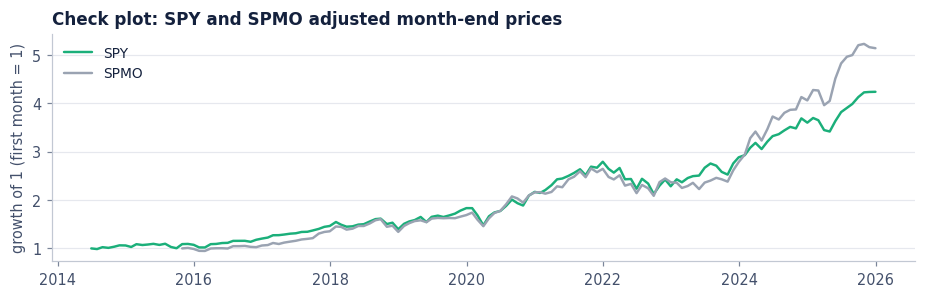

In [7]:
spells_raw, replay_issues = build_spells(constituents_raw, changes_raw, cutoff=CFG.data_start)
print(f"membership spells: {len(spells_raw)} | unmatched change-log entries: {len(replay_issues)}")
assert replay_issues.empty, replay_issues

# every security that was a member at any reference date of the backtest, plus the two funds
request = universe_symbols(spells_raw, CFG)
FIRST_TRADE = P(CFG.first_holding_month) - 1                       # the portfolio is first bought at the close of this month
FIRST_REFERENCE = FIRST_TRADE - CFG.reference_lag
print(f"securities that were index members between {FIRST_REFERENCE} and {CFG.last_holding_month}, plus "
      f"{CFG.benchmark} and {CFG.momentum_fund}: {len(request)} Yahoo symbols requested")

raw = cached(f"yahoo_prices_{CFG.data_start}_{CFG.data_end_exclusive}_{len(request)}", lambda: yahoo_market_data(request, CFG))
print(raw["status"].value_counts().to_string())

# ---- the four checks (Lecture 3): shape, date range, missing values, plot ----
adj = raw["adj"]
print(f"\nshape: {adj.shape[0]:,} trading days x {adj.shape[1]} securities")
print(f"date range: {adj.index[0].date()} to {adj.index[-1].date()}  (end date is exclusive in yfinance, so 2025-12-31 must be the last row)")
assert adj.index[-1] == pd.Timestamp("2025-12-31"), "December 2025 is not fully included"
assert np.nanmin(adj.to_numpy(dtype=float)) > 0, "non-positive prices found"
assert adj.index.is_monotonic_increasing and adj.index.is_unique

# ---- spin-offs that Yahoo adjusts twice (see the rule in repair_double_adjustments) ----
ADJ_USED, ADJ_REPAIRS = repair_double_adjustments(raw["adj"], raw["close"], raw["dividends"], raw["splits"], CFG.benchmark)
print(f"\ndays on which a security has both a split factor and a dividend: {len(ADJ_REPAIRS)}; "
      f"adjusted return replaced by the close return on {int(ADJ_REPAIRS['decision'].str.startswith('close return used').sum())} of them")
display(savetable(ADJ_REPAIRS.set_index(["security", "day"]), "log_adjustment_repairs").style.format(
    {"split_factor": "{:.4f}", "dividend": "{:.3f}", "adj_close_return": "{:+.1%}", "close_return": "{:+.1%}", "market_return": "{:+.1%}"}))

PANEL = build_monthly_panel(ADJ_USED, raw["close"], raw["volume"], CFG.benchmark)
SPELLS = map_spells_to_yahoo(spells_raw, PANEL["first_date"], CFG.data_start)
print(f"month-end sessions: {PANEL['sessions'].index[0]} to {PANEL['sessions'].index[-1]} ({len(PANEL['sessions'])} months)")
print("last three month-end sessions:", [d.date().isoformat() for d in PANEL["sessions"].iloc[-3:]])
ended = PANEL["last_month"].dropna()
blocked = set(SPELLS.loc[SPELLS["block"].str.startswith("ticker reused"), "yahoo"])
print(f"Yahoo series that stop before the window ends: {len(ended)} {dict(ended.astype(str)) if len(ended) else ''}"
      + (" (reused ticker, blocked)" if len(ended) and set(ended.index) <= blocked else ""))
stale_cols = PANEL["stale"].columns[PANEL["stale"].any()]
print(f"series with a month-end that has no quote on the final session: {len(stale_cols)} {list(stale_cols)}"
      + (" (all blocked as reused tickers, so never used)" if len(stale_cols) and set(stale_cols) <= blocked else ""))

fig, ax = plt.subplots(figsize=(8.5, 2.8))
for fund, color in ((CFG.benchmark, TEAL), (CFG.momentum_fund, GREY)):
    s = PANEL["px"][fund].dropna()
    ax.plot(PANEL["sessions"][s.index].values, s / s.iloc[0], color=color, lw=1.6, label=fund)
ax.legend(loc="upper left"); ax.set_ylabel("growth of 1 (first month = 1)")
ax.set_title("Check plot: SPY and SPMO adjusted month-end prices"); plt.tight_layout(); plt.show()

### 3.2 Share counts and market capitalisation

The weights need each company's market value at every reference date. The cell below downloads Yahoo's history of shares outstanding for every security that has prices and for the former symbols of renamed companies, applies the six rules of section 2 one after the other, and shows what each of them does. The result is then checked in two ways: the largest companies at three dates, which can be compared with what is publicly known, and, in section 5.2, a portfolio that weights *all* eligible stocks by these market values against the SPY fund.

In [8]:
with_prices = sorted(c for c in raw["close"].columns if c not in (CFG.benchmark, CFG.momentum_fund))
former = former_symbols(with_prices)
shares_raw = cached(f"yahoo_shares_{CFG.data_start}_{CFG.data_end_exclusive}_{len(with_prices) + len(former)}",
                    lambda: yahoo_shares(with_prices + former, CFG.data_start, CFG.data_end_exclusive))
print(f"symbols asked for share counts: {len(with_prices)} with prices + {len(former)} former symbols")
print(shares_raw["status"].value_counts().to_string())
SPLITS = all_split_factors(raw)
after_sample = raw["later_splits"].stack(); after_sample = after_sample[after_sample > 0]
print(f"split factors after the sample, up to the day of the price download: {len(after_sample)}"
      + (" (" + ", ".join(f"{s} {f:g}" for (_, s), f in after_sample.items()) + ")" if len(after_sample) else ""))
print("price restatements for which Yahoo lists no factor, entered by hand: "
      + ", ".join(f"{s} {f:g} on {d}" for (s, d), f in UNLISTED_PRICE_FACTORS.items()))
late_start = PANEL["listed_from"].reindex(with_prices) - PANEL["first_date"].reindex(with_prices)
late_start = late_start[(late_start > pd.Timedelta(days=30)) | PANEL["listed_from"].reindex(with_prices).isna()]
print("securities whose regular trading starts more than 30 days after Yahoo's first price (earlier prices are not used for the signal): "
      + ", ".join(f"{s} from {PANEL['listed_from'][s].date() if pd.notna(PANEL['listed_from'][s]) else 'never'}" for s in late_start.index))

# ---- rule 1: one series per company, across changes of ticker ----
COMPANY_COUNTS, HANDOVERS = splice_ticker_history(shares_raw["shares"], TICKER_HISTORY)
window_end = pd.Timestamp(CFG.data_end_exclusive)
seen = HANDOVERS[pd.to_datetime(HANDOVERS["until"]) < window_end].copy()          # changes of ticker inside the data window
seen["agree within 3%"] = (seen["ratio"] - 1.0).abs() <= 0.03
HANDOVER_NOTES = {       # why the two counts differ where they do: general knowledge of the companies, not taken from the data
    ("DOC", "PEAK"): "merger with Physicians Realty Trust on the day of the change",
    ("DD", "DOW"): "DowDuPont was formed by the merger of Dow Chemical and DuPont",
    ("DD", "DWDP"): "1-for-3 reverse split together with the spin-off of Corteva",
    ("LIN", "PX"): "Linde plc was formed by the merger of Praxair and Linde AG",
    ("UAA", "UA"): "Yahoo's counts under the old symbol jump between values during 2016",
}
apart = (pd.to_datetime(seen["dated "]) - pd.to_datetime(seen["dated"])).dt.days
seen["note"] = [HANDOVER_NOTES.get((c, f), "") if pd.notna(r) and not ok else "" for c, f, r, ok in
                zip(seen["company (Yahoo symbol)"], seen["counts filed under"], seen["ratio"], seen["agree within 3%"])]
far = seen["ratio"].notna() & ~seen["agree within 3%"] & (apart > CFG.share_gap_days)
seen.loc[far, "note"] = [(n + "; " if n else "") + f"the two counts are {d / 30.44:.0f} months apart, on either side of Yahoo's outage"
                         for n, d in zip(seen.loc[far, "note"], apart[far])]
seen.loc[seen["ratio"].isna(), "note"] = "no count on Yahoo under the former symbol"
no_former = sorted(s for s in former if s not in shares_raw["shares"])
handover_view = seen.set_index(["company (Yahoo symbol)", "counts filed under"])
display(savetable(handover_view, "tab_ticker_changes").style.format(
    {"last count before": "{:,.0f}", "first count after": "{:,.0f}", "ratio": "{:.3f}"}, na_rep="none"))
both = seen.dropna(subset=["ratio"])
print(f"changes of ticker inside the data window: {len(seen)} | with a count on both sides: {len(both)} | "
      f"the two counts agree within 3%: {int(both['agree within 3%'].sum())}")
print(f"changes after the data window (the former symbol's counts cover the whole sample): {len(HANDOVERS) - len(seen)}")

# ---- rules 2 and 3: today's split units ----
SHARE_UNITS, units_changed = clean_share_counts(COMPANY_COUNTS, SPLITS)
n_real = int(sum(is_share_split(f) for f in SPLITS.to_numpy().ravel() if f > 0))
n_events = int((SPLITS.to_numpy() > 0).sum())
first_count = pd.Series({k: v.index[0] for k, v in SHARE_UNITS.items()})
n_counts = sum(len(v) for v in SHARE_UNITS.values())
print(f"\nsecurities with share counts: {len(SHARE_UNITS)} of {len(with_prices)} | counts: {n_counts:,} "
      f"| first count per security: {int((first_count < '2016-01-01').sum())} before 2016, {int((first_count >= '2016-01-01').sum())} later")
print(f"Yahoo 'split factors' in the price data: {n_events}, of which {n_real} are real stock splits and {n_events - n_real} are "
      f"spin-offs and similar events | counts read in the other split unit (rule 3): {units_changed}")

# ---- rule 4: Yahoo's outage ----
OUTAGE = reporting_outage(SHARE_UNITS, CFG.share_gap_days)
all_counts = pd.concat(SHARE_UNITS).reset_index(); all_counts.columns = ["symbol", "date", "count"]
per_quarter = all_counts.groupby(all_counts["date"].dt.to_period("Q")).agg(**{"symbols with a count": ("symbol", "nunique"), "counts": ("count", "size")})
display(savetable(per_quarter.loc["2015Q4":"2019Q2"].T, "tab_share_counts_per_quarter"))
print(f"Yahoo's outage (most symbols inside a gap of more than {CFG.share_gap_days} days): {OUTAGE[0].date()} to {OUTAGE[1].date()}")

def before_the_outage():
    """The count directly before the outage against the first count after it, as reported, for every stock."""
    rows = []
    for sym, s in COMPANY_COUNTS.items():
        if sym not in SHARE_UNITS or len(s) < 2:
            continue
        for day in s.index.difference(skip_before_outage(s, OUTAGE, CFG.share_gap_days).index):
            nxt = s.index[s.index > day][0]
            f = SPLITS[sym]; f = f[(f.index > day) & (f.index <= nxt) & (f > 0)]
            real = float(np.prod([x for x in f if is_share_split(x)])) if len(f) else 1.0
            rows.append({"symbol": sym, "count before the outage": s[day], "dated": day.date(), "first count after": s[nxt],
                         "dated ": nxt.date(), "stock split in between": real, "ratio": s[nxt] / s[day]})
    return pd.DataFrame(rows).set_index("symbol")
EDGE = before_the_outage()
split_cases = EDGE[EDGE["stock split in between"] != 1.0].copy()
split_cases["count before is in"] = np.where(np.abs(np.log(split_cases["ratio"] / split_cases["stock split in between"])) < np.abs(np.log(split_cases["ratio"])),
                                           "the units of its date", "post-split units already")
identical = int((EDGE["ratio"] == 1.0).sum())

def first_counts_before_a_split(within=150, calm=120):
    """Stocks with a real split soon after their very first count: is that count in the units of its date?"""
    rows = []
    for sym, s in COMPANY_COUNTS.items():
        if sym not in SHARE_UNITS or len(s) < 2:
            continue
        f = SPLITS[sym]; f = f[f > 0]
        f = f[[is_share_split(x) for x in f.to_numpy()]] if len(f) else f
        soon = f[(f.index > s.index[0]) & (f.index <= s.index[0] + pd.Timedelta(days=within))]
        later = s[s.index > soon.index[0] + pd.Timedelta(days=calm)] if len(soon) == 1 else s.iloc[:0]
        if not len(later) or len(f[(f.index > s.index[0]) & (f.index <= later.index[0])]) != 1:
            continue                                          # no split, several splits, or nothing to compare with
        rows.append({"symbol": sym, "first count": s.iloc[0], "dated": s.index[0].date(), "stock split": soon.iloc[0],
                     "on": soon.index[0].date(), "a later count": later.iloc[0], "dated ": later.index[0].date(),
                     "ratio": later.iloc[0] / s.iloc[0]})
    out = pd.DataFrame(rows).set_index("symbol")
    out["first count is in"] = np.where(np.abs(np.log(out["ratio"] / out["stock split"])) < np.abs(np.log(out["ratio"])),
                                        "the units of its date", "post-split units already")
    return out
FIRST = first_counts_before_a_split()
n_first_late = int((FIRST["first count is in"] == "post-split units already").sum())
display(savetable(split_cases, "tab_counts_before_the_outage").style.format(
    {"count before the outage": "{:,.0f}", "first count after": "{:,.0f}", "stock split in between": "{:g}", "ratio": "{:.3f}"}))
n_late = int((split_cases["count before is in"] == "post-split units already").sum())
print(f"counts directly before the outage: {len(EDGE)} | identical to the first count after it: {identical} | "
      f"stocks with a split inside the outage: {len(split_cases)}, of which {n_late} have a count before it that is already in post-split units")
display(savetable(FIRST, "tab_first_counts_before_a_split").style.format(
    {"first count": "{:,.0f}", "a later count": "{:,.0f}", "stock split": "{:g}", "ratio": "{:.3f}"}))
print(f"stocks with a split within 150 days after their very first count: {len(FIRST)}, of which {n_first_late} have a first count that is "
      "already in post-split units")

# ---- rules 5 and 6: accepted counts and month-end market values ----
PANEL["price_only_factor"] = price_only_factors(SPLITS, PANEL["sessions"])
add_market_caps(PANEL, SHARE_UNITS, CFG, OUTAGE)
after_rule4 = {k: skip_before_outage(v, OUTAGE, CFG.share_gap_days) for k, v in SHARE_UNITS.items()}
not_accepted = {k: len(v) - len(confirmed_counts(v, CFG.share_confirm)) for k, v in after_rule4.items()}
n_waiting = sum(not_accepted.values())
most = sorted(not_accepted.items(), key=lambda kv: -kv[1])[:8]
print(f"\ncounts left out before the outage (rule 4): {n_counts - sum(len(v) for v in after_rule4.values())} | "
      f"counts not accepted because no second count agreed (rule 5): {n_waiting} in {sum(v > 0 for v in not_accepted.values())} securities "
      f"(most: {', '.join(f'{k} {v}' for k, v in most)})")

def largest(month, k=8):
    cap = PANEL["mcap"].loc[month].drop([CFG.benchmark, CFG.momentum_fund] + list(SECONDARY_SHARE_CLASSES), errors="ignore").dropna().sort_values(ascending=False)
    return ", ".join(f"{s} {v / 1e9:,.0f}" for s, v in cap.head(k).items())
share_summary = {"securities with prices": len(with_prices), "former symbols asked": len(former),
                 "former symbols without counts on Yahoo": ", ".join(no_former) or "none",
                 "securities with share counts": len(SHARE_UNITS), "share counts in total": n_counts,
                 "first count before 2016": int((first_count < "2016-01-01").sum()), "first count in 2016 or later": int((first_count >= "2016-01-01").sum()),
                 "changes of ticker inside the data window": len(seen), "of which the counts agree within 3%": int(both["agree within 3%"].sum()),
                 "split factors on Yahoo": n_events, "of which real stock splits": n_real, "counts read in the other split unit": units_changed,
                 "Yahoo's outage": f"{OUTAGE[0].date()} to {OUTAGE[1].date()}", "counts left out before the outage": len(EDGE),
                 "of which identical to the first count after it": identical,
                 "stocks with a split inside the outage": len(split_cases), "of which the count before is already post-split": n_late,
                 "stocks with a split soon after their first count": len(FIRST), "of which the first count is already post-split": n_first_late,
                 "price restatements without a listed factor": ", ".join(f"{s} {f:g} ({d})" for (s, d), f in UNLISTED_PRICE_FACTORS.items()),
                 "counts not accepted (no second count agreed)": n_waiting,
                 "splits after the sample": ", ".join(f"{s} {f:g} ({d.date()})" for (d, s), f in after_sample.items()) or "none"}
for m in (FIRST_REFERENCE, P("2020-08"), P("2025-08")):
    share_summary[f"largest market values, end of {m} (USD billion)"] = largest(m)
    print(f"largest market values at the end of {m} (USD billion): {largest(m)}")
savetable(pd.Series(share_summary, name="value").to_frame(), "tab_share_counts_summary");

[cache] yahoo_shares_2014-06-01_2026-01-01_644: reused the download of 2026-11-25 02:20 UTC
symbols asked for share counts: 594 with prices + 50 former symbols
status
ok                          630
no share counts on Yahoo     14
split factors after the sample, up to the day of the price download: 15 (CMCSA 1.067, AMCR 0.2, BDX 1.272, BKNG 25, CVNA 5, FDX 1.241, KLAC 10, POM 0.0555556, DD 0.333333, HON 0.9535, SPGI 1.057, CRWD 4, MNST 2, APH 2, CTVA 6.665)
price restatements for which Yahoo lists no factor, entered by hand: HWM 1.304 on 2020-04-01
securities whose regular trading starts more than 30 days after Yahoo's first price (earlier prices are not used for the signal): AMCR from 2019-06-11, HWM from 2016-12-23, INFO from 2024-12-13, PCL from 2025-12-31, SBNY from 2024-11-04, STI from 2023-12-08, SW from 2024-07-08, TE from 2020-11-30, VST from 2016-11-28


changes of ticker inside the data window: 51 | with a count on both sides: 40 | the two counts agree within 3%: 33
changes after the data window (the former symbol's counts cover the whole sample): 4



securities with share counts: 594 of 594 | counts: 326,084 | first count per security: 535 before 2016, 59 later
Yahoo 'split factors' in the price data: 211, of which 113 are real stock splits and 98 are spin-offs and similar events | counts read in the other split unit (rule 3): 50


date,2015Q4,2016Q1,2016Q2,2016Q3,2016Q4,2017Q1,2017Q2,2017Q3,2017Q4,2018Q1,2018Q2,2018Q3,2018Q4,2019Q1,2019Q2
symbols with a count,525,499,496,502,524,527,531,523,40,16,12,15,557,558,562
counts,558,821,878,713,671,998,904,659,153,226,255,383,12520,18142,19620


Yahoo's outage (most symbols inside a gap of more than 180 days): 2017-08-04 to 2018-11-13


,count before the outage,dated,first count after,dated,stock split in between,ratio,count before is in
symbol,,,,,,,
ACGL,"405,436,992",2017-08-04,"405,936,000",2018-11-14,3,1.001,post-split units already
AFL,"390,455,008",2017-08-03,"761,278,976",2018-11-13,2,1.950,the units of its date
BF-B,"471,052,000",2017-08-30,"481,436,000",2018-11-13,1.25,1.022,post-split units already
BRO,"276,144,992",2017-08-18,"279,209,984",2018-11-13,2,1.011,post-split units already
HSIC,"152,438,000",2017-08-08,"152,438,000",2018-11-14,2,1.000,post-split units already
ISRG,"111,851,000",2017-08-28,"114,200,000",2018-11-14,3,1.021,post-split units already
TJX,"625,203,008",2017-08-25,"1,237,529,984",2018-11-14,2,1.979,the units of its date
FISV,"398,471,008",2017-08-02,"398,471,008",2018-11-13,2,1.000,post-split units already


counts directly before the outage: 548 | identical to the first count after it: 70 | stocks with a split inside the outage: 8, of which 6 have a count before it that is already in post-split units


,first count,dated,stock split,on,a later count,dated,ratio,first count is in
symbol,,,,,,,,
EW,"215,710,000",2015-10-29,2,2015-12-14,"212,879,000",2016-07-29,0.987,post-split units already
GPN,"129,884,000",2015-10-07,2,2015-11-03,"129,259,000",2016-04-06,0.995,post-split units already
HRL,"528,457,000",2015-12-04,2,2016-02-10,"529,201,000",2016-09-02,1.001,post-split units already
NKE,"1,704,390,000",2015-10-06,2,2015-12-24,"1,677,620,000",2016-07-21,0.984,post-split units already
UAA,"215,816,000",2015-11-22,2,2016-04-08,"456,886,000",2016-11-02,2.117,the units of its date


stocks with a split within 150 days after their very first count: 5, of which 4 have a first count that is already in post-split units



counts left out before the outage (rule 4): 548 | counts not accepted because no second count agreed (rule 5): 278 in 152 securities (most: SOLS 22, KKR 12, APO 7, ARES 7, CVNA 7, CZR 7, ENPH 5, HSY 4)
largest market values at the end of 2015-11 (USD billion): AAPL 660, GOOGL 525, MSFT 434, XOM 340, BRK-B 331, AMZN 312, META 295, GE 283
largest market values at the end of 2020-08 (USD billion): AAPL 2,207, AMZN 1,729, MSFT 1,707, GOOGL 1,110, META 835, BRK-B 520, V 465, TSLA 464
largest market values at the end of 2025-08 (USD billion): NVDA 4,280, MSFT 3,766, AAPL 3,556, GOOGL 2,579, AMZN 2,442, META 1,856, AVGO 1,399, BRK-B 1,085


In [9]:
off = both[~both["agree within 3%"]]
off_text = ", ".join(f"{c} {r:.2f}" for c, r in zip(off["company (Yahoo symbol)"], off["ratio"]))
usual_q = int(per_quarter.loc["2016Q1":"2017Q2", "symbols with a count"].median())
gap_months = int(round(np.median([(b - a).days for a, b in zip(EDGE["dated"], EDGE["dated "])]) / 30.44))
quiet_q = per_quarter.loc["2018Q1":"2018Q3", "symbols with a count"]
say(f"""
**What the share-count rules do.**

* **Changes of ticker (rule 1).** {len(seen)} changes of ticker fall inside the data window. At {len(both)} of them Yahoo has a count on both sides, and at {int(both['agree within 3%'].sum())} of these the last count under the old symbol and the first under the new one agree within 3%, most of them to the last digit: the two series belong to the same company. The other {len(off)} ({off_text}; ratio of the count after to the count before) carry a note in the table: a merger or a reverse split at the change of ticker, two counts that lie on either side of Yahoo's outage, or, for Under Armour, counts under the old symbol that are inconsistent in themselves. {pick(len(no_former) > 0, f"For {len(no_former)} former symbols Yahoo has no counts ({', '.join(no_former)}); those companies cannot be ranked until the counts under their new symbol begin.", 'Yahoo has counts under every former symbol in the table.')}
* **Yahoo's outage (rule 4).** From {OUTAGE[0]:%B %Y} to {OUTAGE[1]:%B %Y} the number of securities with any count falls from about {usual_q} per quarter to between {int(quiet_q.min())} and {int(quiet_q.max())}. Of the {len(EDGE)} counts that stand directly before this gap, {identical} are identical to the first count after it, about {gap_months} months later. {len(split_cases)} stocks had a stock split inside the gap, which makes the date of the earlier count testable: for {n_late} of them it is already in post-split units, so it was entered after the split and not on the date it carries. This is why these counts are left out.
* **First counts (rule 6).** Yahoo's very first counts, from late 2015, show the same sign of later entry: {len(FIRST)} stocks split within 150 days after their first count, and for {n_first_late} of them that count is already in post-split units. Rule 3 repairs the unit. Whether a first count was entered on the date it carries cannot be checked, and the first purchase rests on a first count for every stock.
* **Second count (rule 5).** {n_waiting} of {n_counts:,} counts are not accepted because the next count did not agree with them.
""")


**What the share-count rules do.**

* **Changes of ticker (rule 1).** 51 changes of ticker fall inside the data window. At 40 of them Yahoo has a count on both sides, and at 33 of these the last count under the old symbol and the first under the new one agree within 3%, most of them to the last digit: the two series belong to the same company. The other 7 (DOC 1.28, DD 1.90, DD 0.33, LIN 1.87, BKNG 0.95, UAA 0.90, IQV 0.96; ratio of the count after to the count before) carry a note in the table: a merger or a reverse split at the change of ticker, two counts that lie on either side of Yahoo's outage, or, for Under Armour, counts under the old symbol that are inconsistent in themselves. For 11 former symbols Yahoo has no counts (BHI, CBG, CCE, COH, CSC, DPS, HCN, KORS, LUK, MHFI, WYN); those companies cannot be ranked until the counts under their new symbol begin.
* **Yahoo's outage (rule 4).** From August 2017 to November 2018 the number of securities with any count falls from about 513 per quarter to between 12 and 16. Of the 548 counts that stand directly before this gap, 70 are identical to the first count after it, about 15 months later. 8 stocks had a stock split inside the gap, which makes the date of the earlier count testable: for 6 of them it is already in post-split units, so it was entered after the split and not on the date it carries. This is why these counts are left out.
* **First counts (rule 6).** Yahoo's very first counts, from late 2015, show the same sign of later entry: 5 stocks split within 150 days after their first count, and for 4 of them that count is already in post-split units. Rule 3 repairs the unit. Whether a first count was entered on the date it carries cannot be checked, and the first purchase rests on a first count for every stock.
* **Second count (rule 5).** 278 of 326,084 counts are not accepted because the next count did not agree with them.


### 3.3 Coverage: how much of the true index can be used?

For every rebalance the table below classifies **all** index members at the reference date. Only "eligible" securities can enter the ranking. The classification uses nothing that was unknown on the reference date, with one unavoidable exception that is the main limitation of this study: whether Yahoo *still carries* a company's history today depends on what happened to that company later. Companies that were acquired or went bankrupt after the reference date are mostly gone from Yahoo, so they are missing here. That is survivorship bias in the data source. The table shows how much of the index is missing; section 5.2 estimates what that does to returns.

,reference date,index members (tickers),issuers (one class each),eligible,no Yahoo history,ticker reused,too little history,no share count,no price,share count carried back,"carried back, share of market value","age of the share count, median (days)",oldest (days),coverage
trade month,,,,,,,,,,,,,,
2015-12,2015-11-30,505,500,385,89,11,4,11,0,38,5.7%,28,221,77.0%
2016-03,2016-02-29,504,500,390,87,10,4,9,0,1,0.1%,17,189,78.0%
2016-09,2016-08-31,505,500,404,81,5,2,8,0,0,0.0%,29,373,80.8%
2017-03,2017-02-28,505,500,410,77,2,3,8,0,0,0.0%,14,365,82.0%
2017-09,2017-08-31,505,500,420,67,3,3,7,0,0,0.0%,115,521,84.0%
2018-03,2018-02-28,505,500,425,64,2,2,7,0,0,0.0%,296,702,85.0%
2018-09,2018-08-31,505,500,436,60,2,1,1,0,5,0.3%,480,886,87.2%
2019-03,2019-02-28,505,500,444,53,2,1,0,0,0,0.0%,0,8,88.8%
2019-09,2019-08-30,505,500,445,48,2,5,0,0,0,0.0%,0,43,89.0%


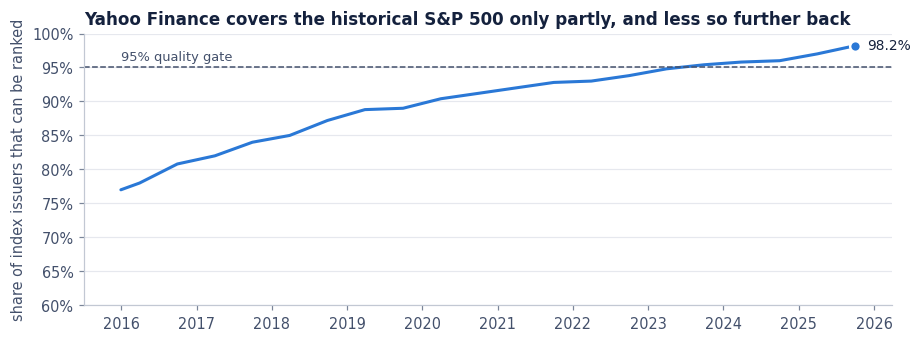

rebalances 2015-12 to 2025-09: coverage 77.0% to 98.2%, eligible names 385 to 491


In [10]:
MEMBERS_Q = {}        # trade month -> every index member at the reference date, with its status

def coverage_table(months):
    rows = {}
    for m in months:
        ref = m - CFG.reference_lag
        u = universe_at(ref, SPELLS, PANEL, CFG)
        MEMBERS_Q[m] = u
        counts = u["status"].value_counts()
        issuers = len(u) - counts.get("secondary share class", 0)
        el = list(u.loc[u["status"] == "eligible", "yahoo"])
        cap, back = PANEL["mcap"].loc[ref].reindex(el), PANEL["shares_carried_back"].loc[ref].reindex(el)
        age = PANEL["shares_age_days"].loc[ref].reindex(el)[~back.to_numpy()]
        rows[m] = {"reference date": PANEL["sessions"][ref].date(), "index members (tickers)": len(u), "issuers (one class each)": issuers,
                   "eligible": counts.get("eligible", 0),
                   "no Yahoo history": counts.get("no Yahoo price history (delisted or unknown symbol)", 0),
                   "ticker reused": sum(v for k, v in counts.items() if k.startswith("ticker reused")),
                   "too little history": counts.get("listed too recently for the signal", 0) + counts.get("too few trading days in the measurement period", 0),
                   "no share count": counts.get("no share count on Yahoo", 0),
                   "no price": counts.get("no valid price on the reference date", 0),
                   "share count carried back": int(back.sum()),
                   "carried back, share of market value": float(cap[back.to_numpy()].sum() / cap.sum()),
                   "age of the share count, median (days)": float(age.median()), "oldest (days)": float(age.max())}
    t = pd.DataFrame(rows).T
    t["coverage"] = (t["eligible"] / t["issuers (one class each)"]).astype(float)
    return t

REBALANCES = [m for m in pd.period_range(FIRST_TRADE, P(CFG.last_holding_month) - 1, freq="M")
              if m == FIRST_TRADE or m.month in CFG.rebalance_months]
COVERAGE = coverage_table(REBALANCES)
COVERAGE.index.name = "trade month"
display(savetable(COVERAGE, "tab_coverage").style.format({"coverage": "{:.1%}", "carried back, share of market value": "{:.1%}",
                                                           "age of the share count, median (days)": "{:.0f}", "oldest (days)": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(8.5, 3.2))
x = PANEL["sessions"][COVERAGE.index].values
ax.plot(x, COVERAGE["coverage"], color=BLUE)
ax.axhline(CFG.gate_min_coverage, color=INK2, lw=1, ls="--")
ax.annotate("95% quality gate", (x[0], CFG.gate_min_coverage), xytext=(0, 5), textcoords="offset points", fontsize=8.5, color=INK2)
end_label(ax, x[-1], COVERAGE["coverage"].iloc[-1], pct(COVERAGE["coverage"].iloc[-1]), BLUE)
ax.set_ylim(0.6, 1.0); percent_axis(ax); ax.set_ylabel("share of index issuers that can be ranked")
ax.set_title("Yahoo Finance covers the historical S&P 500 only partly, and less so further back")
plt.tight_layout(); savefig(fig, "fig_coverage")

print(f"rebalances {REBALANCES[0]} to {REBALANCES[-1]}: coverage {COVERAGE['coverage'].min():.1%} to {COVERAGE['coverage'].max():.1%}, "
      f"eligible names {int(COVERAGE['eligible'].min())} to {int(COVERAGE['eligible'].max())}")

### 3.4 Data-quality gates

The acceptance criteria below are quality gates on the data. Passing them is not proof that bias is absent.

In [11]:
# membership check 1: the size of the reconstructed index (the S&P 500 has had 503-505 tickers since dual share
# classes were admitted in 2015)
sizes = COVERAGE["index members (tickers)"]

# membership check 2: the constituents table carries its own "Date added" column, maintained separately from the
# change log. For today's members the two sources should tell the same story.
cons = constituents_raw.copy(); cons["added"] = pd.to_datetime(cons["Date added"], errors="coerce")
today = spells_raw[spells_raw["end"].isna()].merge(cons[["Symbol", "added"]], left_on="ticker", right_on="Symbol", how="left")
window = pd.Timestamp(CFG.data_start)
agree = np.where(today["start"].isna(), today["added"] <= window, (today["start"] - today["added"]).abs() <= pd.Timedelta(days=7))
agree = agree | (today["start"].notna() & (today["added"] < today["start"]))      # re-entries: first entry predates this stay
membership_agreement = float(np.mean(agree))
disagree = today.loc[~agree, ["ticker", "name", "start", "added"]].rename(columns={"start": "start per change log", "added": "date added per constituents table"})

def eligible_symbols(m):
    u = MEMBERS_Q[m]
    return list(u.loc[u["status"] == "eligible", "yahoo"])

held_stale = int(sum(PANEL["stale"].loc[m:, eligible_symbols(m)].iloc[1:7].sum().sum() for m in REBALANCES))
observed = 1.0 - COVERAGE["share count carried back"] / COVERAGE["eligible"]
later = COVERAGE.iloc[1:]
gates = pd.DataFrame([
    ["Membership replay", "0 unmatched change-log entries", f"{len(replay_issues)} unmatched", len(replay_issues) == 0],
    ["Reconstructed index size", "500-505 tickers at every reference date", f"{int(sizes.min())}-{int(sizes.max())}", bool(sizes.between(500, 505).all())],
    ["Membership agrees with a second table", ">= 95% of today's members", pct(membership_agreement), membership_agreement >= CFG.gate_min_coverage],
    ["Eligible securities", f">= {CFG.gate_min_names} at every rebalance", f"minimum {int(COVERAGE['eligible'].min())}", bool(COVERAGE["eligible"].min() >= CFG.gate_min_names)],
    ["Coverage: index issuers that can be ranked", f">= {CFG.gate_min_coverage:.0%} at every rebalance", f"minimum {pct(COVERAGE['coverage'].min())}", bool(COVERAGE["coverage"].min() >= CFG.gate_min_coverage)],
    ["Share count dated on or before the reference date, first purchase", f">= {CFG.gate_min_coverage:.0%} of eligible stocks", pct(observed.iloc[0]), bool(observed.iloc[0] >= CFG.gate_min_coverage)],
    ["Share count dated on or before the reference date, later rebalances", f">= {CFG.gate_min_coverage:.0%} of eligible stocks", f"minimum {pct(observed.iloc[1:].min())}", bool(observed.iloc[1:].min() >= CFG.gate_min_coverage)],
    ["Stale valuations of eligible stocks while held", "0", str(held_stale), held_stale == 0],
    ["Prices positive, dates sorted and unique, December 2025 included", "all true", "all true", True],
], columns=["gate", "requirement", "result", "passed"])
gates["passed"] = gates["passed"].map({True: "PASS", False: "FAIL"})
display(savetable(gates.set_index("gate"), "tab_quality_gates"))
if len(disagree):
    small = disagree["start per change log"].notna()
    print(f"Today's members where the two membership tables disagree: {int(small.sum())} differ by a few days or weeks in the entry date; "
          f"{int((~small).sum())} show a later entry in the constituents table than the change log implies.")
    display(disagree.set_index("ticker"))

# every exclusion is logged
exclusions = pd.concat([MEMBERS_Q[m].loc[MEMBERS_Q[m]["status"] != "eligible", ["ticker", "name", "status", "reason_out"]].assign(trade_month=str(m))
                        for m in REBALANCES])
savetable(exclusions.set_index("trade_month"), "log_exclusions")
print(f"exclusion log: {len(exclusions):,} member-rebalances excluded ({exclusions['ticker'].nunique()} different securities); "
      "saved to outputs/tables/log_exclusions.csv")
first = exclusions[exclusions["trade_month"] == str(FIRST_TRADE)]
print(f"\nExcluded at the first purchase ({FIRST_TRADE}, reference date {PANEL['sessions'][FIRST_REFERENCE].date()}): {len(first)} securities, by reason:")
print(first["status"].value_counts().to_string())
why = first.loc[first["status"].str.startswith("no Yahoo price"), "reason_out"].str.lower()
print(f"\nOf those without Yahoo history, {int(why.str.contains('acqui|merg|purchas|private|bought').sum())} left the index through a takeover or merger, "
      f"{int(why.str.contains('market cap').sum())} through a market-capitalisation change (many of them later acquired or failed), "
      f"{int((why == '').sum())} are still index members whose history Yahoo does not carry under the current symbol.")

,requirement,result,passed
gate,,,
Membership replay,0 unmatched change-log entries,0 unmatched,PASS
Reconstructed index size,500-505 tickers at every reference date,503-505,PASS
Membership agrees with a second table,>= 95% of today's members,99.2%,PASS
Eligible securities,>= 400 at every rebalance,minimum 385,FAIL
Coverage: index issuers that can be ranked,>= 95% at every rebalance,minimum 77.0%,FAIL
"Share count dated on or before the reference date, first purchase",>= 95% of eligible stocks,90.1%,FAIL
"Share count dated on or before the reference date, later rebalances",>= 95% of eligible stocks,minimum 98.9%,PASS
Stale valuations of eligible stocks while held,0,0,PASS
"Prices positive, dates sorted and unique, December 2025 included",all true,all true,PASS


Today's members where the two membership tables disagree: 0 differ by a few days or weeks in the entry date; 4 show a later entry in the constituents table than the change log implies.


,name,start per change log,date added per constituents table
ticker,,,
D,Dominion Energy,NaT,2016-11-30
SRE,Sempra,NaT,2017-03-17
SW,Smurfit Westrock,NaT,2024-07-08
TROW,T. Rowe Price,NaT,2019-07-29


exclusion log: 1,179 member-rebalances excluded (158 different securities); saved to outputs/tables/log_exclusions.csv

Excluded at the first purchase (2015-12, reference date 2015-11-30): 120 securities, by reason:
status
no Yahoo price history (delisted or unknown symbol)              89
no share count on Yahoo                                          11
ticker reused: Yahoo series starts after the membership began     9
secondary share class                                             5
listed too recently for the signal                                4
ticker reused: Yahoo series belongs to another issuer             2

Of those without Yahoo history, 72 left the index through a takeover or merger, 13 through a market-capitalisation change (many of them later acquired or failed), 0 are still index members whose history Yahoo does not carry under the current symbol.


In [12]:
age_med = COVERAGE["age of the share count, median (days)"].astype(float)
old = age_med > 90                                               # reference dates at which the usual count is older than a quarter
both_and = lambda items: ", ".join(items[:-1]) + (" and " if len(items) > 1 else "") + items[-1]
age_outage = age_med[old].copy(); age_outage.index = COVERAGE.loc[old, "reference date"]
age_usual = age_med[~old]
first_members = MEMBERS_Q[FIRST_TRADE]
no_count_first = sorted(first_members.loc[first_members["status"] == "no share count on Yahoo", "name"])
g = gates.set_index("gate")["passed"]
say(f"""
**Result of the gates.** The membership reconstruction {pick(g['Membership replay'] == 'PASS' and g['Reconstructed index size'] == 'PASS', 'passes', 'does NOT pass')}: the replay leaves {len(replay_issues)} unmatched entries and reproduces the known size of the index ({int(sizes.min())} to {int(sizes.max())} tickers) at every reference date. The second membership table agrees for {pct(membership_agreement)} of today's members. Where it disagrees, the entry dates differ by days or weeks, or the constituents table shows a later entry date for a company that the change log treats as a continuous member; the exact match of the index size supports the change log in those cases, and these companies are treated as members throughout.{pick('SW' in set(disagree['ticker']), ' One of them is a special case: Smurfit Westrock took the place of WestRock in July 2024, and the change log has no entry for it. It holds that place in the member count throughout, but it is not ranked before it has enough trading history of its own (section 4.1), because the earlier prices Yahoo shows under its symbol are not those of the listed stock.', '')}

The **coverage gate {pick(g['Coverage: index issuers that can be ranked'] == 'PASS', 'passes', 'fails')}**: at the first purchase only {pct(COVERAGE['coverage'].iloc[0])} of the index's issuers can be ranked ({int(COVERAGE['eligible'].iloc[0])} stocks against a gate of {CFG.gate_min_names}), at the last rebalance {pct(COVERAGE['coverage'].iloc[-1])}. Of the {int(COVERAGE['issuers (one class each)'].iloc[0])} issuers at the first date, {int(COVERAGE['no Yahoo history'].iloc[0])} have no price history on Yahoo, {int(COVERAGE['ticker reused'].iloc[0])} have a ticker that now belongs to another security, {int(COVERAGE['too little history'].iloc[0])} too little trading history and {int(COVERAGE['no share count'].iloc[0])} no share count. On 24 November 2026 it was decided for the group (to be confirmed by all members) to continue with Yahoo Finance as the only source of prices and share counts. The consequence, a universe tilted towards companies that still exist today, is measured in section 5.2 and discussed with the other risks in section 9.

**Share counts.** At the first purchase {pct(observed.iloc[0])} of the eligible stocks have a share count dated on or before the reference date (dated: whether Yahoo entered its first counts on the dates they carry cannot be checked, see section 3.2); for the rest a count from the following {CFG.share_carry_back_days} days is carried back ({pct(COVERAGE['carried back, share of market value'].iloc[0])} of the market value), because Yahoo's history starts in October 2015. From the second rebalance on the share is at least {pct(observed.iloc[1:].min())}, and carried-back counts stand for at most {pct(later['carried back, share of market value'].max())} of the market value. The count in use is typically {int(age_usual.median())} days old (median over the other rebalances); at the reference dates in and around Yahoo's outage, {both_and([str(d) for d in age_outage.index])}, the median age is {both_and([f'{v:.0f}' for v in age_outage])} days. Between {int(COVERAGE['no share count'].min())} and {int(COVERAGE['no share count'].max())} index members per rebalance cannot be ranked because Yahoo has no share count for them: companies whose ticker changed and for whose former symbol Yahoo has no counts. At the first purchase these are {', '.join(no_count_first)}. The sample starts in January 2016 for the same reason: earlier weights would rest almost entirely on carried-back counts.
""")


**Result of the gates.** The membership reconstruction passes: the replay leaves 0 unmatched entries and reproduces the known size of the index (503 to 505 tickers) at every reference date. The second membership table agrees for 99.2% of today's members. Where it disagrees, the entry dates differ by days or weeks, or the constituents table shows a later entry date for a company that the change log treats as a continuous member; the exact match of the index size supports the change log in those cases, and these companies are treated as members throughout. One of them is a special case: Smurfit Westrock took the place of WestRock in July 2024, and the change log has no entry for it. It holds that place in the member count throughout, but it is not ranked before it has enough trading history of its own (section 4.1), because the earlier prices Yahoo shows under its symbol are not those of the listed stock.

The **coverage gate fails**: at the first purchase only 77.0% of the index's issuers can be ranked (385 stocks against a gate of 400), at the last rebalance 98.2%. Of the 500 issuers at the first date, 89 have no price history on Yahoo, 11 have a ticker that now belongs to another security, 4 too little trading history and 11 no share count. On 24 November 2026 it was decided for the group (to be confirmed by all members) to continue with Yahoo Finance as the only source of prices and share counts. The consequence, a universe tilted towards companies that still exist today, is measured in section 5.2 and discussed with the other risks in section 9.

**Share counts.** At the first purchase 90.1% of the eligible stocks have a share count dated on or before the reference date (dated: whether Yahoo entered its first counts on the dates they carry cannot be checked, see section 3.2); for the rest a count from the following 120 days is carried back (5.7% of the market value), because Yahoo's history starts in October 2015. From the second rebalance on the share is at least 98.9%, and carried-back counts stand for at most 0.3% of the market value. The count in use is typically 11 days old (median over the other rebalances); at the reference dates in and around Yahoo's outage, 2017-08-31, 2018-02-28 and 2018-08-31, the median age is 115, 296 and 480 days. Between 0 and 11 index members per rebalance cannot be ranked because Yahoo has no share count for them: companies whose ticker changed and for whose former symbol Yahoo has no counts. At the first purchase these are Baker Hughes, CBRE Group, Capri Holdings, Coca-Cola Enterprises, Computer Sciences Corporation, Dr Pepper Snapple Group, Jefferies Financial Group, S&P Global, Tapestry, Inc., Welltower, Wyndham Worldwide. The sample starts in January 2016 for the same reason: earlier weights would rest almost entirely on carried-back counts.


## 4. Methodology: signal, selection, weights, timing and portfolio accounting

The strategy applies the published construction rules of the **S&P 500 Momentum index** to individual stocks: rank the index members by risk-adjusted price momentum, hold the best fifth, weight them by market value times momentum score, and repeat twice a year. Sections 4.1 to 4.3 state the rules, section 4.4 the timing, and section 4.5 every point where this notebook has to depart from the index.

### 4.1 The momentum score

All four steps use only prices up to the **reference date**, the last trading day of the month before the trade (the end of February and of August).

1. **Momentum value.** The price change over twelve months, leaving out the most recent month. With *m* the reference month and *P* the closing price on the last session of a month (without dividends):

$$MV_{i} = \frac{P_{i,m-1}}{P_{i,m-13}} - 1$$

   The most recent month is skipped because very recent winners tend to give back part of their gain over the following weeks (short-term reversal). A stock without a price thirteen months back is measured over nine months instead; a stock with less history than that, or that traded on fewer than 150 days of the period, is not ranked. A stock's history starts on its first day of regular trading, defined as the first day from which Yahoo reports trading volume on each of the next sixty trading days. For nearly all stocks that is the first day of the data. For two index members (Smurfit Westrock and Amcor) Yahoo shows a price history from before the US listing, taken from a foreign line that trades rarely or not at all; it is not the history of the listed stock and is not used.
2. **Risk adjustment.** The momentum value is divided by the standard deviation of the stock's *daily* price changes over the same period. For the same gain, a steadier path gives a higher value.
3. **Z-score.** The risk-adjusted value is standardised across all eligible stocks (subtract the mean, divide by the standard deviation) and capped at ±3, so that one extreme stock cannot dominate.
4. **Momentum score.** *S* = 1 + *z* if *z* > 0, and *S* = 1 / (1 − *z*) if *z* < 0. The score is always positive, equals 1 for an average stock and lies between ¼ and 4.

Example for the rebalance at the end of March 2021: reference date 26 February 2021; momentum value from the close of 31 January 2020 to the close of 29 January 2021; February 2021 is skipped; the trade happens at the close of 31 March 2021 and the first holding month is April 2021.

### 4.2 Selection: the best fifth, with a buffer

The eligible stocks are ranked by z-score (ties, which arise at the cap of ±3: by the uncapped risk-adjusted value, then alphabetically, so the result is deterministic). The strategy holds **one fifth** of them. To avoid trading stocks that hover around the cut-off, the index applies a *20% buffer rule*, with *N* the number of stocks to hold:

1. the best 0.8 × *N* stocks are selected in any case;
2. stocks already held that still rank within the best 1.2 × *N* are kept, in rank order, until *N* is reached;
3. if places are left, the best stocks not yet selected fill them.

At the first purchase nothing is held, so the best *N* are bought.

For the analysis in sections 5 to 8 the eligible stocks are also cut into five groups of equal size by rank, **Q1 = lowest scores, Q5 = highest**. These quintile portfolios use the same weighting rule but no buffer; they show whether returns rise with the score. The strategy itself is the top group *with* the buffer.

### 4.3 Weights: market value times momentum score, with limits

At the reference date each selected stock gets a raw weight proportional to **market capitalisation × momentum score**. Two limits then apply to every stock: its weight may not exceed **9%**, and it may not exceed **three times its market-value weight** among the selected stocks. Weight above a limit is passed on to the other stocks in proportion to their raw weights, repeated until no limit is exceeded.

*How the second limit is read.* The methodology says "three times the security's market capitalization weight in the index" (until September 2026: "three times its market capitalization"). This notebook reads "the index" as the momentum index itself, that is, the weight the stock would have if the selected stocks were weighted by market value alone. Read this way the two limits could be met at every rebalance of the sample. Read as the weight in the S&P 500, they often cannot (the limits of the selected stocks then add up to less than 100%) and need a further rule that the methodology does not give. For that case this notebook raises the multiple of three step by step until the limits leave room for 100%; section 8 shows the result under this second reading.

The weights are fixed with reference-date prices. By the trade date, one month later, they have drifted with each stock's price, exactly as in the index.

### 4.4 Timing: what is known when

| Step | When | Information used |
|---|---|---|
| Momentum value and volatility | closes up to the last session of month *m*−1 | closing prices only |
| Universe, market values, scores, selection, weights | reference date = last session of month *m* (February, August) | index members on that day; share counts reported by that day; prices of that day |
| Execution | close of the last session of month *m*+1 (March, September) | the weights of the reference date, drifted with prices; a stock that has left the index or has no price by then is not bought |
| Holding period | six months, starting with the month after the trade | – |

Every input is at least one month old when the trade happens, and new holdings never receive the return of the month in which they are bought. This is the `lag ≥ 1` rule from Lecture 4.

### 4.5 Where this notebook departs from the index

| Index rule | This notebook | Reason |
|---|---|---|
| Rebalance effective after the close of the third Friday of March and September | Trade at the close of the **last** session of March and September | The engine works with month-end prices; the trade is one to two weeks later than the index's |
| Float-adjusted market capitalisation, each share class listed separately | Total market capitalisation per company, one share class per issuer | Yahoo has no history of free float; its share counts are per company |
| Until September 2026 the 9% limit applied to each share class | The 9% limit applies to the company (the index's rule since September 2026) | Follows from one share class per issuer; it matters only for companies with two listed classes, such as Alphabet |
| All S&P 500 members | Members whose history Yahoo still carries | Survivorship limitation of the data source (sections 3.3 and 5.2) |
| The number of stocks held is one fifth of the index universe (100 for the S&P 500) | One fifth of the **eligible** stocks (fewer than 100 throughout the sample, see the rebalance table in section 5) | With part of the index missing, a fifth of what can be ranked keeps the selection as strict as the index's; section 8 shows the result with 100 stocks |
| Z-scores are computed across the index universe | Across the eligible stocks | Stocks that cannot be ranked have no value to standardise |
| The buffer rule favours current index constituents | It favours the stocks the portfolio actually holds | A selected stock that could not be bought is not a holding |
| A stock must have traded on at least 150 days of the measurement period | Days with a closing price on Yahoo are counted, from the stock's first day of regular trading on | Yahoo's daily data are the only record of trading |
| A stock deleted from the S&P 500 leaves the momentum index at once | Held until the next rebalance | Few cases; avoids extra trades |
| A missing month-end price is replaced by the price of up to ten days earlier | No replacement; the stock is not ranked | S&P 500 stocks trade every day |
| The index existed before 2016 | First purchase at the close of 31 December 2015 with 30 November 2015 as reference date, then the March and September calendar | Yahoo's share counts start in October 2015 |
| No trading costs | 10 basis points per dollar bought or sold | A real portfolio pays to trade |

Section 5.2 measures how much these differences matter, by comparing the backtest with a real fund that tracks the index.

### 4.6 Drift, costs and turnover

* **Long-only, fully invested**, no leverage, no derivatives, no market-timing overlay, fractional shares allowed.
* **Drift.** Between rebalancing dates nothing is traded: each position grows with its own return, so weights drift, and a stock can rise above the 9% limit until the next rebalance. Holding weights fixed every month would silently assume monthly rebalancing at zero cost (the hidden assumption shown in Lecture 4.3). The engine therefore tracks **dollar holdings**, not weights:
  gross return = Σ beginning weight × asset return, and drifted weight = beginning weight × (1 + asset return) / (1 + portfolio return).
* **Delistings.** If a held stock stops trading, the position is valued at its last quoted price, the proceeds are held as cash earning the FRED risk-free proxy, and they are reinvested at the next rebalance. Missing returns are never replaced by zero.
* **Costs.** Every dollar bought or sold costs *c* = 0.10% (10 basis points), including the initial purchase. Costs are paid out of the portfolio (self-financing). With *V* the portfolio value before trading, *H*ᵢ the current dollar holdings and *w*ᵢ the target weights, the post-cost value *V\** solves

$$V^{*} = V - c \sum_i \left| w_i V^{*} - H_i \right|$$

  and the new holdings are *w*ᵢ *V\**. Cumulative value starts at 1 **before** the initial cost, and the cost of a trade shows up in the return of the following month.
* **Turnover** is reported two ways: *traded notional* = (purchases + sales) / portfolio value, and *one-way turnover* = ½ Σ |target weight − drifted weight|, taken over all securities and cash. The initial investment counts as 100% one-way turnover and is reported separately from recurring turnover.
* **Gross returns** come from a second, separately simulated run with *c* = 0, not from adding an estimate back to net returns.

In [13]:
# [engine] exported to the repo by tools/export_engine.py - see the README
def assign_groups(score, n_groups):
    """Rank ascending by score (ties: by identifier) and cut into n equal-count groups, 1 = lowest.

    When the count is not divisible by n, the extra names go to the HIGHEST groups, so sizes differ by at most one.
    """
    s = score.dropna()
    table = pd.DataFrame({"score": s.to_numpy(dtype=float), "id": [str(i) for i in s.index]}, index=s.index)
    order = table.sort_values(["score", "id"], kind="mergesort").index
    base, extra = divmod(len(order), n_groups)
    sizes = [base + (1 if g > n_groups - extra else 0) for g in range(1, n_groups + 1)]
    labels = np.repeat(np.arange(1, n_groups + 1), sizes)
    return pd.Series(labels, index=order, dtype="float").reindex(score.index)


def momentum_score(value, vol, winsor=3.0, risk_adjust=True):
    """(risk-adjusted value, capped z-score, momentum score) for one cross-section (S&P methodology, Appendix B).

    z = (x - mean) / standard deviation across the stocks, capped at +/- winsor;
    score = 1 + z for z > 0 and 1 / (1 - z) for z < 0, so it is 1 at z = 0 and always positive.
    """
    x = (value / vol) if risk_adjust else value.astype(float)
    sd = x.std(ddof=1)
    z = ((x - x.mean()) / sd).clip(-winsor, winsor) if sd > 0 else x * 0.0
    score = pd.Series(np.where(z > 0, 1.0 + z, 1.0 / (1.0 - np.minimum(z, 0.0))), index=z.index)
    return x, z, score


def select_with_buffer(ranked, current, target, buffer):
    """Selection with the buffer rule of the S&P Momentum indices.

    ranked : identifiers, best first; current : identifiers held now; target : number of stocks to hold.
    1. The best (1 - buffer) x target stocks are selected. 2. Stocks held now that rank within the best
    (1 + buffer) x target are re-selected in rank order until the target is reached. 3. If places are left, the
    best stocks not yet selected fill them. Without holdings or with buffer = 0 this is simply the best `target`.
    """
    ranked = list(ranked)
    if not current or buffer <= 0:
        return ranked[:target]
    sure = int(math.floor(target * (1.0 - buffer) + 0.5))
    reach = int(math.floor(target * (1.0 + buffer) + 0.5))
    chosen = ranked[:sure]
    for name in ranked[sure:reach]:
        if len(chosen) >= target:
            break
        if name in current:
            chosen.append(name)
    taken = set(chosen)
    for name in ranked[sure:]:
        if len(chosen) >= target:
            break
        if name not in taken:
            chosen.append(name)
    return chosen


def capped_weights(raw, limit):
    """Weights proportional to `raw` that sum to 1 with weight_i <= limit_i. Weight above a limit is passed on to
    the other names in proportion to their raw weights, repeated until no limit is exceeded."""
    r, lim = np.asarray(raw, dtype=float), np.asarray(limit, dtype=float)
    if lim.sum() < 1.0 - 1e-12:
        raise ValueError("the weight limits add up to less than 100%")
    w = r / r.sum()
    fixed = np.zeros(len(r), dtype=bool)
    for _ in range(len(r) + 1):
        over = (w > lim + 1e-15) & ~fixed
        if not over.any():
            break
        fixed |= over
        w[fixed] = lim[fixed]
        free = ~fixed
        if not free.any():
            break
        w[free] = r[free] / r[free].sum() * (1.0 - lim[fixed].sum())
    return pd.Series(w, index=raw.index) if isinstance(raw, pd.Series) else w


def weight_limits(cap_weight, cfg):
    """Limit for each stock's weight: the lower of cfg.max_weight and cfg.max_cap_multiple x its market-cap weight.
    If these limits left no room for 100%, the multiple is raised by 1 at a time until they do.
    Returns (limits, multiple used)."""
    cw = np.asarray(cap_weight, dtype=float)
    if not np.isfinite(cw).all() or (cw <= 0).any():
        raise ValueError("market-cap weights must be positive numbers")
    if cfg.max_weight * len(cw) < 1.0 - 1e-12:
        raise ValueError(f"{len(cw)} stocks cannot be held with a limit of {cfg.max_weight:.0%} each")
    multiple = float(cfg.max_cap_multiple)
    while True:
        limit = np.minimum(cfg.max_weight, multiple * cw)
        if limit.sum() >= 1.0 - 1e-12:
            return limit, multiple
        multiple += 1.0


def strategy_weights(table, names, cfg, weighting=None, capped=True):
    """Weights at the reference date for the stocks `names` of one formation table.

    weighting : "cap_score" = market capitalisation x momentum score, "cap" = market capitalisation, "equal" = 1/N
                (default cfg.weighting)
    capped    : each weight is at most cfg.max_weight and at most cfg.max_cap_multiple x the stock's market-cap
                weight (see weight_limits). cfg.cap_reference says in what: "holdings" (among `names`, the base
                case) or "universe" (among all eligible stocks).
    Returns (weights, multiple used).
    """
    s = table.loc[list(names)]
    weighting = weighting or cfg.weighting
    raw = {"cap_score": s["mcap"] * s["score"], "cap": s["mcap"], "equal": pd.Series(1.0, index=s.index)}[weighting]
    if not capped or weighting == "equal":
        return raw / raw.sum(), np.nan
    base = s["mcap"] / s["mcap"].sum() if cfg.cap_reference == "holdings" else s["uw"]
    limit, multiple = weight_limits(base, cfg)
    return capped_weights(raw, pd.Series(limit, index=s.index)), multiple


def formation_table(month, spells_mapped, panel, cfg):
    """Everything known for a rebalance traded at the close of `month`; reference date = end of month - reference_lag.

    Returns (eligible, everyone). `eligible` is indexed by Yahoo symbol and holds, as of the reference date: momentum
    value, volatility, risk-adjusted value (ram), capped z-score, momentum score, market capitalisation (mcap),
    weight in the eligible universe (uw), rank (1 = best) and group (cfg.n_groups = best scores); plus `drift`, the
    price change from the reference date to the trade date, and `tradable`, whether the stock is still an index
    member with a price on the trade date. `everyone` lists all index members at the reference date with the reason
    for each exclusion.
    """
    ref = month - cfg.reference_lag
    inputs = momentum_inputs(panel, ref, cfg)
    everyone = universe_at(ref, spells_mapped, panel, cfg, inputs)
    e = everyone[everyone["status"] == "eligible"].set_index("yahoo")[["ticker", "name"]].copy()
    e = e.join(inputs.reindex(e.index))
    e["ram"], e["z"], e["score"] = momentum_score(e["value"], e["vol"], cfg.winsor_z, cfg.risk_adjust)
    e["mcap"] = panel["mcap"].loc[ref].reindex(e.index)
    e["carried_back"] = panel["shares_carried_back"].loc[ref].reindex(e.index).astype(bool)
    e["uw"] = e["mcap"] / e["mcap"].sum()
    order = e.assign(_id=[str(i) for i in e.index]).sort_values(["z", "ram", "_id"], ascending=[False, False, True],
                                                                 kind="mergesort").index
    e["rank"] = pd.Series(np.arange(1, len(order) + 1), index=order)
    e["group"] = assign_groups(-e["rank"], cfg.n_groups)
    close = panel["px_close"]
    e["drift"] = close.loc[month].reindex(e.index) / close.loc[ref].reindex(e.index)
    still = members_on(spells_mapped, panel["sessions"][month])
    still = set(still.loc[still["block"] == "", "yahoo"])
    e["tradable"] = (e.index.isin(list(still)) & panel["px"].loc[month].reindex(e.index).notna().to_numpy()
                     & e["drift"].notna().to_numpy())
    return e, everyone


def build_targets(forms, months, cfg, select="top", weighting=None, capped=True):
    """Target weights at the close of each rebalance month in `months`, in order (the buffer rule looks back).

    select : "top" = the best 1/cfg.n_groups of the eligible stocks, plus cfg.target_shift (or cfg.target_count
             stocks, if set), with the buffer rule (the strategy);
             "all" = every eligible stock; an integer g = the stocks of group g, without buffer
    Weights are set at the reference date (strategy_weights), drift with prices to the trade date, and are rescaled
    over the stocks that can still be bought. Returns (targets, log) with one log row per rebalance.
    """
    targets, rows, current = {}, [], set()
    for m in months:
        f = forms[m]
        if isinstance(select, str) and select == "top":
            target = cfg.target_count or int(math.floor(len(f) / cfg.n_groups + 0.5)) + cfg.target_shift
            names = select_with_buffer(list(f.sort_values("rank").index), current, target, cfg.buffer)
        elif isinstance(select, str) and select == "all":
            names = list(f.index)
        else:
            names = list(f.index[f["group"] == select])
        if not names:
            targets[m], current = pd.Series(dtype=float), set()
            continue
        w_ref, multiple = strategy_weights(f, names, cfg, weighting, capped)
        ok = f.loc[names, "tradable"].to_numpy()
        w = (w_ref * f.loc[names, "drift"])[ok]
        w = w / w.sum()
        targets[m] = w
        back = f.loc[w.index, "carried_back"].to_numpy()
        rows.append({"trade month": m, "eligible": len(f), "selected": len(names), "bought": len(w),
                     "already held": len(current & set(names)), "new": len(set(names) - current),
                     "at the weight limit": int((w_ref >= cfg.max_weight - 1e-9).sum()) if capped else 0,
                     "multiple used": multiple, "largest weight": float(w.max()),
                     "ten largest weights": float(w.nlargest(10).sum()),
                     "selected, share of universe value": float(f.loc[names, "uw"].sum()),
                     "weight on carried-back share counts": float(w[back].sum())})
        current = set(w.index)                          # the buffer rule favours what is actually held
    log = pd.DataFrame(rows).set_index("trade month") if rows else pd.DataFrame()
    return targets, log


def schedule(start, end, rebalance_months):
    """Formation months: `start` itself plus every later month in `rebalance_months`, up to the month before `end`."""
    return [m for m in pd.period_range(start, end - 1, freq="M") if m == start or m.month in rebalance_months]


def solve_rebalance(nav, holdings, weights, cost_rate):
    """Self-financing rebalance. Solves V* = V - c * sum|w_i V* - H_i| and returns (V*, trades in dollars, cost)."""
    v = nav
    for _ in range(200):
        v_new = nav - cost_rate * np.abs(weights * v - holdings).sum()
        converged = abs(v_new - v) <= 1e-15 * max(abs(nav), 1.0)
        v = v_new
        if converged:
            break
    trades = weights * v - holdings
    return v, trades, cost_rate * np.abs(trades).sum()


def simulate(ret, rf, targets, cost_rate, start, end, last_month=None):
    """Chronological dollar accounting of a rebalanced, otherwise buy-and-hold portfolio.

    ret        : monthly simple returns, index = monthly Periods, columns = securities
    rf         : monthly risk-free return, earned by idle cash
    targets    : {formation month: Series of target weights}; a trade happens at the close of each key
    start, end : formation month of the first trade and last holding month. NAV is 1 at `start` BEFORE costs
    last_month : security -> month of its last quote when its data ends early (delisting), else NaT
    Returns nav (pre-trade value at each month-end), ret (net monthly return; the cost of a trade at the close
    of month m lowers the return of month m+1), a table of rebalances, monthly holdings statistics and events.
    """
    cols = list(ret.columns)
    pos = {c: i for i, c in enumerate(cols)}
    months = pd.period_range(start, end, freq="M")
    R = ret.reindex(months).to_numpy(dtype=float)
    RF = rf.reindex(months).to_numpy(dtype=float)
    dead_from = np.full(len(cols), np.iinfo(np.int64).max, dtype=np.int64)   # first step at which a position is cash
    if last_month is not None:
        for c, lm in last_month.dropna().items():
            if c in pos:
                dead_from[pos[c]] = max(int((lm - months[0]).n) + 1, 0)
    H = np.zeros(len(cols))
    cash = 1.0
    nav = np.empty(len(months))
    monthly, rebalances, events = [], [], []
    for k, m in enumerate(months):
        if k > 0:
            gone = (H > 0) & (dead_from <= k)             # last quote was in an earlier month: proceeds are cash
            if gone.any():
                for i in np.flatnonzero(gone):
                    events.append({"month": m, "security": cols[i], "event": "delisting proceeds moved to cash",
                                   "value": H[i]})
                cash += H[gone].sum()
                H[gone] = 0.0
            held = H > 0
            if np.isnan(R[k][held]).any():
                bad = [cols[i] for i in np.flatnonzero(held & np.isnan(R[k]))]
                raise ValueError(f"unexplained missing return for held position(s) {bad} in {m}")
            if cash > 0 and np.isnan(RF[k]):
                raise ValueError(f"no risk-free rate for {m}")
            H[held] *= 1.0 + R[k][held]
            cash *= 1.0 + (RF[k] if cash > 0 else 0.0)
        V = H.sum() + cash
        nav[k] = V
        sec_total = H.sum()
        w_sec = H[H > 0] / sec_total if sec_total > 0 else np.array([])
        monthly.append({"month": m, "positions": int((H > 0).sum()), "max_weight": (H.max() / V) if V > 0 else np.nan,
                        "effective_holdings": 1.0 / np.square(w_sec).sum() if len(w_sec) else 0.0,
                        "cash_weight": cash / V if V > 0 else np.nan})
        if m in targets and k < len(months) - 1:
            w = np.zeros(len(cols))
            tgt = targets[m]
            if len(tgt):
                w[[pos[c] for c in tgt.index]] = tgt.to_numpy(dtype=float)
            v_net, trades, cost = solve_rebalance(V, H, w, cost_rate)
            buys, sells = trades[trades > 0].sum(), -trades[trades < 0].sum()
            one_way = 0.5 * (np.abs(w - H / V).sum() + abs((1.0 - w.sum()) - cash / V))
            rebalances.append({"month": m, "holdings": int((w > 0).sum()), "nav_before": V, "cost": cost / V,
                               "traded_notional": (buys + sells) / V, "one_way_turnover": one_way,
                               "bought": buys / V, "sold": sells / V, "cash_before": cash / V,
                               "orders": int((np.abs(trades) > 1e-12 * V).sum())})
            H = w * v_net
            cash = v_net - H.sum()
            if abs(cash) < 1e-12:                         # fully invested: remove floating-point dust
                cash = 0.0
    nav = pd.Series(nav, index=months, name="nav")
    out = {"nav": nav, "ret": (nav / nav.shift(1) - 1.0).iloc[1:].rename("ret"),
           "rebalances": pd.DataFrame(rebalances).set_index("month") if rebalances else pd.DataFrame(),
           "monthly": pd.DataFrame(monthly).set_index("month"), "events": events}
    return out


def run_portfolio(panel, rf, targets, start, end, cost_rate):
    """Net run at `cost_rate` plus a separately simulated zero-cost (gross) run of the same target weights."""
    net = simulate(panel["ret"], rf, targets, cost_rate, start, end, panel["last_month"])
    gross = simulate(panel["ret"], rf, targets, 0.0, start, end, panel["last_month"])
    net["ret_gross"], net["nav_gross"], net["targets"] = gross["ret"], gross["nav"], targets
    return net

### 4.7 Worked example with made-up numbers

The table below uses **ten invented stocks** (not market data) to show each step with the same functions the backtest uses: momentum value, risk adjustment, z-score, momentum score, the buffer rule, the weight limits, the purchase with costs and the drift of the weights. To make the buffer and the limits visible with only ten stocks, the example holds five of them and uses a weight limit of 30% instead of 9%.

In [14]:
# ---- synthetic illustration: invented numbers, NOT market data ----
ex = pd.DataFrame(
    {"P(m-13)": [20, 50, 10, 80, 40, 25, 60, 30, 90, 15], "P(m-1)": [31, 60, 11.5, 84, 46, 24, 54, 26, 72, 21],
     "daily volatility": [0.030, 0.012, 0.010, 0.009, 0.011, 0.015, 0.014, 0.020, 0.016, 0.035],
     "market value ($bn)": [40, 900, 120, 300, 60, 80, 500, 30, 200, 20]},
    index=["AAA", "BBB", "CCC", "DDD", "EEE", "FFF", "GGG", "HHH", "III", "JJJ"], dtype=float)
ex["momentum value"] = ex["P(m-1)"] / ex["P(m-13)"] - 1                       # the most recent month is skipped
ex["risk-adjusted"], ex["z"], ex["score"] = momentum_score(ex["momentum value"], ex["daily volatility"], CFG.winsor_z)
ex["rank"] = ex["z"].rank(ascending=False).astype(int)
display(ex.sort_values("rank").style.format({"momentum value": "{:+.1%}", "daily volatility": "{:.1%}", "risk-adjusted": "{:.1f}",
                                              "z": "{:+.2f}", "score": "{:.2f}", "P(m-13)": "{:.0f}", "P(m-1)": "{:.1f}",
                                              "market value ($bn)": "{:.0f}"}))
ranked = list(ex.sort_values("rank").index)
held = {"BBB", "DDD", "FFF", "GGG", "III"}                                    # invented current holdings
plain = select_with_buffer(ranked, set(), 5, CFG.buffer)
chosen = select_with_buffer(ranked, held, 5, CFG.buffer)
print(f"ranking, best first: {ranked}")
print(f"without holdings the best five are bought: {plain}")
print(f"with holdings {sorted(held)}: the best four are selected in any case; the fifth place goes to "
      f"{[n for n in chosen if n not in ranked[:4]]}, a stock already held that still ranks within the best six, "
      f"instead of the newcomer ranked fifth ({ranked[4]}).")

demo = replace(CFG, max_weight=0.30)                                          # 9% cannot be met with five stocks
t = ex.rename(columns={"market value ($bn)": "mcap"})
w, multiple = strategy_weights(t, chosen, demo)
raw_w = t.loc[chosen, "mcap"] * t.loc[chosen, "score"]
cap_w = t.loc[chosen, "mcap"] / t.loc[chosen, "mcap"].sum()
assert multiple == demo.max_cap_multiple                                      # the limits leave room for 100%
display(pd.DataFrame({"market-value weight": cap_w, "score": t.loc[chosen, "score"], "raw weight (value x score)": raw_w / raw_w.sum(),
                      "limit": np.minimum(demo.max_weight, demo.max_cap_multiple * cap_w), "final weight": w}).style.format("{:.3f}"))
lim = np.minimum(demo.max_weight, demo.max_cap_multiple * cap_w)
print(f"at their limit: {[n for n in chosen if abs(w[n] - lim[n]) < 1e-9]}. The weight a stock cannot take is passed on to the "
      "others in proportion to their raw weights.")

w0 = pd.Series(0.0, index=ex.index); w0[w.index] = w
v_net, trades, cost = solve_rebalance(100.0, np.zeros(len(ex)), w0.values, CFG.cost_rate)
print(f"Purchase with $100: cost ${cost:.4f}, invested ${v_net:.4f} (check: {v_net:.4f} + {cost:.4f} = {v_net + cost:.4f})")
six_month_return = pd.Series([0.10, 0.04, 0.02, -0.03, 0.06, 0.00, 0.08, -0.05, 0.01, 0.20], index=ex.index)   # invented
H0 = w0 * v_net; H1 = H0 * (1 + six_month_return)
display(pd.DataFrame({"weight at purchase": w0[w.index], "invented six-month return": six_month_return[w.index],
                      "drifted weight": H1[w.index] / H1.sum()}).style.format({"weight at purchase": "{:.3f}", "drifted weight": "{:.3f}",
                                                                                 "invented six-month return": "{:+.0%}"}))
print("Nothing is traded for six months, so the weights drift with prices. At the next rebalance only the difference between "
      "the drifted holdings and the new target weights is traded, and only that difference costs 10 basis points.")

,P(m-13),P(m-1),daily volatility,market value ($bn),momentum value,risk-adjusted,z,score,rank
AAA,20,31.0,3.0%,40,+55.0%,18.3,+1.15,2.15,1
BBB,50,60.0,1.2%,900,+20.0%,16.7,+1.01,2.01,2
CCC,10,11.5,1.0%,120,+15.0%,15.0,+0.86,1.86,3
EEE,40,46.0,1.1%,60,+15.0%,13.6,+0.74,1.74,4
JJJ,15,21.0,3.5%,20,+40.0%,11.4,+0.55,1.55,5
DDD,80,84.0,0.9%,300,+5.0%,5.6,+0.03,1.03,6
FFF,25,24.0,1.5%,80,-4.0%,-2.7,-0.68,0.59,7
HHH,30,26.0,2.0%,30,-13.3%,-6.7,-1.03,0.49,8
GGG,60,54.0,1.4%,500,-10.0%,-7.1,-1.08,0.48,9
III,90,72.0,1.6%,200,-20.0%,-12.5,-1.54,0.39,10


ranking, best first: ['AAA', 'BBB', 'CCC', 'EEE', 'JJJ', 'DDD', 'FFF', 'HHH', 'GGG', 'III']
without holdings the best five are bought: ['AAA', 'BBB', 'CCC', 'EEE', 'JJJ']
with holdings ['BBB', 'DDD', 'FFF', 'GGG', 'III']: the best four are selected in any case; the fifth place goes to ['DDD'], a stock already held that still ranks within the best six, instead of the newcomer ranked fifth (JJJ).


,market-value weight,score,raw weight (value x score),limit,final weight
AAA,0.028,2.151,0.034,0.085,0.083
BBB,0.634,2.005,0.714,0.300,0.300
CCC,0.085,1.860,0.088,0.254,0.216
EEE,0.042,1.740,0.041,0.127,0.101
DDD,0.211,1.034,0.123,0.300,0.300


at their limit: ['BBB', 'DDD']. The weight a stock cannot take is passed on to the others in proportion to their raw weights.
Purchase with $100: cost $0.0999, invested $99.9001 (check: 99.9001 + 0.0999 = 100.0000)


,weight at purchase,invented six-month return,drifted weight
AAA,0.083,+10%,0.090
BBB,0.300,+4%,0.305
CCC,0.216,+2%,0.215
EEE,0.101,+6%,0.105
DDD,0.300,-3%,0.285


Nothing is traded for six months, so the weights drift with prices. At the next rebalance only the difference between the drifted holdings and the new target weights is traded, and only that difference costs 10 basis points.


### 4.8 Performance measures: definitions and calculation assumptions

All measures use the **monthly simple net returns** of the aligned sample, in decimals, with sample standard deviations (`ddof = 1`). Full precision is kept in the calculations; rounding happens only for display.

| Measure | Formula | Annualised? |
|---|---|---|
| Average return | 12 × mean(r) (arithmetic) | yes |
| Volatility | √12 × SD(r) | yes |
| Sharpe ratio | √12 × mean(r − RF) / SD(r − RF) | yes |
| Alpha and beta | OLS with intercept: r − RF = α + β (r_SPY − RF) + ε; reported alpha = 12 × α | alpha yes, **beta no** |
| Information ratio | 12 × mean(r − r_SPY) / [√12 × SD(r − r_SPY)], i.e. active return over tracking error | yes |
| CAGR | (final value / initial value)^(12/N) − 1 | yes (geometric) |
| Maximum drawdown | lowest value of NAV / running peak of NAV − 1, the peak including the initial value of 1 | no |

**Information ratio definition.** Lecture 3 shows two: α / σ(ε) from the regression and active return divided by tracking error. This project uses the **second** one, because the client's realistic alternative is simply to hold the S&P 500. The first one is reported as the *appraisal ratio* for completeness.

**Mean versus CAGR.** The arithmetic average (required by the brief) is what one expects in a single typical year; the CAGR is the constant rate that reproduces the realised growth and is always lower when returns are volatile.

**Inference.** Standard errors of alpha and beta are Newey–West (HAC) with ⌊4 (N/100)^(2/9)⌋ lags, which allows for mild autocorrelation and changing volatility in monthly returns. Alpha measured against SPY is benchmark-relative; it is not automatically a "true" CAPM alpha, and a positive alpha that is not statistically significant is not evidence of skill.

**Risk-free rate.** The monthly return RF(m) = (1 + y/100)^(1/12) − 1 uses the last 3-month Treasury yield *y* published before the month began. An annual percentage yield is never subtracted from a monthly return. The approximation ignores the small price effect of holding a 3-month bill for one month.

In [15]:
# [engine] exported to the repo by tools/export_engine.py - see the README
def hac_lags(n):
    """Newey-West rule of thumb for the number of lags."""
    return int(math.floor(4.0 * (n / 100.0) ** (2.0 / 9.0)))


def market_model(r, bench, rf):
    """OLS of excess strategy return on excess benchmark return with HAC (Newey-West) standard errors.

    Alpha is reported per month and annualised (x12); beta is not annualised.
    """
    y = (r - rf).dropna()
    x = (bench - rf).reindex(y.index)
    lags = hac_lags(len(y))
    fit = sm.OLS(y.to_numpy(dtype=float), sm.add_constant(x.to_numpy(dtype=float))).fit(
        cov_type="HAC", cov_kwds={"maxlags": lags, "use_correction": True}, use_t=True)
    ci = np.asarray(fit.conf_int(0.05))
    return {"alpha_monthly": fit.params[0], "alpha": 12.0 * fit.params[0], "beta": fit.params[1],
            "alpha_se": 12.0 * fit.bse[0], "alpha_t": fit.tvalues[0], "alpha_p": fit.pvalues[0],
            "alpha_ci_low": 12.0 * ci[0, 0], "alpha_ci_high": 12.0 * ci[0, 1],
            "beta_se": fit.bse[1], "beta_t_vs_1": (fit.params[1] - 1.0) / fit.bse[1],
            "beta_ci_low": ci[1, 0], "beta_ci_high": ci[1, 1],
            "r_squared": fit.rsquared, "n": int(fit.nobs), "hac_lags": lags,
            "resid_vol": math.sqrt(12.0) * float(np.std(fit.resid, ddof=2)), "resid": pd.Series(fit.resid, index=y.index)}


def drawdown_series(nav):
    """Percentage below the running peak. Pass a NAV series that includes its starting value."""
    return nav / nav.cummax() - 1.0


def performance_stats(r, rf, bench=None, is_benchmark=False):
    """All reported performance measures for one monthly return series (see the table of definitions)."""
    r = r.dropna()
    rf = rf.reindex(r.index)
    n = len(r)
    ex = r - rf
    nav = pd.concat([pd.Series([1.0]), (1.0 + r).cumprod()], ignore_index=True)
    sd_ex = ex.std(ddof=1)
    downside = math.sqrt(float(np.mean(np.minimum(ex.to_numpy(), 0.0) ** 2)))
    out = {"months": n,
           "ann_return": 12.0 * r.mean(),
           "ann_vol": math.sqrt(12.0) * r.std(ddof=1),
           "sharpe": math.sqrt(12.0) * ex.mean() / sd_ex if sd_ex > 0 else np.nan,
           "cagr": nav.iloc[-1] ** (12.0 / n) - 1.0,
           "max_drawdown": drawdown_series(nav).min(),
           "sortino": math.sqrt(12.0) * ex.mean() / downside if downside > 0 else np.nan,
           "worst_month": r.min(), "best_month": r.max(),
           "profit_factor": r[r > 0].sum() / abs(r[r < 0].sum()) if (r < 0).any() else np.nan,
           "alpha": np.nan, "beta": np.nan, "info_ratio": np.nan, "tracking_error": np.nan,
           "active_return": np.nan, "appraisal_ratio": np.nan, "alpha_t": np.nan, "alpha_p": np.nan,
           "r_squared": np.nan, "share_months_ahead": np.nan}
    if is_benchmark:                       # by construction; ratios against itself are undefined, not zero
        out.update({"alpha": 0.0, "beta": 1.0, "active_return": 0.0, "tracking_error": 0.0, "r_squared": 1.0})
    elif bench is not None:
        b = bench.reindex(r.index)
        active = r - b
        te = math.sqrt(12.0) * active.std(ddof=1)
        mm = market_model(r, b, rf)
        out.update({"alpha": mm["alpha"], "beta": mm["beta"], "alpha_t": mm["alpha_t"], "alpha_p": mm["alpha_p"],
                    "r_squared": mm["r_squared"], "active_return": 12.0 * active.mean(), "tracking_error": te,
                    "info_ratio": 12.0 * active.mean() / te if te > 0 else np.nan,
                    "appraisal_ratio": mm["alpha"] / mm["resid_vol"] if mm["resid_vol"] > 0 else np.nan,
                    "share_months_ahead": float((active > 0).mean())})
    return out


def turnover_summary(run):
    """Recurring (post-launch) trading statistics per year, plus the initial investment shown separately.

    Per-year figures = average per scheduled rebalance x number of scheduled rebalances per year. (The first purchase
    is not a rebalance, so dividing the sample's total by its length would misstate them.)
    """
    reb = run["rebalances"]
    later = reb.iloc[1:]
    gaps = [(b - a).n for a, b in zip(reb.index[:-1], reb.index[1:])]
    per_year = 12.0 / float(np.median(gaps)) if gaps else 0.0
    mean = lambda column: float(later[column].mean()) if len(later) else 0.0
    return {"rebalances_per_year": per_year,
            "one_way_turnover_pa": per_year * mean("one_way_turnover"),
            "traded_notional_pa": per_year * mean("traded_notional"),
            "cost_pa": per_year * mean("cost"),
            "orders_pa": per_year * mean("orders"),
            "initial_cost": reb["cost"].iloc[0], "initial_one_way_turnover": reb["one_way_turnover"].iloc[0],
            "avg_holdings": reb["holdings"].mean(),
            "avg_effective_holdings": run["monthly"]["effective_holdings"].iloc[1:].mean(),
            "max_weight": run["monthly"]["max_weight"].iloc[1:].max(),
            "max_cash_weight": run["monthly"]["cash_weight"].iloc[1:].max()}

## 5. Backtest: the strategy, the quintile portfolios and the benchmarks

Everything in this section comes from one function, `run_backtest`, which is also the entry point the future app will call. For a given configuration it simulates, with identical universe, timing and costs:

* **The strategy ("Quantile Alpha")**: the best fifth by momentum score with the buffer rule, weighted by market value × score with the two limits, rebalanced at the end of March and September.
* **Q1 … Q5**: the five score quintiles, each weighted by the same rule but without buffer. They show whether returns rise with the score.
* **Cap-weighted universe**: all eligible stocks weighted by market value on the same schedule and with the same costs. It is this notebook's own reconstruction of the S&P 500 from the stocks Yahoo still carries, so the gap between the strategy and this portfolio isolates the effect of the momentum rules from the effect of the data.
* **SPY**: the primary benchmark, an investable S&P 500 fund bought once (with the 10 bp purchase cost) and held. Its adjusted returns already include its 0.09% annual fund fee, which a real investor would also pay.
* **SPMO**: the Invesco S&P 500 Momentum ETF, a real fund that has tracked the S&P 500 Momentum index since October 2015. It is not a benchmark here but a check: section 5.2 compares the backtest with what the fund actually earned.

ETFs never enter the strategy portfolio.

In [16]:
# [engine] exported to the repo by tools/export_engine.py - see the README
def build_formations(panel, spells_mapped, cfg):
    """Formation tables for every month a trade could happen in (monthly, so every rebalancing calendar is covered)."""
    first = P(cfg.first_holding_month) - 1
    last = P(cfg.last_holding_month) - 1
    forms, members = {}, {}
    for m in pd.period_range(first, last, freq="M"):
        forms[m], members[m] = formation_table(m, spells_mapped, panel, cfg)
    return forms, members


def assemble_data(cfg, yield_pct, constituents, changes, raw, share_counts):
    """Turn the raw downloads into the data bundle used by every calculation. `raw` is the output of
    yahoo_market_data, `share_counts` the reported counts by symbol (former symbols included)."""
    spells_raw, issues = build_spells(constituents, changes, cutoff=cfg.data_start)
    adj, repairs = repair_double_adjustments(raw["adj"], raw["close"], raw["dividends"], raw["splits"], cfg.benchmark)
    panel = build_monthly_panel(adj, raw["close"], raw["volume"], cfg.benchmark)
    splits = all_split_factors(raw)
    panel["price_only_factor"] = price_only_factors(splits, panel["sessions"])
    company_counts, handovers = splice_ticker_history(share_counts, TICKER_HISTORY)
    share_units, units_changed = clean_share_counts(company_counts, splits)
    plain_units, _ = clean_share_counts(share_counts, splits)                  # as filed under today's symbols
    outage = reporting_outage(share_units, cfg.share_gap_days)
    add_market_caps(panel, share_units if cfg.share_ticker_history else plain_units, cfg, outage)
    spells = map_spells_to_yahoo(spells_raw, panel["first_date"], cfg.data_start)
    forms, members = build_formations(panel, spells, cfg)
    return {"cfg": cfg, "panel": panel, "spells": spells, "rf": monthly_rf(yield_pct, panel["sessions"]),
            "forms": forms, "members": members, "status": raw["status"], "replay_issues": issues,
            "adjustment_repairs": repairs, "share_units": share_units, "share_units_todays_symbol": plain_units,
            "share_outage": outage,
            "share_units_changed": units_changed, "ticker_handovers": handovers,
            "splits": splits, "constituents": constituents, "changes": changes, "yield": yield_pct}


def prepare_data(cfg, fred_key=None, fetch=None):
    """Download everything and build the data bundle. `fetch(name, builder)` lets the caller add caching."""
    fetch = fetch or (lambda name, builder: builder())
    fred_end = str(P(cfg.last_holding_month).end_time.date())
    yield_pct = fetch(f"fred_{cfg.rf_series}", lambda: fred_series(cfg.rf_series, "1981-09-01", fred_end, fred_key))
    constituents = fetch(f"wiki_{cfg.wiki_constituents_revid}", lambda: wiki_tables(cfg.wiki_constituents_revid)[0])
    changes = fetch(f"wiki_{cfg.wiki_changes_revid}", lambda: max(wiki_tables(cfg.wiki_changes_revid), key=len))
    symbols = universe_symbols(build_spells(constituents, changes, cutoff=cfg.data_start)[0], cfg)
    raw = fetch(f"yahoo_prices_{cfg.data_start}_{cfg.data_end_exclusive}_{len(symbols)}", lambda: yahoo_market_data(symbols, cfg))
    stocks = sorted(c for c in raw["close"].columns if c not in (cfg.benchmark, cfg.momentum_fund))
    ask = stocks + former_symbols(stocks)
    counts = fetch(f"yahoo_shares_{cfg.data_start}_{cfg.data_end_exclusive}_{len(ask)}",
                   lambda: yahoo_shares(ask, cfg.data_start, cfg.data_end_exclusive))
    return assemble_data(cfg, yield_pct, constituents, changes, raw, counts["shares"])


def reconfigure(data, cfg):
    """Same downloads, different settings of the signal, the groups or the share counts: rebuild market values and
    formation tables. (Costs, calendar, buffer, weighting and limits need no rebuild; run_backtest reads them.)"""
    out = dict(data)
    out["cfg"] = cfg
    units = data["share_units"] if cfg.share_ticker_history else data["share_units_todays_symbol"]
    out["panel"] = add_market_caps(dict(data["panel"]), units, cfg, data["share_outage"])
    out["forms"], out["members"] = build_formations(out["panel"], data["spells"], cfg)
    return out


def run_backtest(data, cfg=None):
    """Simulate the strategy, the score-group portfolios and the benchmarks for one configuration.

    cfg : Config; calendar, costs, buffer, weighting and weight limits are read from it. Settings that change the
          formation tables (signal, number of groups, share counts) must match `data`: use reconfigure first.
    Returns a dict with net/gross monthly returns, NAVs, drawdowns, metrics, trading statistics, the selection log
    of the strategy, the individual runs (targets, rebalances, monthly holdings statistics, events) and warnings.
    Series: "Strategy", the groups (Q1..Q5 for quintiles; highest number = best scores), "Universe" (all eligible
    stocks by market value), cfg.benchmark and cfg.momentum_fund.
    """
    cfg = cfg or data["cfg"]
    n = cfg.n_groups
    panel, rf, forms = data["panel"], data["rf"], data["forms"]
    start = P(cfg.first_holding_month) - 1
    end = P(cfg.last_holding_month)
    months = schedule(start, end, cfg.rebalance_months)
    prefix = {5: "Q", 10: "D"}.get(n, "G")           # quintiles Q1-Q5, deciles D1-D10, otherwise G1-Gn
    targets = {}
    targets["Strategy"], selection = build_targets(forms, months, cfg, "top")
    for g in range(1, n + 1):
        targets[f"{prefix}{g}"], _ = build_targets(forms, months, cfg, g)
    targets["Universe"], _ = build_targets(forms, months, cfg, "all", weighting="cap", capped=False)
    for fund in (cfg.benchmark, cfg.momentum_fund):
        targets[fund] = {start: pd.Series({fund: 1.0})}
    runs = {k: run_portfolio(panel, rf, t, start, end, cfg.cost_rate) for k, t in targets.items()}
    net = pd.DataFrame({k: r["ret"] for k, r in runs.items()})
    gross = pd.DataFrame({k: r["ret_gross"] for k, r in runs.items()})
    nav = pd.DataFrame({k: r["nav"] for k, r in runs.items()})
    rf_s = rf.reindex(net.index)
    bench = net[cfg.benchmark]
    metrics = pd.DataFrame({k: performance_stats(net[k], rf_s, bench, is_benchmark=(k == cfg.benchmark)) for k in net}).T
    metrics_gross = pd.DataFrame({k: performance_stats(gross[k], rf_s, gross[cfg.benchmark],
                                                       is_benchmark=(k == cfg.benchmark)) for k in gross}).T
    trading = pd.DataFrame({k: turnover_summary(r) for k, r in runs.items()}).T
    warn = []
    sizes = pd.Series({m: len(forms[m]) for m in months})
    if sizes.min() < cfg.gate_min_names:
        warn.append(f"eligible universe falls to {int(sizes.min())} names (gate: {cfg.gate_min_names})")
    if rf_s.isna().any():
        warn.append(f"no current risk-free rate for {int(rf_s.isna().sum())} month(s): excess-return measures skip them")
    events = [e for r in runs.values() for e in r["events"]]
    if events:
        warn.append(f"{len(events)} delisting event(s) among held positions were settled in cash")
    return {"cfg": cfg, "start": start, "end": end, "formation_months": months, "strategy": "Strategy", "groups": n,
            "group_names": [f"{prefix}{g}" for g in range(1, n + 1)], "selection": selection,
            "runs": runs, "returns": net, "returns_gross": gross, "nav": nav, "rf": rf_s,
            "drawdowns": nav.apply(drawdown_series), "metrics": metrics, "metrics_gross": metrics_gross,
            "trading": trading, "universe_size": sizes, "warnings": warn}

In [17]:
# ---- assemble the data bundle and run the backtest ----
DATA = assemble_data(CFG, dgs3mo, constituents_raw, changes_raw, raw, shares_raw["shares"])
PANEL, SPELLS, RF, FORMS, MEMBERS = DATA["panel"], DATA["spells"], DATA["rf"], DATA["forms"], DATA["members"]
assert DATA["adjustment_repairs"].equals(ADJ_REPAIRS)            # the same repairs as shown in section 3
END = P(CFG.last_holding_month)

BT = run_backtest(DATA, CFG)                                     # January 2016 to December 2025
STRAT = BT["strategy"]
QS = BT["group_names"]                                           # Q1 ... Q5
r = BT["returns"]
assert not r.isna().any().any(), "missing returns in the aligned sample"
assert (BT["nav"].iloc[0] == 1.0).all(), "every cumulative series must start at 1"
assert BT["formation_months"] == REBALANCES
print(f"first purchase at the close of {BT['start']}, holding months {r.index[0]} to {r.index[-1]} ({len(r)} monthly returns), "
      f"{len(BT['formation_months'])} trade dates, universe {int(BT['universe_size'].min())}-{int(BT['universe_size'].max())} stocks; "
      f"warnings: {BT['warnings'] or 'none'}")

# what happened at each rebalance
SEL = BT["selection"].copy()
SEL.insert(0, "reference date", [PANEL["sessions"][m - CFG.reference_lag].date() for m in SEL.index])
SEL.insert(1, "trade date", [PANEL["sessions"][m].date() for m in SEL.index])
relaxed = int((SEL["multiple used"] > CFG.max_cap_multiple).sum())
print(f"rebalances at which the limit of {CFG.max_cap_multiple:g} times the market-value weight had to be relaxed: {relaxed} of {len(SEL)}")
display(savetable(SEL.drop(columns=["multiple used"]), "tab_rebalances").style.format(
    {"largest weight": "{:.1%}", "ten largest weights": "{:.1%}", "selected, share of universe value": "{:.1%}",
     "weight on carried-back share counts": "{:.1%}"}))

# monthly returns and the complete list of holdings, saved so that every figure can be re-derived outside Python
savetable(BT["returns"].assign(risk_free=BT["rf"]), "tab_monthly_returns_net")
savetable(BT["returns_gross"].assign(risk_free=BT["rf"]), "tab_monthly_returns_gross")
TARGETS = BT["runs"][STRAT]["targets"]
holdings = pd.concat([FORMS[m].loc[TARGETS[m].index, ["ticker", "name", "value", "vol", "z", "score", "mcap"]]
                      .assign(weight=TARGETS[m], trade_month=str(m), trade_date=PANEL["sessions"][m].date()) for m in REBALANCES])
holdings = holdings.rename(columns={"value": "momentum_value", "vol": "daily_volatility", "z": "z_score", "score": "momentum_score",
                                    "mcap": "market_value_usd"})
savetable(holdings.rename_axis("yahoo_symbol").reset_index().set_index("trade_month"), "tab_holdings")
print(f"saved: monthly returns (net and gross) and all {len(holdings):,} holdings of the {len(REBALANCES)} trade dates")

print("\nRisk-free proxy check (monthly decimals):")
display(pd.DataFrame({"DGS3MO yield used, % p.a.": [((1 + RF[m]) ** 12 - 1) * 100 for m in (P("2016-01"), P("2020-06"), P("2023-12"), P("2025-12"))],
                      "monthly RF": [RF[m] for m in (P("2016-01"), P("2020-06"), P("2023-12"), P("2025-12"))]},
                     index=["2016-01", "2020-06", "2023-12", "2025-12"]).style.format({"DGS3MO yield used, % p.a.": "{:.2f}", "monthly RF": "{:.5f}"}))

# what the strategy held at the first and the latest trade date
for m in (REBALANCES[0], REBALANCES[-1]):
    f, w = FORMS[m], TARGETS[m]
    top = f.loc[w.index].assign(weight=w).sort_values("weight", ascending=False)
    print(f"\nTrade date {PANEL['sessions'][m].date()} (reference date {PANEL['sessions'][m - CFG.reference_lag].date()}): {len(f)} eligible stocks, "
          f"{len(w)} bought; lowest z-score held {top['z'].min():+.2f}. Eight largest positions:")
    display(top.head(8)[["name", "value", "z", "score", "mcap", "weight"]].rename(
        columns={"value": "momentum value", "z": "z-score", "mcap": "market value, USD bn"}).style.format(
        {"momentum value": "{:+.1%}", "z-score": "{:+.2f}", "score": "{:.2f}", "market value, USD bn": lambda v: f"{v / 1e9:,.0f}", "weight": "{:.1%}"}))

first purchase at the close of 2015-12, holding months 2016-01 to 2025-12 (120 monthly returns), 21 trade dates, universe 385-491 stocks; warnings: ['eligible universe falls to 385 names (gate: 400)']
rebalances at which the limit of 3 times the market-value weight had to be relaxed: 0 of 21


,reference date,trade date,eligible,selected,bought,already held,new,at the weight limit,largest weight,ten largest weights,"selected, share of universe value",weight on carried-back share counts
trade month,,,,,,,,,,,,
2015-12,2015-11-30,2015-12-31,385,77,77,0,77,2,9.2%,52.6%,23.2%,11.0%
2016-03,2016-02-29,2016-03-31,390,78,78,61,17,3,9.2%,59.6%,27.3%,0.0%
2016-09,2016-08-31,2016-09-30,404,81,81,37,44,0,9.1%,58.0%,24.9%,0.0%
2017-03,2017-02-28,2017-03-31,410,82,82,20,62,1,8.8%,49.3%,21.3%,0.0%
2017-09,2017-08-31,2017-09-29,420,84,84,48,36,1,8.3%,54.0%,32.1%,0.0%
2018-03,2018-02-28,2018-03-29,425,85,85,40,45,1,9.0%,52.0%,37.5%,0.0%
2018-09,2018-08-31,2018-09-28,436,87,87,40,47,2,9.1%,51.5%,31.9%,0.2%
2019-03,2019-02-28,2019-03-29,444,89,89,33,56,1,9.5%,44.2%,23.3%,0.0%
2019-09,2019-08-30,2019-09-30,445,89,89,55,34,0,8.1%,44.9%,21.8%,0.0%


saved: monthly returns (net and gross) and all 1,882 holdings of the 21 trade dates

Risk-free proxy check (monthly decimals):


,"DGS3MO yield used, % p.a.",monthly RF
2016-01,0.21,0.00017
2020-06,0.15,0.00012
2023-12,5.45,0.00443
2025-12,3.92,0.00321



Trade date 2015-12-31 (reference date 2015-11-30): 385 eligible stocks, 77 bought; lowest z-score held +0.86. Eight largest positions:


,name,momentum value,z-score,score,"market value, USD bn",weight
yahoo,,,,,,
GOOGL,Alphabet Inc. (Class A),+29.9%,+1.00,2.00,525,9.2%
AMZN,Amazon,+104.9%,+3.00,4.00,312,9.2%
META,Meta Platforms,+36.0%,+1.46,2.46,295,8.0%
V,Visa Inc.,+28.5%,+1.38,2.38,192,4.9%
HD,Home Depot (The),+26.8%,+1.38,2.38,170,4.4%
DIS,Walt Disney Company (The),+24.5%,+1.13,2.13,188,4.1%
SBUX,Starbucks,+65.6%,+3.00,4.00,91,3.9%
NKE,"Nike, Inc.",+40.9%,+2.06,3.06,113,3.6%



Trade date 2025-09-30 (reference date 2025-08-29): 491 eligible stocks, 98 bought; lowest z-score held +0.65. Eight largest positions:


,name,momentum value,z-score,score,"market value, USD bn",weight
yahoo,,,,,,
NVDA,Nvidia,+52.0%,+0.70,1.70,"4,280",9.2%
MSFT,Microsoft,+27.5%,+0.85,1.85,"3,766",8.8%
META,Meta Platforms,+62.9%,+1.48,2.48,"1,856",8.5%
AVGO,Broadcom,+82.8%,+1.17,2.17,"1,399",7.6%
ORCL,Oracle Corporation,+82.0%,+1.66,2.66,653,4.9%
WMT,Walmart,+42.7%,+1.56,2.56,774,4.8%
JPM,JPMorgan Chase,+39.2%,+1.16,2.16,829,4.2%
NFLX,Netflix,+84.5%,+2.37,3.37,513,3.9%


### 5.2 Two checks against real funds

**Check 1: is the reconstructed universe right, and how large is the survivorship bias?** The cap-weighted universe built here holds every eligible stock at its market value. If membership dates, prices, share counts and the accounting engine are right, it must move almost exactly like the S&P 500. **SPY** holds *all* index members in real time, including those that later disappeared, so it has no survivorship bias; the difference in average return is an estimate of how much the missing companies flatter the returns in this notebook.

**Check 2: does the backtest reproduce the index it follows?** **SPMO** has tracked the S&P 500 Momentum index since October 2015 with real money. Its returns are after its fee (0.13% per year) and its own trading costs, and they are free of every simplification listed in section 4.5. The comparison uses the strategy's return **before** the 10 bp trading costs.

In [18]:
SPY_FEE, SPMO_FEE = 0.0009, 0.0013       # published expense ratios; the reconstructed portfolios do not pay them
fund = PANEL["ret"].loc[r.index, [CFG.benchmark, CFG.momentum_fund]]
g = BT["returns_gross"]

def compare(a, b):
    d = a - b
    return {"Average return p.a.": 12 * a.mean(), "Fund, return p.a.": 12 * b.mean(), "Difference p.a.": 12 * d.mean(),
            "t-statistic of the difference": d.mean() / d.std(ddof=1) * math.sqrt(len(d)),
            "Tracking error p.a.": math.sqrt(12) * d.std(ddof=1), "Correlation of monthly returns": a.corr(b)}

CHECKS = pd.DataFrame({"Cap-weighted universe (before costs) vs SPY": compare(g["Universe"], fund[CFG.benchmark]),
                       "Strategy (before costs) vs SPMO": compare(g[STRAT], fund[CFG.momentum_fund])}).T
display(savetable(CHECKS, "tab_checks_against_funds").style.format({"Average return p.a.": "{:.2%}", "Fund, return p.a.": "{:.2%}",
        "Difference p.a.": "{:+.2%}", "t-statistic of the difference": "{:.2f}", "Tracking error p.a.": "{:.2%}",
        "Correlation of monthly returns": "{:.4f}"}))
years = pd.DataFrame({"Strategy, before costs": (1 + g[STRAT]).groupby(g.index.year).prod() - 1,
                      "SPMO fund": (1 + fund[CFG.momentum_fund]).groupby(fund.index.year).prod() - 1})
years["Difference"] = years["Strategy, before costs"] - years["SPMO fund"]
display(savetable(years, "tab_strategy_vs_spmo_by_year").style.format("{:+.1%}"))

uni, rep = CHECKS.iloc[0], CHECKS.iloc[1]
bias = uni["Difference p.a."] - SPY_FEE
track_ok = uni["Correlation of monthly returns"] >= CFG.gate_min_tracking
say(f"""
**Check 1.** The reconstructed universe moves with SPY almost one for one (correlation {uni['Correlation of monthly returns']:.4f}, tracking error {pct(uni['Tracking error p.a.'], 2)} per year), which is {pick(track_ok, 'what', 'NOT what')} one would see if membership, prices, share counts and the accounting engine are right in aggregate. The comparison is dominated by the largest companies; a wrong market value for a single mid-sized company would not show in it. It earns {pp(uni['Difference p.a.'], 2)} per year {pick(uni['Difference p.a.'] > 0, 'more', 'less')} than SPY. SPY charges 0.09% per year, so roughly **{pp(bias, 1)} per year** remains as an estimate of the survivorship advantage of the stock universe used here (t-statistic of the raw difference {num(uni['t-statistic of the difference'])}). **All returns of stock portfolios in this notebook, including the strategy's, are probably overstated by an amount of this order**; SPY and SPMO are not affected. The bias need not be the same for every group of stocks: companies that later failed are more likely to have had low momentum, so the low-score quintiles are probably flattered more than the strategy.

**Check 2.** Before costs the strategy earns {pct(rep['Average return p.a.'], 2)} per year against {pct(rep['Fund, return p.a.'], 2)} for the real fund, a difference of {pp(rep['Difference p.a.'], 2)} (t = {num(rep['t-statistic of the difference'])}) with a correlation of {rep['Correlation of monthly returns']:.3f} and a tracking error of {pct(rep['Tracking error p.a.'], 1)} per year. Year by year the two differ by {pp(years['Difference'].min(), 1)} to {pp(years['Difference'].max(), 1)}. The backtest {pick(abs(rep['Difference p.a.']) < 0.01 and rep['Correlation of monthly returns'] > 0.97, 'therefore reproduces the index closely on average, although single years differ by several percentage points', 'does not reproduce the fund closely, which limits how far its results can be read as those of the index')}. The differences come from the points in section 4.5: the trade one to two weeks later, total instead of float-adjusted market values, the missing companies, and the fund's fee. The fund's return is the more reliable of the two figures, because it was earned with real money and contains no backtest assumption.
""")

,Average return p.a.,"Fund, return p.a.",Difference p.a.,t-statistic of the difference,Tracking error p.a.,Correlation of monthly returns
Cap-weighted universe (before costs) vs SPY,15.30%,14.94%,+0.36%,2.18,0.52%,0.9994
Strategy (before costs) vs SPMO,18.02%,17.87%,+0.15%,0.17,2.70%,0.9862


,"Strategy, before costs",SPMO fund,Difference
2016,+5.6%,+7.2%,-1.5%
2017,+31.8%,+27.8%,+4.0%
2018,+0.6%,-0.9%,+1.5%
2019,+23.4%,+25.9%,-2.5%
2020,+23.1%,+27.8%,-4.7%
2021,+25.4%,+22.5%,+2.9%
2022,-11.9%,-10.5%,-1.5%
2023,+18.3%,+17.6%,+0.7%
2024,+49.7%,+45.8%,+3.9%
2025,+26.4%,+26.6%,-0.2%



**Check 1.** The reconstructed universe moves with SPY almost one for one (correlation 0.9994, tracking error 0.52% per year), which is what one would see if membership, prices, share counts and the accounting engine are right in aggregate. The comparison is dominated by the largest companies; a wrong market value for a single mid-sized company would not show in it. It earns +0.36 pp per year more than SPY. SPY charges 0.09% per year, so roughly **+0.3 pp per year** remains as an estimate of the survivorship advantage of the stock universe used here (t-statistic of the raw difference 2.18). **All returns of stock portfolios in this notebook, including the strategy's, are probably overstated by an amount of this order**; SPY and SPMO are not affected. The bias need not be the same for every group of stocks: companies that later failed are more likely to have had low momentum, so the low-score quintiles are probably flattered more than the strategy.

**Check 2.** Before costs the strategy earns 18.02% per year against 17.87% for the real fund, a difference of +0.15 pp (t = 0.17) with a correlation of 0.986 and a tracking error of 2.7% per year. Year by year the two differ by -4.7 pp to +4.0 pp. The backtest therefore reproduces the index closely on average, although single years differ by several percentage points. The differences come from the points in section 4.5: the trade one to two weeks later, total instead of float-adjusted market values, the missing companies, and the fund's fee. The fund's return is the more reliable of the two figures, because it was earned with real money and contains no backtest assumption.


## 6. Performance and risk

### 6.1 Cumulative performance against the benchmarks

All series start at 1 at the close of the first trade date, before the initial purchase cost. All strategy figures are **net of the 10 bp transaction cost**.

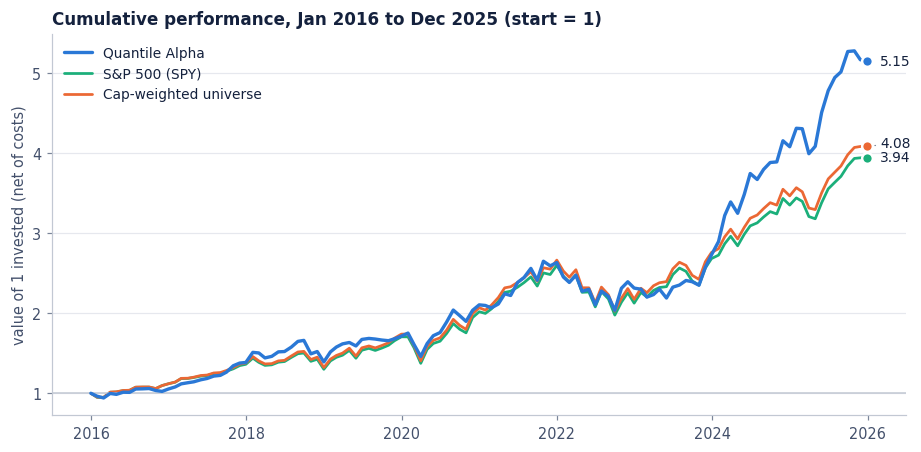

,Quantile Alpha,S&P 500 (SPY),Cap-weighted universe
2015-12,1.000,1.000,1.000
2016-12,1.054,1.119,1.119
2017-12,1.385,1.362,1.378
2018-12,1.391,1.299,1.322
2019-12,1.714,1.705,1.738
2020-12,2.104,2.018,2.068
2021-12,2.632,2.598,2.662
2022-12,2.313,2.125,2.173
2023-12,2.729,2.682,2.758
2024-12,4.078,3.349,3.465


In [19]:
R, NAV, M = BT["returns"], BT["nav"], BT["metrics"]
dates = PANEL["sessions"].reindex(NAV.index).values

fig, ax = plt.subplots(figsize=(8.5, 4.2))
keys = [STRAT, "SPY", "Universe"]
for key in keys:
    ax.plot(dates, NAV[key], color=COLOR[key], label=LABEL[key], lw=2.2 if key == STRAT else 1.8, zorder=3 if key == STRAT else 2)
end_labels(ax, dates[-1], {k: NAV[k].iloc[-1] for k in keys}, COLOR, {k: f"{NAV[k].iloc[-1]:.2f}" for k in keys},
           min_gap=0.035 * NAV.iloc[-1][keys].max())
ax.axhline(1.0, color=AXIS, lw=1)
ax.set_ylabel("value of 1 invested (net of costs)"); ax.legend(loc="upper left")
ax.set_title(f"Cumulative performance, {R.index[0].strftime('%b %Y')} to {R.index[-1].strftime('%b %Y')} (start = 1)")
plt.tight_layout(); savefig(fig, "fig_cumulative_performance")

# the same information as a table
display(savetable(NAV.loc[[m for m in NAV.index if m.month == 12 or m == NAV.index[0]], keys]
                  .rename(columns=LABEL), "tab_cumulative_value_by_year").style.format("{:.3f}"))

### 6.2 Performance measures

In [20]:
main_rows = {f"{LABEL[STRAT]}, net": M.loc[STRAT], f"{LABEL[STRAT]}, gross (zero cost)": BT["metrics_gross"].loc[STRAT],
             LABEL["SPY"] + " — benchmark": M.loc["SPY"], LABEL["Universe"]: M.loc["Universe"]}
MAIN = pd.DataFrame(main_rows).T
required = {"ann_return": "Average return p.a.", "ann_vol": "Volatility p.a.", "sharpe": "Sharpe ratio", "alpha": "Alpha p.a.",
            "beta": "Beta", "info_ratio": "Information ratio"}
extra = {"cagr": "CAGR", "max_drawdown": "Maximum drawdown", "tracking_error": "Tracking error p.a.", "sortino": "Sortino ratio",
         "profit_factor": "Profit factor", "alpha_t": "t-stat of alpha", "share_months_ahead": "Months ahead of SPY"}
fmt_pct = {v: "{:.2%}" for k, v in {**required, **extra}.items() if k in ("ann_return", "ann_vol", "alpha", "cagr", "max_drawdown", "tracking_error", "share_months_ahead")}
fmt_num = {v: "{:.2f}" for k, v in {**required, **extra}.items() if k in ("sharpe", "beta", "info_ratio", "sortino", "alpha_t", "profit_factor")}
T_MAIN = MAIN[list(required)].rename(columns=required).astype(float)
T_EXTRA = MAIN[list(extra)].rename(columns=extra).astype(float)
savetable(MAIN, "tab_performance_main")
print(f"Required performance measures, {R.index[0]} to {R.index[-1]} ({len(R)} monthly returns)")
display(T_MAIN.style.format({**fmt_pct, **fmt_num}, na_rep="n/a"))
print("Additional measures")
display(T_EXTRA.style.format({**fmt_pct, **fmt_num}, na_rep="n/a"))
print("n/a: an information ratio or alpha t-statistic of the benchmark against itself is undefined, not zero.")
print("Sortino ratio: like the Sharpe ratio, but only returns below the risk-free rate count as risk. "
      "Profit factor: sum of the gains in up months divided by the sum of the losses in down months.")

MM = market_model(R[STRAT], R["SPY"], BT["rf"])
reg = pd.Series({"alpha per month": MM["alpha_monthly"], "alpha p.a. (x12)": MM["alpha"], "standard error of alpha p.a.": MM["alpha_se"],
                 "t-statistic of alpha": MM["alpha_t"], "p-value of alpha": MM["alpha_p"],
                 "95% CI alpha p.a., low": MM["alpha_ci_low"], "95% CI alpha p.a., high": MM["alpha_ci_high"],
                 "beta (not annualised)": MM["beta"], "standard error of beta": MM["beta_se"],
                 "95% CI beta, low": MM["beta_ci_low"], "95% CI beta, high": MM["beta_ci_high"],
                 "R squared": MM["r_squared"], "observations": MM["n"], "Newey-West lags": MM["hac_lags"]}, name="Strategy net vs SPY")
print("\nRegression of the strategy's excess return on SPY's excess return (HAC standard errors)")
display(savetable(reg.to_frame(), "tab_regression_vs_spy").style.format("{:.4f}"))

Required performance measures, 2016-01 to 2025-12 (120 monthly returns)


,Average return p.a.,Volatility p.a.,Sharpe ratio,Alpha p.a.,Beta,Information ratio
"Quantile Alpha, net",17.80%,16.31%,0.96,3.46%,0.95,0.38
"Quantile Alpha, gross (zero cost)",18.02%,16.31%,0.97,3.67%,0.95,0.40
S&P 500 (SPY) — benchmark,14.93%,15.09%,0.84,0.00%,1.00,n/a
Cap-weighted universe,15.29%,15.13%,0.87,0.33%,1.00,0.68


Additional measures


,CAGR,Maximum drawdown,Tracking error p.a.,Sortino ratio,Profit factor,t-stat of alpha,Months ahead of SPY
"Quantile Alpha, net",17.80%,-23.13%,7.62%,1.65,2.24,1.35,60.00%
"Quantile Alpha, gross (zero cost)",18.05%,-23.03%,7.62%,1.68,2.26,1.43,60.00%
S&P 500 (SPY) — benchmark,14.70%,-23.93%,0.00%,1.31,2.06,n/a,n/a
Cap-weighted universe,15.10%,-23.94%,0.52%,1.36,2.09,2.37,60.00%


n/a: an information ratio or alpha t-statistic of the benchmark against itself is undefined, not zero.
Sortino ratio: like the Sharpe ratio, but only returns below the risk-free rate count as risk. Profit factor: sum of the gains in up months divided by the sum of the losses in down months.

Regression of the strategy's excess return on SPY's excess return (HAC standard errors)


,Strategy net vs SPY
alpha per month,0.0029
alpha p.a. (x12),0.0346
standard error of alpha p.a.,0.0256
t-statistic of alpha,1.3515
p-value of alpha,0.1791
"95% CI alpha p.a., low",-0.0161
"95% CI alpha p.a., high",0.0853
beta (not annualised),0.9538
standard error of beta,0.0493
"95% CI beta, low",0.8561


In [21]:
s, b, e = M.loc[STRAT], M.loc["SPY"], M.loc["Universe"]
g = BT["metrics_gross"].loc[STRAT]
n_years = len(R) / 12
say(f"""
#### What each number means for the client

**Average return ({pct(s.ann_return)} per year, SPY {pct(b.ann_return)}).** Twelve times the average monthly net return: what the strategy earned in a typical year of the sample. The strategy earned {abs(s.ann_return - b.ann_return) * 100:.1f} percentage points per year {pick(s.ann_return >= b.ann_return, 'more', 'less')} than simply holding the S&P 500 fund, and {abs(s.ann_return - e.ann_return) * 100:.1f} points {pick(s.ann_return >= e.ann_return, 'more', 'less')} than the cap-weighted universe it selects from. Compounded (CAGR), one dollar grew to {NAV[STRAT].iloc[-1]:.2f} in the strategy and to {NAV['SPY'].iloc[-1]:.2f} in SPY over {n_years:.0f} years. The CAGR ({pct(s.cagr, 2)}) is the constant yearly rate that reproduces this growth. It is {pick(s.cagr < s.ann_return - 0.0005, 'below the arithmetic average because volatility drags on compound growth', 'almost equal to the arithmetic average here; usually it is lower, because volatility drags on compound growth')}. A client planning for a wealth target should look at the CAGR.

**Volatility ({pct(s.ann_vol)}, SPY {pct(b.ann_vol)}).** The annualised standard deviation of monthly returns. In roughly two years out of three the annual return can be expected within about ±{s.ann_vol * 100:.0f} percentage points of its average. The strategy was {pick(s.ann_vol > b.ann_vol, 'more', 'less')} volatile than the benchmark: holding about {BT['trading'].loc[STRAT, 'avg_holdings']:.0f} stocks instead of 500, a few of them with weights close to 9%, leaves more stock-specific risk.

**Sharpe ratio ({num(s.sharpe)}, SPY {num(b.sharpe)}).** Return above the Treasury-bill proxy per unit of volatility. The client was paid {pick(s.sharpe >= b.sharpe, 'more', 'less')} for each unit of risk than in the index fund. The comparison uses excess returns and √12 scaling, the two points Lecture 4 flags as common mistakes.

**Beta ({num(s.beta)}, not annualised).** The sensitivity to SPY: when SPY's excess return is +10%, the strategy's is expected to be about {s.beta * 10:+.1f}%. A beta {pick(abs(s.beta - 1) < 0.1, 'close to one', pick(s.beta > 1, 'above one', 'below one'))} means the strategy is {pick(abs(s.beta - 1) < 0.1, 'essentially a full equity investment: it offers no protection in a falling market', 'not a one-for-one equity exposure')}. Its 95% confidence interval is {num(MM['beta_ci_low'])} to {num(MM['beta_ci_high'])}.

**Alpha ({pct(s.alpha)} per year, t = {num(MM['alpha_t'])}).** The part of the excess return that market exposure does not explain, annualised by ×12. The estimate is {pick(s.alpha >= 0, 'positive', 'negative')} and {pick(abs(MM['alpha_t']) >= 1.96, 'statistically significant at the 5% level', 'not statistically distinguishable from zero')} (95% interval {pct(MM['alpha_ci_low'])} to {pct(MM['alpha_ci_high'])}). {pick(s.alpha < 0, 'There is no evidence in this sample that the momentum rules added value beyond their market exposure; if anything they subtracted some.', pick(abs(MM['alpha_t']) >= 1.96, 'In this sample the momentum rules added return beyond their market exposure.', 'A positive alpha that is not statistically significant must not be read as proven skill: an estimate of this size can also arise by chance in ten years of data.'))} Two further cautions: about {pp(bias, 1)} of it is the survivorship advantage of the data measured in section 5.2, and alpha against SPY is benchmark-relative, not a risk-adjusted return in a wider sense.

**Information ratio ({num(s.info_ratio)}).** Average return relative to SPY ({pp(s.active_return)} per year) divided by the volatility of that difference (tracking error {pct(s.tracking_error)}). It says how reliably the strategy beat its benchmark. {pick(s.info_ratio < 0, 'A negative value means the deviations from the index were, on average, not rewarded.', 'A positive value means the deviations from the index were rewarded on average.')} The strategy was ahead of SPY in {pct(s.share_months_ahead, 0)} of the months. A tracking error of this size means that differences of ±{s.tracking_error * 100:.0f} percentage points against the index in a single year are normal, in either direction.

**Maximum drawdown ({pct(s.max_drawdown)}, SPY {pct(b.max_drawdown)}).** The largest loss from a previous peak, measured at month-ends. This is the loss a client has to be able to sit through without selling. Month-end data understate the worst intra-month loss.

**Gross versus net.** Without transaction costs the strategy would have returned {pct(g.ann_return)} per year; costs took {(g.ann_return - s.ann_return) * 100:.2f} percentage points per year. {pick(s.ann_return < b.ann_return, 'Costs explain only a small part of the gap to SPY.', 'The margin over SPY is larger than the cost of trading.')}
""")


#### What each number means for the client

**Average return (17.8% per year, SPY 14.9%).** Twelve times the average monthly net return: what the strategy earned in a typical year of the sample. The strategy earned 2.9 percentage points per year more than simply holding the S&P 500 fund, and 2.5 points more than the cap-weighted universe it selects from. Compounded (CAGR), one dollar grew to 5.15 in the strategy and to 3.94 in SPY over 10 years. The CAGR (17.80%) is the constant yearly rate that reproduces this growth. It is almost equal to the arithmetic average here; usually it is lower, because volatility drags on compound growth. A client planning for a wealth target should look at the CAGR.

**Volatility (16.3%, SPY 15.1%).** The annualised standard deviation of monthly returns. In roughly two years out of three the annual return can be expected within about ±16 percentage points of its average. The strategy was more volatile than the benchmark: holding about 90 stocks instead of 500, a few of them with weights close to 9%, leaves more stock-specific risk.

**Sharpe ratio (0.96, SPY 0.84).** Return above the Treasury-bill proxy per unit of volatility. The client was paid more for each unit of risk than in the index fund. The comparison uses excess returns and √12 scaling, the two points Lecture 4 flags as common mistakes.

**Beta (0.95, not annualised).** The sensitivity to SPY: when SPY's excess return is +10%, the strategy's is expected to be about +9.5%. A beta close to one means the strategy is essentially a full equity investment: it offers no protection in a falling market. Its 95% confidence interval is 0.86 to 1.05.

**Alpha (3.5% per year, t = 1.35).** The part of the excess return that market exposure does not explain, annualised by ×12. The estimate is positive and not statistically distinguishable from zero (95% interval -1.6% to 8.5%). A positive alpha that is not statistically significant must not be read as proven skill: an estimate of this size can also arise by chance in ten years of data. Two further cautions: about +0.3 pp of it is the survivorship advantage of the data measured in section 5.2, and alpha against SPY is benchmark-relative, not a risk-adjusted return in a wider sense.

**Information ratio (0.38).** Average return relative to SPY (+2.9 pp per year) divided by the volatility of that difference (tracking error 7.6%). It says how reliably the strategy beat its benchmark. A positive value means the deviations from the index were rewarded on average. The strategy was ahead of SPY in 60% of the months. A tracking error of this size means that differences of ±8 percentage points against the index in a single year are normal, in either direction.

**Maximum drawdown (-23.1%, SPY -23.9%).** The largest loss from a previous peak, measured at month-ends. This is the loss a client has to be able to sit through without selling. Month-end data understate the worst intra-month loss.

**Gross versus net.** Without transaction costs the strategy would have returned 18.0% per year; costs took 0.22 percentage points per year. The margin over SPY is larger than the cost of trading.


### 6.3 Drawdowns

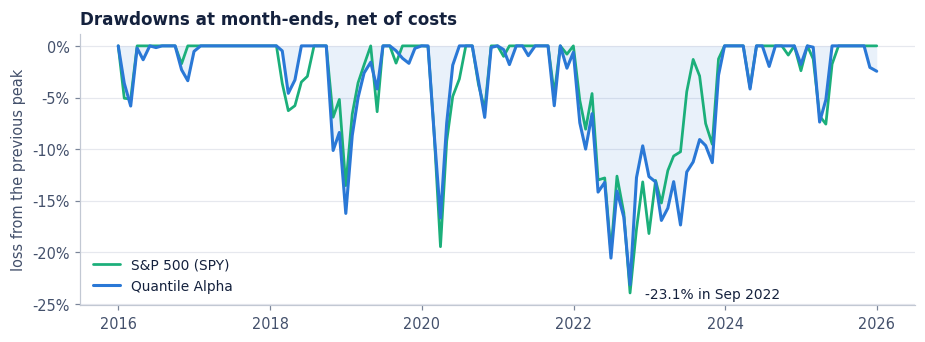

Three deepest drawdowns, Quantile Alpha:


,trough,recovered,depth,months to trough,months to recover,months under water
peak,,,,,,
2021-10,2022-09,2023-12,-23.1%,11,15,26
2020-01,2020-03,2020-06,-16.7%,2,3,5
2018-09,2018-12,2019-06,-16.2%,3,6,9


Three deepest drawdowns, S&P 500 (SPY):


,trough,recovered,depth,months to trough,months to recover,months under water
peak,,,,,,
2021-12,2022-09,2023-12,-23.9%,9,15,24
2019-12,2020-03,2020-07,-19.4%,3,4,7
2018-09,2018-12,2019-04,-13.5%,3,4,7


months to trough: from the peak to the low; months to recover: from the low back to the old peak; months under water: the whole time below the old peak.


In [22]:
DD = BT["drawdowns"]
fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.fill_between(dates, DD[STRAT], 0, color=BLUE, alpha=0.10, lw=0)
ax.plot(dates, DD["SPY"], color=TEAL, lw=1.8, label=LABEL["SPY"])
ax.plot(dates, DD[STRAT], color=BLUE, lw=2.0, label=LABEL[STRAT])
worst = DD[STRAT].idxmin()
ax.annotate(f"{pct(DD[STRAT].min())} in {worst.strftime('%b %Y')}", (PANEL["sessions"][worst], DD[STRAT].min()),
            xytext=(10, -2), textcoords="offset points", fontsize=9, color=INK, va="top")
percent_axis(ax); ax.set_ylabel("loss from the previous peak"); ax.legend(loc="lower left")
ax.set_title("Drawdowns at month-ends, net of costs")
plt.tight_layout(); savefig(fig, "fig_drawdowns")

def drawdown_episodes(nav, top=3):
    dd = drawdown_series(nav); rows = []; in_dd = False
    for m, v in dd.items():
        if v < 0 and not in_dd:
            in_dd, peak = True, prev
        if in_dd and v == 0:
            seg = dd.loc[peak:m]; rows.append((peak, seg.idxmin(), m, seg.min())); in_dd = False
        prev = m
    if in_dd:
        seg = dd.loc[peak:]; rows.append((peak, seg.idxmin(), None, seg.min()))
    t = pd.DataFrame(rows, columns=["peak", "trough", "recovered", "depth"]).sort_values("depth").head(top)
    done = [rc is not None and not pd.isna(rc) for rc in t["recovered"]]
    t["months to trough"] = [(tr - pk).n for pk, tr in zip(t["peak"], t["trough"])]
    t["months to recover"] = [(rc - tr).n if ok else np.nan for tr, rc, ok in zip(t["trough"], t["recovered"], done)]
    # time below the previous peak; for an episode that has not recovered, counted to the end of the sample
    t["months under water"] = [((rc if ok else dd.index[-1]) - pk).n for pk, rc, ok in zip(t["peak"], t["recovered"], done)]
    return t

for key in (STRAT, "SPY"):
    print(f"Three deepest drawdowns, {LABEL[key]}:")
    ep = drawdown_episodes(NAV[key])
    ep["recovered"] = [str(x) if x is not None and not pd.isna(x) else "not yet" for x in ep["recovered"]]
    display(ep.astype({"peak": str, "trough": str}).set_index("peak").style.format({"depth": "{:.1%}", "months to recover": "{:.0f}"}, na_rep="-"))
print("months to trough: from the peak to the low; months to recover: from the low back to the old peak; "
      "months under water: the whole time below the old peak.")

### 6.4 Calendar years, trading activity and concentration

,Quantile Alpha,S&P 500 (SPY),Cap-weighted universe,Strategy minus SPY
2016,+5.4%,+11.9%,+11.9%,-6.5%
2017,+31.4%,+21.7%,+23.1%,+9.7%
2018,+0.4%,-4.6%,-4.1%,+5.0%
2019,+23.2%,+31.2%,+31.6%,-8.0%
2020,+22.8%,+18.3%,+18.9%,+4.4%
2021,+25.1%,+28.7%,+28.8%,-3.6%
2022,-12.1%,-18.2%,-18.4%,+6.1%
2023,+18.0%,+26.2%,+26.9%,-8.2%
2024,+49.4%,+24.9%,+25.6%,+24.5%
2025,+26.2%,+17.7%,+17.8%,+8.4%


The strategy beat SPY in 6 of 10 calendar years.


,Average number of holdings,Effective holdings 1/Σw²,Largest single weight reached,One-way turnover p.a.,Traded notional p.a.,Transaction cost p.a.,Initial purchase cost,Largest cash weight
Quantile Alpha,90,25.8,13.54%,102%,205%,0.205%,0.100%,0.00%
Cap-weighted universe,447,77.3,8.08%,3%,6%,0.006%,0.100%,0.00%
S&P 500 (SPY),1,1.0,100.00%,0%,0%,0.000%,0.100%,0.00%


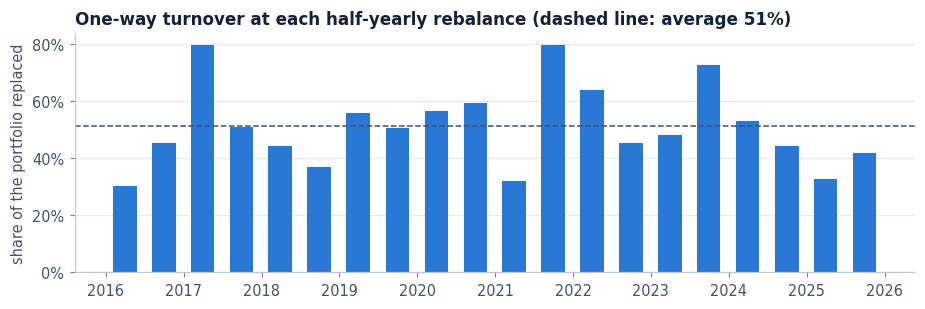


**Reading the trading table.** The portfolio holds about **90 stocks**, but far from equally: on rebalance dates the ten largest positions make up 53% of it on average, and the *effective* number of holdings (1/Σw², which equals N for equal weights and falls as weights become unequal) averaged only 26. The 9% limit applies when the weights are set on the reference date. By the trade date, one month later, the largest weight was already above 9% at 12 of the 21 rebalances (at most 10.0%), and because weights drift further in between, the largest position reached 13.5%. **This is a concentrated portfolio**: a small number of very large companies drive much of its result (section 9). Cash is never held: the portfolio is fully invested at all times and no held stock was delisted in the sample.

At each rebalance about 51% of the portfolio is replaced, which adds up to a one-way turnover of **102% per year** (traded notional, purchases plus sales, 205% of portfolio value). At 10 bp per dollar traded this costs **0.20% of portfolio value per year**, plus 0.10% once for the initial purchase. The cap-weighted universe needs only 3% turnover per year, because a portfolio weighted by market value stays in line with prices by itself. Nearly all of the strategy's trading therefore comes from the ranking changing: on average 44 of 90 stocks stay from one rebalance to the next.


In [23]:
yearly = ((1 + R[[STRAT, "SPY", "Universe"]]).groupby(R.index.year).prod() - 1).rename(columns=LABEL)
yearly["Strategy minus SPY"] = yearly[LABEL[STRAT]] - yearly[LABEL["SPY"]]
display(savetable(yearly, "tab_calendar_year_returns").style.format("{:+.1%}"))
ahead = int((yearly["Strategy minus SPY"] > 0).sum())
print(f"The strategy beat SPY in {ahead} of {len(yearly)} calendar years.")

TR = BT["trading"].loc[[STRAT, "Universe", "SPY"]].rename(index=LABEL)
trade_cols = {"avg_holdings": "Average number of holdings", "avg_effective_holdings": "Effective holdings 1/Σw²", "max_weight": "Largest single weight reached",
              "one_way_turnover_pa": "One-way turnover p.a.", "traded_notional_pa": "Traded notional p.a.", "cost_pa": "Transaction cost p.a.",
              "initial_cost": "Initial purchase cost", "max_cash_weight": "Largest cash weight"}
display(savetable(TR[list(trade_cols)].rename(columns=trade_cols), "tab_trading_and_concentration").style.format(
    {"Average number of holdings": "{:.0f}", "Effective holdings 1/Σw²": "{:.1f}", "Largest single weight reached": "{:.2%}",
     "One-way turnover p.a.": "{:.0%}", "Traded notional p.a.": "{:.0%}", "Transaction cost p.a.": "{:.3%}",
     "Initial purchase cost": "{:.3%}", "Largest cash weight": "{:.2%}"}))

reb = BT["runs"][STRAT]["rebalances"]
fig, ax = plt.subplots(figsize=(8.5, 2.9))
x = PANEL["sessions"].reindex(reb.index[1:]).values
ax.bar(x, reb["one_way_turnover"].iloc[1:], width=days(110), color=BLUE)
ax.axhline(reb["one_way_turnover"].iloc[1:].mean(), color=INK2, lw=1, ls="--")
percent_axis(ax); ax.set_ylabel("share of the portfolio replaced")
ax.set_title(f"One-way turnover at each half-yearly rebalance (dashed line: average {pct(reb['one_way_turnover'].iloc[1:].mean(), 0)})")
plt.tight_layout(); savefig(fig, "fig_turnover")

t = BT["trading"].loc[STRAT]
say(f"""
**Reading the trading table.** The portfolio holds about **{t.avg_holdings:.0f} stocks**, but far from equally: on rebalance dates the ten largest positions make up {pct(SEL['ten largest weights'].mean(), 0)} of it on average, and the *effective* number of holdings (1/Σw², which equals N for equal weights and falls as weights become unequal) averaged only {t.avg_effective_holdings:.0f}. The 9% limit applies when the weights are set on the reference date. By the trade date, one month later, the largest weight was already above 9% at {int((SEL['largest weight'] > CFG.max_weight + 1e-9).sum())} of the {len(SEL)} rebalances (at most {pct(SEL['largest weight'].max())}), and because weights drift further in between, the largest position reached {pct(t.max_weight)}. **This is a concentrated portfolio**: a small number of very large companies drive much of its result (section 9). Cash is {pick(t.max_cash_weight < 1e-9, 'never held: the portfolio is fully invested at all times and no held stock was delisted in the sample', f'held only temporarily after delistings (at most {pct(t.max_cash_weight)})')}.

At each rebalance about {pct(reb['one_way_turnover'].iloc[1:].mean(), 0)} of the portfolio is replaced, which adds up to a one-way turnover of **{pct(t.one_way_turnover_pa, 0)} per year** (traded notional, purchases plus sales, {pct(t.traded_notional_pa, 0)} of portfolio value). At 10 bp per dollar traded this costs **{pct(t.cost_pa, 2)} of portfolio value per year**, plus {pct(t.initial_cost, 2)} once for the initial purchase. The cap-weighted universe needs only {pct(BT['trading'].loc['Universe', 'one_way_turnover_pa'], 0)} turnover per year, because a portfolio weighted by market value stays in line with prices by itself. Nearly all of the strategy's trading therefore comes from the ranking changing: on average {SEL['already held'].iloc[1:].mean():.0f} of {SEL['selected'].iloc[1:].mean():.0f} stocks stay from one rebalance to the next.
""")

## 7. Does the momentum score predict returns in this universe? Quintiles, spread, regressions

The portfolio result of section 6 mixes three things: the momentum score, the weighting by market value, and plain market exposure. This section isolates the score. If it works in this universe, average returns should rise from Q1 to Q5, the Q5-minus-Q1 spread should be positive, and stocks with higher scores should, on average, have higher subsequent returns. None of this is assumed; it is tested. The quintile portfolios are weighted like the strategy (market value × score, with the limits) but use no buffer, so Q5 is close to the strategy without being identical to it.

Three caveats apply throughout. The quintiles are evidence about *association*, not about causes. The Q5-minus-Q1 spread is a research diagnostic, not an investable long-short portfolio (the strategy never sells short). And all tests inherit the survivorship limitation of section 5.2.

In [24]:
# [engine] exported to the repo by tools/export_engine.py - see the README
def mean_test(x, scale=12.0):
    """Mean of a monthly series with a simple and a HAC (Newey-West) t-statistic; mean and interval scaled by `scale`."""
    x = pd.Series(x).dropna()
    n = len(x)
    lags = hac_lags(n)
    fit = sm.OLS(x.to_numpy(dtype=float), np.ones((n, 1))).fit(cov_type="HAC", cov_kwds={"maxlags": lags, "use_correction": True},
                                                               use_t=True)
    ci = np.asarray(fit.conf_int(0.05))[0]
    sd = x.std(ddof=1)
    return {"mean": scale * x.mean(), "vol": math.sqrt(scale) * sd, "t_simple": x.mean() / (sd / math.sqrt(n)) if sd > 0 else np.nan,
            "t_hac": fit.tvalues[0], "p_hac": fit.pvalues[0], "ci_low": scale * ci[0], "ci_high": scale * ci[1],
            "share_positive": float((x > 0).mean()), "n": n, "hac_lags": lags}


def forward_returns(ret, month, horizon, names):
    """Compounded total return of each name over the `horizon` months after formation `month`.

    A name whose quotes end inside the window keeps its last value for the rest of the window (delisting proceeds
    held without interest), the same convention as in the portfolio accounting.
    """
    window = ret.loc[month + 1: month + horizon, list(names)]
    return (1.0 + window).prod(skipna=True) - 1.0


def cross_sectional_tests(forms, ret, months, horizon=1, score="ram"):
    """For each formation month: slope of the forward return on the standardised score (default: the risk-adjusted
    momentum value), and the Spearman rank correlation between score and forward return. One row per month, to be
    averaged over time (Fama-MacBeth)."""
    rows = []
    for m in months:
        f = forms[m]
        fwd = forward_returns(ret, m, horizon, f.index)
        z = (f[score] - f[score].mean()) / f[score].std(ddof=1)
        ok = z.notna() & fwd.notna()
        fit = sm.OLS(fwd[ok].to_numpy(dtype=float), sm.add_constant(z[ok].to_numpy(dtype=float))).fit()
        rows.append({"formation": m, "stocks": int(ok.sum()), "intercept": fit.params[0], "slope": fit.params[1],
                     "rank_ic": f.loc[ok, score].corr(fwd[ok], method="spearman")})
    return pd.DataFrame(rows).set_index("formation")

Score quintiles, net of costs, 2016-01 to 2025-12 (Q1 = lowest momentum score, Q5 = highest)


,Average return p.a.,Volatility p.a.,Sharpe ratio,Alpha p.a.,Beta,Information ratio,CAGR,Maximum drawdown,One-way turnover p.a.,Cost p.a.,Holdings
Q1,14.45%,19.31%,0.63,-1.32%,1.07,-0.04,13.39%,-29.6%,127%,0.25%,88
Q2,13.27%,16.76%,0.66,-1.91%,1.02,-0.25,12.55%,-26.2%,155%,0.31%,89
Q3,12.10%,15.67%,0.63,-2.63%,0.98,-0.56,11.43%,-25.2%,155%,0.31%,90
Q4,12.79%,14.87%,0.71,-1.30%,0.93,-0.44,12.34%,-22.1%,155%,0.31%,90
Q5,17.74%,15.84%,0.98,+3.73%,0.93,0.38,17.81%,-23.2%,113%,0.23%,90


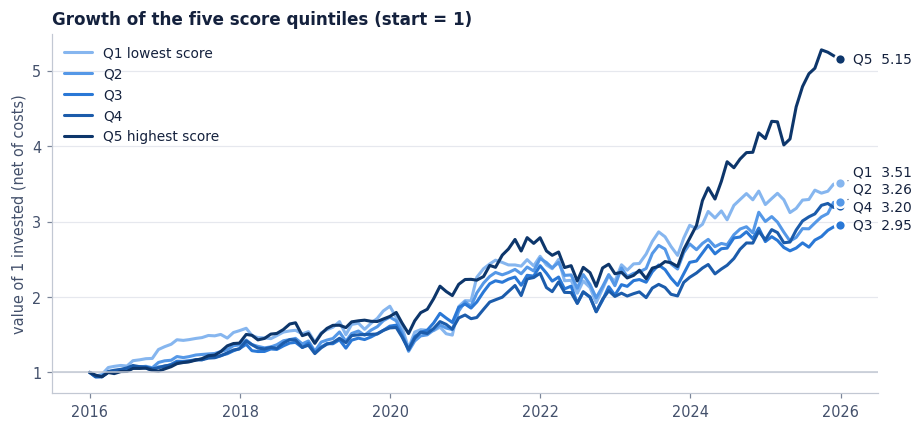

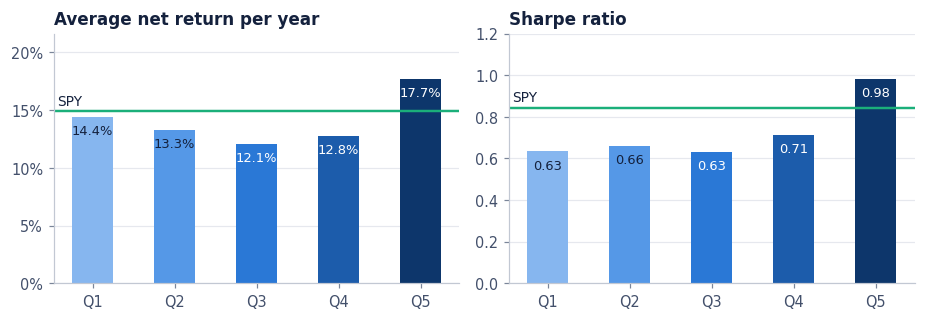

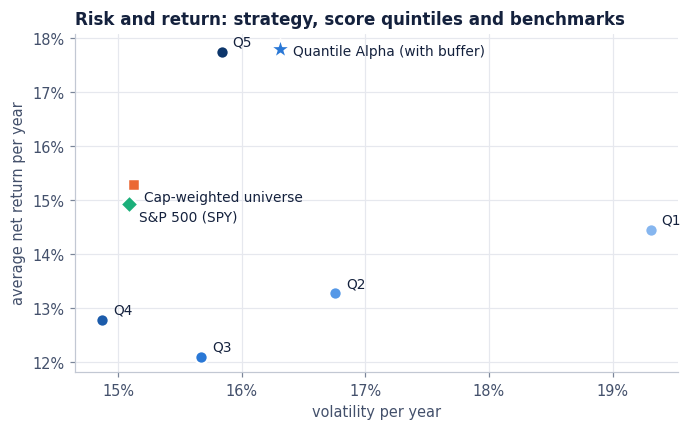

In [25]:
QUINT = QS                                       # Q1 ... Q5
qcols = {"ann_return": "Average return p.a.", "ann_vol": "Volatility p.a.", "sharpe": "Sharpe ratio", "alpha": "Alpha p.a.",
         "beta": "Beta", "info_ratio": "Information ratio", "cagr": "CAGR", "max_drawdown": "Maximum drawdown"}
TQ = M.loc[QUINT, list(qcols)].rename(columns=qcols).astype(float)
TQ["One-way turnover p.a."] = BT["trading"].loc[QUINT, "one_way_turnover_pa"].astype(float)
TQ["Cost p.a."] = BT["trading"].loc[QUINT, "cost_pa"].astype(float)
TQ["Holdings"] = BT["trading"].loc[QUINT, "avg_holdings"].astype(float)
qfmt = {"Average return p.a.": "{:.2%}", "Volatility p.a.": "{:.2%}", "Sharpe ratio": "{:.2f}", "Alpha p.a.": "{:+.2%}", "Beta": "{:.2f}",
        "Information ratio": "{:.2f}", "CAGR": "{:.2%}", "Maximum drawdown": "{:.1%}", "One-way turnover p.a.": "{:.0%}", "Cost p.a.": "{:.2%}", "Holdings": "{:.0f}"}
print(f"Score quintiles, net of costs, {R.index[0]} to {R.index[-1]} (Q1 = lowest momentum score, Q5 = highest)")
display(savetable(TQ, "tab_quintiles").style.format(qfmt))

fig, ax = plt.subplots(figsize=(8.5, 4.0))
for q, c in zip(QUINT, RAMP5):
    ax.plot(dates, NAV[q], color=c, lw=2.0, label=q + pick(q == "Q1", " lowest score", pick(q == "Q5", " highest score", "")))
end_labels(ax, dates[-1], {q: NAV[q].iloc[-1] for q in QUINT}, dict(zip(QUINT, RAMP5)), {q: f"{q}  {NAV[q].iloc[-1]:.2f}" for q in QUINT},
           min_gap=0.045 * NAV.iloc[-1][QUINT].max())
ax.axhline(1.0, color=AXIS, lw=1); ax.set_ylabel("value of 1 invested (net of costs)"); ax.legend(loc="upper left")
ax.set_title("Growth of the five score quintiles (start = 1)")
plt.tight_layout(); savefig(fig, "fig_quintile_wealth")

fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.0))
for ax, col, title, as_pct in ((axes[0], "Average return p.a.", "Average net return per year", True), (axes[1], "Sharpe ratio", "Sharpe ratio", False)):
    ax.bar(QUINT, TQ[col], width=0.5, color=RAMP5)
    bar_labels(ax, QUINT, TQ[col], [pct(v) if as_pct else num(v) for v in TQ[col]], RAMP5)
    ax.axhline(M.loc["SPY", "ann_return" if as_pct else "sharpe"], color=TEAL, lw=1.6)
    ax.annotate("SPY", (-0.44, M.loc["SPY", "ann_return" if as_pct else "sharpe"]), xytext=(0, 4), textcoords="offset points", ha="left", fontsize=9, color=INK)
    ax.set_title(title); ax.set_ylim(0, max(TQ[col].max(), M.loc["SPY", "ann_return" if as_pct else "sharpe"]) * 1.22)
    if as_pct: percent_axis(ax)
plt.tight_layout(); savefig(fig, "fig_quintile_return_sharpe")

fig, ax = plt.subplots(figsize=(6.4, 4.0))
for q, c in zip(QUINT, RAMP5):
    ax.scatter(M.loc[q, "ann_vol"], M.loc[q, "ann_return"], s=70, color=c, edgecolor="white", linewidth=1.6, zorder=3)
    ax.annotate(q, (M.loc[q, "ann_vol"], M.loc[q, "ann_return"]), xytext=(7, 4), textcoords="offset points", fontsize=9, color=INK)
ax.scatter(M.loc[STRAT, "ann_vol"], M.loc[STRAT, "ann_return"], s=190, color=BLUE, marker="*", edgecolor="white", linewidth=1.2, zorder=4)
ax.annotate(LABEL[STRAT] + " (with buffer)", (M.loc[STRAT, "ann_vol"], M.loc[STRAT, "ann_return"]), xytext=(9, -4), textcoords="offset points", fontsize=9, color=INK)
for key, marker in (("SPY", "D"), ("Universe", "s")):
    ax.scatter(M.loc[key, "ann_vol"], M.loc[key, "ann_return"], s=70, color=COLOR[key], marker=marker, edgecolor="white", linewidth=1.6, zorder=3, label=LABEL[key])
    ax.annotate(LABEL[key], (M.loc[key, "ann_vol"], M.loc[key, "ann_return"]), xytext=(7, -11), textcoords="offset points", fontsize=9, color=INK)
percent_axis(ax, "x"); percent_axis(ax, "y"); ax.grid(True, axis="x")
ax.set_xlabel("volatility per year"); ax.set_ylabel("average net return per year"); ax.set_title("Risk and return: strategy, score quintiles and benchmarks")
plt.tight_layout(); savefig(fig, "fig_risk_return")

,"Q5 minus Q1, p.a.",Volatility p.a.,t-statistic (HAC),p-value,95% CI low,95% CI high,Months positive,Months
Net of costs,+3.29%,16.68%,0.57,0.566,-8.05%,+14.63%,54%,120
Before costs,+3.27%,16.68%,0.57,0.570,-8.08%,+14.61%,54%,120


,Average over months,t-statistic (Fama-MacBeth),t-statistic (HAC),95% CI low,95% CI high,Months positive,Months
Slope: next month's return per 1 SD of risk-adjusted momentum,-0.0001,-0.04,-0.04,-0.0026,+0.0025,50%,120
Spearman rank correlation,-0.0004,-0.02,-0.03,-0.0330,+0.0321,49%,120


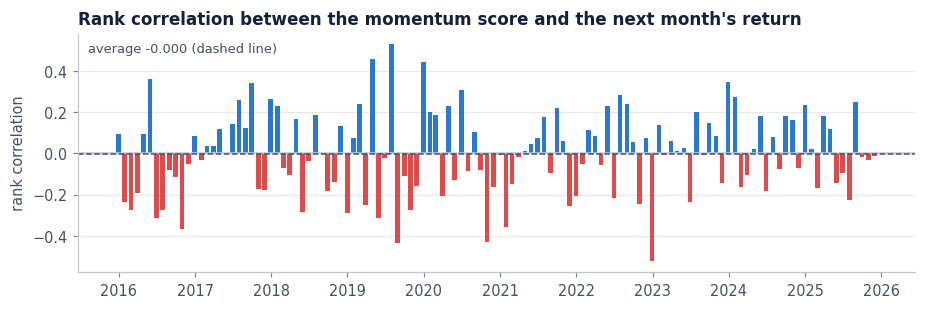

Five worst months for winners relative to losers (Q5 minus Q1, net):


,Q5 minus Q1,SPY return
2020-11,-17.9%,+10.9%
2021-02,-16.5%,+2.8%
2016-11,-11.2%,+3.7%
2023-05,-9.9%,+0.5%
2023-01,-9.2%,+6.3%



#### Findings

**There is no monotonic quintile pattern.** Average net returns from Q1 to Q5 are 14.4%, 13.3%, 12.1%, 12.8%, 17.7% (rank correlation between quintile number and average return +0.10). The highest-score quintile earned 3.3 percentage points per year more than the lowest. Risk differs as well: Q1 has a beta of 1.07 and a volatility of 19.3%, Q5 a beta of 0.93 and 15.8%. The low-score stocks are the higher-beta, more volatile ones. On a risk-adjusted basis the Sharpe ratio is 0.63 for Q1 against 0.98 for Q5.

**The Q5-minus-Q1 spread is positive and statistically indistinguishable from zero.** Net of costs it averages +3.29 pp per year (t = 0.57, 95% interval -8.0 pp to +14.6 pp); before costs +3.27 pp. With a spread volatility of 16.7% per year and only 120 months, a true premium of a few percent per year could not be detected reliably: the sample is too short either to prove or to rule out a momentum effect.

**Stock-level tests.** Across 120 monthly cross-sections, a stock whose risk-adjusted momentum was one standard deviation above the average earned on average -0.01 pp in the following month (Fama-MacBeth t = -0.04), not a statistically significant relation. The average rank correlation between the score and the next month's return is -0.000 (t = -0.02), positive in 49% of the months. The bar chart shows why the average is small: the sign flips from month to month. These tests count every stock equally, whereas the strategy's result depends mostly on its largest positions; a weak stock-level relation and a strong portfolio result can therefore go together.

**When momentum fails.** The five worst months for high-score relative to low-score stocks were Nov 2020, Feb 2021, Nov 2016, May 2023, Jan 2023; in 100% of them the market itself rose. Losses of past winners against past losers during market rebounds are the "momentum crash" pattern documented by Daniel and Moskowitz (2016): beaten-down, high-beta stocks recover fastest when the market turns. The long-only strategy itself had a positive return in 1 of these five months, but it trailed SPY in all five (by 3.6 to 6.9 percentage points in a single month). Without a short side it does not lose money the way a long-short momentum portfolio does in such months, but it is left well behind the index.



**How to read this.** The result does not contradict the classic momentum literature, which documents the effect mainly for long-short portfolios, over broad universes that include small stocks, and over samples of several decades (Jegadeesh and Titman, 1993). Here the universe is restricted to large, liquid, heavily researched companies, the test is long-only and runs on surviving companies, and the sample is ten years. What the result does mean: the strategy's lead over the index in this sample is a ten-year track record, not statistical proof of a momentum premium, and it should be presented to a client as such.


In [26]:
# ---- is the pattern monotonic? Q5-minus-Q1 spread, net and gross ----
means = TQ["Average return p.a."]
monotonic = bool((means.diff().dropna() > 0).all())
rank_corr = pd.Series([1, 2, 3, 4, 5], index=QUINT).corr(means, method="spearman")
SPREAD = pd.DataFrame({"Net of costs": mean_test(R["Q5"] - R["Q1"]),
                       "Before costs": mean_test(BT["returns_gross"]["Q5"] - BT["returns_gross"]["Q1"])}).T
display(savetable(SPREAD, "tab_q5_minus_q1_spread")[["mean", "vol", "t_hac", "p_hac", "ci_low", "ci_high", "share_positive", "n"]].rename(columns={
    "mean": "Q5 minus Q1, p.a.", "vol": "Volatility p.a.", "t_hac": "t-statistic (HAC)", "p_hac": "p-value", "ci_low": "95% CI low", "ci_high": "95% CI high",
    "share_positive": "Months positive", "n": "Months"}).style.format({"Q5 minus Q1, p.a.": "{:+.2%}", "Volatility p.a.": "{:.2%}", "t-statistic (HAC)": "{:.2f}",
    "p-value": "{:.3f}", "95% CI low": "{:+.2%}", "95% CI high": "{:+.2%}", "Months positive": "{:.0%}", "Months": "{:.0f}"}))

# ---- stock-level tests: every month, the scores known for a trade at that month-end against the next month's return ----
XS = cross_sectional_tests(FORMS, PANEL["ret"], sorted(FORMS), horizon=1)
FM = pd.DataFrame({"Slope: next month's return per 1 SD of risk-adjusted momentum": mean_test(XS["slope"], scale=1.0),
                   "Spearman rank correlation": mean_test(XS["rank_ic"], scale=1.0)}).T
display(savetable(FM, "tab_cross_sectional_tests")[["mean", "t_simple", "t_hac", "ci_low", "ci_high", "share_positive", "n"]].rename(columns={
    "mean": "Average over months", "t_simple": "t-statistic (Fama-MacBeth)", "t_hac": "t-statistic (HAC)", "ci_low": "95% CI low", "ci_high": "95% CI high",
    "share_positive": "Months positive", "n": "Months"}).style.format({"Average over months": "{:+.4f}", "t-statistic (Fama-MacBeth)": "{:.2f}",
    "t-statistic (HAC)": "{:.2f}", "95% CI low": "{:+.4f}", "95% CI high": "{:+.4f}", "Months positive": "{:.0%}", "Months": "{:.0f}"}))

fig, ax = plt.subplots(figsize=(8.5, 2.9))
xq = PANEL["sessions"].reindex(XS.index).values
ax.bar(xq, XS["rank_ic"], width=days(22), color=np.where(XS["rank_ic"] >= 0, BLUE, RED))
ax.axhline(0, color=AXIS, lw=1); ax.axhline(XS["rank_ic"].mean(), color=INK2, lw=1, ls="--")
ax.annotate(f"average {XS['rank_ic'].mean():+.3f} (dashed line)", (0.012, 0.92), xycoords="axes fraction", fontsize=8.5, color=INK2)
ax.set_ylabel("rank correlation"); ax.set_title("Rank correlation between the momentum score and the next month's return")
plt.tight_layout(); savefig(fig, "fig_rank_ic")

sp_n, sp_g = SPREAD.iloc[0], SPREAD.iloc[1]
slope, ic = FM.iloc[0], FM.iloc[1]
spread_sig = abs(sp_n["t_hac"]) >= 1.96
stock_sig = abs(slope["t_simple"]) >= 1.96
wl = (R["Q5"] - R["Q1"])
worst_months = wl.nsmallest(5)
print("Five worst months for winners relative to losers (Q5 minus Q1, net):")
display(worst_months.rename("Q5 minus Q1").to_frame().assign(**{"SPY return": R["SPY"].reindex(worst_months.index)}).style.format("{:+.1%}"))
up_share = float((R["SPY"].reindex(worst_months.index) > 0).mean())
own_up = int((R[STRAT].reindex(worst_months.index) > 0).sum())
own_gap = (R[STRAT] - R["SPY"]).reindex(worst_months.index)                 # the strategy against SPY in those months
behind = own_gap[own_gap < 0]
gap_text = ("did not trail SPY in any of them." if not len(behind) else
            f"trailed SPY in {pick(len(behind) == 5, 'all five', f'{len(behind)} of the five')} (by {abs(behind.max()) * 100:.1f} to "
            f"{abs(behind.min()) * 100:.1f} percentage points in a single month). Without a short side it does not lose money the way a "
            "long-short momentum portfolio does in such months, but it is left well behind the index.")

say(f"""
#### Findings

**{pick(monotonic, 'Returns rise from Q1 to Q5.', 'There is no monotonic quintile pattern.')}** Average net returns from Q1 to Q5 are {', '.join(pct(v) for v in means)} (rank correlation between quintile number and average return {rank_corr:+.2f}). The highest-score quintile earned {abs(means['Q5'] - means['Q1']) * 100:.1f} percentage points per year {pick(means['Q5'] >= means['Q1'], 'more', 'less')} than the lowest. Risk differs as well: Q1 has a beta of {num(TQ.loc['Q1', 'Beta'])} and a volatility of {pct(TQ.loc['Q1', 'Volatility p.a.'])}, Q5 a beta of {num(TQ.loc['Q5', 'Beta'])} and {pct(TQ.loc['Q5', 'Volatility p.a.'])}. {pick(TQ.loc['Q1', 'Beta'] > TQ.loc['Q5', 'Beta'] + 0.05 and TQ.loc['Q1', 'Volatility p.a.'] > TQ.loc['Q5', 'Volatility p.a.'], 'The low-score stocks are the higher-beta, more volatile ones.', '')} On a risk-adjusted basis the Sharpe ratio is {num(TQ.loc['Q1', 'Sharpe ratio'])} for Q1 against {num(TQ.loc['Q5', 'Sharpe ratio'])} for Q5.

**The Q5-minus-Q1 spread is {pick(sp_n['mean'] >= 0, 'positive', 'negative')} and {pick(spread_sig, 'statistically significant at the 5% level', 'statistically indistinguishable from zero')}.** Net of costs it averages {pp(sp_n['mean'], 2)} per year (t = {num(sp_n['t_hac'])}, 95% interval {pp(sp_n['ci_low'])} to {pp(sp_n['ci_high'])}); before costs {pp(sp_g['mean'], 2)}. With a spread volatility of {pct(sp_n['vol'])} per year and only {int(sp_n['n'])} months, a true premium of a few percent per year could not be detected reliably: the sample is too short either to prove or to rule out a momentum effect.

**Stock-level tests.** Across {int(slope['n'])} monthly cross-sections, a stock whose risk-adjusted momentum was one standard deviation above the average earned on average {pp(slope['mean'], 2)} in the following month (Fama-MacBeth t = {num(slope['t_simple'])}), {pick(stock_sig, 'a statistically significant relation', 'not a statistically significant relation')}. The average rank correlation between the score and the next month's return is {ic['mean']:+.3f} (t = {num(ic['t_simple'])}), positive in {pct(ic['share_positive'], 0)} of the months. The bar chart shows why the average is small: the sign flips from month to month. These tests count every stock equally, whereas the strategy's result depends mostly on its largest positions; a weak stock-level relation and a strong portfolio result can therefore go together.

**When momentum fails.** The five worst months for high-score relative to low-score stocks were {', '.join(m.strftime('%b %Y') for m in worst_months.index)}; in {pct(up_share, 0)} of them the market itself rose. Losses of past winners against past losers during market rebounds are the "momentum crash" pattern documented by Daniel and Moskowitz (2016): beaten-down, high-beta stocks recover fastest when the market turns. The long-only strategy itself had a positive return in {own_up} of these five months, but it {gap_text}
""")
if not spread_sig:
    say("""
**How to read this.** The result does not contradict the classic momentum literature, which documents the effect mainly for long-short portfolios, over broad universes that include small stocks, and over samples of several decades (Jegadeesh and Titman, 1993). Here the universe is restricted to large, liquid, heavily researched companies, the test is long-only and runs on surviving companies, and the sample is ten years. What the result does mean: the strategy's lead over the index in this sample is a ten-year track record, not statistical proof of a momentum premium, and it should be presented to a client as such.
""")
else:
    say("""
**How to read this.** The spread is statistically significant in this sample. That is evidence of an association between past and subsequent returns in this universe and period, not proof that it will persist, and it remains subject to the survivorship limitation of section 5.2.
""")

## 8. Robustness

The base case is the published index rule set with the simplifications of section 4.5. Each test below changes **one** setting at a time to see how sensitive the result is.

**This is an in-sample backtest.** The rule set was chosen for this project with knowledge of how momentum strategies had performed over the sample period, so the result is not an out-of-sample test, and no hold-out period was reserved. What speaks for the rules is that they were not written for this sample: S&P launched the index in November 2014, before the first month of the sample, and the methodology lists no change to its rules during the sample period. The sub-periods shown below are descriptive, not independent evidence.

This notebook reports every variant it runs, including the ones that look better or worse than the base case. Looking at many variants and adopting the best one would be data snooping (Harvey and Liu, 2015); the base case here is the published rule set, not the best variant.

In [27]:
# [engine] exported to the repo by tools/export_engine.py - see the README
def break_even_cost(data, cfg, versus, grid=(0.0, 0.0005, 0.001, 0.0025, 0.005, 0.01, 0.02, 0.05)):
    """Cost rate at which the strategy's annualised net return advantage over `versus` becomes zero.

    versus : "Universe" (all eligible stocks by market value, same calendar) or a fund symbol bought once and held.
    The same cost rate is applied to the strategy and to the comparison portfolio, using the full accounting engine.
    Nothing is extrapolated: if the strategy already trails at zero cost, or never crosses inside the grid, that is
    what is reported.
    """
    start = P(cfg.first_holding_month) - 1
    end = P(cfg.last_holding_month)
    months = schedule(start, end, cfg.rebalance_months)
    panel, rf, forms = data["panel"], data["rf"], data["forms"]
    strat_targets, _ = build_targets(forms, months, cfg, "top")
    if versus == "Universe":
        other_targets, _ = build_targets(forms, months, cfg, "all", weighting="cap", capped=False)
    else:
        other_targets = {start: pd.Series({versus: 1.0})}

    def advantage(c):
        a = simulate(panel["ret"], rf, strat_targets, c, start, end, panel["last_month"])["ret"]
        b = simulate(panel["ret"], rf, other_targets, c, start, end, panel["last_month"])["ret"]
        return 12.0 * (a - b).mean()

    values = [advantage(c) for c in grid]
    table = pd.Series(values, index=grid, name=f"advantage over {versus}")
    signs = np.sign(values)
    crossings = [i for i in range(len(grid) - 1) if signs[i] > 0 and signs[i + 1] <= 0]
    upward = [i for i in range(len(grid) - 1) if signs[i] <= 0 and signs[i + 1] > 0]
    if values[0] <= 0:
        status = "no positive break-even cost: the strategy already trails before any trading cost"
        if upward:
            status += " (it moves ahead only at higher cost rates, where the comparison portfolio's own costs weigh more)"
        return {"versus": versus, "break_even": np.nan, "table": table, "status": status}
    if not crossings:
        return {"versus": versus, "break_even": np.nan, "table": table,
                "status": f"no crossing up to {grid[-1] * 1e4:.0f} bp: the strategy stays ahead over the whole tested range"}
    lo, hi = grid[crossings[0]], grid[crossings[0] + 1]
    for _ in range(40):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if advantage(mid) > 0 else (lo, mid)
    note = "" if len(crossings) + len(upward) == 1 else " (more than one sign change in the grid; the first is reported)"
    return {"versus": versus, "break_even": 0.5 * (lo + hi), "table": table, "status": "break-even found" + note}


def transition_analysis(forms, members, months, n_groups=5):
    """Migration between score groups from one rebalance date to the next.

    Rows: group at date t. Columns: group at the next date, or one of two exits: the stock left the index, or it is
    still a member but no longer eligible. Nothing is restricted to survivors. Also returns the entries (stocks
    that were not eligible at t), the share of the top group retained, and the lengths of stays in the top group.
    """
    col = "group"
    groups = list(range(1, n_groups + 1))
    exits = ["left the index", "member but not eligible"]
    counts = pd.DataFrame(0.0, index=groups, columns=groups + exits)
    entries = pd.Series(0.0, index=groups)
    retention = {}
    for a, b in zip(months[:-1], months[1:]):
        fa, fb = forms[a], forms[b]
        still_member = set(members[b]["yahoo"])
        nxt = fb[col].reindex(fa.index)
        for g in groups:
            names = fa.index[fa[col] == g]
            dest = nxt.reindex(names)
            for h in groups:
                counts.loc[g, h] += float((dest == h).sum())
            gone = names[dest.isna().to_numpy()]
            in_index = sum(1 for t in gone if t in still_member)
            counts.loc[g, "member but not eligible"] += in_index
            counts.loc[g, "left the index"] += len(gone) - in_index
        new = fb.index.difference(fa.index)
        for h in groups:
            entries[h] += float((fb.loc[new, col] == h).sum())
        top_a, top_b = set(fa.index[fa[col] == n_groups]), set(fb.index[fb[col] == n_groups])
        retention[b] = len(top_a & top_b) / len(top_a) if top_a else np.nan
    probs = counts.div(counts.sum(axis=1), axis=0)
    # consecutive rebalance dates in the top group; a stay touching the first or last date is censored
    stays = []
    everyone = sorted(set().union(*[set(forms[m].index) for m in months]))
    in_top = pd.DataFrame({m: forms[m][col].reindex(everyone).eq(n_groups) for m in months})
    for name, row in in_top.iterrows():
        run_len, start_i = 0, None
        vals = row.to_numpy()
        for i, flag in enumerate(vals):
            if flag and run_len == 0:
                start_i = i
            run_len = run_len + 1 if flag else 0
            if run_len and (i == len(vals) - 1 or not vals[i + 1]):
                stays.append({"security": name, "periods": run_len, "censored": start_i == 0 or i == len(vals) - 1})
                run_len = 0
    return {"counts": counts, "probabilities": probs, "entries": entries, "retention": pd.Series(retention),
            "stays": pd.DataFrame(stays)}


def rolling_stats(r, bench, rf, short=12, long=36):
    """Trailing-window statistics; every value uses only the months up to and including its own date."""
    ex, bex = r - rf, bench - rf
    comp = lambda x, w: (1.0 + x).rolling(w).apply(np.prod, raw=True) - 1.0
    out = pd.DataFrame(index=r.index)
    out["return_12m"], out["bench_12m"] = comp(r, short), comp(bench, short)
    out["relative_12m"] = out["return_12m"] - out["bench_12m"]                       # difference of compounded returns
    ann = lambda x: (1.0 + comp(x, long)) ** (12.0 / long) - 1.0
    out["relative_36m_pa"] = ann(r) - ann(bench)                                     # difference of annualised returns
    out["sharpe_36m"] = math.sqrt(12.0) * ex.rolling(long).mean() / ex.rolling(long).std(ddof=1)
    out["bench_sharpe_36m"] = math.sqrt(12.0) * bex.rolling(long).mean() / bex.rolling(long).std(ddof=1)
    beta = ex.rolling(long).cov(bex) / bex.rolling(long).var()
    out["beta_36m"] = beta
    out["alpha_36m_pa"] = 12.0 * (ex.rolling(long).mean() - beta * bex.rolling(long).mean())
    return out


def block_bootstrap(frame, statistics, reps, block, seed):
    """Circular block bootstrap of synchronised monthly rows (all series are resampled with the same months).

    statistics : {name: function of a 2-D numpy array with the columns of `frame`}
    Returns the point estimate, a percentile 95% interval and the share of resamples below zero for each statistic.
    """
    rng = np.random.default_rng(seed)
    values = frame.to_numpy(dtype=float)
    n = len(values)
    n_blocks = int(math.ceil(n / block))
    offsets = np.arange(block)
    draws = {k: np.empty(reps) for k in statistics}
    for b in range(reps):
        starts = rng.integers(0, n, size=n_blocks)
        idx = ((starts[:, None] + offsets[None, :]) % n).ravel()[:n]
        sample = values[idx]
        for k, fn in statistics.items():
            draws[k][b] = fn(sample)
    rows = {k: {"estimate": fn(values), "ci_low": float(np.percentile(draws[k], 2.5)),
                "ci_high": float(np.percentile(draws[k], 97.5)), "share_below_zero": float(np.mean(draws[k] < 0))}
            for k, fn in statistics.items()}
    return pd.DataFrame(rows).T


def random_pools(forms, months, sizes):
    """What a random draw needs at each rebalance: the eligible stocks, their market values, drift, whether they can
    still be bought, and the number of stocks to draw (sizes[m])."""
    return {m: (forms[m].index.to_numpy(), forms[m]["mcap"].to_numpy(dtype=float), forms[m]["drift"].to_numpy(dtype=float),
                forms[m]["tradable"].to_numpy(dtype=bool), int(sizes[m])) for m in months}


def random_targets(pools, cfg, rng):
    """Target weights of one random portfolio: at each rebalance the given number of stocks is drawn without
    replacement from the eligible stocks, weighted by market value under the strategy's weight limits and drifted to
    the trade date; stocks that can no longer be bought are dropped."""
    targets = {}
    for m, (names, cap, drift, ok, size) in pools.items():
        pick = rng.choice(len(names), size=size, replace=False)
        c = cap[pick]
        w = capped_weights(c, weight_limits(c / c.sum(), cfg)[0]) * drift[pick]
        w = np.where(ok[pick], w, 0.0)
        targets[m] = pd.Series(w[w > 0] / w.sum(), index=names[pick][w > 0])
    return targets


def random_portfolio_baseline(data, bt, n_sims, seed):
    """The strategy's rules (dates, number of holdings, weight limits, drift) with stocks drawn at random from the
    eligible universe and weighted by market value, instead of chosen and tilted by momentum score. Shows what luck
    alone produces under these rules. Returns are BEFORE costs and are compared with the strategy's return before
    costs: a random portfolio replaces far more of its holdings at each rebalance than the strategy does, so after
    costs the strategy would look better for a reason that has nothing to do with the score."""
    rng = np.random.default_rng(seed)
    panel, rf, cfg = data["panel"], data["rf"], bt["cfg"]
    pools = random_pools(data["forms"], bt["formation_months"], bt["selection"]["selected"])
    rf_s = bt["rf"]
    out = np.empty((n_sims, 3))
    for s in range(n_sims):
        r = simulate(panel["ret"], rf, random_targets(pools, cfg, rng), 0.0, bt["start"], bt["end"], panel["last_month"])["ret"]
        ex = r - rf_s
        out[s] = (12.0 * r.mean(), math.sqrt(12.0) * ex.mean() / ex.std(ddof=1), float((1.0 + r).prod()))
    return pd.DataFrame(out, columns=["ann_return", "sharpe", "final_value"])

### 8.1 One setting at a time

Each variant changes one thing and keeps everything else as in the base case. "Top 10%" holds a tenth instead of a fifth of the eligible stocks; "one fifth of the index" holds 100 stocks at every rebalance, the number the index itself holds, instead of a fifth of the stocks that can be ranked; "one stock fewer" and "one stock more" move the cut-off by a single place, to show how much the last position admitted matters. "No weight limits" drops both limits of section 4.3; "limit of 3 × weight in the S&P 500" is the second reading of the rule discussed there. The five data variants change the share-count rules of section 2: "without carried-back share counts" removes every stock whose share count is not yet reported at the reference date; "carried back without limit" uses a stock's first count for all earlier dates; "every share count used at once" drops the rule that a larger change needs a second count; "counts before Yahoo's outage kept" uses the counts that rule 4 leaves out; "under today's ticker only" ignores the table of former tickers (rule 1), so that a renamed company has no count before the change, or another company's. The cap-weighted universe is re-run with each variant, so the column "vs cap-weighted universe" is always a like-for-like comparison.

Variants run in this notebook: 22 (1 base case + 21 one-at-a-time variations).
Second reading of the limit: the multiple had to be raised above 3 at 18 of 21 trade dates (highest multiple 7).


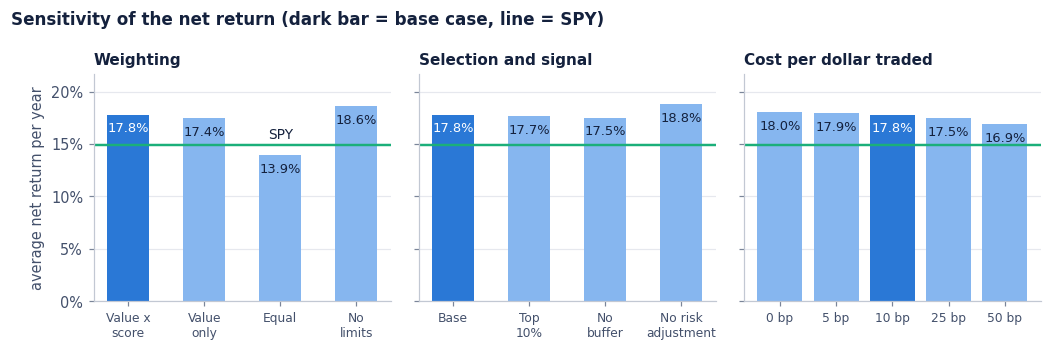


**What the sensitivities show.**

* **Against SPY.** 21 of the 22 variants earned more than SPY net of costs; the exception is Equal weights. Net returns range from 13.9% to 18.8%; Sharpe ratios from 0.76 to 0.99 (SPY 0.84).
* **Weighting.** Of all the variations, "Equal weights" moves the return most (-3.88 pp). With **equal weights** the same selection earned 13.9% per year, -1.01 pp against SPY, compared with 17.8% for the base case. The lead over the index therefore depends on holding the selected stocks in proportion to their size; it does not come from the selection alone. The decade favoured size in general: all eligible stocks held in equal weights earned 12.7% per year, against 15.3% when weighted by market value. The score tilt itself changes little: weighting by market value only gives 17.4%. Without the weight limits the return is 18.6%, with the largest position reaching 31% of the portfolio instead of 14%. Under the second reading of the limit the return is 17.6%.
* **Selection and signal.** Holding the top 10% instead of the top 20% gives 17.7% with 45 holdings and a volatility of 16.5%. Holding 100 stocks, as the index does, instead of a fifth of the eligible ones gives 17.9% (+0.10 pp against the base case). **The last place matters:** with one stock fewer at every rebalance the return is 17.76%, with one more 17.50% (base case 17.80%). The largest position that the extra place admits is Microsoft at the 2024-09 rebalance (9.1% of the portfolio). Because weights follow company size, a single very large company at the cut-off can move the ten-year average by a tenth of a percentage point or more; how many stocks are eligible, and therefore where the cut-off falls, depends on details of the data. Without the buffer rule turnover rises from 102% to 114% per year and the return is 17.5%. Ranking by plain momentum, without dividing by volatility, gives 18.8% at a volatility of 17.7% (base case 16.3%).
* **Frequency.** Quarterly rebalancing gives 16.9% at 146% turnover per year; rebalancing once a year gives 17.8% at 69%.
* **Costs.** Each additional 10 bp of trading cost lowers the net return by about 0.22 percentage points per year. At 50 bp per dollar traded the strategy earns 16.9%, +2.04 pp against SPY.
* **Share counts.** Without any carried-back count the return is 17.7% (-0.08 pp against the base case); with counts carried back without limit, which brings more companies into the earlier years but also counts that are wrong after mergers, it is 17.8% (-0.05 pp). Using every count at once gives 17.8%, keeping the counts before Yahoo's outage 17.8%, and reading counts under today's ticker only 17.9%. Across the 5 data variants the return moves by at most 0.11 percentage points: none of the rules varied here drives the result. The unit rules (2 and 3) are not varied; without them market values would be wrong by the split factors themselves.

Leaving the cost levels aside, 5 of the 17 variations did better than the base case in this sample (One fifth of the index (100 stocks), No risk adjustment, No weight limits, Share counts before Yahoo's outage kept, Share counts under today's ticker only). None of them should be adopted for that reason: with 17 variations, some will look good by chance alone (Harvey and Liu, 2015). The base case stays the published rule set.


In [28]:
VARIANT_LOG = []      # every variant that is run, in order

def variant_row(label, family, bt):
    s = bt["strategy"]; m = bt["metrics"].loc[s]; t = bt["trading"].loc[s]; r = bt["returns"]
    row = {"setting changed": family, "variant": label, "Average return p.a.": m["ann_return"], "Volatility p.a.": m["ann_vol"],
           "Sharpe ratio": m["sharpe"], "Alpha p.a.": m["alpha"], "Beta": m["beta"], "Information ratio": m["info_ratio"],
           "Max drawdown": m["max_drawdown"], "vs SPY p.a.": 12 * (r[s] - r["SPY"]).mean(),
           "vs cap-weighted universe p.a.": 12 * (r[s] - r["Universe"]).mean(), "Holdings": t["avg_holdings"],
           "Largest weight reached": t["max_weight"], "One-way turnover p.a.": t["one_way_turnover_pa"], "Cost p.a.": t["cost_pa"]}
    VARIANT_LOG.append(row)
    return row

BASE_LABEL = "Index rules (BASE)"
variant_row(BASE_LABEL, "base case", BT)
BT_TOP10 = run_backtest(reconfigure(DATA, replace(CFG, n_groups=10)), replace(CFG, n_groups=10))
variant_row("Top 10%", "selection", BT_TOP10)
variant_row("No buffer rule", "selection", run_backtest(DATA, replace(CFG, buffer=0.0)))
variant_row("One fifth of the index (100 stocks)", "selection", run_backtest(DATA, replace(CFG, target_count=100)))
variant_row("One stock fewer at every rebalance", "selection", run_backtest(DATA, replace(CFG, target_shift=-1)))
BT_PLUS = run_backtest(DATA, replace(CFG, target_shift=1))
variant_row("One stock more at every rebalance", "selection", BT_PLUS)
variant_row("No risk adjustment", "signal", run_backtest(reconfigure(DATA, replace(CFG, risk_adjust=False)), replace(CFG, risk_adjust=False)))
variant_row("Market value only (no score)", "weighting", run_backtest(DATA, replace(CFG, weighting="cap")))
BT_EQUAL = run_backtest(DATA, replace(CFG, weighting="equal"))
variant_row("Equal weights", "weighting", BT_EQUAL)
variant_row("No weight limits", "weighting", run_backtest(DATA, replace(CFG, max_weight=1.0, max_cap_multiple=1e9)))
BT_READING2 = run_backtest(DATA, replace(CFG, cap_reference="universe"))
variant_row("Limit of 3 x weight in the S&P 500", "weighting", BT_READING2)
variant_row("Quarterly", "rebalancing frequency", run_backtest(DATA, replace(CFG, rebalance_months=(3, 6, 9, 12))))
variant_row("Once a year (March)", "rebalancing frequency", run_backtest(DATA, replace(CFG, rebalance_months=(3,))))
for c in (0.0, 0.0005, 0.0025, 0.0050):
    variant_row(f"{c * 1e4:.0f} bp", "transaction cost", run_backtest(DATA, replace(CFG, cost_rate=c)))
CFG_OBSERVED = replace(CFG, share_carry_back_days=0)
BT_OBSERVED = run_backtest(reconfigure(DATA, CFG_OBSERVED), CFG_OBSERVED)
variant_row("Without carried-back share counts", "data", BT_OBSERVED)
CFG_UNLIMITED = replace(CFG, share_carry_back_days=100000)
BT_UNLIMITED = run_backtest(reconfigure(DATA, CFG_UNLIMITED), CFG_UNLIMITED)
variant_row("Share counts carried back without limit", "data", BT_UNLIMITED)
CFG_UNCONFIRMED = replace(CFG, share_confirm=None)
variant_row("Every share count used at once (no second count)", "data", run_backtest(reconfigure(DATA, CFG_UNCONFIRMED), CFG_UNCONFIRMED))
CFG_EDGE = replace(CFG, share_skip_before_outage=False)
variant_row("Share counts before Yahoo's outage kept", "data", run_backtest(reconfigure(DATA, CFG_EDGE), CFG_EDGE))
CFG_TODAY = replace(CFG, share_ticker_history=False)
variant_row("Share counts under today's ticker only", "data", run_backtest(reconfigure(DATA, CFG_TODAY), CFG_TODAY))
EQ_UNIVERSE = run_portfolio(PANEL, RF, build_targets(FORMS, BT["formation_months"], CFG, "all", weighting="equal", capped=False)[0],
                            BT["start"], BT["end"], CFG.cost_rate)["ret"]              # all eligible stocks, equally weighted
SENS = pd.DataFrame(VARIANT_LOG).set_index(["setting changed", "variant"])
sens_fmt = {"Average return p.a.": "{:.2%}", "Volatility p.a.": "{:.2%}", "Sharpe ratio": "{:.2f}", "Alpha p.a.": "{:+.2%}", "Beta": "{:.2f}",
            "Information ratio": "{:.2f}", "Max drawdown": "{:.1%}", "vs SPY p.a.": "{:+.2%}", "vs cap-weighted universe p.a.": "{:+.2%}",
            "Holdings": "{:.0f}", "Largest weight reached": "{:.1%}", "One-way turnover p.a.": "{:.0%}", "Cost p.a.": "{:.2%}"}
display(savetable(SENS, "tab_sensitivities").style.format(sens_fmt))
print(f"Variants run in this notebook: {len(SENS)} (1 base case + {len(SENS) - 1} one-at-a-time variations).")
print(f"Second reading of the limit: the multiple had to be raised above 3 at {int((BT_READING2['selection']['multiple used'] > 3).sum())} "
      f"of {len(BT_READING2['selection'])} trade dates (highest multiple {BT_READING2['selection']['multiple used'].max():.0f}).")

fig, axes = plt.subplots(1, 3, figsize=(9.6, 3.2), sharey=True)
base = SENS.loc[("base case", BASE_LABEL)]
row_of = lambda family, label: SENS.loc[(family, label)]
panels = [("Weighting", [("Value x\nscore", base), ("Value\nonly", row_of("weighting", "Market value only (no score)")),
                         ("Equal", row_of("weighting", "Equal weights")), ("No\nlimits", row_of("weighting", "No weight limits"))]),
          ("Selection and signal", [("Base", base), ("Top\n10%", row_of("selection", "Top 10%")), ("No\nbuffer", row_of("selection", "No buffer rule")),
                                    ("No risk\nadjustment", row_of("signal", "No risk adjustment"))]),
          ("Cost per dollar traded", [("0 bp", row_of("transaction cost", "0 bp")), ("5 bp", row_of("transaction cost", "5 bp")), ("10 bp", base),
                                      ("25 bp", row_of("transaction cost", "25 bp")), ("50 bp", row_of("transaction cost", "50 bp"))])]
for ax, (title, items) in zip(axes, panels):
    names = [n for n, _ in items]; vals = [row["Average return p.a."] for _, row in items]
    fills = [BLUE if row is base else "#86b6ef" for _, row in items]
    ax.bar(names, vals, width=0.55 if len(names) <= 4 else 0.8, color=fills)
    bar_labels(ax, names, vals, [pct(v) for v in vals], fills)
    ax.axhline(M.loc["SPY", "ann_return"], color=TEAL, lw=1.6)
    ax.set_title(title, fontsize=10); percent_axis(ax); ax.tick_params(axis="x", labelsize=8)
axes[0].set_ylabel("average net return per year")
axes[0].annotate("SPY", (2, M.loc["SPY", "ann_return"]), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=INK)
axes[0].set_ylim(0, max(SENS["Average return p.a."].max(), M.loc["SPY", "ann_return"]) * 1.15)
fig.suptitle("Sensitivity of the net return (dark bar = base case, line = SPY)", x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
plt.tight_layout(); savefig(fig, "fig_sensitivities")

beat_spy = SENS.index[SENS["vs SPY p.a."] > 0]
others = SENS.drop(index=("base case", BASE_LABEL)).drop(index="transaction cost", level=0)      # a lower cost is always better
better = others.index[others["Average return p.a."] > base["Average return p.a."]]
wt = SENS.xs("weighting", level=0); sel = SENS.xs("selection", level=0); freq = SENS.xs("rebalancing frequency", level=0)
cost = SENS.xs("transaction cost", level=0); norisk = row_of("signal", "No risk adjustment"); obs = row_of("data", "Without carried-back share counts")
unl = row_of("data", "Share counts carried back without limit")
eq = wt.loc["Equal weights"]
hundred = sel.loc["One fifth of the index (100 stocks)"]
fewer, more = sel.loc["One stock fewer at every rebalance"], sel.loc["One stock more at every rebalance"]
extra = []                                 # what the extra place admits: the largest position held only in the "one more" run
for m in BT["formation_months"]:
    w_plus = BT_PLUS["runs"]["Strategy"]["targets"][m]
    only = w_plus[~w_plus.index.isin(TARGETS[m].index)]
    extra += [(float(w), FORMS[m].loc[s, "name"], m) for s, w in only.items()]
extra_w, extra_name, extra_month = max(extra) if extra else (float("nan"), "none", None)
data_rows = SENS.xs("data", level=0)
data_span = (data_rows["Average return p.a."] - base["Average return p.a."]).abs().max()
change = (others["Average return p.a."] - base["Average return p.a."])
biggest = change.abs().idxmax()                                              # the variation that moves the return most
eq_universe, cap_universe = 12 * EQ_UNIVERSE.mean(), M.loc["Universe", "ann_return"]
ret_unconfirmed = data_rows.loc["Every share count used at once (no second count)", "Average return p.a."]
ret_edge = data_rows.loc["Share counts before Yahoo's outage kept", "Average return p.a."]
ret_today = data_rows.loc["Share counts under today's ticker only", "Average return p.a."]
say(f"""
**What the sensitivities show.**

* **Against SPY.** {pick(len(beat_spy) == len(SENS), f'All {len(SENS)} variants', pick(len(beat_spy) == 0, 'None of the variants', f'{len(beat_spy)} of the {len(SENS)} variants'))} earned more than SPY net of costs{pick(0 < len(beat_spy) < len(SENS), '; the exception' + pick(len(SENS) - len(beat_spy) == 1, ' is ', 's are ') + ', '.join(v for _, v in SENS.index if (_, v) not in set(beat_spy)), '')}. Net returns range from {pct(SENS['Average return p.a.'].min())} to {pct(SENS['Average return p.a.'].max())}; Sharpe ratios from {num(SENS['Sharpe ratio'].min())} to {num(SENS['Sharpe ratio'].max())} (SPY {num(M.loc['SPY', 'sharpe'])}).
* **Weighting.** Of all the variations, "{biggest[1]}" moves the return most ({pp(change[biggest], 2)}). With **equal weights** the same selection earned {pct(eq['Average return p.a.'])} per year, {pp(eq['vs SPY p.a.'], 2)} against SPY, compared with {pct(base['Average return p.a.'])} for the base case. {pick(eq['vs SPY p.a.'] < 0, 'The lead over the index therefore depends on holding the selected stocks in proportion to their size; it does not come from the selection alone.', 'The selection also leads the index when the stocks are held in equal amounts, though by less.')} The decade favoured size in general: all eligible stocks held in equal weights earned {pct(eq_universe)} per year, against {pct(cap_universe)} when weighted by market value. The score tilt itself changes little: weighting by market value only gives {pct(wt.loc['Market value only (no score)', 'Average return p.a.'])}. Without the weight limits the return is {pct(wt.loc['No weight limits', 'Average return p.a.'])}, with the largest position reaching {pct(wt.loc['No weight limits', 'Largest weight reached'], 0)} of the portfolio instead of {pct(base['Largest weight reached'], 0)}. Under the second reading of the limit the return is {pct(wt.loc['Limit of 3 x weight in the S&P 500', 'Average return p.a.'])}.
* **Selection and signal.** Holding the top 10% instead of the top 20% gives {pct(sel.loc['Top 10%', 'Average return p.a.'])} with {sel.loc['Top 10%', 'Holdings']:.0f} holdings and a volatility of {pct(sel.loc['Top 10%', 'Volatility p.a.'])}. Holding 100 stocks, as the index does, instead of a fifth of the eligible ones gives {pct(hundred['Average return p.a.'])} ({pp(hundred['Average return p.a.'] - base['Average return p.a.'], 2)} against the base case). **The last place matters:** with one stock fewer at every rebalance the return is {pct(fewer['Average return p.a.'], 2)}, with one more {pct(more['Average return p.a.'], 2)} (base case {pct(base['Average return p.a.'], 2)}). The largest position that the extra place admits is {extra_name} at the {extra_month} rebalance ({pct(extra_w)} of the portfolio). Because weights follow company size, a single very large company at the cut-off can move the ten-year average by a tenth of a percentage point or more; how many stocks are eligible, and therefore where the cut-off falls, depends on details of the data. Without the buffer rule turnover rises from {pct(base['One-way turnover p.a.'], 0)} to {pct(sel.loc['No buffer rule', 'One-way turnover p.a.'], 0)} per year and the return is {pct(sel.loc['No buffer rule', 'Average return p.a.'])}. Ranking by plain momentum, without dividing by volatility, gives {pct(norisk['Average return p.a.'])} at a volatility of {pct(norisk['Volatility p.a.'])} (base case {pct(base['Volatility p.a.'])}).
* **Frequency.** Quarterly rebalancing gives {pct(freq.loc['Quarterly', 'Average return p.a.'])} at {pct(freq.loc['Quarterly', 'One-way turnover p.a.'], 0)} turnover per year; rebalancing once a year gives {pct(freq.loc['Once a year (March)', 'Average return p.a.'])} at {pct(freq.loc['Once a year (March)', 'One-way turnover p.a.'], 0)}.
* **Costs.** Each additional 10 bp of trading cost lowers the net return by about {(cost.loc['0 bp', 'Average return p.a.'] - cost.loc['50 bp', 'Average return p.a.']) / 5 * 100:.2f} percentage points per year. At 50 bp per dollar traded the strategy earns {pct(cost.loc['50 bp', 'Average return p.a.'])}, {pp(cost.loc['50 bp', 'vs SPY p.a.'], 2)} against SPY.
* **Share counts.** Without any carried-back count the return is {pct(obs['Average return p.a.'])} ({pp(obs['Average return p.a.'] - base['Average return p.a.'], 2)} against the base case); with counts carried back without limit, which brings more companies into the earlier years but also counts that are wrong after mergers, it is {pct(unl['Average return p.a.'])} ({pp(unl['Average return p.a.'] - base['Average return p.a.'], 2)}). Using every count at once gives {pct(ret_unconfirmed)}, keeping the counts before Yahoo's outage {pct(ret_edge)}, and reading counts under today's ticker only {pct(ret_today)}. Across the {len(data_rows)} data variants the return moves by at most {data_span * 100:.2f} percentage points: {pick(data_span < 0.005, 'none of the rules varied here drives the result', 'these rules are a visible part of the result, which is a weakness of the data')}. The unit rules (2 and 3) are not varied; without them market values would be wrong by the split factors themselves.

{pick(len(better) > 0, f"Leaving the cost levels aside, {len(better)} of the {len(others)} variations did better than the base case in this sample ({', '.join(v for _, v in better)}). None of them should be adopted for that reason: with {len(others)} variations, some will look good by chance alone (Harvey and Liu, 2015).", f"Leaving the cost levels aside, none of the {len(others)} variations did better than the base case in this sample.")} The base case stays the published rule set.
""")

### 8.2 Break-even transaction cost

The break-even cost is the cost per dollar traded at which the strategy's average net return would equal that of the comparison portfolio, with the same cost rate applied to both (SPY pays it once, on its initial purchase; the cap-weighted universe pays it at every rebalance).

In [29]:
BE = {v: break_even_cost(DATA, CFG, v) for v in ("SPY", "Universe")}
be_table = pd.DataFrame({LABEL[v]: BE[v]["table"] for v in BE})
be_table.index = [f"{c * 1e4:.0f} bp" for c in be_table.index]; be_table.index.name = "cost per dollar traded"
print("Annualised net return advantage of the strategy at different cost levels:")
display(savetable(be_table, "tab_break_even_costs").style.format("{:+.2%}"))
for v in BE:
    be = BE[v]
    print(f"vs {LABEL[v]}: {be['status']}" + ("" if pd.isna(be["break_even"]) else f" at {be['break_even'] * 1e4:.0f} bp per dollar traded"))

Annualised net return advantage of the strategy at different cost levels:


,S&P 500 (SPY),Cap-weighted universe
cost per dollar traded,,
0 bp,+3.08%,+2.72%
5 bp,+2.97%,+2.62%
10 bp,+2.87%,+2.51%
25 bp,+2.56%,+2.21%
50 bp,+2.04%,+1.71%
100 bp,+1.01%,+0.71%
200 bp,-1.04%,-1.28%
500 bp,-7.09%,-7.15%


vs S&P 500 (SPY): break-even found at 149 bp per dollar traded
vs Cap-weighted universe: break-even found at 135 bp per dollar traded


### 8.3 Sub-periods and market episodes

The sub-periods are three consecutive blocks of the sample (2016 to 2018, 2019 to 2021, 2022 to 2025); the episodes are well-known market phases, measured from month-end to month-end. They describe where the result came from; they are not independent tests.

In [30]:
def period_return(frame, first, last):
    return (1 + frame.loc[P(first):P(last)]).prod() - 1

episodes = [("Sub-period 1", "2016-01", "2018-12"), ("Sub-period 2", "2019-01", "2021-12"), ("Sub-period 3", "2022-01", "2025-12"),
            ("Sell-off, Q4 2018", "2018-10", "2018-12"), ("COVID crash, Feb-Mar 2020", "2020-02", "2020-03"),
            ("Rebound, Apr-Aug 2020", "2020-04", "2020-08"), ("Vaccine rotation, Nov 2020", "2020-11", "2020-11"),
            ("Bear market, Jan-Sep 2022", "2022-01", "2022-09"), ("Recovery, 2023", "2023-01", "2023-12"),
            ("2024", "2024-01", "2024-12"), ("2025", "2025-01", "2025-12")]
EP = pd.DataFrame({name: period_return(R[[STRAT, "SPY", "Universe", "Q1"]], a, b) for name, a, b in episodes}).T.rename(columns=LABEL)
EP = EP.rename(columns={"Q1": "Lowest scores (Q1)"})
EP.insert(0, "months", [len(R.loc[P(a):P(b)]) for _, a, b in episodes])
EP["Strategy minus SPY"] = EP[LABEL[STRAT]] - EP[LABEL["SPY"]]
display(savetable(EP, "tab_subperiods_and_episodes").style.format({c: "{:+.1%}" for c in EP.columns if c != "months"}))
sub, epi = EP.iloc[:3], EP.iloc[3:]
ahead_epi = list(epi.index[epi["Strategy minus SPY"] > 0]); behind_epi = list(epi.index[epi["Strategy minus SPY"] <= 0])
gap = epi["Strategy minus SPY"]
m24 = P("2024-03"); top24 = ", ".join(FORMS[m24].loc[TARGETS[m24].nlargest(5).index, "name"])
covid, bear = epi.loc["COVID crash, Feb-Mar 2020"], epi.loc["Bear market, Jan-Sep 2022"]
lead_total = NAV[STRAT].iloc[-1] / NAV["SPY"].iloc[-1] - 1
lead_to_2023 = NAV[STRAT].loc[P("2023-12")] / NAV["SPY"].loc[P("2023-12")] - 1
late_share = 1.0 - math.log1p(lead_to_2023) / math.log1p(lead_total) if lead_total > 0 else float("nan")   # part of the final lead (in logs) built in 2024-25
late_text = ("" if not lead_total > 0 else
             f"**{pick(late_share > 0.5, 'Most', 'Part')} of the ten-year lead ({pct(late_share, 0)} of it, measured in logs) was earned in 2024 and 2025.**")
say(f"""
**Reading the table.** The strategy was ahead of SPY in {int((sub['Strategy minus SPY'] > 0).sum())} of the three sub-periods ({', '.join(f"{v:+.1%}" for v in sub['Strategy minus SPY'])}). Of the {len(epi)} episodes it was ahead in {len(ahead_epi)} ({'; '.join(ahead_epi) if ahead_epi else 'none'}) and behind in {len(behind_epi)} ({'; '.join(behind_epi) if behind_epi else 'none'}).

**Falling markets.** In the COVID crash the strategy lost {covid[LABEL[STRAT]]:+.1%} against {covid[LABEL['SPY']]:+.1%} for SPY, and in the 2022 bear market {bear[LABEL[STRAT]]:+.1%} against {bear[LABEL['SPY']]:+.1%}. Owning past winners is {pick(covid[LABEL[STRAT]] > covid[LABEL['SPY']] and bear[LABEL[STRAT]] > bear[LABEL['SPY']], 'some cushion in these two declines, but no protection: the losses are of the same order as the market', 'no protection in a sell-off')}.

**Where the lead comes from.** Among the episodes, the largest gap in the strategy's favour is {gap.idxmax()} ({gap.max():+.1%}), the largest against it {gap.idxmin()} ({gap.min():+.1%}). At the end of 2023, eight years into the sample, one dollar in the strategy was worth {pick(lead_to_2023 >= 0, f'{lead_to_2023:.1%} more', f'{-lead_to_2023:.1%} less')} than one dollar in SPY; at the end of 2025 it was worth {pick(lead_total >= 0, f'{lead_total:.1%} more', f'{-lead_total:.1%} less')}. {late_text} The five largest positions bought in March 2024 were {top24}: a small group of very large companies had high momentum scores and went on to earn high returns. A client should not expect such years to repeat regularly.
""")

,months,Quantile Alpha,S&P 500 (SPY),Cap-weighted universe,Lowest scores (Q1),Strategy minus SPY
Sub-period 1,36,+39.1%,+29.9%,+32.2%,+40.0%,+9.2%
Sub-period 2,36,+89.2%,+99.9%,+101.5%,+81.4%,-10.7%
Sub-period 3,48,+95.5%,+51.8%,+53.3%,+38.4%,+43.7%
"Sell-off, Q4 2018",3,-16.2%,-13.5%,-13.2%,-10.1%,-2.7%
"COVID crash, Feb-Mar 2020",2,-16.7%,-19.4%,-19.3%,-23.5%,+2.7%
"Rebound, Apr-Aug 2020",5,+39.7%,+36.1%,+36.9%,+21.1%,+3.6%
"Vaccine rotation, Nov 2020",1,+7.3%,+10.9%,+10.9%,+25.3%,-3.6%
"Bear market, Jan-Sep 2022",9,-22.6%,-23.9%,-23.9%,-24.2%,+1.3%
"Recovery, 2023",12,+18.0%,+26.2%,+26.9%,+33.8%,-8.2%
2024,12,+49.4%,+24.9%,+25.6%,+9.3%,+24.5%



**Reading the table.** The strategy was ahead of SPY in 2 of the three sub-periods (+9.2%, -10.7%, +43.7%). Of the 8 episodes it was ahead in 5 (COVID crash, Feb-Mar 2020; Rebound, Apr-Aug 2020; Bear market, Jan-Sep 2022; 2024; 2025) and behind in 3 (Sell-off, Q4 2018; Vaccine rotation, Nov 2020; Recovery, 2023).

**Falling markets.** In the COVID crash the strategy lost -16.7% against -19.4% for SPY, and in the 2022 bear market -22.6% against -23.9%. Owning past winners is some cushion in these two declines, but no protection: the losses are of the same order as the market.

**Where the lead comes from.** Among the episodes, the largest gap in the strategy's favour is 2024 (+24.5%), the largest against it Recovery, 2023 (-8.2%). At the end of 2023, eight years into the sample, one dollar in the strategy was worth 1.8% more than one dollar in SPY; at the end of 2025 it was worth 30.5% more. **Most of the ten-year lead (93% of it, measured in logs) was earned in 2024 and 2025.** The five largest positions bought in March 2024 were Nvidia, Microsoft, Meta Platforms, Apple Inc., Amazon: a small group of very large companies had high momentum scores and went on to earn high returns. A client should not expect such years to repeat regularly.


### 8.4 How persistent is the ranking? Quintile migration

If the top quintile were completely reshuffled every half-year, the whole portfolio would be replaced twice a year; if rankings never changed, no trading would be needed at all. The transition matrix shows where the stocks of each quintile are found at the next rebalance, **including** those that left the index or became ineligible (nothing is restricted to survivors). Rows sum to 100%. The matrix uses the plain quintiles; the strategy's own retention, with the buffer rule, is reported below it.

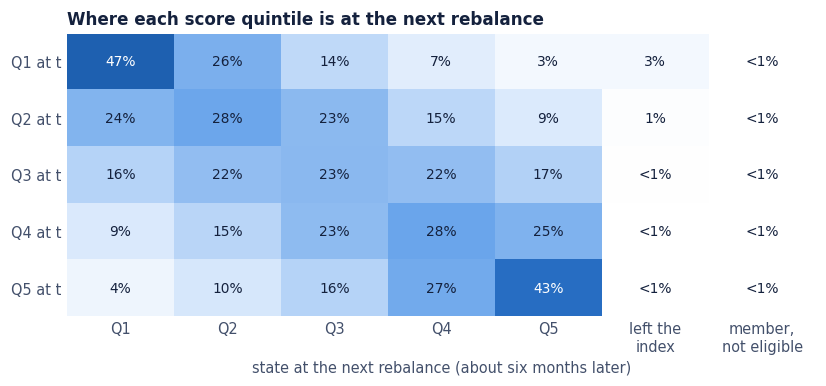

Entries: quintile in which stocks that were not eligible at the previous rebalance first appear (share of all entries):


,Q1,Q2,Q3,Q4,Q5
share of entries,8%,5%,18%,18%,52%



**Reading the matrix.** A stock in the top quintile has a **43% chance of still being there at the next rebalance**; the bottom quintile is similarly sticky (47%), while the middle quintiles reshuffle more. Exits from the eligible universe are rare in this data (0.0% of Q5 stocks per half-year). In reality they were more frequent: companies that were later taken over are missing from Yahoo altogether (section 3), so they never appear in a quintile and cannot be seen leaving one.

**What the buffer rule does.** Of the plain top quintile, 43% of the stocks are in the top quintile again at the next rebalance (range 20% to 70%). The strategy, which keeps holdings that still rank within the best 1.2 × N, retains 48% on average (24% to 78%). The rule thus saves about 5 percentage points of name turnover per rebalance.

**Holding duration.** A stay in the top quintile lasts on average 1.6 rebalances (about 10 months) for the 940 completed stays; 16% of all stays touch the first or last date and are therefore cut off (including them, the average observed length is 1.7 rebalances, a lower bound for those cases).

**Is half-yearly rebalancing reasonable?** About 57% of the top quintile changes from one rebalance to the next, so after six months the ranking is largely a new one. Quarterly rebalancing would react faster, at 146% annual turnover instead of 102% (section 8.1). The half-yearly calendar is the index's; this analysis describes the trade-off and was not used to choose it.


In [31]:
TRANS = transition_analysis(FORMS, MEMBERS, BT["formation_months"], CFG.n_groups)
TP = TRANS["probabilities"].copy(); TP.index = [f"Q{g} at t" for g in TP.index]
TP.columns = [f"Q{c}" if isinstance(c, (int, np.integer)) else c for c in TP.columns]
savetable(TP, "tab_transition_matrix")

from matplotlib.colors import LinearSegmentedColormap
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#ffffff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(7.6, 3.6))
im = ax.imshow(TP.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=max(0.6, float(TP.to_numpy().max())), aspect="auto")
ax.set_xticks(range(TP.shape[1])); ax.set_xticklabels([c.replace("member but not eligible", "member,\nnot eligible").replace("left the index", "left the\nindex") for c in TP.columns])
ax.set_yticks(range(TP.shape[0])); ax.set_yticklabels(TP.index)
for i in range(TP.shape[0]):
    for j in range(TP.shape[1]):
        v = TP.iloc[i, j]
        ax.text(j, i, f"{v:.0%}" if v >= 0.005 else "<1%", ha="center", va="center", fontsize=9, color="white" if v > 0.33 else INK)
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_xlabel("state at the next rebalance (about six months later)"); ax.set_title("Where each score quintile is at the next rebalance")
plt.tight_layout(); savefig(fig, "fig_transition_matrix")

stays = TRANS["stays"]; complete = stays[~stays["censored"]]
p55 = TRANS["probabilities"].loc[5, 5]
exit5 = TRANS["probabilities"].loc[5, ["left the index", "member but not eligible"]].sum()
entries = TRANS["entries"] / TRANS["entries"].sum()
t5 = BT["trading"].loc[STRAT]
kept = (SEL["already held"] / SEL["selected"]).iloc[1:]
print("Entries: quintile in which stocks that were not eligible at the previous rebalance first appear (share of all entries):")
display(entries.rename(lambda g: f"Q{g}").rename("share of entries").to_frame().T.style.format("{:.0%}"))
say(f"""
**Reading the matrix.** A stock in the top quintile has a **{pct(p55, 0)} chance of still being there at the next rebalance**; the bottom quintile is {pick(abs(TRANS['probabilities'].loc[1, 1] - p55) < 0.08, 'similarly sticky', 'different')} ({pct(TRANS['probabilities'].loc[1, 1], 0)}), while the middle quintiles reshuffle more. Exits from the eligible universe are rare in this data ({pct(exit5)} of Q5 stocks per half-year). In reality they were more frequent: companies that were later taken over are missing from Yahoo altogether (section 3), so they never appear in a quintile and cannot be seen leaving one.

**What the buffer rule does.** Of the plain top quintile, {pct(TRANS['retention'].mean(), 0)} of the stocks are in the top quintile again at the next rebalance (range {pct(TRANS['retention'].min(), 0)} to {pct(TRANS['retention'].max(), 0)}). The strategy, which keeps holdings that still rank within the best 1.2 × N, retains {pct(kept.mean(), 0)} on average ({pct(kept.min(), 0)} to {pct(kept.max(), 0)}). The rule thus saves about {(kept.mean() - TRANS['retention'].mean()) * 100:.0f} percentage points of name turnover per rebalance.

**Holding duration.** A stay in the top quintile lasts on average {complete['periods'].mean():.1f} rebalances (about {complete['periods'].mean() * 6:.0f} months) for the {len(complete)} completed stays; {pct(stays['censored'].mean(), 0)} of all stays touch the first or last date and are therefore cut off (including them, the average observed length is {stays['periods'].mean():.1f} rebalances, a lower bound for those cases).

**Is half-yearly rebalancing reasonable?** About {pct(1 - TRANS['retention'].mean(), 0)} of the top quintile changes from one rebalance to the next, so after six months the ranking is largely a new one. Quarterly rebalancing would react faster, at {pct(freq.loc['Quarterly', 'One-way turnover p.a.'], 0)} annual turnover instead of {pct(t5['one_way_turnover_pa'], 0)} (section 8.1). The half-yearly calendar is the index's; this analysis describes the trade-off and was not used to choose it.
""")

### 8.5 Is the result stable over time? Rolling windows

Every point uses only the trailing 12 or 36 months; windows that are not complete are not plotted. "Relative performance" is the difference between the strategy's and SPY's compounded return over the window (annualised for 36 months).

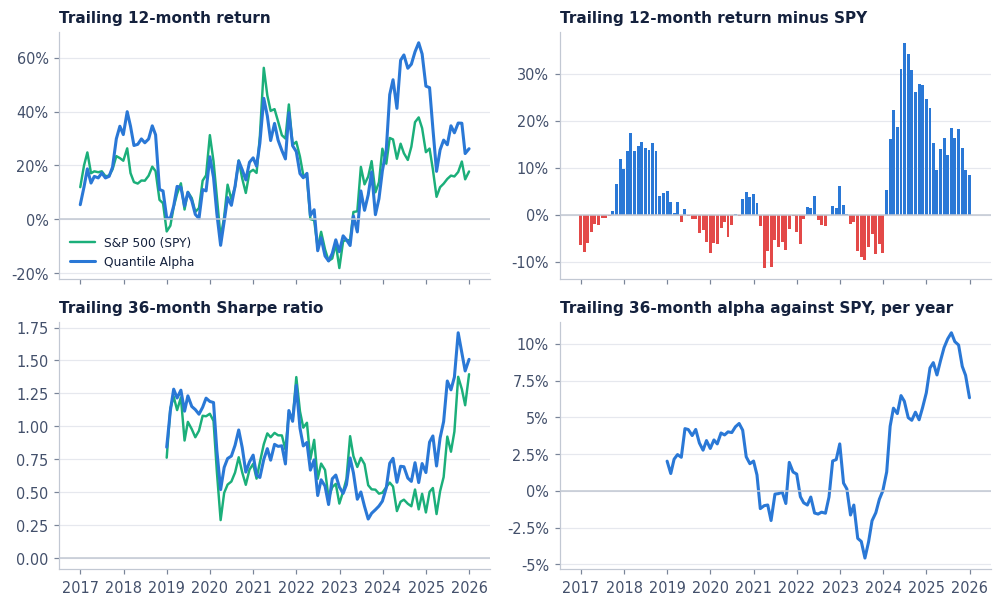

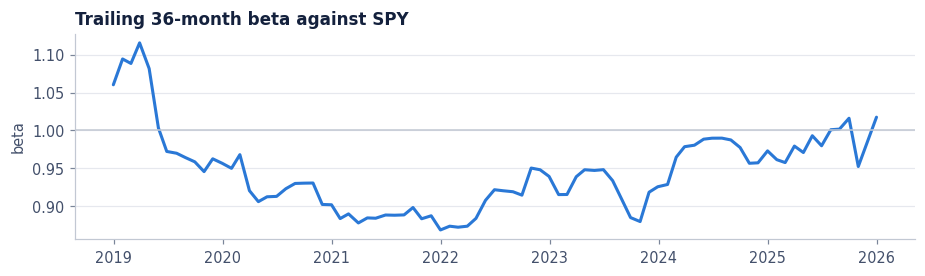


**Reading the rolling charts.** The strategy was ahead of SPY in **53% of all rolling 12-month windows** and in 61% of all rolling 36-month windows. The 12-month difference ranged from -11.3 pp to +36.5 pp. The trailing 36-month alpha moved between -4.6% and 10.8% per year and the trailing beta between 0.87 and 1.12: the market exposure of a momentum portfolio is not constant, because the kind of stock that qualifies as a "winner" changes with the market (defensive stocks after a decline, high-beta stocks after a rally). Periods ahead of and behind the index alternate: a client should expect stretches of a year or more behind the index, even in a decade that ends well ahead.


In [32]:
ROLL = rolling_stats(R[STRAT], R["SPY"], BT["rf"])
savetable(ROLL, "tab_rolling_statistics")
fig, axes = plt.subplots(2, 2, figsize=(9.2, 5.6), sharex=True)
ax = axes[0, 0]
ax.plot(dates[1:], ROLL["bench_12m"], color=TEAL, lw=1.6, label=LABEL["SPY"]); ax.plot(dates[1:], ROLL["return_12m"], color=BLUE, label=LABEL[STRAT])
ax.axhline(0, color=AXIS, lw=1); percent_axis(ax); ax.set_title("Trailing 12-month return", fontsize=10); ax.legend(loc="lower left", fontsize=8)
ax = axes[0, 1]
ax.bar(dates[1:], ROLL["relative_12m"], width=days(25), color=np.where(ROLL["relative_12m"] >= 0, BLUE, RED))
ax.axhline(0, color=AXIS, lw=1); percent_axis(ax); ax.set_title("Trailing 12-month return minus SPY", fontsize=10)
ax = axes[1, 0]
ax.plot(dates[1:], ROLL["bench_sharpe_36m"], color=TEAL, lw=1.6, label=LABEL["SPY"]); ax.plot(dates[1:], ROLL["sharpe_36m"], color=BLUE, label=LABEL[STRAT])
ax.axhline(0, color=AXIS, lw=1); ax.set_title("Trailing 36-month Sharpe ratio", fontsize=10)
ax = axes[1, 1]
ax.plot(dates[1:], ROLL["alpha_36m_pa"], color=BLUE)
ax.axhline(0, color=AXIS, lw=1); percent_axis(ax); ax.set_title("Trailing 36-month alpha against SPY, per year", fontsize=10)
plt.tight_layout(); savefig(fig, "fig_rolling_performance")

fig, ax = plt.subplots(figsize=(8.5, 2.6))
ax.plot(dates[1:], ROLL["beta_36m"], color=BLUE); ax.axhline(1.0, color=AXIS, lw=1)
ax.set_ylabel("beta"); ax.set_title("Trailing 36-month beta against SPY")
plt.tight_layout(); savefig(fig, "fig_rolling_beta")

w12, w36 = ROLL["relative_12m"].dropna(), ROLL["relative_36m_pa"].dropna()
say(f"""
**Reading the rolling charts.** The strategy was ahead of SPY in **{pct((w12 > 0).mean(), 0)} of all rolling 12-month windows** and in {pct((w36 > 0).mean(), 0)} of all rolling 36-month windows. The 12-month difference ranged from {pp(w12.min())} to {pp(w12.max())}. The trailing 36-month alpha moved between {pct(ROLL['alpha_36m_pa'].min())} and {pct(ROLL['alpha_36m_pa'].max())} per year and the trailing beta between {num(ROLL['beta_36m'].min())} and {num(ROLL['beta_36m'].max())}: the market exposure of a momentum portfolio is not constant, because the kind of stock that qualifies as a "winner" changes with the market (defensive stocks after a decline, high-beta stocks after a rally). {pick((w36 > 0).mean() < 0.25, 'A client should expect multi-year stretches behind the index.', pick((w12 > 0).mean() > 0.9, 'Periods behind the index were rare in this sample.', 'Periods ahead of and behind the index alternate: a client should expect stretches of a year or more behind the index, even in a decade that ends well ahead.'))}
""")

### 8.6 How much of this could be chance? Block bootstrap

Ten years of monthly returns are a small sample. The block bootstrap resamples the observed months **in blocks of consecutive months** (so that short-lived autocorrelation and volatility clustering are preserved) and **the same months for every series** (so that the relationship between strategy, benchmark, risk-free rate and quintiles is preserved). The blocks wrap around the end of the sample (a circular version of the block bootstrap of Künsch, 1989; see Politis and Romano, 1994). Settings: block length 6 months, 2,000 resamples, seed 2270, percentile intervals; block lengths of 3 and 12 months are shown as a sensitivity.

Limitations: the bootstrap can only reshuffle what happened in this decade, it cannot produce a regime that is not in the sample, and percentile intervals are approximate with 120 observations. An interval that excludes zero is not proof of future profitability, and one that includes zero does not prove the absence of an effect.

,Estimate,95% CI low (block 6),95% CI high (block 6),Share of resamples below zero,"95% CI, block 3","95% CI, block 12"
"Return minus SPY, p.a.",+0.029,-0.024,+0.085,15%,-0.021 to +0.079,-0.019 to +0.081
"Return minus cap-weighted universe, p.a.",+0.025,-0.027,+0.081,18%,-0.025 to +0.074,-0.022 to +0.077
"Q5 minus Q1, p.a.",+0.033,-0.086,+0.144,28%,-0.071 to +0.137,-0.069 to +0.134
"Sharpe ratio, strategy",+0.960,+0.352,+1.643,0%,+0.350 to +1.600,+0.368 to +1.623
"Sharpe ratio, SPY",+0.845,+0.292,+1.536,0%,+0.256 to +1.498,+0.315 to +1.513
"Sharpe ratio, strategy minus SPY",+0.115,-0.206,+0.414,25%,-0.200 to +0.402,-0.159 to +0.382


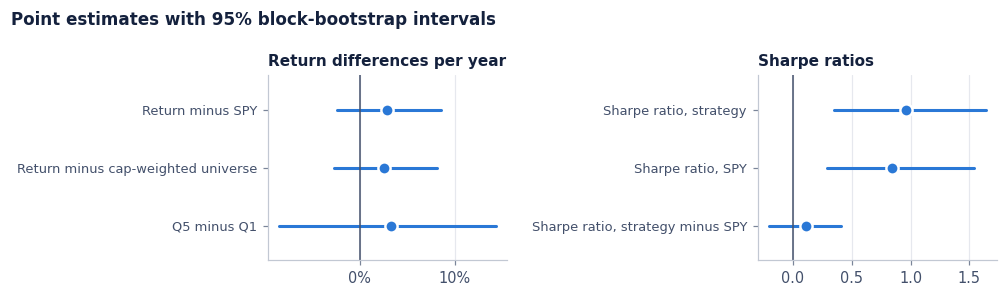


**Interpretation.** The strategy's average return relative to SPY is +2.87 pp per year with a 95% interval from -2.4 pp to +8.5 pp; 15% of the resampled decades show underperformance. The interval includes zero, so the lead over SPY is not statistically conclusive: ten years are not enough to tell a good strategy from a lucky one with confidence. The Sharpe-ratio difference is +0.115 (interval -0.206 to +0.414, including zero) and the Q5-minus-Q1 spread +3.29 pp (interval -8.6 pp to +14.4 pp, including zero). Block lengths of 3 or 12 months lead to the same reading for every statistic.


In [33]:
boot_frame = pd.DataFrame({"strategy": R[STRAT], "spy": R["SPY"], "rf": BT["rf"], "q1": R["Q1"], "universe": R["Universe"], "q5": R["Q5"]})
def _sharpe(x, col):
    ex = x[:, col] - x[:, 2]
    return math.sqrt(12.0) * ex.mean() / ex.std(ddof=1)
BOOT_STATS = {"Return minus SPY, p.a.": lambda x: 12.0 * (x[:, 0] - x[:, 1]).mean(),
              "Return minus cap-weighted universe, p.a.": lambda x: 12.0 * (x[:, 0] - x[:, 4]).mean(),
              "Q5 minus Q1, p.a.": lambda x: 12.0 * (x[:, 5] - x[:, 3]).mean(),
              "Sharpe ratio, strategy": lambda x: _sharpe(x, 0),
              "Sharpe ratio, SPY": lambda x: _sharpe(x, 1),
              "Sharpe ratio, strategy minus SPY": lambda x: _sharpe(x, 0) - _sharpe(x, 1)}
BOOT = block_bootstrap(boot_frame, BOOT_STATS, CFG.bootstrap_reps, CFG.bootstrap_block, CFG.seed)
BOOT_ALT = {b: block_bootstrap(boot_frame, BOOT_STATS, CFG.bootstrap_reps, b, CFG.seed) for b in (3, 12)}
show = BOOT.copy()
for b, t in BOOT_ALT.items():
    show[f"95% CI, block {b}"] = [f"{lo:+.3f} to {hi:+.3f}" for lo, hi in zip(t["ci_low"], t["ci_high"])]
display(savetable(show, "tab_bootstrap_intervals").rename(columns={"estimate": "Estimate", "ci_low": "95% CI low (block 6)", "ci_high": "95% CI high (block 6)",
        "share_below_zero": "Share of resamples below zero"}).style.format({"Estimate": "{:+.3f}", "95% CI low (block 6)": "{:+.3f}",
        "95% CI high (block 6)": "{:+.3f}", "Share of resamples below zero": "{:.0%}"}))

fig, axes = plt.subplots(1, 2, figsize=(9.2, 2.7), gridspec_kw={"width_ratios": [1, 1]})
for ax, rows, title, as_pct in ((axes[0], list(BOOT.index[:3]), "Return differences per year", True), (axes[1], list(BOOT.index[3:]), "Sharpe ratios", False)):
    for i, k in enumerate(rows[::-1]):
        ax.plot([BOOT.loc[k, "ci_low"], BOOT.loc[k, "ci_high"]], [i, i], color=BLUE, lw=2, solid_capstyle="round")
        ax.plot([BOOT.loc[k, "estimate"]], [i], marker="o", ms=8, color=BLUE, mec="white", mew=1.6)
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([k.replace(", p.a.", "") for k in rows[::-1]], fontsize=8.5)
    ax.axvline(0, color=INK2, lw=1); ax.grid(True, axis="x"); ax.grid(False, axis="y"); ax.set_ylim(-0.6, len(rows) - 0.4)
    ax.set_title(title, fontsize=10)
    if as_pct: percent_axis(ax, "x")
fig.suptitle("Point estimates with 95% block-bootstrap intervals", x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
plt.tight_layout(); savefig(fig, "fig_bootstrap_intervals")

b1, b3, b6 = BOOT.iloc[0], BOOT.iloc[2], BOOT.iloc[5]
excludes = lambda row: bool(row["ci_low"] > 0 or row["ci_high"] < 0)
flips = [f"{name} with {blk}-month blocks" for blk, tab in BOOT_ALT.items() for name in BOOT.index if excludes(tab.loc[name]) != excludes(BOOT.loc[name])]
say(f"""
**Interpretation.** The strategy's average return relative to SPY is {pp(b1['estimate'], 2)} per year with a 95% interval from {pp(b1['ci_low'])} to {pp(b1['ci_high'])}; {pct(b1['share_below_zero'], 0)} of the resampled decades show underperformance. The interval {pick(excludes(b1), 'excludes', 'includes')} zero, so the {pick(b1['estimate'] >= 0, 'lead over', 'shortfall against')} SPY is {pick(excludes(b1), 'unlikely to be chance alone', 'not statistically conclusive: ten years are not enough to tell a good strategy from a lucky one with confidence')}. The Sharpe-ratio difference is {b6['estimate']:+.3f} (interval {b6['ci_low']:+.3f} to {b6['ci_high']:+.3f}, {pick(excludes(b6), 'excluding', 'including')} zero) and the Q5-minus-Q1 spread {pp(b3['estimate'], 2)} (interval {pp(b3['ci_low'])} to {pp(b3['ci_high'])}, {pick(excludes(b3), 'excluding', 'including')} zero). {pick(len(flips) == 0, 'Block lengths of 3 or 12 months lead to the same reading for every statistic.', 'The reading is sensitive to the block length in one respect: zero moves in or out of the interval for ' + '; '.join(flips) + '. A result that depends on such a choice is borderline and should be treated as such.')}
""")

### 8.7 Skill or luck? A random-portfolio baseline

In a rising market almost any portfolio of large US stocks makes money. To see what the **momentum score** contributes, the strategy's rules are repeated 1,000 times with one change: at every rebalance the same number of stocks is drawn **at random** from the eligible universe and weighted by market value, instead of being chosen and tilted by score. Dates, weight limits and drift are identical. The comparison is made **before costs**: a random portfolio replaces almost all of its holdings at every rebalance, far more than the strategy with its buffer rule, so after costs the strategy would look better for a reason that has nothing to do with the score. If the score added value, the strategy should sit clearly in the upper tail of this distribution.

,Random portfolios: mean,5th percentile,95th percentile,Strategy,Strategy's percentile
Average return p.a. before costs,0.142,0.121,0.164,0.180,0.996
Sharpe ratio before costs,0.781,0.641,0.924,0.973,0.984


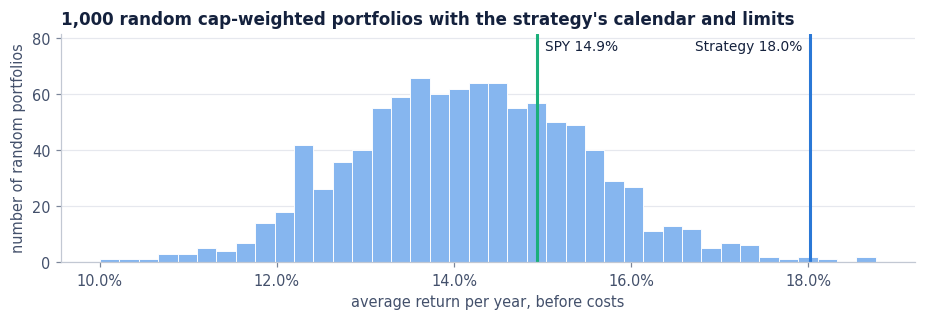


**Interpretation.** Random selection under the same rules earned 14.2% per year on average (5th to 95th percentile: 12.1% to 16.4%). That is below the cap-weighted universe's 15.3%: a random fifth of the stocks holds only some of the largest companies, and the weight limits cap those it holds. The strategy's 18.0% before costs is at the **99.6th percentile** of that distribution (+2.9 standard deviations from its mean); by Sharpe ratio it is at the 98.4th percentile. A selection rule with skill would be expected above the 95th percentile. The strategy clears that bar: choosing by momentum score did better than choosing at random in nearly all of the simulations. Read together with the other results, this needs care. The stock-level tests of section 7 find no relation between score and return for the average stock, and with equal weights the selection trails SPY (section 8.1). What the score did in this decade was to point, among the largest companies, to those that went on to do best; the result rests on few companies and few years. SPY's return is above 71% of the random portfolios.


In [34]:
RAND = random_portfolio_baseline(DATA, BT, CFG.random_portfolios, CFG.seed)
MG = BT["metrics_gross"]                                             # everything in this section is before costs
s_ret, s_sh = MG.loc[STRAT, "ann_return"], MG.loc[STRAT, "sharpe"]
pctile_ret = float((RAND["ann_return"] < s_ret).mean()); pctile_sh = float((RAND["sharpe"] < s_sh).mean())
z_ret = (s_ret - RAND["ann_return"].mean()) / RAND["ann_return"].std(ddof=1)
rand_table = pd.DataFrame({"Random portfolios: mean": RAND[["ann_return", "sharpe"]].mean(), "5th percentile": RAND[["ann_return", "sharpe"]].quantile(0.05),
                           "95th percentile": RAND[["ann_return", "sharpe"]].quantile(0.95), "Strategy": [s_ret, s_sh],
                           "Strategy's percentile": [pctile_ret, pctile_sh]}, index=["ann_return", "sharpe"]).rename(index={"ann_return": "Average return p.a. before costs", "sharpe": "Sharpe ratio before costs"})
display(savetable(rand_table, "tab_random_portfolio_baseline").style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(8.5, 3.0))
ax.hist(RAND["ann_return"], bins=40, color="#86b6ef", edgecolor="white", linewidth=0.6)
ymax = ax.get_ylim()[1] * 1.18; ax.set_ylim(0, ymax)
for value, text, color in ((s_ret, f"Strategy {pct(s_ret)}", BLUE), (MG.loc["SPY", "ann_return"], f"SPY {pct(MG.loc['SPY', 'ann_return'])}", TEAL)):
    ax.axvline(value, color=color, lw=2)
    left = value > ax.get_xlim()[0] + 0.8 * (ax.get_xlim()[1] - ax.get_xlim()[0])       # near the right edge: label on the left
    ax.annotate(text, (value, ymax), xytext=(-5 if left else 5, -4), textcoords="offset points", fontsize=9, color=INK,
                va="top", ha="right" if left else "left")
percent_axis(ax, "x", 1); ax.set_xlabel("average return per year, before costs"); ax.set_ylabel("number of random portfolios")
ax.set_title(f"{CFG.random_portfolios:,} random cap-weighted portfolios with the strategy's calendar and limits")
plt.tight_layout(); savefig(fig, "fig_random_portfolios")

spy_pct = float((RAND["ann_return"] < MG.loc["SPY", "ann_return"]).mean())
say(f"""
**Interpretation.** Random selection under the same rules earned {pct(RAND['ann_return'].mean())} per year on average (5th to 95th percentile: {pct(RAND['ann_return'].quantile(0.05))} to {pct(RAND['ann_return'].quantile(0.95))}). That is {pick(RAND['ann_return'].mean() < MG.loc['Universe', 'ann_return'], 'below', 'above')} the cap-weighted universe's {pct(MG.loc['Universe', 'ann_return'])}: a random fifth of the stocks holds only some of the largest companies, and the weight limits cap those it holds. The strategy's {pct(s_ret)} before costs is at the **{pctile_ret * 100:.1f}th percentile** of that distribution ({z_ret:+.1f} standard deviations from its mean); by Sharpe ratio it is at the {pctile_sh * 100:.1f}th percentile. A selection rule with skill would be expected above the 95th percentile. {pick(pctile_ret >= 0.95, 'The strategy clears that bar: choosing by momentum score did better than choosing at random in nearly all of the simulations.', 'The strategy does not clear that bar: in this sample, choosing by momentum score was not reliably better than choosing at random with the same weighting.')} Read together with the other results, this needs care. The stock-level tests of section 7 find no relation between score and return for the average stock, and with equal weights the selection trails SPY (section 8.1). What the score did in this decade was to point, among the largest companies, to those that went on to do best; the result rests on few companies and few years. SPY's return is above {pct(spy_pct, 0)} of the random portfolios.
""")

## 9. Sector exposure, implementation for a retail client, and risks

### 9.1 Sector exposure

A momentum portfolio buys whatever has gone up, and stocks of one sector tend to go up together, so part of what looks like stock selection can be a sector bet. This section compares the sector weights of the strategy with those of the cap-weighted universe it selects from, which is this notebook's stand-in for the S&P 500:

sector active weight = strategy sector weight − universe sector weight.

**Important restriction.** Yahoo Finance and the membership table only provide **today's** sector labels. A company that changed sector (several technology and media companies were moved to Communication Services in 2018, for example) carries its current label for the whole history. The analysis is therefore retrospective and descriptive; the labels are never used for a trading decision, and no sector-neutral variant of the strategy is built, because that would require reliable historical classifications.

In [35]:
# [engine] exported to the repo by tools/export_engine.py - see the README
YAHOO_TO_GICS = {"Technology": "Information Technology", "Financial Services": "Financials", "Healthcare": "Health Care",
                 "Consumer Cyclical": "Consumer Discretionary", "Consumer Defensive": "Consumer Staples",
                 "Basic Materials": "Materials", "Communication Services": "Communication Services", "Energy": "Energy",
                 "Industrials": "Industrials", "Real Estate": "Real Estate", "Utilities": "Utilities"}


def yahoo_sectors(symbols, workers=4, retries=2):
    """Today's Yahoo sector label per symbol, translated to GICS sector names. Best effort: a symbol whose profile
    cannot be read is left out and shows up as 'Unknown' in the tables instead of stopping the run."""
    from concurrent.futures import ThreadPoolExecutor

    def one(symbol):
        for attempt in range(retries + 1):
            try:
                return symbol, YAHOO_TO_GICS.get(yf.Ticker(symbol).info.get("sector"))
            except Exception:
                time.sleep(1.5 * (attempt + 1))
        return symbol, None

    with ThreadPoolExecutor(workers) as pool:
        found = {k: v for k, v in pool.map(one, list(symbols)) if v}
    DATA_LOG.append({"provider": "Yahoo Finance (yfinance " + yf.__version__ + ")", "query": f"sector of {len(symbols)} symbols",
                     "route": "yfinance.Ticker.info", "requested": "current classification", "returned": f"{len(found)} labels",
                     "rows": len(found), "retrieved_utc": dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d %H:%M")})
    return found


def sector_weights(targets, sector_of):
    """Portfolio weight per sector at each formation date. Names without a label are reported as 'Unknown'."""
    rows = {m: w.groupby([sector_of.get(t, "Unknown") for t in w.index]).sum() for m, w in targets.items() if len(w)}
    return pd.DataFrame(rows).T.fillna(0.0).sort_index()


def retail_example(weights, panel, month, capital, cost_rate, split_factor=None):
    """What buying one set of target weights on one trade date looks like for a given amount of capital.

    split_factor : per security, the product of all split factors after the trade date (see later_split_factor).
                   Yahoo restates past closing prices for later splits; multiplying by this factor gives the share
                   price that was actually quoted on the trade date.
    """
    names = list(weights.index)
    w = weights.to_numpy(dtype=float)
    v_net, trades, cost = solve_rebalance(float(capital), np.zeros(len(w)), w, cost_rate)
    price = panel["px_close"].loc[month, names]
    if split_factor is not None:
        price = price * split_factor.reindex(names).fillna(1.0)
    position = pd.Series(w * v_net, index=names)
    whole_shares = np.floor(position / price)
    adv = panel["adv"].loc[month, names]
    return {"holdings": len(names), "largest position": float(position.max()), "median position": float(position.median()),
            "smallest position": float(position.min()), "ten largest positions, share of capital": float(np.sort(w)[-10:].sum()),
            "initial cost": cost, "median share price": float(price.median()), "highest share price": float(price.max()),
            "positions smaller than one share": int((price > position).sum()),
            "uninvested with whole shares only": float(v_net - (whole_shares * price).sum()),
            "median daily dollar volume": float(adv.median()), "lowest daily dollar volume": float(adv.min())}

[cache] yahoo_sectors_91: reused the download of 2026-11-25 02:21 UTC
sector labels: 503 from the constituents table, 91 of 91 former members from Yahoo, 0 unknown


,Strategy average weight,Universe average weight,Average active weight,Lowest active weight,Highest active weight,Highest strategy weight
Consumer Discretionary,12.6%,10.7%,+2.0%,-10.3%,+23.5%,33.6%
Communication Services,11.9%,10.1%,+1.8%,-8.5%,+17.4%,27.3%
Financials,16.2%,15.5%,+0.7%,-15.0%,+18.4%,36.0%
Energy,4.0%,4.1%,-0.1%,-6.3%,+22.4%,26.5%
Utilities,2.7%,2.8%,-0.1%,-3.3%,+7.2%,10.6%
Industrials,9.1%,9.4%,-0.3%,-6.6%,+8.6%,17.5%
Real Estate,2.2%,2.5%,-0.4%,-2.7%,+4.2%,7.3%
Health Care,12.6%,13.0%,-0.4%,-12.0%,+18.5%,32.2%
Consumer Staples,7.7%,8.2%,-0.4%,-9.5%,+12.2%,21.2%
Materials,1.7%,2.1%,-0.5%,-1.8%,+1.8%,4.3%


Average sector weights of the five score quintiles, the strategy, the top-10% variant and the cap-weighted universe:


,Q1,Q2,Q3,Q4,Q5,Strategy,Top 10%,Universe
Communication Services,9.9%,5.9%,6.5%,7.3%,11.9%,11.9%,8.6%,10.1%
Consumer Discretionary,9.3%,9.2%,8.0%,10.4%,11.8%,12.6%,11.6%,10.7%
Consumer Staples,12.2%,8.9%,9.0%,8.8%,7.8%,7.7%,7.3%,8.2%
Energy,9.1%,8.4%,3.2%,2.2%,3.9%,4.0%,5.1%,4.1%
Financials,11.4%,16.4%,19.0%,18.7%,16.3%,16.2%,16.7%,15.5%
Health Care,16.0%,18.1%,15.5%,13.6%,12.9%,12.6%,13.1%,13.0%
Industrials,10.5%,9.5%,11.8%,13.1%,9.3%,9.1%,11.2%,9.4%
Information Technology,9.3%,13.2%,16.9%,18.5%,19.4%,19.4%,18.2%,21.6%
Materials,2.9%,2.7%,3.5%,2.5%,1.7%,1.7%,1.8%,2.1%
Real Estate,4.7%,3.8%,3.0%,2.3%,2.2%,2.2%,2.7%,2.5%


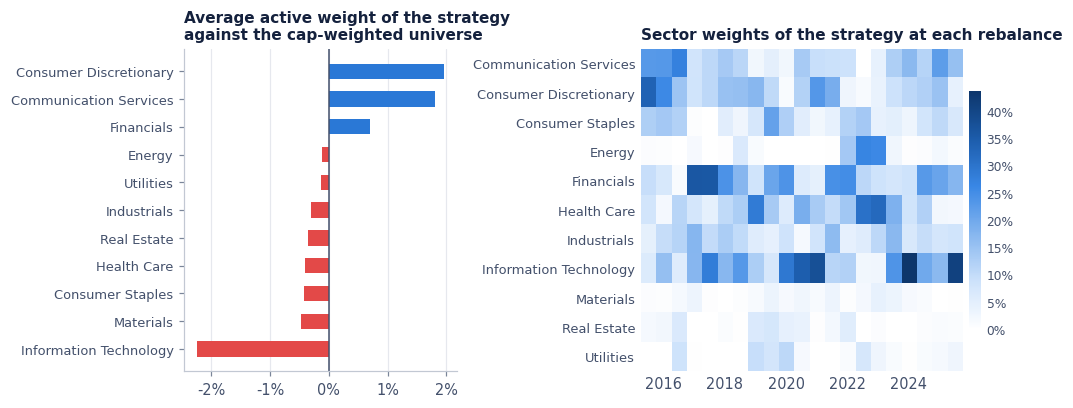


**What the sector tables show.** On average the strategy was most overweight in **Consumer Discretionary** (+2.0 pp against the universe) and most underweight in **Information Technology** (-2.3 pp). Averages hide the real behaviour, which is visible in the heatmap: the portfolio rotates. Its largest single sector position was 44% in March 2024 (Information Technology), and the largest sector held changed 12 times in 21 rebalances. Measured by the sum of squared sector weights, the strategy was more concentrated than the universe at 95% of the rebalances (average 0.183 against 0.133; an equal split over eleven sectors would give 0.091).

For the client this means that the strategy carries **changing sector bets that are a by-product of the rule, not a decision**: after a commodity rally it holds energy companies, after a technology rally technology companies. The index rules contain no sector limit. Sector risk is therefore higher than the number of holdings suggests. The weight labelled "Unknown" averages 0.0% of the portfolio.


In [36]:
# sector labels: GICS sector from the constituents table for today's members, Yahoo's label for former members
gics = {yahoo_symbol(clean_ticker(t)): sec for t, sec in zip(constituents_raw["Symbol"], constituents_raw["GICS Sector"])}
ever_eligible = sorted(set().union(*[set(FORMS[m].index) for m in REBALANCES]))
need = [t for t in ever_eligible if t not in gics]
former = cached(f"yahoo_sectors_{len(need)}", lambda: yahoo_sectors(need))
SECTOR = {**former, **gics}
print(f"sector labels: {len(gics)} from the constituents table, {len(former)} of {len(need)} former members from Yahoo, "
      f"{len(need) - len(former)} unknown")

W5 = sector_weights(BT["runs"][STRAT]["targets"], SECTOR)
WU = sector_weights(BT["runs"]["Universe"]["targets"], SECTOR)
cols = sorted(set(W5.columns) | set(WU.columns), key=lambda c: (c == "Unknown", c))
W5, WU = W5.reindex(columns=cols, fill_value=0.0), WU.reindex(columns=cols, fill_value=0.0)
ACTIVE = W5 - WU
SEC = pd.DataFrame({"Strategy average weight": W5.mean(), "Universe average weight": WU.mean(), "Average active weight": ACTIVE.mean(),
                    "Lowest active weight": ACTIVE.min(), "Highest active weight": ACTIVE.max(), "Highest strategy weight": W5.max()})
display(savetable(SEC, "tab_sector_exposure").sort_values("Average active weight", ascending=False).style.format("{:+.1%}", subset=["Average active weight", "Lowest active weight", "Highest active weight"]).format("{:.1%}", subset=["Strategy average weight", "Universe average weight", "Highest strategy weight"]))

by_q = pd.DataFrame({q: sector_weights(BT["runs"][q]["targets"], SECTOR).reindex(columns=cols, fill_value=0.0).mean() for q in QUINT})
by_q["Strategy"] = W5.mean()
by_q["Top 10%"] = sector_weights(BT_TOP10["runs"][BT_TOP10["strategy"]]["targets"], SECTOR).reindex(columns=cols, fill_value=0.0).mean()
by_q["Universe"] = WU.mean()
print("Average sector weights of the five score quintiles, the strategy, the top-10% variant and the cap-weighted universe:")
display(savetable(by_q, "tab_sector_weights_by_quintile").style.format("{:.1%}"))

known = [c for c in cols if c != "Unknown"]
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
a = SEC.loc[known, "Average active weight"].sort_values()
ax.barh(a.index, a.values, height=0.55, color=np.where(a.values >= 0, BLUE, RED))
ax.axvline(0, color=INK2, lw=1); ax.grid(True, axis="x"); ax.grid(False, axis="y"); percent_axis(ax, "x")
ax.set_title("Average active weight of the strategy\nagainst the cap-weighted universe", fontsize=10); ax.tick_params(axis="y", labelsize=8.5)
ax = axes[1]
heat = W5[known].T
im = ax.imshow(heat.to_numpy(), cmap=SEQ_BLUE, vmin=0, vmax=float(heat.to_numpy().max()), aspect="auto")
ax.set_yticks(range(len(known))); ax.set_yticklabels(known, fontsize=8.5)
ticks = [i for i, m in enumerate(heat.columns) if m.month == 3 and m.year % 2 == 0]
ax.set_xticks(ticks); ax.set_xticklabels([str(heat.columns[i].year) for i in ticks])
ax.grid(False); ax.tick_params(length=0)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02); cb.outline.set_visible(False)
cb.ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0)); cb.ax.tick_params(labelsize=8, length=0)
ax.set_title("Sector weights of the strategy at each rebalance", fontsize=10)
plt.tight_layout(); savefig(fig, "fig_sector_exposure")

top_sector = W5[known].idxmax(axis=1); top_weight = W5[known].max(axis=1)
hhi5, hhiu = (W5[known] ** 2).sum(axis=1), (WU[known] ** 2).sum(axis=1)
over, under = SEC.loc[known, "Average active weight"].idxmax(), SEC.loc[known, "Average active weight"].idxmin()
peak_m = top_weight.idxmax()
say(f"""
**What the sector tables show.** On average the strategy was most overweight in **{over}** ({pp(SEC.loc[over, 'Average active weight'])} against the universe) and most underweight in **{under}** ({pp(SEC.loc[under, 'Average active weight'])}). Averages hide the real behaviour, which is visible in the heatmap: the portfolio rotates. Its largest single sector position was {pct(top_weight.max(), 0)} in {peak_m.strftime('%B %Y')} ({top_sector[peak_m]}), and the largest sector held changed {int((top_sector != top_sector.shift()).sum() - 1)} times in {len(top_sector)} rebalances. Measured by the sum of squared sector weights, the strategy was more concentrated than the universe at {pct((hhi5 > hhiu).mean(), 0)} of the rebalances (average {hhi5.mean():.3f} against {hhiu.mean():.3f}; an equal split over eleven sectors would give 0.091).

For the client this means that the strategy carries **changing sector bets that are a by-product of the rule, not a decision**: after a commodity rally it holds energy companies, after a technology rally technology companies. The index rules contain no sector limit. Sector risk is therefore higher than the number of holdings suggests. The weight labelled "Unknown" averages {pct(SEC.loc['Unknown', 'Strategy average weight'] if 'Unknown' in SEC.index else 0.0)} of the portfolio.
""")

### 9.2 What this would look like for a retail client with USD 100,000

The table uses the **actual** holdings and weights of the latest rebalance in the sample, for the base case and for the top-10% variant, and the same cost engine as the backtest. The dollar amounts are an illustration of scale; they are not backtest results. Turnover and cost per year are the historical averages from section 8.1.

Share prices are the prices quoted on the trade date. Yahoo restates past prices whenever a stock splits later, so the splits since the trade date are undone; without that step a stock that split afterwards would look far cheaper than it was.

In [37]:
CAPITAL = 100_000
last_form = BT["formation_months"][-1]
form_day = PANEL["sessions"][last_form]
SPLIT_FACTOR = later_split_factor(DATA["splits"], form_day)
held_now = list(TARGETS[last_form].index)
restated = SPLIT_FACTOR.reindex(held_now).dropna(); restated = restated[restated != 1.0]
print(f"holdings of {form_day.date()} that split afterwards: {len(restated)}",
      {t: round(float(v), 4) for t, v in restated.items()} if len(restated) else "")
rows = {}
for label, bt_, key in (("Base case (top 20%)", BT, ("base case", BASE_LABEL)), ("Top 10%", BT_TOP10, ("selection", "Top 10%"))):
    ex_ = retail_example(bt_["runs"][bt_["strategy"]]["targets"][last_form], PANEL, last_form, CAPITAL, CFG.cost_rate, SPLIT_FACTOR)
    ex_["historical one-way turnover p.a."] = SENS.loc[key, "One-way turnover p.a."]
    ex_["historical trading cost p.a. (USD)"] = SENS.loc[key, "Cost p.a."] * CAPITAL
    ex_["historical orders per year"] = bt_["trading"].loc[bt_["strategy"], "orders_pa"]
    rows[label] = ex_
RETAIL = pd.DataFrame(rows)
money = ["largest position", "median position", "smallest position", "initial cost", "median share price", "highest share price",
         "uninvested with whole shares only", "historical trading cost p.a. (USD)", "median daily dollar volume", "lowest daily dollar volume"]
shown = RETAIL.copy().astype(object)
for r in RETAIL.index:
    for c in RETAIL.columns:
        v = RETAIL.loc[r, c]
        shown.loc[r, c] = (f"${v / 1e6:,.0f} million" if "dollar volume" in r else f"${v:,.0f}" if r in money
                           else f"{v:.0%}" if ("turnover" in r or "share of capital" in r) else f"{v:,.0f}")
print(f"Illustration for USD {CAPITAL:,} invested on {PANEL['sessions'][last_form].date()}")
savetable(RETAIL, "tab_retail_example")
display(shown)

base_r = RETAIL["Base case (top 20%)"]
n_frac = int(base_r["positions smaller than one share"])
ahead_net = M.loc[STRAT, "ann_return"] > M.loc["SPY", "ann_return"]
say(f"""
**Reading the illustration.**

* **Position sizes.** With USD {CAPITAL:,} the base portfolio holds {base_r['holdings']:.0f} positions that range from about USD {base_r['smallest position']:,.0f} to USD {base_r['largest position']:,.0f}; the median position is USD {base_r['median position']:,.0f}, and the ten largest take {base_r['ten largest positions, share of capital']:.0%} of the capital. {pick(n_frac == 0, 'No position is smaller than one share, but exact weights still require', f"{n_frac} position{pick(n_frac == 1, ' is', 's are')} smaller than the price of one share (the highest share price is USD {base_r['highest share price']:,.0f}) and cannot be bought at all without")} **fractional shares**: with whole shares only, about USD {base_r['uninvested with whole shares only']:,.0f} ({base_r['uninvested with whole shares only'] / CAPITAL:.0%} of the capital) would stay uninvested and the weights would be off. A broker that offers fractional shares and commission-free US stock trading is a practical requirement, and with much less capital the portfolio cannot be implemented as designed.
* **Trading effort.** At every rebalance the stocks that drop out are sold, new ones are bought, and the ones that stay are trimmed or topped up to their new weights. Historically that was about {base_r['historical orders per year']:.0f} orders per year, bundled on two dates. It is feasible with a spreadsheet and a broker that accepts basket orders, but it is not "set and forget".
* **Costs.** The initial purchase costs about USD {base_r['initial cost']:,.0f} and recurring trading about USD {base_r['historical trading cost p.a. (USD)']:,.0f} per year at 10 bp per dollar traded. For S&P 500 stocks this is a reasonable assumption for the bid-ask spread a small investor pays; the least liquid holding still traded about USD {base_r['lowest daily dollar volume'] / 1e6:,.0f} million per day, so an order of this size has no price impact. Section 8.1 shows the results at 25 and 50 bp for a less favourable broker.
* **Taxes (not modelled).** Selling winners twice a year realises gains. For a taxable US investor positions held for six or twelve months produce mostly short-term capital gains, taxed at ordinary income rates, and wash-sale rules limit the use of losses when a stock is bought back within 30 days. An index fund defers almost all capital gains until it is sold. After tax, {pick(ahead_net, 'the lead over SPY would be smaller than shown in this notebook', 'the gap to SPY would be wider than shown in this notebook')}; the strategy fits a tax-advantaged account (IRA, 401(k)) far better than a taxable one.
* **A fund on the same index exists.** The Invesco S&P 500 Momentum ETF (SPMO) follows the index whose rules this strategy applies, for a fee of 0.13% per year. It needs no fractional shares and no rebalancing by the investor, and it does not realise gains in the investor's account at each rebalance. Holding the stocks directly, as described here, gives the investor control over each position and avoids the fund fee, at the price of the effort, costs and taxes above.
* **Concentration.** The top-10% variant needs only {RETAIL.loc['holdings', 'Top 10%']:.0f} positions but puts {RETAIL.loc['ten largest positions, share of capital', 'Top 10%']:.0%} of the capital into its ten largest, with visibly higher volatility (section 8.1).
""")

holdings of 2025-09-30 that split afterwards: 5 {'NFLX': 10.0, 'CRWD': 4.0, 'APH': 2.0, 'BKNG': 25.0, 'CTVA': 6.665}
Illustration for USD 100,000 invested on 2025-09-30


,Base case (top 20%),Top 10%
holdings,98,49
largest position,"$9,196","$10,193"
median position,$357,$922
smallest position,$69,$145
"ten largest positions, share of capital",59%,66%
initial cost,$100,$100
median share price,$163,$162
highest share price,"$5,399","$5,399"
positions smaller than one share,20,4
uninvested with whole shares only,"$11,877","$7,139"



**Reading the illustration.**

* **Position sizes.** With USD 100,000 the base portfolio holds 98 positions that range from about USD 69 to USD 9,196; the median position is USD 357, and the ten largest take 59% of the capital. 20 positions are smaller than the price of one share (the highest share price is USD 5,399) and cannot be bought at all without **fractional shares**: with whole shares only, about USD 11,877 (12% of the capital) would stay uninvested and the weights would be off. A broker that offers fractional shares and commission-free US stock trading is a practical requirement, and with much less capital the portfolio cannot be implemented as designed.
* **Trading effort.** At every rebalance the stocks that drop out are sold, new ones are bought, and the ones that stay are trimmed or topped up to their new weights. Historically that was about 272 orders per year, bundled on two dates. It is feasible with a spreadsheet and a broker that accepts basket orders, but it is not "set and forget".
* **Costs.** The initial purchase costs about USD 100 and recurring trading about USD 205 per year at 10 bp per dollar traded. For S&P 500 stocks this is a reasonable assumption for the bid-ask spread a small investor pays; the least liquid holding still traded about USD 62 million per day, so an order of this size has no price impact. Section 8.1 shows the results at 25 and 50 bp for a less favourable broker.
* **Taxes (not modelled).** Selling winners twice a year realises gains. For a taxable US investor positions held for six or twelve months produce mostly short-term capital gains, taxed at ordinary income rates, and wash-sale rules limit the use of losses when a stock is bought back within 30 days. An index fund defers almost all capital gains until it is sold. After tax, the lead over SPY would be smaller than shown in this notebook; the strategy fits a tax-advantaged account (IRA, 401(k)) far better than a taxable one.
* **A fund on the same index exists.** The Invesco S&P 500 Momentum ETF (SPMO) follows the index whose rules this strategy applies, for a fee of 0.13% per year. It needs no fractional shares and no rebalancing by the investor, and it does not realise gains in the investor's account at each rebalance. Holding the stocks directly, as described here, gives the investor control over each position and avoids the fund fee, at the price of the effort, costs and taxes above.
* **Concentration.** The top-10% variant needs only 49 positions but puts 66% of the capital into its ten largest, with visibly higher volatility (section 8.1).


### 9.3 Risk and bias audit

Each row states what the risk or bias is, which way it is likely to push the results, what was done about it, how that was checked, and how much of it remains. "Eliminated" is only claimed where a test demonstrates it.

In [38]:
t5 = BT["trading"].loc[STRAT]
first_back = float(SEL["weight on carried-back share counts"].iloc[0]); later_back = float(SEL["weight on carried-back share counts"].iloc[1:].max())
audit = [
 ("Equity market risk (beta)", "The portfolio falls when the market falls.",
  f"Beta of {num(M.loc[STRAT, 'beta'])} against SPY: full equity exposure.", "None by design: no cash, bond or hedging overlay.",
  "Regression in section 6.2; drawdowns in 6.3; falling markets in 8.3.", "High. Inherent in a long-only equity strategy."),
 ("Single-stock concentration", "A few very large positions dominate the result.",
  f"About {t5['avg_holdings']:.0f} holdings, but the ten largest make up {pct(SEL['ten largest weights'].mean(), 0)} on average; effective number of holdings {t5['avg_effective_holdings']:.0f}; largest weight reached {pct(t5['max_weight'])}.",
  "Index rule: at most 9% per stock when the weights are set (reference date). Weights drift above it afterwards.",
  "Section 6.4; variants without limits and with equal weights in 8.1.", "High. The main risk that is specific to this strategy."),
 ("Result driven by few years and few companies", f"{pct(late_share, 0)} of the final lead over the index (measured in logs) was earned in the last two of the ten years.",
  f"One dollar in the strategy was worth {pick(lead_to_2023 >= 0, f'{lead_to_2023:.0%} more', f'{-lead_to_2023:.0%} less')} than one dollar in SPY at the end of 2023 and {pick(lead_total >= 0, f'{lead_total:.0%} more', f'{-lead_total:.0%} less')} at the end of 2025.",
  "Nothing: it is a property of the rule in this decade.", "Sub-periods and calendar years in sections 6.4 and 8.3; equal-weight variant in 8.1.",
  "High. Past performance of this kind is not a reliable guide to future performance."),
 ("Momentum reversals and crashes", "Past winners lag sharply when market leadership turns, typically in rebounds after a decline.",
  f"Lowers returns in rebound months; worst month of the highest-score against the lowest-score quintile {pp(wl.min())}.", "Long-only and unlevered, so there is no short leg that can lose more than 100%; this limits, but does not remove, the effect.",
  "Worst-month table in section 7; episodes in 8.3.", "High. Leveraged long-short momentum is hit harder, but the long-only version can still lag."),
 ("Market stress and drawdowns", "Large temporary losses that a client must sit through.",
  f"Maximum drawdown {pct(M.loc[STRAT, 'max_drawdown'])} at month-ends; longest time below a previous peak {int(drawdown_episodes(NAV[STRAT], top=50)['months under water'].max())} months.",
  "None by design.", "Section 6.3. Intra-month losses were larger than month-end figures show.", "High."),
 ("Sector concentration", "Winners cluster in sectors; the portfolio becomes a sector bet.",
  f"Largest sector weight reached {pct(top_weight.max(), 0)}.", "None: the index rules have no sector limit.", "Section 9.1, with today's labels only.", "Medium to high."),
 ("Liquidity and market impact", "Orders move prices when they are large relative to trading volume.",
  "Negligible for a retail account in S&P 500 stocks; relevant for large funds.", "Universe restricted to S&P 500 members.",
  "Daily dollar volume of the holdings in section 9.2.", "Low for the target client."),
 ("Turnover, bid-ask spreads, transaction costs", "Trading costs reduce net returns.",
  f"{pct(t5['one_way_turnover_pa'], 0)} one-way turnover per year, {pct(t5['cost_pa'], 2)} cost per year at 10 bp.", "Costs charged on every dollar traded, including the first purchase; two rebalances per year; buffer rule.",
  "Exact cost tests in section 11; sensitivity up to 50 bp in 8.1; break-even cost in 8.2.", "Low to medium. The true cost for a particular broker is unknown."),
 ("Taxes", "Realised short-term gains are taxed every year.", "Would lower after-tax returns relative to a buy-and-hold fund.", "Not modelled; discussed qualitatively.",
  "Not tested.", "High for taxable accounts."),
 ("Survivorship bias", "Companies that were later acquired or failed are missing from Yahoo Finance, so the universe is tilted towards survivors.",
  f"Probably overstates stock-portfolio returns by roughly {pp(bias)} per year; SPY and SPMO are not affected. Likely flatters the low-score quintiles more than the strategy.",
  "Point-in-time index membership; reused tickers blocked.",
  f"Coverage table (section 3.3); cap-weighted universe against SPY (5.2): {pp(uni['Difference p.a.'], 2)} per year; the real fund, which has no such bias, earned {pct(rep['Fund, return p.a.'])}.", "Medium. Measured at universe level, not removed."),
 ("Look-ahead bias", "Using information that was not available on the trade date.", "Would inflate returns.",
  f"Every input is dated at least one month before the trade; membership by effective date; risk-free rate lagged; returns start the month after the trade. Three stated exceptions concern share counts (section 2): the unit of a count near a stock split is read with the help of the stock's other counts, later ones included; the count before Yahoo's outage is left out; and a stock's first count is carried back up to {CFG.share_carry_back_days} days ({pct(first_back, 0)} of the weight at the first purchase, at most {pct(later_back)} afterwards).",
  "Test that rewrites all future prices and share counts and checks that earlier decisions and values are unchanged (section 11.1); rebuild of every share count used from the counts reported by the reference date (11.2); variants of the share-count rules in 8.1.", "Low for the trading rule. The price-availability filter itself depends on the future (see survivorship)."),
 ("Quality of the market values", "Yahoo's share counts are total shares, per company, filed under the ticker of the time, with unit errors near stock splits, a general gap in 2017-18 and a history that starts in 2015.",
  "Weights differ from the index's float-adjusted weights; some index members cannot be ranked for lack of a share count; a wrong count that Yahoo repeats is accepted.",
  "Six stated rules (section 2); former tickers of renamed companies mapped (3.1); every unranked member is logged.",
  f"Evidence for each rule and largest companies in 3.2; cap-weighted universe against SPY: correlation {uni['Correlation of monthly returns']:.4f} (5.2); the data variants in 8.1 move the return by at most {data_span * 100:.2f} percentage points.", "Medium."),
 ("The backtest is not the index", "Month-end instead of third-Friday trades, total instead of float-adjusted market values, missing companies.",
  f"Before costs the backtest differs from the real fund by {pp(rep['Difference p.a.'], 2)} per year on average and by up to {pp(years['Difference'].abs().max(), 1)} in a single year.",
  "Every departure from the index rules is listed in section 4.5.", "Comparison with SPMO in section 5.2.", "Medium. The fund's record is the more reliable figure."),
 ("Selection of the universe", "Choosing stocks with hindsight.", "Would inflate returns.", "Universe defined by an external rule (index membership at each date), not by the authors.",
  "Membership replay checks in section 3.4.", "Low."),
 ("Missing data", "Gaps in prices silently change the sample.", "Direction unknown.", "No forward-filling for signals; every exclusion logged with its reason; the engine stops on an unexplained missing return.",
  "Quality gates in section 3.4; exclusion log saved with the outputs.", "Low for the stocks that are in the data."),
 ("Corporate actions", "Splits, dividends, spin-offs and mergers distort prices if not adjusted.", "Could create false extreme returns and false signals.",
  f"Yahoo's adjusted close for returns, except on {int(ADJ_REPAIRS['decision'].str.startswith('close return used').sum())} days where Yahoo counts a spin-off twice (rule in section 2); ticker changes mapped by hand and documented. The signal uses the close, which is not adjusted for special cash dividends.",
  "Every day with both a split factor and a dividend is listed in section 3; extreme-return table in section 11.", "Low to medium. Spin-offs that Yahoo values wrongly without a double record are not caught."),
 ("Model and parameter risk", "The rule's settings (12 months, top fifth, 9% limit, half-yearly) could be lucky choices.", "Direction unknown.",
  "The settings are those of a published index that was launched before the sample; one-at-a-time sensitivities reported in full.", "Section 8.1.", "Medium."),
 ("In-sample selection and data snooping", "Choosing a rule because it did well in the sample, or trying many variants and reporting the best.", "Overstates the evidence: the return shown is in-sample.",
  f"The rule set is a published index's and was not fitted here. It was, however, chosen for this project with knowledge of the sample period. All {len(SENS)} variants are reported and none is promoted.",
  "Variant log in section 8.1; the fund's live record in 5.2.", "Medium to high. The backtest is not an out-of-sample test, and momentum is one of the most searched patterns in finance."),
 ("Short sample", "Ten years contain few independent market regimes.", "Wide confidence intervals in both directions.",
  "Block bootstrap; random-portfolio baseline; Monte Carlo with recession regimes.", "Sections 8.6, 8.7 and 10.", "High. Not fixable with more computation."),
]
AUDIT = pd.DataFrame(audit, columns=["Risk or bias", "What it is", "Likely effect here", "What was done", "How it was checked", "What remains"]).set_index("Risk or bias")
savetable(AUDIT, "tab_risk_and_bias_audit")
display(AUDIT.style.set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top", "font-size": "9pt"}).set_table_styles(
    [{"selector": "th", "props": [("text-align", "left"), ("vertical-align", "top")]}]))

,What it is,Likely effect here,What was done,How it was checked,What remains
Risk or bias,,,,,
Equity market risk (beta),The portfolio falls when the market falls.,Beta of 0.95 against SPY: full equity exposure.,"None by design: no cash, bond or hedging overlay.",Regression in section 6.2; drawdowns in 6.3; falling markets in 8.3.,High. Inherent in a long-only equity strategy.
Single-stock concentration,A few very large positions dominate the result.,"About 90 holdings, but the ten largest make up 53% on average; effective number of holdings 26; largest weight reached 13.5%.",Index rule: at most 9% per stock when the weights are set (reference date). Weights drift above it afterwards.,Section 6.4; variants without limits and with equal weights in 8.1.,High. The main risk that is specific to this strategy.
Result driven by few years and few companies,93% of the final lead over the index (measured in logs) was earned in the last two of the ten years.,One dollar in the strategy was worth 2% more than one dollar in SPY at the end of 2023 and 30% more at the end of 2025.,Nothing: it is a property of the rule in this decade.,Sub-periods and calendar years in sections 6.4 and 8.3; equal-weight variant in 8.1.,High. Past performance of this kind is not a reliable guide to future performance.
Momentum reversals and crashes,"Past winners lag sharply when market leadership turns, typically in rebounds after a decline.",Lowers returns in rebound months; worst month of the highest-score against the lowest-score quintile -17.9 pp.,"Long-only and unlevered, so there is no short leg that can lose more than 100%; this limits, but does not remove, the effect.",Worst-month table in section 7; episodes in 8.3.,"High. Leveraged long-short momentum is hit harder, but the long-only version can still lag."
Market stress and drawdowns,Large temporary losses that a client must sit through.,Maximum drawdown -23.1% at month-ends; longest time below a previous peak 26 months.,None by design.,Section 6.3. Intra-month losses were larger than month-end figures show.,High.
Sector concentration,Winners cluster in sectors; the portfolio becomes a sector bet.,Largest sector weight reached 44%.,None: the index rules have no sector limit.,"Section 9.1, with today's labels only.",Medium to high.
Liquidity and market impact,Orders move prices when they are large relative to trading volume.,Negligible for a retail account in S&P 500 stocks; relevant for large funds.,Universe restricted to S&P 500 members.,Daily dollar volume of the holdings in section 9.2.,Low for the target client.
"Turnover, bid-ask spreads, transaction costs",Trading costs reduce net returns.,"102% one-way turnover per year, 0.20% cost per year at 10 bp.","Costs charged on every dollar traded, including the first purchase; two rebalances per year; buffer rule.",Exact cost tests in section 11; sensitivity up to 50 bp in 8.1; break-even cost in 8.2.,Low to medium. The true cost for a particular broker is unknown.
Taxes,Realised short-term gains are taxed every year.,Would lower after-tax returns relative to a buy-and-hold fund.,Not modelled; discussed qualitatively.,Not tested.,High for taxable accounts.


## 10. Monte Carlo: what range of outcomes should the client expect?

The backtest shows **one** path: the decade that happened. A client deciding today faces a decade that has not happened yet. This section simulates 10,000 possible ten-year paths for USD 100,000 invested in the strategy and in the index fund, and reports the spread of outcomes, the probability of a loss and the probability of ending behind the index.

A simulation is only as good as its design (Lecture 5: no number of paths fixes a wrong model). The design decisions are therefore stated one by one, each with its reason.

| # | Design decision | Choice | Why |
|---|---|---|---|
| 1 | Does the return distribution change over time? | Yes: two states of the economy, **expansion** and **recession**, month by month (NBER indicator `USREC` from FRED) | Compounding the portfolio at one constant rate, or drawing every month from one unchanging distribution, ignores that equity returns are much worse and more volatile in recessions. This is the same objection Lecture 5 raises against growing a company's EBITDA at a constant rate: the driver should vary with the state of the economy. |
| 2 | How does the state evolve? | **Markov chain**: next month's state depends on this month's, with transition probabilities estimated from the data | An independent coin flip each month (same long-run share of recession months) scatters recession months randomly through the decade. Real recessions arrive in **clumps** of consecutive months. Clumping matters to an investor: losses that come in a row compound into deep drawdowns, a scattered sequence does not. Both designs are run below so the difference is visible. |
| 3 | Which data for the transition probabilities? | Post-war months, January 1947 to December 2025 | Long enough to contain twelve recessions; pre-war cycles (gold standard, no deposit insurance) were longer and more frequent and are shown only as a sensitivity. |
| 4 | Returns within a state | Drawn with replacement from the **actual** monthly S&P 500 total-return excess returns observed in that state, 1988 to 2025 | Keeps the fat tails and skewness of real returns without assuming a normal distribution. 1988 is the first year of the total-return index on Yahoo Finance. |
| 5 | The strategy's return | Market model from the backtest: risk-free + alpha + beta × market excess return + a residual drawn from the backtest's regression residuals | The strategy has only ten years of history and two recession months, far too few to estimate its recession behaviour directly. The market is the channel through which the economy reaches the strategy; alpha, beta and the residuals carry what is specific to it. |
| 6 | Alpha | Two scenarios: the historical estimate, and zero | The historical alpha is an estimate from ten years with a wide confidence interval (section 6.2), and most of it was earned in two of those years (section 8.3), so both are shown. |
| 7 | Risk-free rate | Constant at the last observed 3-month Treasury yield | Simplification; the rate matters little next to equity risk. |
| 8 | Starting state | Drawn from the long-run share of recession months | Equivalent to the burn-in used in Lecture 5: the result does not depend on where the economy stands today. |
| 9 | Size | 10,000 paths of 120 months, seed 2270 | Monte Carlo error falls with 1/√paths; at 10,000 paths a probability of 10% is estimated to within about ±0.6 percentage points. |

The recession indicator is published by the NBER long after the fact. It is used here only to simulate plausible futures, never for a trading decision.

In [39]:
# [engine] exported to the repo by tools/export_engine.py - see the README
def transition_matrix(states):
    """2x2 matrix of observed month-to-month transition frequencies; state 0 = expansion, 1 = recession."""
    s = np.asarray(states, dtype=int)
    counts = np.zeros((2, 2))
    np.add.at(counts, (s[:-1], s[1:]), 1.0)
    return counts / counts.sum(axis=1, keepdims=True)


def long_run_recession_share(tm):
    """Stationary probability of the recession state of a two-state Markov chain."""
    return tm[0, 1] / (tm[0, 1] + tm[1, 0])


def simulate_states(tm, n_paths, n_steps, rng, markov=True):
    """Simulated state paths. markov=True: next state depends on the current one (recessions clump).
    markov=False: every month is an independent draw with the same long-run recession share (the coin flip)."""
    share = long_run_recession_share(tm)
    s = np.empty((n_paths, n_steps), dtype=np.int8)
    s[:, 0] = rng.random(n_paths) < share
    for t in range(1, n_steps):
        p_recession = tm[s[:, t - 1], 1] if markov else share
        s[:, t] = rng.random(n_paths) < p_recession
    return s


def recession_spells(states):
    """Lengths of the runs of consecutive recession months in a 0/1 sequence."""
    s = np.asarray(states, dtype=int)
    edges = np.diff(np.concatenate([[0], s, [0]]))
    return np.flatnonzero(edges == -1) - np.flatnonzero(edges == 1)


def simulate_wealth(states, market_pools, alpha_m, beta, residuals, rf_m, start_value, rng):
    """Wealth paths for the benchmark and the strategy given simulated states.

    market_pools : {0: array, 1: array} of historical monthly market excess returns in each state
    strategy return = rf + alpha + beta * market excess return + resampled regression residual
    """
    market = np.empty(states.shape)
    for state in (0, 1):
        mask = states == state
        market[mask] = rng.choice(market_pools[state], size=int(mask.sum()), replace=True)
    eps = rng.choice(residuals, size=states.shape, replace=True)
    r_bench = rf_m + market
    r_strat = rf_m + alpha_m + beta * market + eps
    return {"benchmark": start_value * np.cumprod(1.0 + r_bench, axis=1),
            "strategy": start_value * np.cumprod(1.0 + r_strat, axis=1)}


def path_statistics(wealth, start_value):
    """Summary of simulated wealth paths (one row per path, one column per month)."""
    w = np.concatenate([np.full((wealth.shape[0], 1), float(start_value)), wealth], axis=1)
    worst = (w / np.maximum.accumulate(w, axis=1) - 1.0).min(axis=1)
    final = w[:, -1]
    years = wealth.shape[1] / 12.0
    out = {"mean final value": final.mean(), "median final value": np.median(final),
           "5th percentile": np.percentile(final, 5), "25th percentile": np.percentile(final, 25),
           "75th percentile": np.percentile(final, 75), "95th percentile": np.percentile(final, 95),
           "median growth rate p.a.": (np.median(final) / start_value) ** (1.0 / years) - 1.0,
           "probability of a loss at the horizon": float((final < start_value).mean()),
           "median worst drawdown": float(np.median(worst)),
           "probability of a drawdown worse than 30%": float((worst <= -0.30).mean()),
           "probability of a drawdown worse than 50%": float((worst <= -0.50).mean())}
    for y in (1, 3):
        if wealth.shape[1] >= 12 * y:
            out[f"probability of a loss after {y} year{'s' if y > 1 else ''}"] = float((w[:, 12 * y] < start_value).mean())
    return out

### 10.1 Estimating the ingredients

In [40]:
# ---- states of the economy (FRED USREC, monthly) ----
rec = usrec.dropna().astype(int); rec.index = rec.index.to_period("M")
rec_post = rec.loc[P(CFG.mc_regime_start):P("2025-12")]
TM = transition_matrix(rec_post.to_numpy())
SHARE = long_run_recession_share(TM)
tm_table = pd.DataFrame(TM, index=["expansion this month", "recession this month"], columns=["expansion next month", "recession next month"])
print(f"Transition probabilities, {rec_post.index[0]} to {rec_post.index[-1]} ({len(rec_post)} months, {int(rec_post.sum())} recession months):")
display(savetable(tm_table, "tab_mc_transition_matrix").style.format("{:.3f}"))

# ---- market returns by state (Yahoo ^SP500TR, total return) ----
mkt_raw = cached(f"yahoo_{CFG.market_index.strip('^')}", lambda: yahoo_daily([CFG.market_index], "1987-12-01", CFG.data_end_exclusive))
mkt_adj = mkt_raw["adj"][CFG.market_index].dropna()
mkt_sessions = month_end_sessions(mkt_adj.index)
mkt_px = mkt_adj.reindex(mkt_sessions.values); mkt_px.index = mkt_sessions.index
mkt_ret = (mkt_px / mkt_px.shift(1) - 1.0).dropna()
mkt_rf = monthly_rf(dgs3mo, mkt_sessions)
MKT = pd.DataFrame({"ret": mkt_ret, "rf": mkt_rf, "state": rec}).dropna().loc[:P("2025-12")]
MKT["excess"] = MKT["ret"] - MKT["rf"]
POOLS = {0: MKT.loc[MKT["state"] == 0, "excess"].to_numpy(), 1: MKT.loc[MKT["state"] == 1, "excess"].to_numpy()}
print(f"\nS&P 500 total-return index: {len(MKT)} monthly returns, {MKT.index[0]} to {MKT.index[-1]} "
      f"(check: {MKT['ret'].isna().sum()} missing, average {pct(12 * MKT['ret'].mean())} p.a., volatility {pct(math.sqrt(12) * MKT['ret'].std())})")
by_state = pd.DataFrame({name: {"months": len(x), "share of months": len(x) / len(MKT), "average excess return p.a.": 12 * x.mean(),
                                "volatility p.a.": math.sqrt(12) * x.std(ddof=1), "average month": x.mean(), "worst month": x.min(), "best month": x.max(),
                                "months with a loss": float((x < 0).mean())}
                         for name, x in (("expansion", POOLS[0]), ("recession", POOLS[1]))})
display(savetable(by_state, "tab_mc_market_by_state").T.style.format({"months": "{:.0f}", "share of months": "{:.1%}", "average excess return p.a.": "{:+.1%}",
        "volatility p.a.": "{:.1%}", "average month": "{:+.2%}", "worst month": "{:+.1%}", "best month": "{:+.1%}", "months with a loss": "{:.0%}"}))

# ---- the strategy's link to the market: backtest regression (section 6.2) ----
ALPHA_M, BETA, RESID = MM["alpha_monthly"], MM["beta"], MM["resid"].to_numpy()
RF_M = (1 + dgs3mo.dropna().iloc[-1] / 100) ** (1 / 12) - 1
print(f"\nStrategy inputs: alpha {pct(12 * ALPHA_M)} p.a. (t = {num(MM['alpha_t'])}), beta {num(BETA)}, residual volatility {pct(MM['resid_vol'])} p.a., "
      f"{len(RESID)} residuals; risk-free rate held at {dgs3mo.dropna().iloc[-1]:.2f}% p.a.")

Transition probabilities, 1947-01 to 2025-12 (948 months, 124 recession months):


,expansion next month,recession next month
expansion this month,0.985,0.015
recession this month,0.097,0.903


[cache] yahoo_SP500TR: reused the download of 2026-11-25 02:21 UTC

S&P 500 total-return index: 455 monthly returns, 1988-02 to 2025-12 (check: 0 missing, average 11.9% p.a., volatility 14.6%)


,months,share of months,average excess return p.a.,volatility p.a.,average month,worst month,best month,months with a loss
expansion,419,92.1%,+10.7%,13.4%,+0.89%,-14.9%,+11.1%,35%
recession,36,7.9%,-12.4%,24.1%,-1.03%,-16.9%,+12.8%,50%



Strategy inputs: alpha 3.5% p.a. (t = 1.35), beta 0.95, residual volatility 7.6% p.a., 120 residuals; risk-free rate held at 3.67% p.a.


### 10.2 Coin flip or Markov chain? The design decision made visible

The three strips below show recession months (dark) in the actual post-war record, in one simulated history from the Markov chain, and in one simulated history from an independent coin flip with the **same** long-run share of recession months.

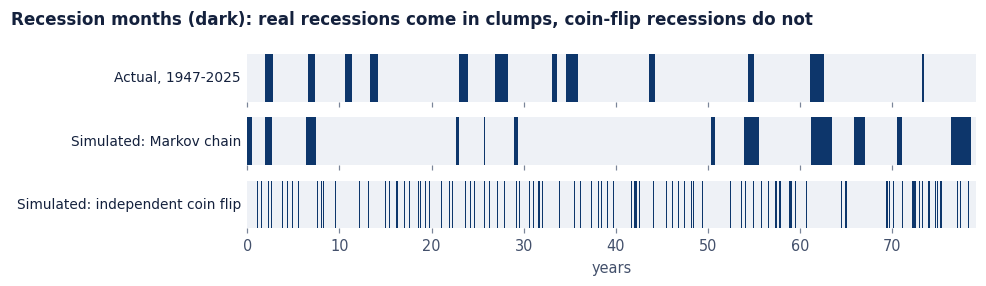

Recessions in the post-war record: 12, the longest 18 months. Simulated columns: 240,000 months each.


,Actual post-war record,Markov chain,Independent coin flip
share of recession months,13%,13%,13%
average length of a recession (months),10.3,10.3,1.1
median length (months),10.0,7.0,1.0
share of recessions lasting 6 months or more,92%,60%,0%
share of recessions lasting 2 months or less,8%,19%,98%



**The choice.** Both designs produce the same share of recession months (13.1% in the long run) and therefore the same average return. They differ in **how the bad months are arranged**. In the post-war record a recession lasted 10.3 months on average. The Markov chain reproduces that (10.3 months), because a recession month is followed by another one with probability 90%. With a coin flip a "recession" lasts 1.1 months on average and 0% of them last half a year or more, against 92% in reality. **The Markov chain is therefore the base design**; the coin flip is run alongside to show how much the choice matters for the client's risk figures.

**What the Markov chain still misses.** A two-state chain has no memory beyond the current month, so the length of its recessions follows a geometric distribution: the average is right, but it produces too many very short recessions (19% last two months or less, against 8% in the record) and correspondingly more very long ones. A model in which the chance of recovery rises with the age of the recession would fit better. The simple chain is kept because it is transparent, has only two parameters, and already removes most of the error of the coin flip.


In [41]:
rng_demo = np.random.default_rng(CFG.seed)
n_hist = len(rec_post)
demo_markov = simulate_states(TM, 1, n_hist, rng_demo, markov=True)[0]
demo_coin = simulate_states(TM, 1, n_hist, rng_demo, markov=False)[0]
fig, axes = plt.subplots(3, 1, figsize=(9.0, 2.6), sharex=True)
for ax, seq, title in ((axes[0], rec_post.to_numpy(), f"Actual, {rec_post.index[0].year}-{rec_post.index[-1].year}"),
                       (axes[1], demo_markov, "Simulated: Markov chain"), (axes[2], demo_coin, "Simulated: independent coin flip")):
    ax.imshow(seq[None, :], cmap=LinearSegmentedColormap.from_list("rec", ["#eef1f6", "#0d366b"]), aspect="auto", vmin=0, vmax=1,
              extent=[0, n_hist / 12, 0, 1], interpolation="nearest")
    ax.set_yticks([]); ax.grid(False); ax.set_ylabel(title, rotation=0, ha="right", va="center", fontsize=9, color=INK)
    for sp in ax.spines.values(): sp.set_visible(False)
axes[2].set_xlabel("years")
fig.suptitle("Recession months (dark): real recessions come in clumps, coin-flip recessions do not", x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
plt.tight_layout(); savefig(fig, "fig_mc_recession_clumping")

long_m = simulate_states(TM, 1, 240_000, np.random.default_rng(CFG.seed + 1), markov=True)[0]
long_c = simulate_states(TM, 1, 240_000, np.random.default_rng(CFG.seed + 2), markov=False)[0]
hist_sp, m_sp, c_sp = recession_spells(rec_post.to_numpy()), recession_spells(long_m), recession_spells(long_c)
clump = pd.DataFrame({"Actual post-war record": [rec_post.mean(), hist_sp.mean(), float(np.median(hist_sp)), float((hist_sp >= 6).mean()), float((hist_sp <= 2).mean())],
                      "Markov chain": [long_m.mean(), m_sp.mean(), float(np.median(m_sp)), float((m_sp >= 6).mean()), float((m_sp <= 2).mean())],
                      "Independent coin flip": [long_c.mean(), c_sp.mean(), float(np.median(c_sp)), float((c_sp >= 6).mean()), float((c_sp <= 2).mean())]},
                     index=["share of recession months", "average length of a recession (months)", "median length (months)",
                            "share of recessions lasting 6 months or more", "share of recessions lasting 2 months or less"])
savetable(clump, "tab_mc_recession_clumping")
shown = clump.copy().astype(object)
for r in clump.index:
    for c in clump.columns:
        shown.loc[r, c] = f"{clump.loc[r, c]:.1f}" if "length" in r else f"{clump.loc[r, c]:.0%}"
print(f"Recessions in the post-war record: {len(hist_sp)}, the longest {int(hist_sp.max())} months. Simulated columns: 240,000 months each.")
display(shown)
say(f"""
**The choice.** Both designs produce the same share of recession months ({pct(SHARE)} in the long run) and therefore the same average return. They differ in **how the bad months are arranged**. In the post-war record a recession lasted {hist_sp.mean():.1f} months on average. The Markov chain reproduces that ({m_sp.mean():.1f} months), because a recession month is followed by another one with probability {pct(TM[1, 1], 0)}. With a coin flip a "recession" lasts {c_sp.mean():.1f} months on average and {pct((c_sp >= 6).mean(), 0)} of them last half a year or more, against {pct((hist_sp >= 6).mean(), 0)} in reality. **The Markov chain is therefore the base design**; the coin flip is run alongside to show how much the choice matters for the client's risk figures.

**What the Markov chain still misses.** A two-state chain has no memory beyond the current month, so the length of its recessions follows a geometric distribution: the average is right, but it produces too many very short recessions ({pct((m_sp <= 2).mean(), 0)} last two months or less, against {pct((hist_sp <= 2).mean(), 0)} in the record) and correspondingly more very long ones. A model in which the chance of recovery rises with the age of the recession would fit better. The simple chain is kept because it is transparent, has only two parameters, and already removes most of the error of the coin flip.
""")

### 10.3 Ten thousand possible decades for USD 100,000

Base design (Markov chain), 10,000 paths, USD 100,000 for 10 years:


,Index fund,"Strategy, historical alpha","Strategy, alpha = 0"
mean final value,"$320,313","$434,199","$308,383"
median final value,"$289,226","$381,425","$270,698"
5th percentile,"$101,734","$131,694","$93,155"
25th percentile,"$195,924","$255,037","$180,773"
75th percentile,"$407,646","$553,256","$393,078"
95th percentile,"$648,266","$916,380","$651,989"
median growth rate p.a.,11.2%,14.3%,10.5%
probability of a loss at the horizon,4.8%,2.0%,6.2%
median worst drawdown,-26.2%,-25.6%,-28.5%
probability of a drawdown worse than 30%,39.9%,37.0%,45.8%


Probability that the strategy ends the decade behind the index fund: 11.5% with the historical alpha, 59.1% with alpha = 0
Monte Carlo standard error of the loss probability: +/- 0.14%


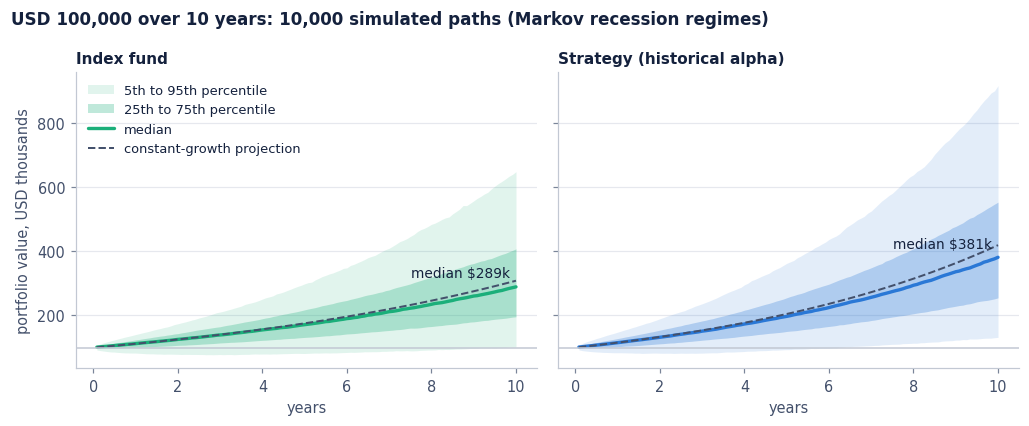

In [42]:
START_VALUE, N_STEPS = 100_000, 12 * CFG.mc_years
def run_design(markov, alpha_m, seed_shift=0):
    rng = np.random.default_rng(CFG.seed + seed_shift)
    states = simulate_states(TM, CFG.mc_paths, N_STEPS, rng, markov=markov)
    return simulate_wealth(states, POOLS, alpha_m, BETA, RESID, RF_M, START_VALUE, rng), states

W_MARKOV, S_MARKOV = run_design(True, ALPHA_M)              # base design, historical alpha
W_MARKOV0, _ = run_design(True, 0.0)                        # base design, alpha = 0 (same random draws)
W_COIN, S_COIN = run_design(False, ALPHA_M)                 # coin-flip design
MC = pd.DataFrame({"Index fund": path_statistics(W_MARKOV["benchmark"], START_VALUE),
                   "Strategy, historical alpha": path_statistics(W_MARKOV["strategy"], START_VALUE),
                   "Strategy, alpha = 0": path_statistics(W_MARKOV0["strategy"], START_VALUE)})
mc_money = [r for r in MC.index if "value" in r or "percentile" in r]
def show_mc(table):
    out = table.copy().astype(object)
    for r in table.index:
        for c in table.columns:
            v = table.loc[r, c]
            out.loc[r, c] = f"${v:,.0f}" if r in mc_money else f"{v:.1%}"
    return out
print(f"Base design (Markov chain), {CFG.mc_paths:,} paths, USD {START_VALUE:,} for {CFG.mc_years} years:")
display(savetable(MC, "tab_mc_outcomes") is not None and show_mc(MC))
behind = float((W_MARKOV["strategy"][:, -1] < W_MARKOV["benchmark"][:, -1]).mean())
behind0 = float((W_MARKOV0["strategy"][:, -1] < W_MARKOV0["benchmark"][:, -1]).mean())
p_loss = MC.loc["probability of a loss at the horizon", "Strategy, historical alpha"]
print(f"Probability that the strategy ends the decade behind the index fund: {pct(behind)} with the historical alpha, {pct(behind0)} with alpha = 0")
print(f"Monte Carlo standard error of the loss probability: +/- {pct(math.sqrt(p_loss * (1 - p_loss) / CFG.mc_paths), 2)}")

# constant-growth line: what a deterministic projection at the model's average monthly return would show
mean_excess = (1 - SHARE) * POOLS[0].mean() + SHARE * POOLS[1].mean()
det = {"benchmark": START_VALUE * (1 + RF_M + mean_excess) ** np.arange(1, N_STEPS + 1),
       "strategy": START_VALUE * (1 + RF_M + ALPHA_M + BETA * mean_excess) ** np.arange(1, N_STEPS + 1)}
years_axis = np.arange(1, N_STEPS + 1) / 12
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.9), sharey=True)
for ax, key, title, color in ((axes[0], "benchmark", "Index fund", TEAL), (axes[1], "strategy", "Strategy (historical alpha)", BLUE)):
    w = W_MARKOV[key] / 1000
    ax.fill_between(years_axis, np.percentile(w, 5, axis=0), np.percentile(w, 95, axis=0), color=color, alpha=0.13, lw=0, label="5th to 95th percentile")
    ax.fill_between(years_axis, np.percentile(w, 25, axis=0), np.percentile(w, 75, axis=0), color=color, alpha=0.28, lw=0, label="25th to 75th percentile")
    ax.plot(years_axis, np.median(w, axis=0), color=color, lw=2.2, label="median")
    ax.plot(years_axis, det[key] / 1000, color=INK2, lw=1.3, ls="--", label="constant-growth projection")
    ax.axhline(START_VALUE / 1000, color=AXIS, lw=1); ax.set_title(title, fontsize=10); ax.set_xlabel("years")
    ax.annotate(f"median ${np.median(w[:, -1]):,.0f}k", (years_axis[-1], np.median(w[:, -1])), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=9, color=INK)
axes[0].set_ylabel("portfolio value, USD thousands"); axes[0].legend(loc="upper left", fontsize=8.5)
fig.suptitle(f"USD {START_VALUE:,} over {CFG.mc_years} years: {CFG.mc_paths:,} simulated paths (Markov recession regimes)", x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
plt.tight_layout(); savefig(fig, "fig_mc_fan_chart")

Strategy                                Index fund                      
                                         Markov chain (base) Independent coin flip Markov chain (base) Independent coin flip
median final value                                  $381,425              $369,610            $289,226              $275,831
5th percentile                                      $131,694              $156,723            $101,734              $123,271
95th percentile                                     $916,380              $874,606            $648,266              $609,225
probability of a loss after 1 year                     20.3%                 21.2%               23.3%                 24.6%
probability of a loss after 3 years                    11.0%                  8.5%               14.5%                 12.7%
probability of a loss at the horizon                    2.0%                  0.6%                4.8%                  2.1%
median worst drawdown                                 -25.6%                -24.4%              -26.2%                -25.0%
probability of a drawdown worse than 30%               37.0%                 26.4%               39.9%                 29.3%
probability of a drawdown worse than 50%                7.3%                  0.9%                9.7%                  1.7%

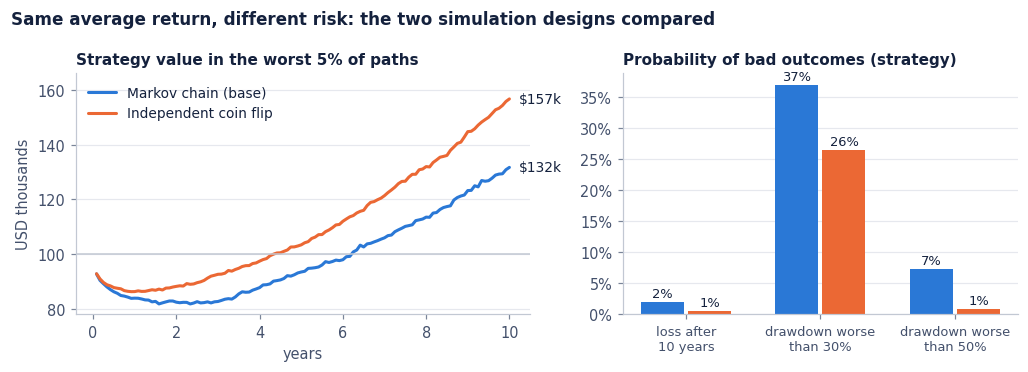

Sensitivity of the strategy's simulated outcomes to the period used for the transition probabilities:


,long-run share of recession months,P(recession next month | recession),median final value,5th percentile,probability of a loss at the horizon,probability of a drawdown worse than 30%
Since 1947 (base),13.1%,90.3%,"$381,425","$131,694",2.0%,37.0%
Since 1854 (all NBER data),27.6%,94.0%,"$272,910","$74,162",9.8%,61.1%
Since 1988 (same window as the returns),7.9%,88.9%,"$423,148","$166,465",1.0%,25.5%


In [43]:
# ---- how much does the design decision matter? ----
DESIGN = pd.DataFrame({"Markov chain (base)": path_statistics(W_MARKOV["strategy"], START_VALUE),
                       "Independent coin flip": path_statistics(W_COIN["strategy"], START_VALUE)})
DESIGN_B = pd.DataFrame({"Markov chain (base)": path_statistics(W_MARKOV["benchmark"], START_VALUE),
                         "Independent coin flip": path_statistics(W_COIN["benchmark"], START_VALUE)})
key_rows = ["median final value", "5th percentile", "95th percentile", "probability of a loss after 1 year", "probability of a loss after 3 years",
            "probability of a loss at the horizon", "median worst drawdown", "probability of a drawdown worse than 30%", "probability of a drawdown worse than 50%"]
both = pd.concat({"Strategy": DESIGN.loc[key_rows], "Index fund": DESIGN_B.loc[key_rows]}, axis=1)
savetable(both, "tab_mc_design_comparison")
shown = both.copy().astype(object)
for r in both.index:
    for c in both.columns:
        shown.loc[r, c] = f"${both.loc[r, c]:,.0f}" if r in mc_money else f"{both.loc[r, c]:.1%}"
display(shown)

fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.4), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
for w, color, label in ((W_MARKOV["strategy"], BLUE, "Markov chain (base)"), (W_COIN["strategy"], ORANGE, "Independent coin flip")):
    ax.plot(years_axis, np.percentile(w, 5, axis=0) / 1000, color=color, lw=2.0, label=label)
    ax.annotate(f"${np.percentile(w[:, -1], 5) / 1000:,.0f}k", (years_axis[-1], np.percentile(w[:, -1], 5) / 1000), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK, annotation_clip=False)
ax.axhline(START_VALUE / 1000, color=AXIS, lw=1); ax.legend(loc="upper left"); ax.set_xlabel("years"); ax.set_ylabel("USD thousands")
ends_5pct = [np.percentile(w[:, -1], 5) / 1000 for w in (W_MARKOV["strategy"], W_COIN["strategy"])]
ax.set_ylim(top=max(START_VALUE / 1000 * 1.12, 1.06 * max(ends_5pct)))
ax.set_title("Strategy value in the worst 5% of paths", fontsize=10)
ax = axes[1]
tail_rows = ["probability of a loss at the horizon", "probability of a drawdown worse than 30%", "probability of a drawdown worse than 50%"]
tail_names = ["loss after\n10 years", "drawdown worse\nthan 30%", "drawdown worse\nthan 50%"]
xpos = np.arange(len(tail_rows)); width = 0.32
for k, (col, color) in enumerate((("Markov chain (base)", BLUE), ("Independent coin flip", ORANGE))):
    vals = DESIGN.loc[tail_rows, col].to_numpy(dtype=float)
    ax.bar(xpos + (k - 0.5) * (width + 0.03), vals, width=width, color=color, label=col)
    for xk, v in zip(xpos + (k - 0.5) * (width + 0.03), vals):
        ax.annotate(f"{v:.0%}", (xk, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(xpos); ax.set_xticklabels(tail_names, fontsize=8.5); percent_axis(ax)
ax.set_title("Probability of bad outcomes (strategy)", fontsize=10)
fig.suptitle("Same average return, different risk: the two simulation designs compared", x=0.01, ha="left", fontsize=11, fontweight="bold", color=INK)
plt.tight_layout(); savefig(fig, "fig_mc_design_comparison")

# sensitivity of the base design to the window used for the transition matrix
alt_rows = {}
for label, first in ((f"Since {CFG.mc_regime_start[:4]} (base)", CFG.mc_regime_start), ("Since 1854 (all NBER data)", "1854-12"), ("Since 1988 (same window as the returns)", "1988-01")):
    tm_alt = transition_matrix(rec.loc[P(first):P("2025-12")].to_numpy())
    rng = np.random.default_rng(CFG.seed)
    st = simulate_states(tm_alt, CFG.mc_paths, N_STEPS, rng, markov=True)
    w_alt = simulate_wealth(st, POOLS, ALPHA_M, BETA, RESID, RF_M, START_VALUE, rng)
    ps = path_statistics(w_alt["strategy"], START_VALUE)
    alt_rows[label] = {"long-run share of recession months": long_run_recession_share(tm_alt), "P(recession next month | recession)": tm_alt[1, 1],
                       "median final value": ps["median final value"], "5th percentile": ps["5th percentile"],
                       "probability of a loss at the horizon": ps["probability of a loss at the horizon"],
                       "probability of a drawdown worse than 30%": ps["probability of a drawdown worse than 30%"]}
ALT = pd.DataFrame(alt_rows).T
print("Sensitivity of the strategy's simulated outcomes to the period used for the transition probabilities:")
display(savetable(ALT, "tab_mc_regime_window_sensitivity").style.format({"long-run share of recession months": "{:.1%}", "P(recession next month | recession)": "{:.1%}",
        "median final value": "${:,.0f}", "5th percentile": "${:,.0f}", "probability of a loss at the horizon": "{:.1%}", "probability of a drawdown worse than 30%": "{:.1%}"}))

In [44]:
s_mc, b_mc, s0_mc = MC["Strategy, historical alpha"], MC["Index fund"], MC["Strategy, alpha = 0"]
dm, dc = DESIGN["Markov chain (base)"], DESIGN["Independent coin flip"]
say(f"""
#### What the simulation says, and what it cannot say

**Range of outcomes.** In the base design the median outcome of USD {START_VALUE:,} after {CFG.mc_years} years is about **USD {s_mc['median final value']:,.0f}** for the strategy and USD {b_mc['median final value']:,.0f} for the index fund. Half of the strategy's paths end between USD {s_mc['25th percentile']:,.0f} and USD {s_mc['75th percentile']:,.0f}; one path in twenty ends below USD {s_mc['5th percentile']:,.0f} and one in twenty above USD {s_mc['95th percentile']:,.0f}. The mean (USD {s_mc['mean final value']:,.0f}) is above the median because compounding makes the distribution right-skewed: the outcome a typical client gets is the median, not the mean, and not the constant-growth line (dashed), which ends at USD {det['strategy'][-1]:,.0f}.

**Probability of a loss.** The strategy is below its starting value after one year in {pct(s_mc['probability of a loss after 1 year'])} of the paths, after three years in {pct(s_mc['probability of a loss after 3 years'])} and after ten years in {pct(s_mc['probability of a loss at the horizon'])}. Along the way, the median path suffers a worst drawdown of {pct(s_mc['median worst drawdown'], 0)} and {pct(s_mc['probability of a drawdown worse than 30%'], 0)} of the paths lose more than 30% from a peak at some point. A ten-year horizon reduces the chance of ending with a loss; it does not reduce the chance of living through a deep one.

**Against the index fund.** With the historical alpha of {pct(12 * ALPHA_M)} per year the strategy ends the decade behind the index fund in **{pct(behind, 0)}** of the paths. With alpha set to zero the two have almost the same median (USD {s0_mc['median final value']:,.0f} against USD {b_mc['median final value']:,.0f}) and the strategy is behind in {pct(behind0, 0)} of the paths. The comparison with the index fund therefore stands or falls with the alpha, which ten years of data cannot establish (section 6.2): without it, the strategy adds stock-specific risk to the index fund without adding return.

**How much the design decision matters.** Both designs have the same average monthly return, yet under the coin flip the strategy's 5th percentile after ten years is USD {dc['5th percentile']:,.0f}, the probability of ending with a loss {pct(dc['probability of a loss at the horizon'])} and the probability of a drawdown worse than 50% {pct(dc['probability of a drawdown worse than 50%'])}; under the Markov chain they are USD {dm['5th percentile']:,.0f}, {pct(dm['probability of a loss at the horizon'])} and {pct(dm['probability of a drawdown worse than 50%'])}. The median is {pick(dm['median final value'] > dc['median final value'], 'slightly higher', 'about the same')} under the Markov chain (USD {dm['median final value']:,.0f} against USD {dc['median final value']:,.0f}): when recessions clump, most decades contain fewer recession months than average and a few contain many. The independence assumption therefore {pick(dm['probability of a drawdown worse than 50%'] > dc['probability of a drawdown worse than 50%'], 'understates', 'does not understate')} tail risk. It gets the typical outcome roughly right and the bad scenarios wrong, which is exactly the part a risk-averse client cares about.

**Limits of the model.** The simulation converges precisely to the answer implied by its assumptions (Monte Carlo error of the loss probability about ±{pct(math.sqrt(p_loss * (1 - p_loss) / CFG.mc_paths), 1)}), but precision is not accuracy. The assumptions that matter most: (i) alpha, beta and the residuals come from a single decade and are held constant, although section 8.5 shows that beta moves, section 8.3 that the alpha was earned unevenly, and the momentum literature that winners lag most in rebounds, so the strategy's recession behaviour may be worse than modelled; (ii) within-state market returns come from 1988 to 2025, a period with only four recessions; (iii) the two-state description ignores inflation regimes, valuation levels and interest rates; (iv) taxes and the survivorship advantage of section 5.2 are not removed; (v) the simulated "index fund" is the S&P 500 total-return index without SPY's 0.09% annual fee, while alpha and beta were estimated against SPY, so both simulated series are about 0.09% per year too high and the comparison between them is unaffected. The table above shows that changing only the estimation window of the transition matrix moves the 5th percentile from USD {ALT['5th percentile'].max():,.0f} to USD {ALT['5th percentile'].min():,.0f}. The outputs are a structured way to think about the range of outcomes, not a forecast.
""")


#### What the simulation says, and what it cannot say

**Range of outcomes.** In the base design the median outcome of USD 100,000 after 10 years is about **USD 381,425** for the strategy and USD 289,226 for the index fund. Half of the strategy's paths end between USD 255,037 and USD 553,256; one path in twenty ends below USD 131,694 and one in twenty above USD 916,380. The mean (USD 434,199) is above the median because compounding makes the distribution right-skewed: the outcome a typical client gets is the median, not the mean, and not the constant-growth line (dashed), which ends at USD 419,242.

**Probability of a loss.** The strategy is below its starting value after one year in 20.3% of the paths, after three years in 11.0% and after ten years in 2.0%. Along the way, the median path suffers a worst drawdown of -26% and 37% of the paths lose more than 30% from a peak at some point. A ten-year horizon reduces the chance of ending with a loss; it does not reduce the chance of living through a deep one.

**Against the index fund.** With the historical alpha of 3.5% per year the strategy ends the decade behind the index fund in **12%** of the paths. With alpha set to zero the two have almost the same median (USD 270,698 against USD 289,226) and the strategy is behind in 59% of the paths. The comparison with the index fund therefore stands or falls with the alpha, which ten years of data cannot establish (section 6.2): without it, the strategy adds stock-specific risk to the index fund without adding return.

**How much the design decision matters.** Both designs have the same average monthly return, yet under the coin flip the strategy's 5th percentile after ten years is USD 156,723, the probability of ending with a loss 0.6% and the probability of a drawdown worse than 50% 0.9%; under the Markov chain they are USD 131,694, 2.0% and 7.3%. The median is slightly higher under the Markov chain (USD 381,425 against USD 369,610): when recessions clump, most decades contain fewer recession months than average and a few contain many. The independence assumption therefore understates tail risk. It gets the typical outcome roughly right and the bad scenarios wrong, which is exactly the part a risk-averse client cares about.

**Limits of the model.** The simulation converges precisely to the answer implied by its assumptions (Monte Carlo error of the loss probability about ±0.1%), but precision is not accuracy. The assumptions that matter most: (i) alpha, beta and the residuals come from a single decade and are held constant, although section 8.5 shows that beta moves, section 8.3 that the alpha was earned unevenly, and the momentum literature that winners lag most in rebounds, so the strategy's recession behaviour may be worse than modelled; (ii) within-state market returns come from 1988 to 2025, a period with only four recessions; (iii) the two-state description ignores inflation regimes, valuation levels and interest rates; (iv) taxes and the survivorship advantage of section 5.2 are not removed; (v) the simulated "index fund" is the S&P 500 total-return index without SPY's 0.09% annual fee, while alpha and beta were estimated against SPY, so both simulated series are about 0.09% per year too high and the comparison between them is unaffected. The table above shows that changing only the estimation window of the transition matrix moves the 5th percentile from USD 166,465 to USD 74,162. The outputs are a structured way to think about the range of outcomes, not a forecast.


## 11. Validation

### 11.1 Automated tests on synthetic data

The tests below run on small **made-up** data sets, never on market data, so each expected value can be worked out by hand. They are the same tests that `pytest` runs in the GitHub repository (`tests/test_engine.py` is exported from this cell). A test only counts as passed if it was executed in this run; the table underneath is produced by actually running them.

In [45]:
# [tests] exported to the repo by tools/export_engine.py - see the README
_TOY_CFG = Config(first_holding_month="2020-01", last_holding_month="2021-12", benchmark="MKT", momentum_fund="MKT",
                  max_weight=0.6)                    # with 12 toy stocks a 9% limit could not be met


def _toy_market(seed=7, shock_after=None):
    """Synthetic daily market: 12 stocks + a calendar ticker, with an IPO, a gap, a delisting, index changes and a
    share count reported about every three months. With `shock_after`, every price and every share count after
    that day is rewritten."""
    rng = np.random.default_rng(seed)
    days = pd.bdate_range("2018-01-01", "2021-12-31")
    names = [f"S{i:02d}" for i in range(12)]
    steps = rng.normal(0.0004, 0.015, (len(days), len(names)))
    adj = pd.DataFrame(100.0 * np.exp(np.cumsum(steps, axis=0)), index=days, columns=names)
    reported = days[::63]
    drift = np.exp(np.cumsum(rng.normal(0.0, 0.02, (len(reported), len(names))), axis=0))
    shares = pd.DataFrame(1e6 * np.arange(1, len(names) + 1) * drift, index=reported, columns=names)
    if shock_after is not None:                      # rewrite the future: every later price and share count is changed
        later = adj.index > pd.Timestamp(shock_after)
        adj.loc[later] = adj.loc[later] * rng.uniform(0.3, 3.0, (int(later.sum()), len(names)))
        later = shares.index > pd.Timestamp(shock_after)
        shares.loc[later] = shares.loc[later] * rng.uniform(0.3, 3.0, (int(later.sum()), len(names)))
    adj["MKT"] = 100.0 * np.exp(np.cumsum(np.full(len(days), 0.0003)))
    adj.loc[adj.index > "2020-08-14", "S03"] = np.nan           # delisted in mid-August 2020
    adj.loc[adj.index < "2019-03-01", "S05"] = np.nan           # IPO in March 2019
    june_end = adj.loc["2019-06"].index[-1]
    adj.loc[june_end, "S04"] = np.nan                           # no quote on the last session of June 2019
    panel = build_monthly_panel(adj, adj.copy(), adj.notna() * 1e6, "MKT")
    panel["price_only_factor"] = price_only_factors(pd.DataFrame(0.0, index=days, columns=adj.columns), panel["sessions"])
    counts = {n: shares[n] for n in names}
    add_market_caps(panel, counts, _TOY_CFG)
    spells = pd.DataFrame({"ticker": names, "name": names, "start": pd.NaT, "end": pd.NaT,
                           "reason_in": "", "reason_out": "", "sector": None})
    spells["start"] = pd.to_datetime(spells["start"]); spells["end"] = pd.to_datetime(spells["end"])
    spells.loc[spells.ticker == "S06", "start"] = pd.Timestamp("2020-02-10")   # joins the index
    spells.loc[spells.ticker == "S07", "end"] = pd.Timestamp("2020-05-20")     # leaves the index
    mapped = map_spells_to_yahoo(spells, panel["first_date"], "2018-01-01")
    rf = pd.Series(0.001, index=panel["sessions"].index)
    return adj, panel, mapped, rf, counts


def test_trade_reference_and_measurement_months_match_the_published_example():
    # S&P methodology, Appendix A, note 1: rebalancing effective in March 2014, reference date 28 February 2014,
    # momentum value from the prices of 31 January 2014 and 31 January 2013
    cfg = Config()
    trade = P("2014-03")
    reference = trade - cfg.reference_lag
    assert reference == P("2014-02")
    assert reference - cfg.skip == P("2014-01") and reference - cfg.skip - cfg.lookback == P("2013-01")
    assert reference - cfg.skip - cfg.fallback_lookback == P("2013-04")       # nine months of history instead of twelve


def test_momentum_value_skips_the_latest_month_and_volatility_uses_daily_price_changes():
    adj, panel, mapped, rf, _ = _toy_market()
    m = P("2020-08")                                                           # reference month
    x = momentum_inputs(panel, m, _TOY_CFG)
    close, daily, sessions = panel["px_signal"], panel["daily_close"], panel["sessions"]
    assert abs(x.loc["S00", "value"] - (close.loc[P("2020-07"), "S00"] / close.loc[P("2019-07"), "S00"] - 1.0)) < 1e-12
    window = daily.loc[sessions[P("2019-07")]:sessions[P("2020-07")], "S00"]
    changes = (window / window.shift(1) - 1.0).iloc[1:]
    assert abs(x.loc["S00", "vol"] - changes.std(ddof=1)) < 1e-15 and x.loc["S00", "days"] == len(changes) and x.loc["S00", "months"] == 12
    later = dict(panel)                                                        # prices of the reference month and after
    later["px_signal"] = close.copy(); later["px_signal"].loc[P("2020-08"):, "S00"] *= 5.0
    later["daily_close"] = daily.copy(); later["daily_close"].loc[sessions[P("2020-07")] + pd.Timedelta(days=1):, "S00"] *= 5.0
    y = momentum_inputs(later, m, _TOY_CFG)
    assert y.loc["S00", "value"] == x.loc["S00", "value"] and y.loc["S00", "vol"] == x.loc["S00", "vol"]   # ... do not enter
    ipo = momentum_inputs(panel, P("2020-01"), _TOY_CFG).loc["S05"]            # listed March 2019: no price 13 months back
    assert ipo["months"] == 9
    assert abs(ipo["value"] - (close.loc[P("2019-12"), "S05"] / close.loc[P("2019-03"), "S05"] - 1.0)) < 1e-12


def test_momentum_score_formula_and_cap_at_three():
    value = pd.Series([0.10, 0.20, 0.30], index=list("ABC")); vol = pd.Series([0.01, 0.02, 0.01], index=list("ABC"))
    x, z, score = momentum_score(value, vol)
    assert np.allclose(x, [10.0, 10.0, 30.0])                                  # risk-adjusted value
    sd = np.std([10.0, 10.0, 30.0], ddof=1); mean = 50.0 / 3.0
    assert np.allclose(z, [(10 - mean) / sd, (10 - mean) / sd, (30 - mean) / sd])
    assert abs(score["C"] - (1.0 + z["C"])) < 1e-12 and abs(score["A"] - 1.0 / (1.0 - z["A"])) < 1e-12
    raw = momentum_score(value, vol, risk_adjust=False)[0]
    assert np.allclose(raw, value)                                             # without risk adjustment the plain value is ranked
    wide = pd.Series(np.r_[np.zeros(40), 100.0, -100.0], index=[f"N{i}" for i in range(42)])
    _, zw, sw = momentum_score(wide, pd.Series(1.0, index=wide.index))
    assert zw.max() == 3.0 and zw.min() == -3.0 and sw.max() == 4.0 and abs(sw.min() - 0.25) < 1e-12
    flat = momentum_score(pd.Series([1.0, 1.0]), pd.Series([1.0, 1.0]))
    assert (flat[1] == 0).all() and (flat[2] == 1.0).all()                     # no dispersion: every score is 1


def test_groups_equal_count_extra_names_to_highest_and_ties_by_identifier():
    score = pd.Series(np.arange(23, dtype=float), index=[f"T{i:02d}" for i in range(23)])
    g = assign_groups(score, 5)
    assert g.value_counts().sort_index().tolist() == [4, 4, 5, 5, 5]
    assert g.notna().all() and set(g.unique()) == {1.0, 2.0, 3.0, 4.0, 5.0}
    tied = pd.Series([0.1, 0.1, 0.1, 0.1], index=["D", "B", "C", "A"])
    gt = assign_groups(tied, 2)
    assert gt["A"] == 1 and gt["B"] == 1 and gt["C"] == 2 and gt["D"] == 2      # alphabetical tie-break
    with_nan = pd.Series([0.3, np.nan, 0.1], index=["X", "Y", "Z"])
    gn = assign_groups(with_nan, 2)
    assert np.isnan(gn["Y"]) and gn["Z"] == 1 and gn["X"] == 2
    for n in (5, 10, 20):
        sizes = assign_groups(pd.Series(np.random.default_rng(1).normal(size=487)), n).value_counts()
        assert sizes.max() - sizes.min() <= 1 and sizes.sum() == 487


def test_buffer_rule_keeps_holdings_near_the_cut_off():
    ranked = list("ABCDEFGHIJKL")
    assert select_with_buffer(ranked, set(), 5, 0.2) == list("ABCDE")          # nothing held: the best five
    assert select_with_buffer(ranked, {"F", "X"}, 5, 0.2) == list("ABCDF")     # F is held and ranks sixth: kept, E waits
    assert select_with_buffer(ranked, {"G"}, 5, 0.2) == list("ABCDE")          # rank seven is outside the buffer
    assert select_with_buffer(ranked, {"E", "F"}, 5, 0.2) == list("ABCDE")     # E fills the last place before F is reached
    assert select_with_buffer(ranked, {"F"}, 5, 0.0) == list("ABCDE")          # no buffer
    assert select_with_buffer(ranked, {"K", "L"}, 10, 0.2) == list("ABCDEFGH") + ["K", "L"]   # ranks 11 and 12 kept
    assert select_with_buffer(ranked, {"L"}, 10, 0.2) == list("ABCDEFGH") + ["L", "I"]        # then the best newcomer
    assert len(select_with_buffer(ranked, set(ranked), 5, 0.2)) == 5


def test_weights_follow_market_value_times_score_and_respect_both_limits():
    assert np.allclose(capped_weights(pd.Series([6.0, 3.0, 1.0]), pd.Series([0.4, 0.4, 0.4])), [0.4, 0.4, 0.2])
    rng = np.random.default_rng(4)
    names = [f"N{i:02d}" for i in range(30)]
    t = pd.DataFrame({"mcap": np.r_[[900.0, 700.0, 500.0], rng.uniform(5, 60, 27)], "score": rng.uniform(1.5, 4.0, 30)}, index=names)
    t["uw"] = t["mcap"] / (4.0 * t["mcap"].sum())                              # the selected stocks are a quarter of the universe
    cfg = Config()
    w, multiple = strategy_weights(t, names, cfg)
    cap_w = t["mcap"] / t["mcap"].sum()
    assert abs(w.sum() - 1.0) < 1e-12 and (w > 0).all() and multiple == 3.0
    assert (w <= 0.09 + 1e-12).all() and (w <= 3.0 * cap_w + 1e-12).all()      # both limits hold
    free = (w < 0.09 - 1e-9) & (w < 3.0 * cap_w - 1e-9)
    ratio = (w / (t["mcap"] * t["score"]))[free]
    assert free.sum() > 5 and np.allclose(ratio, ratio.iloc[0])                # the others stay proportional to value x score
    assert abs(w["N00"] - 0.09) < 1e-12                                        # the largest company sits at the 9% limit
    plain, _ = strategy_weights(t, names, cfg, capped=False)
    assert np.allclose(plain, t["mcap"] * t["score"] / (t["mcap"] * t["score"]).sum())
    assert np.allclose(strategy_weights(t, names, cfg, weighting="cap", capped=False)[0], cap_w)
    assert np.allclose(strategy_weights(t, names, cfg, weighting="equal")[0], 1.0 / 30)
    second, m2 = strategy_weights(t, names, replace(cfg, cap_reference="universe"))
    assert m2 > 3.0 and abs(second.sum() - 1.0) < 1e-12 and (second <= m2 * t["uw"] + 1e-12).all()   # 3 x universe weight is too tight
    try:
        strategy_weights(t, names[:5], cfg)
        raise AssertionError("five stocks cannot each stay below 9%")
    except ValueError:
        pass


def test_weights_drift_from_the_reference_date_and_untradable_stocks_are_dropped():
    m = P("2020-03")
    f = pd.DataFrame({"mcap": [100.0, 100.0, 200.0], "score": 1.0, "uw": [0.25, 0.25, 0.5], "rank": [1, 2, 3], "group": [5.0, 5.0, 5.0],
                      "drift": [1.10, 1.00, 0.50], "tradable": [True, True, False], "carried_back": False}, index=list("ABC"))
    targets, log = build_targets({m: f}, [m], Config(), "all", weighting="cap", capped=False)
    w = targets[m]
    assert list(w.index) == ["A", "B"]                                         # C left the index before the trade date
    assert abs(w["A"] - 110.0 / 210.0) < 1e-12 and abs(w.sum() - 1.0) < 1e-12  # weights moved with prices since the reference date
    assert log.loc[m, "selected"] == 3 and log.loc[m, "bought"] == 2


def test_membership_replay_has_no_future_additions():
    cons = pd.DataFrame({"Symbol": ["AAA", "BBB", "CCC"], "Security": ["A", "B", "C"], "GICS Sector": ["x", "y", "z"]})
    chg = pd.DataFrame([["June 15, 2020", "CCC", "C", "DDD", "D", "swap", ""],
                        ["March 1, 2019", "BBB", "B", "EEE", "E", "swap", ""]])
    spells, issues = build_spells(cons, chg, cutoff="2018-01-01")
    assert issues.empty
    assert set(members_on(spells, "2019-01-31")["ticker"]) == {"AAA", "EEE", "DDD"}
    assert set(members_on(spells, "2019-12-31")["ticker"]) == {"AAA", "BBB", "DDD"}
    assert set(members_on(spells, "2020-06-14")["ticker"]) == {"AAA", "BBB", "DDD"}      # day before the change
    assert set(members_on(spells, "2020-06-15")["ticker"]) == {"AAA", "BBB", "CCC"}      # effective date
    _, bad = build_spells(cons, pd.DataFrame([["June 15, 2020", "ZZZ", "Z", None, None, "?", ""]]), cutoff="2018-01-01")
    assert len(bad) == 1                                                                   # unmatched entries are reported


def test_month_end_prices_use_the_final_session_and_are_not_forward_filled():
    adj, panel, mapped, rf, _ = _toy_market()
    june_end = adj.loc["2019-06"].index[-1]
    assert panel["sessions"][P("2019-06")] == june_end
    assert np.isnan(panel["px"].loc[P("2019-06"), "S04"])                # stale price is not a month-end price
    assert bool(panel["stale"].loc[P("2019-06"), "S04"])
    assert not np.isnan(panel["ret"].loc[P("2019-06"), "S04"])           # but a held position is still valued
    u = universe_at(P("2019-06"), mapped, panel, _TOY_CFG).set_index("ticker")
    assert u.loc["S04", "status"] == "no valid price on the reference date"


def test_universe_respects_membership_dates_listing_history_and_share_counts():
    adj, panel, mapped, rf, counts = _toy_market()
    def status(month, cfg=_TOY_CFG, p=panel):
        return universe_at(P(month), mapped, p, cfg).set_index("ticker")["status"]
    assert "S06" not in status("2019-12").index                            # not yet a member
    assert status("2020-03")["S06"] == "eligible"                          # joined 10 Feb 2020, has a full price history
    assert "S07" in status("2020-03").index and "S07" not in status("2020-06").index
    assert status("2019-12")["S05"] == "listed too recently for the signal"   # IPO March 2019: not even nine months
    assert status("2020-01")["S05"] == "eligible"                          # nine months of prices before the skipped month
    assert status("2020-01", replace(_TOY_CFG, min_trading_days=200))["S05"] == "too few trading days in the measurement period"
    no_count = dict(panel); add_market_caps(no_count, {k: v for k, v in counts.items() if k != "S02"}, _TOY_CFG)
    assert status("2020-03", p=no_count)["S02"] == "no share count on Yahoo"
    FOREIGN_PRICES_BEFORE["S00"] = "2020-06-01"                            # as if Yahoo's earlier S00 prices were another company's
    try:
        assert status("2020-03")["S00"] == "ticker reused: Yahoo series belongs to another issuer"
        assert status("2020-06")["S00"] == "eligible"
    finally:
        del FOREIGN_PRICES_BEFORE["S00"]
    assert "S03" not in formation_table(P("2020-10"), mapped, panel, _TOY_CFG)[0].index   # no price after the delisting
    may = formation_table(P("2020-05"), mapped, panel, _TOY_CFG)[0]        # reference April: S07 is still a member ...
    assert "S07" in may.index and not may.loc["S07", "tradable"] and may.loc["S00", "tradable"]   # ... but not on the trade date
    aug = formation_table(P("2020-08"), mapped, panel, _TOY_CFG)[0]        # S03 stops trading before the August trade date
    assert "S03" in aug.index and not aug.loc["S03", "tradable"]


def test_rebalance_cost_is_exact_and_never_charged_twice():
    c = 0.001
    v, trades, cost = solve_rebalance(100.0, np.zeros(2), np.array([0.5, 0.5]), c)
    assert abs(v - 100.0 / 1.001) < 1e-12 and abs(v + cost - 100.0) < 1e-12
    assert abs(cost - c * np.abs(trades).sum()) < 1e-15
    v2, trades2, cost2 = solve_rebalance(100.0, np.array([60.0, 40.0]), np.array([0.5, 0.5]), c)
    assert abs(cost2 - 0.02) < 1e-12 and abs(v2 - 99.98) < 1e-12           # $20 traded in total
    v3, trades3, cost3 = solve_rebalance(100.0, np.array([50.0, 50.0]), np.array([0.5, 0.5]), c)
    assert cost3 == 0.0 and v3 == 100.0                                    # already on target: nothing to pay
    v4, _, cost4 = solve_rebalance(100.0, np.array([100.0, 0.0]), np.array([0.0, 0.0]), c)
    assert abs(cost4 - 0.1) < 1e-12 and abs(v4 - 99.9) < 1e-12             # selling everything


def test_nav_starts_at_one_costs_hit_the_next_month_and_weights_drift():
    months = pd.period_range("2020-01", "2020-07", freq="M")
    ret = pd.DataFrame({"A": [np.nan, 0.10, 0.00, 0.05, -0.02, 0.01, 0.03],
                        "B": [np.nan, -0.04, 0.02, 0.01, 0.03, 0.00, -0.01]}, index=months)
    rf = pd.Series(0.0, index=months)
    half = pd.Series({"A": 0.5, "B": 0.5})
    c = 0.001
    run = simulate(ret, rf, {P("2020-01"): half, P("2020-04"): half}, c, P("2020-01"), P("2020-07"))
    gross = simulate(ret, rf, {P("2020-01"): half, P("2020-04"): half}, 0.0, P("2020-01"), P("2020-07"))
    assert run["nav"].iloc[0] == 1.0 and gross["nav"].iloc[0] == 1.0       # initial NAV is 1 before costs
    v0 = 1.0 / (1.0 + c)
    assert abs(run["nav"][P("2020-02")] - v0 * (1 + 0.5 * 0.10 + 0.5 * -0.04)) < 1e-12
    assert abs(gross["ret"][P("2020-02")] - 0.03) < 1e-12
    assert run["ret"][P("2020-02")] < gross["ret"][P("2020-02")]           # the launch cost lowers the first month
    hA = 0.5 * v0 * 1.10 * 1.00 * 1.05; hB = 0.5 * v0 * 0.96 * 1.02 * 1.01   # three months of drift, no trading
    assert abs(run["nav"][P("2020-04")] - (hA + hB)) < 1e-12
    v_net, _, cost = solve_rebalance(hA + hB, np.array([hA, hB]), np.array([0.5, 0.5]), c)
    assert abs(run["nav"][P("2020-05")] - v_net * (1 + 0.5 * -0.02 + 0.5 * 0.03)) < 1e-12
    assert list(run["rebalances"].index) == [P("2020-01"), P("2020-04")]   # no trading in between
    assert abs(run["rebalances"].loc[P("2020-01"), "one_way_turnover"] - 1.0) < 1e-12
    drifted = hA / (hA + hB)
    assert abs(run["rebalances"].loc[P("2020-04"), "one_way_turnover"] - abs(0.5 - drifted)) < 1e-12
    assert abs(np.prod(1 + run["ret"]) - run["nav"].iloc[-1]) < 1e-12       # returns reconcile with NAV
    assert abs(run["monthly"].loc[P("2020-04"), "max_weight"] - drifted) < 1e-12


def test_rebalancing_schedules_for_all_frequencies():
    assert schedule(P("2019-12"), P("2020-12"), (3, 9)) == [P("2019-12"), P("2020-03"), P("2020-09")]
    assert schedule(P("2019-12"), P("2020-12"), (3, 6, 9, 12)) == [P("2019-12"), P("2020-03"), P("2020-06"), P("2020-09")]
    assert len(schedule(P("2019-12"), P("2020-12"), tuple(range(1, 13)))) == 12
    assert schedule(P("2020-01"), P("2020-08"), (3, 9))[0] == P("2020-01")              # the launch month always trades
    assert schedule(P("2015-12"), P("2025-12"), Config().rebalance_months)[-1] == P("2025-09")


def test_delisting_proceeds_become_cash_earn_the_risk_free_rate_and_are_reinvested():
    months = pd.period_range("2020-01", "2020-07", freq="M")
    ret = pd.DataFrame({"X": [np.nan, 0.02, 0.20, np.nan, np.nan, np.nan, np.nan],
                        "Y": [np.nan, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01]}, index=months)
    rf = pd.Series(0.002, index=months)
    last_month = pd.Series({"X": P("2020-03"), "Y": pd.NaT})
    targets = {P("2020-01"): pd.Series({"X": 0.5, "Y": 0.5}), P("2020-06"): pd.Series({"Y": 1.0})}
    run = simulate(ret, rf, targets, 0.0, P("2020-01"), P("2020-07"), last_month)
    x_end = 0.5 * 1.02 * 1.20
    y = 0.5 * 1.01 ** 3
    assert abs(run["nav"][P("2020-04")] - (x_end * 1.002 + y)) < 1e-12      # cash earns RF from April on
    assert abs(run["monthly"].loc[P("2020-04"), "cash_weight"] - x_end * 1.002 / (x_end * 1.002 + y)) < 1e-12
    assert len(run["events"]) == 1 and run["events"][0]["security"] == "X"
    v_june = x_end * 1.002 ** 3 + 0.5 * 1.01 ** 5
    assert abs(run["nav"][P("2020-07")] - v_june * 1.01) < 1e-12            # everything reinvested in Y in June
    try:                                                                     # a missing return with no explanation
        simulate(ret, rf, targets, 0.0, P("2020-01"), P("2020-07"), None)
        raise AssertionError("an unexplained missing return must stop the backtest")
    except ValueError:
        pass


def test_terminal_month_return_uses_the_last_quote():
    adj, panel, mapped, rf, _ = _toy_market()
    assert panel["last_month"]["S03"] == P("2020-08") and pd.isna(panel["last_month"]["S00"])
    last_quote = adj["S03"].dropna().iloc[-1]
    july_end = adj.loc[panel["sessions"][P("2020-07")], "S03"]
    assert abs(panel["ret"].loc[P("2020-08"), "S03"] - (last_quote / july_end - 1.0)) < 1e-12
    assert np.isnan(panel["ret"].loc[P("2020-09"), "S03"])                  # never replaced by zero


def test_risk_free_uses_only_published_yields_and_converts_annual_percent_to_monthly():
    sessions = pd.Series(pd.to_datetime(["2020-12-31", "2021-01-29", "2021-02-26"]),
                         index=pd.period_range("2020-12", "2021-02", freq="M"))
    y = pd.Series([2.0, 2.0, 5.0, 3.0, np.nan, 4.0],
                  index=pd.to_datetime(["2020-12-29", "2020-12-30", "2020-12-31", "2021-01-28", "2021-01-29", "2021-02-01"]))
    rf = monthly_rf(y, sessions)
    assert abs(rf[P("2021-01")] - (1.02 ** (1 / 12) - 1)) < 1e-15           # the 31 Dec value is not yet published
    assert abs(rf[P("2021-02")] - (1.03 ** (1 / 12) - 1)) < 1e-15           # last value before 29 Jan
    assert 0.0016 < rf[P("2021-01")] < 0.0017                               # a monthly decimal, not 2.0 or 0.02


def test_metric_formulas_alpha_is_annualised_and_beta_is_not():
    rng = np.random.default_rng(3)
    idx = pd.period_range("2015-01", periods=96, freq="M")
    rf = pd.Series(0.001, index=idx)
    bench = pd.Series(rng.normal(0.008, 0.04, 96), index=idx)
    r = 0.002 + 1.3 * (bench - rf) + rf + pd.Series(rng.normal(0, 0.01, 96), index=idx)
    s = performance_stats(r, rf, bench)
    ex, bex = (r - rf).to_numpy(), (bench - rf).to_numpy()
    beta = np.cov(ex, bex, ddof=1)[0, 1] / np.var(bex, ddof=1)
    alpha_m = ex.mean() - beta * bex.mean()
    assert abs(s["beta"] - beta) < 1e-10 and abs(s["alpha"] - 12 * alpha_m) < 1e-10
    assert abs(s["ann_return"] - 12 * r.mean()) < 1e-14
    assert abs(s["ann_vol"] - np.sqrt(12) * np.std(r.to_numpy(), ddof=1)) < 1e-14
    assert abs(s["sharpe"] - np.sqrt(12) * ex.mean() / np.std(ex, ddof=1)) < 1e-12
    a = (r - bench).to_numpy()
    assert abs(s["info_ratio"] - 12 * a.mean() / (np.sqrt(12) * np.std(a, ddof=1))) < 1e-12
    assert abs(s["cagr"] - (np.prod(1 + r.to_numpy()) ** (12 / 96) - 1)) < 1e-14
    doubled = performance_stats(2 * (r - rf) + rf, rf, bench)               # leverage doubles alpha and beta ...
    assert abs(doubled["beta"] - 2 * s["beta"]) < 1e-9 and abs(doubled["alpha"] - 2 * s["alpha"]) < 1e-9
    assert abs(doubled["sharpe"] - s["sharpe"]) < 1e-9                      # ... but not the Sharpe ratio
    b = performance_stats(bench, rf, bench, is_benchmark=True)
    assert b["beta"] == 1.0 and b["alpha"] == 0.0 and np.isnan(b["info_ratio"])   # undefined, reported as missing
    dd = performance_stats(pd.Series([-0.10, 0.05, -0.20, 0.30], index=idx[:4]), rf)
    assert abs(dd["max_drawdown"] - (0.9 * 1.05 * 0.8 - 1.0)) < 1e-12       # the peak is the initial value of 1


def test_changing_future_prices_does_not_change_earlier_decisions():
    cutoff = "2020-06-30"
    _, panel_a, mapped_a, rf, _ = _toy_market(seed=7)
    _, panel_b, mapped_b, _, _ = _toy_market(seed=7, shock_after=cutoff)
    months = schedule(P("2019-12"), P("2021-12"), (3, 6, 9, 12))
    forms_a = {m: formation_table(m, mapped_a, panel_a, _TOY_CFG)[0] for m in months}
    forms_b = {m: formation_table(m, mapped_b, panel_b, _TOY_CFG)[0] for m in months}
    for m in months:
        if m <= P("2020-06"):
            assert list(forms_a[m].index) == list(forms_b[m].index)
            for col in ("value", "vol", "ram", "z", "score", "mcap", "uw", "drift"):
                assert np.allclose(forms_a[m][col], forms_b[m][col], rtol=0, atol=0), col
            assert forms_a[m]["rank"].equals(forms_b[m]["rank"]) and forms_a[m]["group"].equals(forms_b[m]["group"])
            assert forms_a[m]["tradable"].equals(forms_b[m]["tradable"])
    assert not np.allclose(panel_a["px"].loc[P("2020-12")].dropna(), panel_b["px"].loc[P("2020-12")].dropna())
    assert panel_a["shares"].loc[:P("2020-06")].equals(panel_b["shares"].loc[:P("2020-06")])     # share counts as known then
    assert not np.allclose(panel_a["shares"].loc[P("2021-06")], panel_b["shares"].loc[P("2021-06")])
    ta, _ = build_targets(forms_a, months, _TOY_CFG, "top"); tb, _ = build_targets(forms_b, months, _TOY_CFG, "top")
    for m in months:
        if m <= P("2020-06"):
            assert ta[m].equals(tb[m])                                       # the same stocks at the same weights
    run_a = simulate(panel_a["ret"], rf, ta, 0.001, P("2019-12"), P("2021-12"), panel_a["last_month"])
    run_b = simulate(panel_b["ret"], rf, tb, 0.001, P("2019-12"), P("2021-12"), panel_b["last_month"])
    assert np.allclose(run_a["nav"].loc[:P("2020-06")], run_b["nav"].loc[:P("2020-06")], rtol=0, atol=1e-14)
    assert abs(run_a["nav"].iloc[-1] - run_b["nav"].iloc[-1]) > 1e-6        # the future really was different


def test_full_toy_backtest_reconciles_and_stays_fully_invested():
    _, panel, mapped, rf, _ = _toy_market()
    months = schedule(P("2019-12"), P("2021-12"), _TOY_CFG.rebalance_months)
    forms = {m: formation_table(m, mapped, panel, _TOY_CFG)[0] for m in months}
    for m in months:
        sizes = forms[m]["group"].value_counts()
        assert sizes.max() - sizes.min() <= 1 and sizes.sum() == len(forms[m])
        assert sorted(forms[m]["rank"]) == list(range(1, len(forms[m]) + 1))
    targets, log = build_targets(forms, months, _TOY_CFG, "top")
    run = run_portfolio(panel, rf, targets, P("2019-12"), P("2021-12"), 0.001)
    assert run["nav"].iloc[0] == 1.0 and len(run["ret"]) == 24
    assert (run["ret_gross"] >= run["ret"] - 1e-12).all()                   # costs can only reduce returns
    reb = run["rebalances"]
    assert np.allclose(reb["cost"], 0.001 * reb["traded_notional"], rtol=0, atol=1e-15)   # cost = rate x dollars traded
    assert abs(reb["one_way_turnover"].iloc[0] - 1.0) < 1e-12
    for m, w in run["targets"].items():
        assert abs(w.sum() - 1.0) < 1e-12 and (w > 0).all()                 # fully invested, long only
        assert len(w) <= log.loc[m, "selected"] == int(math.floor(len(forms[m]) / 5 + 0.5))
    universe, _ = build_targets(forms, months, _TOY_CFG, "all", weighting="cap", capped=False)
    first = forms[months[0]]
    assert len(universe[months[0]]) == int(first["tradable"].sum())
    assert np.allclose(universe[months[0]], (first["mcap"] * first["drift"])[first["tradable"]] / (first["mcap"] * first["drift"])[first["tradable"]].sum())


def _toy_data():
    """Toy data bundle in the shape run_backtest expects (benchmark and fund are the synthetic market series)."""
    _, panel, mapped, rf, counts = _toy_market()
    forms, members = build_formations(panel, mapped, _TOY_CFG)
    return {"cfg": _TOY_CFG, "panel": panel, "spells": mapped, "rf": rf, "forms": forms, "members": members,
            "share_units": counts, "share_units_todays_symbol": counts, "share_outage": None}, _TOY_CFG


def test_run_backtest_returns_aligned_series_for_every_portfolio():
    data, cfg = _toy_data()
    bt = run_backtest(data, cfg)
    assert bt["strategy"] == "Strategy" and bt["group_names"] == ["Q1", "Q2", "Q3", "Q4", "Q5"]
    assert list(bt["returns"].columns) == ["Strategy", "Q1", "Q2", "Q3", "Q4", "Q5", "Universe", "MKT"]
    assert bt["returns"].index[0] == P("2020-01") and bt["returns"].index[-1] == P("2021-12") and not bt["returns"].isna().any().any()
    assert (bt["nav"].iloc[0] == 1.0).all() and bt["metrics"].loc["MKT", "beta"] == 1.0
    assert abs(bt["metrics"].loc["Strategy", "ann_return"] - 12 * bt["returns"]["Strategy"].mean()) < 1e-14
    assert bt["formation_months"] == [P("2019-12"), P("2020-03"), P("2020-09"), P("2021-03"), P("2021-09")]
    assert list(bt["selection"].index) == bt["formation_months"] and (bt["selection"]["bought"] <= bt["selection"]["selected"]).all()
    monthly = run_backtest(data, replace(cfg, rebalance_months=tuple(range(1, 13))))
    assert len(monthly["formation_months"]) == 24
    free = run_backtest(data, replace(cfg, cost_rate=0.0))
    assert np.allclose(free["returns"]["Strategy"], bt["returns_gross"]["Strategy"], rtol=0, atol=1e-15)   # gross = a zero-cost run
    equal = run_backtest(data, replace(cfg, weighting="equal"))
    assert not equal["returns"]["Strategy"].equals(bt["returns"]["Strategy"])
    plain_cfg = replace(cfg, risk_adjust=False)
    plain = reconfigure(data, plain_cfg)
    m = bt["formation_months"][1]
    assert np.allclose(plain["forms"][m]["ram"], plain["forms"][m]["value"]) and not np.allclose(data["forms"][m]["ram"], data["forms"][m]["value"])
    assert run_backtest(plain, plain_cfg)["strategy"] == "Strategy"


def test_break_even_cost_is_a_root_of_the_net_advantage():
    data, cfg = _toy_data()
    be = break_even_cost(data, cfg, "Universe")
    assert be["status"] and len(be["table"]) == 8
    if not np.isnan(be["break_even"]):
        check = run_backtest(data, replace(cfg, cost_rate=be["break_even"]))
        assert abs(12 * (check["returns"]["Strategy"] - check["returns"]["Universe"]).mean()) < 1e-8
    else:
        assert be["table"].iloc[0] <= 0 or (be["table"] > 0).all()


def test_break_even_cost_finds_the_crossing_when_the_strategy_leads_before_costs():
    start, end = P("2019-12"), P("2021-12")
    months = pd.period_range(start, end, freq="M")
    names = ["H1", "H2", "H3", "H4"] + [f"L{i}" for i in range(6)]
    ret = pd.DataFrame({n: (0.02 if n.startswith("H") else 0.01) for n in names}, index=months)
    cfg = replace(_TOY_CFG, rebalance_months=(3, 6, 9, 12), buffer=0.0)
    dates = schedule(start, end, cfg.rebalance_months)
    forms = {}
    for i, m in enumerate(dates):                                            # the two best names change every quarter: full turnover
        best = ["H1", "H2"] if i % 2 == 0 else ["H3", "H4"]
        order = best + [n for n in names if n not in best]
        f = pd.DataFrame({"mcap": 1.0, "score": 1.0, "uw": 0.1, "drift": 1.0, "tradable": True, "carried_back": False}, index=names)
        f["rank"] = pd.Series(range(1, 11), index=order); f["group"] = assign_groups(-f["rank"], 5)
        forms[m] = f
    rf = pd.Series(0.0, index=months)
    data = {"panel": {"ret": ret, "last_month": pd.Series(pd.NaT, index=names)}, "rf": rf, "forms": forms}
    be = break_even_cost(data, cfg, "Universe")
    assert be["status"].startswith("break-even found") and 0.005 < be["break_even"] < 0.02
    a = simulate(ret, rf, build_targets(forms, dates, cfg, "top")[0], be["break_even"], start, end)["ret"]
    b = simulate(ret, rf, build_targets(forms, dates, cfg, "all", weighting="cap", capped=False)[0], be["break_even"], start, end)["ret"]
    assert abs(12 * (a - b).mean()) < 1e-9                                   # at that cost the advantage is zero


def test_transition_analysis_counts_moves_exits_and_entries():
    a, b = P("2020-03"), P("2020-09")
    fa = pd.DataFrame({"group": [1, 2, 3, 4, 5, 5]}, index=list("ABCDEF")).astype(float)
    fb = pd.DataFrame({"group": [1, 3, 5, 5, 4]}, index=["A", "B", "E", "G", "D"]).astype(float)  # C and F are gone, G is new
    members = {b: pd.DataFrame({"yahoo": ["A", "B", "E", "G", "D", "F"]})}                       # F still a member, C left
    t = transition_analysis({a: fa, b: fb}, members, [a, b], 5)
    c = t["counts"]
    assert c.loc[1, 1] == 1 and c.loc[2, 3] == 1 and c.loc[4, 4] == 1 and c.loc[5, 5] == 1
    assert c.loc[3, "left the index"] == 1 and c.loc[5, "member but not eligible"] == 1
    assert np.allclose(t["probabilities"].sum(axis=1), 1.0) and t["entries"][5] == 1 and t["entries"].sum() == 1
    assert abs(t["retention"][b] - 0.5) < 1e-12                                                  # E stays, F does not
    stays = t["stays"].set_index("security")["periods"]
    assert stays["E"] == 2 and stays["F"] == 1 and stays["G"] == 1 and bool(t["stays"]["censored"].all())


def test_cross_sectional_slope_and_rank_correlation_recover_a_known_relation():
    months = pd.period_range("2020-03", "2020-06", freq="M")
    names = [f"N{i}" for i in range(20)]
    score = pd.Series(np.linspace(-0.3, 0.6, 20), index=names)
    z = (score - score.mean()) / score.std(ddof=1)
    ret = pd.DataFrame(0.0, index=months, columns=names)
    ret.loc[P("2020-04")] = (0.02 + 0.01 * z).to_numpy()                 # one-month forward return, exactly linear in z
    forms = {P("2020-03"): pd.DataFrame({"ram": score})}
    xs = cross_sectional_tests(forms, ret, [P("2020-03")], horizon=1)
    assert abs(xs["slope"].iloc[0] - 0.01) < 1e-12 and abs(xs["intercept"].iloc[0] - 0.02) < 1e-12
    assert abs(xs["rank_ic"].iloc[0] - 1.0) < 1e-12 and xs["stocks"].iloc[0] == 20
    two = pd.DataFrame({"X": [0.10, 0.10, np.nan], "Y": [0.0, 0.0, 0.0]}, index=pd.period_range("2020-04", "2020-06", freq="M"))
    f = forward_returns(two, P("2020-03"), 3, ["X", "Y"])
    assert abs(f["X"] - (1.1 * 1.1 - 1)) < 1e-12 and f["Y"] == 0.0       # a name that stops trading keeps its value
    mt = mean_test(pd.Series([0.01, 0.03, 0.02, 0.02, 0.01, 0.03] * 10))
    assert abs(mt["mean"] - 12 * 0.02) < 1e-12 and mt["n"] == 60 and mt["share_positive"] == 1.0 and mt["ci_low"] < mt["mean"] < mt["ci_high"]


def test_block_bootstrap_is_reproducible_and_resamples_all_series_together():
    rng = np.random.default_rng(5)
    x = rng.normal(0.01, 0.04, 96)
    frame = pd.DataFrame({"a": x, "b": x + 0.001})                       # b is always exactly 0.1 points above a
    stats_ = {"gap": lambda v: (v[:, 1] - v[:, 0]).mean(), "mean_a": lambda v: v[:, 0].mean()}
    one = block_bootstrap(frame, stats_, 300, 6, 2270)
    two = block_bootstrap(frame, stats_, 300, 6, 2270)
    assert one.equals(two)                                               # same seed, same answer
    assert abs(one.loc["gap", "ci_low"] - 0.001) < 1e-12 and abs(one.loc["gap", "ci_high"] - 0.001) < 1e-12
    assert one.loc["mean_a", "ci_low"] < x.mean() < one.loc["mean_a", "ci_high"]
    assert not block_bootstrap(frame, stats_, 300, 12, 2270).loc["mean_a"].equals(one.loc["mean_a"])
    inside = np.arange(95) % 6 != 5                                      # steps that do not cross from one block to the next
    in_order = {"share": lambda v: float(np.mean((np.diff(v[:, 0]) % 96 == 1)[inside]))}
    months = pd.DataFrame({"t": np.arange(96.0)})
    assert block_bootstrap(months, in_order, 50, 6, 1).loc["share", "ci_low"] == 1.0     # inside a block the months keep their order
    assert block_bootstrap(months, in_order, 50, 1, 1).loc["share", "ci_high"] < 0.5     # single months would not


def test_hac_t_statistic_matches_a_newey_west_calculation_by_hand():
    rng = np.random.default_rng(11)
    e = rng.normal(0.0, 0.03, 61)
    x = pd.Series(0.004 + e[1:] + 0.5 * e[:-1])                          # a positively autocorrelated monthly series
    out = mean_test(x, scale=1.0)
    n, lags = len(x), out["hac_lags"]
    u = (x - x.mean()).to_numpy()
    s = (u @ u) / n + 2.0 * sum((1.0 - j / (lags + 1.0)) * (u[j:] @ u[:-j]) / n for j in range(1, lags + 1))   # Bartlett weights
    se = math.sqrt(s / n * n / (n - 1.0))                                # with the small-sample correction n / (n - 1)
    assert lags >= 1 and abs(out["t_hac"] - x.mean() / se) < 1e-9
    assert out["t_hac"] < out["t_simple"]                                # positive autocorrelation makes the mean less certain


def test_random_portfolios_follow_the_strategy_rules():
    data, cfg = _toy_data()
    bt = run_backtest(data, cfg)
    months, forms, chosen = bt["formation_months"], data["forms"], bt["selection"]["selected"]
    pools = random_pools(forms, months, chosen)
    rng = np.random.default_rng(3)
    seen = set()
    for _ in range(25):
        targets = random_targets(pools, cfg, rng)
        for m in months:
            f, w = forms[m], targets[m]
            assert abs(w.sum() - 1.0) < 1e-12 and (w > 0).all()
            assert set(w.index) <= set(f.index[f["tradable"]]) and len(w) <= chosen[m]      # eligible, still buyable, as many as the strategy
            if len(w) == chosen[m]:                                                         # nothing dropped: undo the drift ...
                at_reference = w / f.loc[w.index, "drift"]
                assert (at_reference / at_reference.sum()).max() <= cfg.max_weight + 1e-9  # ... and the weight limit held on the reference date
            seen |= set(w.index)
    assert len(seen) > max(chosen)                                                          # different stocks from draw to draw
    ten, caps = np.array([f"N{i}" for i in range(10)]), np.arange(1.0, 11.0)
    free = replace(cfg, max_weight=1.0, max_cap_multiple=1e9)
    all_ten = random_targets({months[0]: (ten, caps, np.ones(10), np.ones(10, dtype=bool), 10)}, free, np.random.default_rng(1))[months[0]]
    assert np.allclose(all_ten.reindex(ten), caps / caps.sum())                             # weighted by market value, not equally
    r1 = random_portfolio_baseline(data, bt, 20, 7)
    assert r1.shape == (20, 3) and r1.equals(random_portfolio_baseline(data, bt, 20, 7)) and r1["ann_return"].nunique() > 1
    first = random_targets(pools, cfg, np.random.default_rng(7))
    r = simulate(data["panel"]["ret"], data["rf"], first, 0.0, bt["start"], bt["end"], data["panel"]["last_month"])["ret"]
    assert abs(r1.loc[0, "ann_return"] - 12.0 * r.mean()) < 1e-14                           # returns before costs
    every = replace(cfg, rebalance_months=tuple(range(1, 13)), target_count=12)             # all stocks, every month: some cannot be bought
    bt_all = run_backtest(data, every)
    sel = bt_all["selection"]
    assert (sel["bought"] < sel["selected"]).any()
    drawn = random_targets(random_pools(forms, bt_all["formation_months"], sel["selected"]), every, np.random.default_rng(7))
    r = simulate(data["panel"]["ret"], data["rf"], drawn, 0.0, bt_all["start"], bt_all["end"], data["panel"]["last_month"])["ret"]
    assert abs(random_portfolio_baseline(data, bt_all, 3, 7).loc[0, "ann_return"] - 12.0 * r.mean()) < 1e-14   # as many as the strategy SELECTED


def test_markov_chain_reproduces_persistence_and_the_coin_flip_does_not():
    tm = transition_matrix([0, 0, 1, 1, 1, 0, 0, 0, 1, 0])
    assert np.allclose(tm, [[3 / 5, 2 / 5], [2 / 4, 2 / 4]])
    assert abs(long_run_recession_share(tm) - (0.4 / 0.9)) < 1e-12
    assert list(recession_spells([0, 1, 1, 0, 1, 0, 0, 1, 1, 1])) == [2, 1, 3]
    sticky = np.array([[0.98, 0.02], [0.10, 0.90]])
    rng = np.random.default_rng(11)
    markov = simulate_states(sticky, 1, 200_000, rng, markov=True)[0]
    coin = simulate_states(sticky, 1, 200_000, rng, markov=False)[0]
    share = long_run_recession_share(sticky)
    assert abs(markov.mean() - share) < 0.02 and abs(coin.mean() - share) < 0.01          # same long-run share ...
    assert abs(recession_spells(markov).mean() - 10.0) < 1.0                                # ... recessions last 1/(1-0.9) months
    assert abs(recession_spells(coin).mean() - 1.0 / (1.0 - share)) < 0.1                   # ... but not with a coin flip


def test_simulated_wealth_follows_the_market_model():
    rng = np.random.default_rng(3)
    states = simulate_states(np.array([[0.95, 0.05], [0.2, 0.8]]), 50, 36, rng)
    pools = {0: np.array([0.01, 0.02]), 1: np.array([-0.05, -0.02])}
    same = simulate_wealth(states, pools, 0.0, 1.0, np.zeros(5), 0.001, 100.0, rng)
    assert np.allclose(same["strategy"], same["benchmark"])                                 # beta 1, no alpha, no noise
    flat = simulate_wealth(states, pools, 0.002, 0.0, np.zeros(5), 0.001, 100.0, rng)
    assert np.allclose(flat["strategy"][:, -1], 100.0 * 1.003 ** 36)                        # beta 0: grows at rf + alpha
    ps = path_statistics(flat["strategy"], 100.0)
    assert ps["probability of a loss at the horizon"] == 0.0 and ps["median worst drawdown"] == 0.0
    assert abs(ps["median growth rate p.a."] - (1.003 ** 12 - 1)) < 1e-12
    down = path_statistics(np.array([[90.0, 60.0, 120.0]] * 4), 100.0)
    assert abs(down["median worst drawdown"] + 0.4) < 1e-12 and down["probability of a drawdown worse than 30%"] == 1.0


def test_sector_weights_and_retail_example_add_up():
    targets = {P("2020-03"): pd.Series({"A": 0.5, "B": 0.25, "C": 0.25})}
    w = sector_weights(targets, {"A": "Energy", "B": "Energy"})
    assert abs(w.loc[P("2020-03"), "Energy"] - 0.75) < 1e-12 and abs(w.loc[P("2020-03"), "Unknown"] - 0.25) < 1e-12
    m = P("2020-03")
    panel = {"px_close": pd.DataFrame({k: [v] for k, v in zip("ABE", [10.0, 20.0, 5000.0])}, index=[m]),
             "adv": pd.DataFrame({k: [1e6] for k in "ABE"}, index=[m])}
    ex = retail_example(pd.Series({"A": 0.5, "B": 0.3, "E": 0.2}), panel, m, 9000.0, 0.001)
    invested = 9000.0 / 1.001
    assert ex["holdings"] == 3 and abs(ex["largest position"] - 0.5 * invested) < 1e-9 and abs(ex["smallest position"] - 0.2 * invested) < 1e-9
    assert abs(invested + ex["initial cost"] - 9000.0) < 1e-9 and ex["ten largest positions, share of capital"] == 1.0
    assert ex["positions smaller than one share"] == 1                                      # the 5,000-dollar share
    assert ex["uninvested with whole shares only"] > 0.2 * invested - 1e-9                  # that position stays in cash


def test_spin_off_counted_twice_by_yahoo_is_repaired_and_real_distributions_are_kept():
    days = pd.bdate_range("2020-01-01", periods=8)
    mkt = pd.Series([100, 101, 101, 102, 102, 103, 103, 104.0], index=days)
    # A: on day 4 Yahoo has a split factor AND a dividend for one spin-off: adjusted close jumps +60%, close +3%
    close_a = pd.Series([50, 50, 51, 51, 52.53, 53, 53, 54.0], index=days)
    adj_a = close_a.copy(); adj_a.iloc[:4] = close_a.iloc[:4] / (1.6 / 1.03)
    # B: on day 4 a real split and a real cash distribution: close falls 20%, adjusted (correctly) rises 1%
    close_b = pd.Series([40, 40, 40, 40, 32.0, 32, 33, 33.0], index=days)
    adj_b = close_b.copy(); adj_b.iloc[:4] = close_b.iloc[:4] * (32.0 / 40.0) / 1.01
    adj = pd.DataFrame({"A": adj_a, "B": adj_b, "MKT": mkt}); close = pd.DataFrame({"A": close_a, "B": close_b, "MKT": mkt})
    zero = pd.DataFrame(0.0, index=days, columns=adj.columns)
    splits, dividends = zero.copy(), zero.copy()
    splits.loc[days[4], ["A", "B"]] = [1.3, 2.0]; dividends.loc[days[4], ["A", "B"]] = [12.0, 8.0]
    fixed, table = repair_double_adjustments(adj, close, dividends, splits, "MKT")
    t = table.set_index("security")
    assert t.loc["A", "decision"] == "close return used" and t.loc["B", "decision"] == "adjusted return kept"
    assert abs(t.loc["A", "adj_close_return"] - 0.60) < 1e-9 and abs(t.loc["A", "close_return"] - 0.03) < 1e-9
    ra = fixed["A"] / fixed["A"].shift(1) - 1
    assert abs(ra[days[4]] - 0.03) < 1e-12                                   # the false +60% is gone
    assert np.allclose(ra.drop(days[4]).dropna(), (adj_a / adj_a.shift(1) - 1).drop(days[4]).dropna())   # nothing else moved
    assert fixed["B"].equals(adj_b) and fixed["MKT"].equals(mkt)             # the real distribution is untouched
    assert repair_double_adjustments(adj, close, zero, zero, "MKT")[1].empty  # no split-and-dividend day, no change


def test_later_splits_are_undone_to_recover_the_price_actually_quoted():
    days = pd.bdate_range("2025-09-29", periods=6)
    splits = pd.DataFrame(0.0, index=days, columns=["N", "K"])
    splits.loc[days[3], "N"] = 10.0                                          # a 10-for-1 split three days later
    f = later_split_factor(splits, days[1])
    assert f["N"] == 10.0 and f["K"] == 1.0 and later_split_factor(splits, days[4])["N"] == 1.0
    m = P("2025-09")
    half = pd.Series({"K": 0.5, "N": 0.5})
    panel = {"px_close": pd.DataFrame({"K": [50.0], "N": [120.0]}, index=[m]), "adv": pd.DataFrame({"K": [1e6], "N": [1e6]}, index=[m])}
    plain = retail_example(half, panel, m, 1000.0, 0.0)
    true_ = retail_example(half, panel, m, 1000.0, 0.0, f)
    assert plain["highest share price"] == 120.0 and plain["positions smaller than one share"] == 0
    assert true_["highest share price"] == 1200.0 and true_["positions smaller than one share"] == 1


def test_real_splits_are_told_apart_from_spin_off_factors():
    for factor in (2.0, 3.0, 4.0, 10.0, 20.0, 1.5, 1.25, 0.5, 0.25, 0.125, 0.1, 0.3333, 0.0667, 0.05):
        assert is_share_split(factor), factor
    for factor in (1.319, 1.518, 1.7412, 1.082, 3.502, 1.0071, 0.807, 0.4873, 2.39, 1.402):
        assert not is_share_split(factor), factor


def test_share_counts_are_put_in_todays_units_and_unit_errors_near_splits_are_repaired():
    days = pd.bdate_range("2019-01-01", "2026-12-31")
    splits = pd.DataFrame(0.0, index=days, columns=["A", "B", "C", "D", "E", "G"])
    splits.loc[pd.Timestamp("2020-08-31"), "A"] = 4.0                        # a real 4-for-1 split
    splits.loc[pd.Timestamp("2020-06-01"), "B"] = 1.3                        # a spin-off, listed by Yahoo as a "split factor"
    splits.loc[pd.Timestamp("2026-04-06"), "C"] = 2.0                        # a split AFTER the sample
    splits.loc[pd.Timestamp("2020-03-02"), "D"] = 2.0                        # two splits, one after the other
    splits.loc[pd.Timestamp("2022-06-01"), "D"] = 3.0
    splits.loc[pd.Timestamp("2021-06-01"), "E"] = 2.0
    splits.loc[pd.Timestamp("2021-06-01"), "G"] = 2.0
    counts = {"A": pd.Series([100.0, 400.0, 100.0, 100.0, 400.0, 400.0],     # 20 Aug: already post-split; 31 Aug: still pre-split
                             index=pd.to_datetime(["2019-01-10", "2020-08-20", "2020-08-28", "2020-08-31", "2020-09-15", "2021-03-01"])),
              "B": pd.Series([50.0, 50.0], index=pd.to_datetime(["2020-01-15", "2020-12-15"])),
              "C": pd.Series([100.0], index=pd.to_datetime(["2019-06-28"])),
              "D": pd.Series([10.0, 20.0, 60.0], index=pd.to_datetime(["2019-06-03", "2021-06-01", "2023-06-01"])),
              "E": pd.Series([100.0, 400.0, 400.0], index=pd.to_datetime(["2020-08-05", "2023-01-10", "2023-06-10"])),
              "G": pd.Series([100.0, 330.0, 340.0, 345.0],                   # the company grew by a merger around the split
                             index=pd.to_datetime(["2020-06-01", "2021-06-15", "2021-12-01", "2022-03-01"])),
              "Z": pd.Series([1.0], index=pd.to_datetime(["2019-06-28"]))}   # no price data: ignored
    clean, changed = clean_share_counts(counts, splits)
    assert np.allclose(clean["A"], 400.0) and changed == 2                   # every count in today's units; two units repaired
    assert np.allclose(clean["D"], 60.0)                                     # ALL later splits are applied, not only the next one
    assert np.allclose(clean["E"], [200.0, 400.0, 400.0])                    # 300 days from the split: read as dated, although later counts are twice as high
    assert np.allclose(clean["G"], [200.0, 330.0, 340.0, 345.0])             # the unit is judged by the counts before AND after the split
    assert np.allclose(clean["B"], [50.0, 50.0])                             # a spin-off does not change the number of shares
    assert np.allclose(clean["C"], [200.0]) and "Z" not in clean
    only_sample = clean_share_counts(counts, splits.loc[:"2025-12-31"])[0]
    assert np.allclose(only_sample["C"], [100.0])                            # without the later split the company would look half as large


def test_market_value_is_the_share_count_times_the_price_actually_quoted():
    # B has 50 shares throughout. It is quoted at 143 until a spin-off on 1 June 2020, at 110 until a second one on
    # 31 July 2020 and at 100 from that day on; Yahoo restates every earlier close to 100 (143 / 1.3 / 1.1). C has 100
    # shares quoted at 80; a 2-for-1 split in 2026 restates its close to 40. Both have a single share count, reported
    # in January 2020.
    days = pd.bdate_range("2020-01-01", "2026-12-31")
    splits = pd.DataFrame(0.0, index=days, columns=["B", "C"])
    splits.loc[pd.Timestamp("2020-06-01"), "B"] = 1.3
    splits.loc[pd.Timestamp("2020-07-31"), "B"] = 1.1                            # on a month-end session: that day's close is already the new price
    splits.loc[pd.Timestamp("2026-04-06"), "C"] = 2.0
    months = pd.period_range("2020-04", "2020-07", freq="M")
    sessions = pd.Series([days[days <= m.end_time][-1] for m in months], index=months)
    factor = price_only_factors(splits, sessions)
    assert np.allclose(factor["B"], [1.43, 1.43, 1.1, 1.0]) and (factor["C"] == 1.0).all()   # C's split is a real one
    one_count = pd.to_datetime(["2020-01-15"])
    clean, _ = clean_share_counts({"B": pd.Series([50.0], index=one_count), "C": pd.Series([100.0], index=one_count)}, splits)
    panel = {"sessions": sessions, "px_close": pd.DataFrame({"B": 100.0, "C": 40.0}, index=months), "price_only_factor": factor}
    add_market_caps(panel, clean, Config())
    assert np.allclose(panel["mcap"]["B"], [7150.0, 7150.0, 5500.0, 5000.0])   # 50 shares x 143, 143, 110 and 100 dollars
    assert np.allclose(panel["mcap"]["C"], 8000.0)                              # 100 shares x 80 dollars


def test_month_end_share_count_is_the_latest_count_and_is_carried_back_only_briefly():
    months = pd.period_range("2015-08", "2016-06", freq="M")
    sessions = pd.Series([m.end_time.normalize() for m in months], index=months)
    kept = {"A": pd.Series([100.0, 110.0, 120.0], index=pd.to_datetime(["2015-10-20", "2016-01-15", "2016-03-31"])),
            "B": pd.Series([70.0], index=pd.to_datetime(["2016-05-10"])),
            "C": pd.Series([30.0], index=pd.to_datetime(["2015-01-05"]))}
    shares, back, age = month_end_shares(kept, sessions, ["A", "B", "C", "D"], carry_back_days=120)
    assert shares.loc[P("2015-12"), "A"] == 100.0 and shares.loc[P("2016-01"), "A"] == 110.0   # the latest count on or before the month-end
    assert age.loc[P("2015-12"), "A"] == 72 and age.loc[P("2016-01"), "A"] == 16               # its age in days
    assert shares.loc[P("2016-02"), "A"] == 110.0 and shares.loc[P("2016-03"), "A"] == 120.0   # a count dated on the month-end counts for it
    assert age.loc[P("2016-03"), "A"] == 0
    assert shares.loc[P("2015-09"), "A"] == 100.0 and back.loc[P("2015-09"), "A"]              # 20 days before the first count: carried back
    assert age.loc[P("2015-09"), "A"] == -20 and not back.loc[P("2015-12"), "A"]
    assert shares.loc[P("2015-08"), "A"] == 100.0 and back.loc[P("2015-08"), "A"]              # 50 days: still within 120
    assert np.isnan(shares.loc[P("2015-12"), "B"]) and not back.loc[P("2015-12"), "B"]         # 131 days before B's first count: none
    assert shares.loc[P("2016-01"), "B"] == 70.0 and back.loc[P("2016-01"), "B"]               # 100 days: carried back
    assert shares.loc[P("2016-05"), "B"] == 70.0 and not back.loc[P("2016-05"), "B"]
    assert shares.loc[P("2015-12"), "C"] == 30.0 and age.loc[P("2015-12"), "C"] == 360         # an old count stays in use until a newer one arrives
    assert shares["D"].isna().all()
    strict, strict_back, _ = month_end_shares(kept, sessions, ["A"], carry_back_days=0)
    assert np.isnan(strict.loc[P("2015-09"), "A"]) and not strict_back.to_numpy().any()        # no carrying back at all


def test_a_change_in_the_share_count_needs_a_second_count():
    d = pd.to_datetime
    one_off = pd.Series([100.0, 101.0, 260.0, 102.0, 103.0], index=d(["2020-01-10", "2020-04-10", "2020-07-10", "2020-10-10", "2021-01-10"]))
    assert list(confirmed_counts(one_off, 0.25)) == [100.0, 101.0, 102.0, 103.0]               # the isolated 260 is never used
    merger = pd.Series([100.0, 180.0, 181.0, 182.0], index=d(["2020-01-10", "2020-04-10", "2020-04-17", "2020-07-10"]))
    kept = confirmed_counts(merger, 0.25)
    assert list(kept) == [100.0, 181.0, 182.0] and kept.index[1] == pd.Timestamp("2020-04-17")   # believed from the second count on
    classes = pd.Series([230.0, 371.0, 229.0, 371.0, 228.0, 371.0], index=pd.date_range("2020-01-01", periods=6, freq="30D"))
    assert list(confirmed_counts(classes, 0.25)) == [230.0, 229.0, 228.0]                      # two share classes reported in turn
    gradual = pd.Series([100.0, 124.0, 150.0], index=d(["2020-01-10", "2020-04-10", "2020-07-10"]))
    assert confirmed_counts(gradual, 0.25).equals(gradual)                                     # each step is within 25%
    assert confirmed_counts(one_off, None).equals(one_off)                                     # rule switched off
    two = pd.to_datetime(["2020-01-10", "2020-04-10"])
    assert list(confirmed_counts(pd.Series([100.0, 81.0], index=two), 0.25)) == [100.0, 81.0]  # 19% lower: within a factor of 1.25
    assert list(confirmed_counts(pd.Series([100.0, 78.0], index=two), 0.25)) == [100.0]        # 22% lower is a factor of 1.28: needs a second count
    assert list(confirmed_counts(pd.Series([100.0, 126.0], index=two), 0.25)) == [100.0]
    for k in range(1, len(merger) + 1):                    # a longer history never changes what was decided before
        assert confirmed_counts(merger.iloc[:k], 0.25).equals(kept[kept.index <= merger.index[k - 1]])
    sessions = pd.Series(d(["2020-03-31", "2020-04-13", "2020-04-30"]), index=["m1", "m2", "m3"])
    shares, _, _ = month_end_shares({"M": kept}, sessions, ["M"], carry_back_days=0)
    assert list(shares["M"]) == [100.0, 100.0, 181.0]      # on 13 April the merger has been reported once: not yet used


def test_counts_directly_before_yahoos_outage_are_not_used():
    d = pd.to_datetime
    usual = d(["2016-02-10", "2016-05-10", "2016-08-10", "2016-11-10", "2017-02-10", "2017-05-10", "2017-08-10", "2018-11-15", "2019-02-10"])
    counts = {f"S{i}": pd.Series(100.0 + i, index=usual) for i in range(8)}                    # silent from August 2017 to November 2018
    counts["OWN"] = pd.Series(50.0, index=d(["2016-02-10", "2017-04-10", "2017-08-10", "2017-11-10", "2018-02-10", "2018-05-10",
                                             "2018-08-10", "2018-11-15"]))                     # a gap of its own in 2016-17, none in 2017-18
    outage = reporting_outage(counts, gap_days=180)
    assert outage == (pd.Timestamp("2017-08-10"), pd.Timestamp("2018-11-15"))                  # where most symbols are silent
    kept = skip_before_outage(counts["S0"], outage, 180)
    assert pd.Timestamp("2017-08-10") not in kept.index and len(kept) == len(usual) - 1        # only the count before the silence goes
    assert skip_before_outage(counts["OWN"], outage, 180).equals(counts["OWN"])                # its own gap is not Yahoo's outage
    part = pd.Series(60.0, index=d(["2016-02-10", "2017-03-01", "2017-10-15", "2018-01-10", "2018-04-10", "2018-07-10", "2018-10-10", "2018-11-15"]))
    assert skip_before_outage(part, outage, 180).equals(part)          # a gap of 228 days of which only 66 lie in the outage
    assert reporting_outage({"A": counts["S0"].iloc[:6]}, 180) is None
    twice = d(["2015-10-01", "2016-04-20", "2016-07-01", "2016-10-01", "2017-01-01", "2017-04-01", "2017-08-10", "2018-11-15", "2019-02-10"])
    assert reporting_outage({f"T{i}": pd.Series(1.0, index=twice) for i in range(6)}, 180) == outage   # of two silences, the longer one
    assert skip_before_outage(counts["S0"], None).equals(counts["S0"])
    sessions = pd.Series(d(["2017-08-31", "2018-08-31", "2018-11-30"]), index=["m1", "m2", "m3"])
    panel = {"sessions": sessions, "px_close": pd.DataFrame({"S0": 10.0}, index=sessions.index),
             "price_only_factor": pd.DataFrame({"S0": 1.0}, index=sessions.index)}
    late = dict(counts); late["S0"] = counts["S0"].copy(); late["S0"].loc["2017-08-10"] = 120.0   # a value entered later under the old date
    add_market_caps(panel, late, Config(), outage)
    assert list(panel["shares"]["S0"]) == [100.0, 100.0, 100.0] and panel["shares_age_days"].loc["m2", "S0"] == 478
    add_market_caps(panel, late, replace(Config(), share_skip_before_outage=False), outage)
    assert list(panel["shares"]["S0"]) == [120.0, 120.0, 100.0]
    wrong = dict(counts)                                               # the count before the silence is a one-off wrong value
    wrong["S0"] = pd.Series([100.0, 101.0, 260.0, 102.0], index=d(["2017-02-10", "2017-05-10", "2017-08-10", "2018-11-15"]))
    add_market_caps(panel, wrong, Config(), outage)
    assert list(panel["shares"]["S0"]) == [101.0, 101.0, 102.0]        # rule 4 comes first: 101 is then the latest count, not 100


def test_share_counts_follow_the_ticker_a_company_had_at_the_time():
    d = pd.to_datetime
    counts = {"OLD": pd.Series([100.0, 101.0, 30.0], index=d(["2020-01-10", "2021-01-10", "2023-01-10"])),   # by 2023 OLD is someone else's ticker
              "NEW": pd.Series([7.0, 7.0, 101.0, 102.0], index=d(["2019-06-01", "2020-06-01", "2021-03-01", "2022-03-01"])),   # so was NEW until 2020
              "SAME": pd.Series([5.0, 6.0], index=d(["2020-01-10", "2021-01-10"]))}
    out, table = splice_ticker_history(counts, {"NEW": [("OLD", "2021-03-01")]})
    assert list(out["NEW"]) == [100.0, 101.0, 101.0, 102.0]                    # the company's own counts, under whichever ticker
    assert list(out["NEW"].index) == list(d(["2020-01-10", "2021-01-10", "2021-03-01", "2022-03-01"]))
    assert out["SAME"].equals(counts["SAME"])
    assert list(out["OLD"]) == [30.0]                                          # today's user of OLD keeps only what is its own
    row = table.iloc[0]
    assert row["last count before"] == 101.0 and row["first count after"] == 101.0 and row["ratio"] == 1.0   # the counts join up
    back, _ = splice_ticker_history(counts, {"SAME": [("SAME", "2020-06-01"), ("OLD", "2021-06-01")]})       # away for a year and back
    assert list(back["SAME"]) == [5.0, 101.0]
    none, t2 = splice_ticker_history(counts, {"NEW": [("GONE", "2021-03-01")]})                              # Yahoo has nothing under the old ticker
    assert list(none["NEW"]) == [101.0, 102.0] and np.isnan(t2["last count before"].iloc[0])
    assert former_symbols(["META", "AAPL", "FISV"]) == ["FB", "FI"]


def test_prices_from_before_regular_trading_do_not_count_for_the_signal():
    adj, panel, mapped, rf, counts = _toy_market()
    volume = adj.notna() * 1e6
    early = volume.index[volume.index < "2019-10-01"]
    volume.loc[early, "S01"] = 0.0                                             # Yahoo shows prices from before the listing ...
    volume.loc[early[:-5:7], "S01"] = 200.0                                    # ... with a few shares traded now and then
    volume.loc[pd.Timestamp("2020-07-31"), "S00"] = 0.0                        # one day without reported volume in a listed stock
    first = first_regular_trading_day(adj, volume)
    assert first["S01"] == pd.Timestamp("2019-10-01") and first["S00"] == adj.index[0]
    quiet = build_monthly_panel(adj, adj.copy(), volume, "MKT")
    quiet["price_only_factor"] = panel["price_only_factor"]
    add_market_caps(quiet, counts, _TOY_CFG)
    assert quiet["px_close"].loc[P("2019-06"), "S01"] > 0 and np.isnan(quiet["px_signal"].loc[P("2019-06"), "S01"])
    assert quiet["daily_close"].loc[:"2019-09-30", "S01"].isna().all() and quiet["daily_close"].loc["2019-10-01":, "S01"].notna().all()
    assert quiet["px_signal"]["S00"].equals(panel["px_signal"]["S00"])         # a single day without volume is not a gap
    def status(month):
        return universe_at(P(month), mapped, quiet, _TOY_CFG).set_index("ticker")["status"]
    assert status("2020-03")["S01"] == "listed too recently for the signal"    # five months of regular trading
    assert status("2020-09")["S01"] == "eligible" and status("2020-09")["S00"] == "eligible"
    x, plain = momentum_inputs(quiet, P("2020-09"), _TOY_CFG), momentum_inputs(panel, P("2020-09"), _TOY_CFG)
    assert x.loc["S01", "months"] == 9 and plain.loc["S01", "months"] == 12   # the price twelve months back is from before the listing
    assert x.loc["S01", "days"] < plain.loc["S01", "days"] and x.loc["S00"].equals(plain.loc["S00"])


def test_a_price_restatement_without_a_listed_factor_is_added_by_hand():
    days = pd.bdate_range("2020-03-25", periods=8)
    raw = {"splits": pd.DataFrame(0.0, index=days, columns=["HWM", "X"]),
           "later_splits": pd.DataFrame({"X": [2.0]}, index=[pd.Timestamp("2026-04-06")])}
    table = all_split_factors(raw)
    day = pd.Timestamp("2020-04-01")
    assert table.loc[day, "HWM"] == UNLISTED_PRICE_FACTORS[("HWM", "2020-04-01")] and not is_share_split(table.loc[day, "HWM"])
    assert table.loc[pd.Timestamp("2026-04-06"), "X"] == 2.0 and table.loc[pd.Timestamp("2026-04-06"), "HWM"] == 0.0
    assert raw["splits"].to_numpy().sum() == 0.0                               # the download itself is left as it was
    sessions = pd.Series([pd.Timestamp("2020-03-31"), pd.Timestamp("2020-04-03")], index=["m1", "m2"])
    assert list(price_only_factors(table.loc[:"2020-04-03"], sessions)["HWM"]) == [1.304, 1.0]


def test_the_buffer_rule_favours_only_stocks_that_are_actually_held():
    names = list("ABCDEFGHIJ")
    def table(order, cannot_buy=()):
        f = pd.DataFrame({"mcap": 100.0, "score": 1.0, "uw": 0.1, "rank": [order.index(n) + 1 for n in names], "group": 5.0,
                          "drift": 1.0, "tradable": [n not in cannot_buy for n in names], "carried_back": False}, index=names)
        return f
    cfg = replace(Config(), target_count=5, max_weight=1.0)                    # five stocks, 20% buffer: ranks 1-4 sure, 5-6 depend on holdings
    m1, m2, m3 = P("2020-03"), P("2020-09"), P("2021-03")
    forms = {m1: table(list("ABCDEFGHIJ"), cannot_buy=("E",)),                 # E is selected but can no longer be bought
             m2: table(list("ABCDFEGHIJ")),                                     # F is now fifth, E sixth
             m3: table(list("ABCDEFGHIJ"))}                                     # and back: E fifth, F sixth
    targets, log = build_targets(forms, [m1, m2, m3], cfg, "top")
    assert list(targets[m1].index) == list("ABCD") and log.loc[m1, "selected"] == 5 and log.loc[m1, "bought"] == 4
    assert sorted(targets[m2].index) == list("ABCDF") and log.loc[m2, "already held"] == 4   # E was never held: no preference over F
    assert sorted(targets[m3].index) == list("ABCDF") and log.loc[m3, "already held"] == 5   # F is held and ranks sixth: it stays
    assert sorted(build_targets(forms, [m1, m2, m3], replace(cfg, buffer=0.0), "top")[0][m3].index) == list("ABCDE")
    fifth = replace(Config(), max_weight=1.0)                                  # ten stocks: one fifth is two
    assert build_targets(forms, [m1], fifth, "top")[1].loc[m1, "selected"] == 2
    assert build_targets(forms, [m1], replace(fifth, target_shift=1), "top")[1].loc[m1, "selected"] == 3


def test_unfinished_last_month_is_not_treated_as_a_month_end():
    full = month_end_sessions(pd.bdate_range("2025-10-01", "2025-12-31"))
    assert list(full.index) == [P("2025-10"), P("2025-11"), P("2025-12")]
    cut = month_end_sessions(pd.bdate_range("2025-10-01", "2025-12-15"))
    assert list(cut.index) == [P("2025-10"), P("2025-11")]                   # 15 December is not a month-end
    easter = month_end_sessions(pd.bdate_range("2024-02-01", "2024-03-28"))  # Good Friday: last session 28 March
    assert easter.index[-1] == P("2024-03")


def test_a_stale_yield_is_not_carried_forward():
    sessions = pd.Series(pd.to_datetime(["2025-11-28", "2025-12-31", "2026-01-30", "2026-02-27"]),
                         index=pd.period_range("2025-11", "2026-02", freq="M"))
    y = pd.Series([3.6, 3.7], index=pd.to_datetime(["2025-11-26", "2025-12-30"]))    # the yield series stops in December
    rf = monthly_rf(y, sessions)
    assert abs(rf[P("2025-12")] - (1.036 ** (1 / 12) - 1)) < 1e-15 and abs(rf[P("2026-01")] - (1.037 ** (1 / 12) - 1)) < 1e-15
    assert np.isnan(rf[P("2026-02")])                                        # a month-old yield is not reused


def test_turnover_per_year_is_the_average_per_rebalance_times_rebalances_per_year():
    months = pd.period_range("2019-12", "2020-12", freq="M")
    ret = pd.DataFrame({"A": 0.0, "B": 0.0}, index=months)
    rf = pd.Series(0.0, index=months)
    flip = [pd.Series({"A": 1.0}), pd.Series({"B": 1.0})]
    targets = {m: flip[i % 2] for i, m in enumerate(schedule(P("2019-12"), P("2020-12"), (3, 6, 9, 12)))}
    run = simulate(ret, rf, targets, 0.001, P("2019-12"), P("2020-12"))
    t = turnover_summary(run)
    assert len(run["rebalances"]) == 4 and t["rebalances_per_year"] == 4.0   # three recurring trades in the year, at a rate of four
    assert abs(t["one_way_turnover_pa"] - 4.0) < 1e-12                       # 100% replaced at each of four dates a year
    assert abs(t["cost_pa"] - 4 * 0.002 / 1.001) < 1e-9 and t["orders_pa"] == 8.0      # each switch trades V + V*, at 10 bp
    hold = turnover_summary(simulate(ret, rf, {P("2019-12"): flip[0]}, 0.001, P("2019-12"), P("2020-12")))
    assert hold["one_way_turnover_pa"] == 0.0 and hold["cost_pa"] == 0.0 and abs(hold["initial_cost"] - 0.001 / 1.001) < 1e-12
    half_yearly = {m: flip[i % 2] for i, m in enumerate(schedule(P("2019-12"), P("2021-12"), (3, 9)))}
    months2 = pd.period_range("2019-12", "2021-12", freq="M")
    run2 = simulate(pd.DataFrame({"A": 0.0, "B": 0.0}, index=months2), pd.Series(0.0, index=months2), half_yearly, 0.001, P("2019-12"), P("2021-12"))
    assert turnover_summary(run2)["rebalances_per_year"] == 2.0 and abs(turnover_summary(run2)["one_way_turnover_pa"] - 2.0) < 1e-12


def test_two_companies_that_shared_a_ticker_get_the_right_price_series():
    assert yahoo_symbol("DOW", None, "2017-09-01") == "DD"                   # Dow Chemical before the merger
    assert yahoo_symbol("DOW", "2019-04-02", None) == "DOW"                  # today's Dow Inc.
    assert yahoo_symbol("Q", "2017-08-29", "2017-11-15") == "IQV" and yahoo_symbol("Q", None, "2011-03-31") == "Q"
    assert yahoo_symbol("BRK.B") == "BRK-B" and yahoo_symbol("GPS") == "GAP"
    spells = pd.DataFrame({"ticker": ["DOW", "DD", "DD", "DWDP"], "name": ["Dow Chemical", "old DuPont", "DuPont de Nemours", "DowDuPont"],
                           "start": pd.to_datetime([None, None, "2019-06-03", "2017-09-01"]),
                           "end": pd.to_datetime(["2017-09-01", "2017-09-01", None, "2019-06-03"])})
    first = pd.Series({"DD": pd.Timestamp("2009-06-01"), "DOW": pd.Timestamp("2019-03-20")})
    m = map_spells_to_yahoo(spells, first, "2009-06-01").set_index("name")
    assert m.loc["Dow Chemical", "yahoo"] == "DD" and m.loc["Dow Chemical", "block"] == ""
    assert m.loc["old DuPont", "block"].startswith("ticker reused")          # Yahoo's DD history is not old DuPont's
    assert m.loc["DuPont de Nemours", "block"] == "" and m.loc["DowDuPont", "yahoo"] == "DD" and m.loc["DowDuPont", "block"] == ""

In [46]:
# ---- run every test defined above and report what actually happened ----
TEST_RESULTS = []
for test_name, test_fn in sorted((k, v) for k, v in list(globals().items()) if k.startswith("test_") and callable(v)):
    t0 = time.time()
    try:
        test_fn()
        TEST_RESULTS.append({"test": test_name, "result": "PASS", "seconds": time.time() - t0, "detail": ""})
    except Exception as exc:
        TEST_RESULTS.append({"test": test_name, "result": "FAIL", "seconds": time.time() - t0, "detail": f"{type(exc).__name__}: {exc}"[:200]})
TEST_TABLE = pd.DataFrame(TEST_RESULTS).set_index("test")
display(savetable(TEST_TABLE, "tab_test_report").style.format({"seconds": "{:.2f}"}))
n_fail = int((TEST_TABLE["result"] != "PASS").sum())
print(f"{len(TEST_TABLE) - n_fail} of {len(TEST_TABLE)} tests passed in this run")
assert n_fail == 0, "at least one engine test failed: do not use the results above"

,result,seconds,detail
test,,,
test_a_change_in_the_share_count_needs_a_second_count,PASS,0.00,
test_a_price_restatement_without_a_listed_factor_is_added_by_hand,PASS,0.00,
test_a_stale_yield_is_not_carried_forward,PASS,0.00,
test_block_bootstrap_is_reproducible_and_resamples_all_series_together,PASS,0.01,
test_break_even_cost_finds_the_crossing_when_the_strategy_leads_before_costs,PASS,0.13,
test_break_even_cost_is_a_root_of_the_net_advantage,PASS,0.18,
test_buffer_rule_keeps_holdings_near_the_cut_off,PASS,0.00,
test_changing_future_prices_does_not_change_earlier_decisions,PASS,0.14,
test_counts_directly_before_yahoos_outage_are_not_used,PASS,0.00,


46 of 46 tests passed in this run


### 11.2 Checks on the real data and results

The synthetic tests show that the engine follows its rules. The checks below are run on the actual backtest: independent recalculations that do not use the engine's functions, the accounting identities, the timing of every input, and a look at the most extreme returns the strategy was exposed to.

In [47]:
checks = []
def check(name, passed, evidence):
    checks.append({"check": name, "result": "PASS" if passed else "FAIL", "evidence": evidence})

sess = PANEL["sessions"]
tg = BT["runs"][STRAT]["targets"]

# 1) the first purchase rebuilt from the raw downloads with plain pandas (nothing is held yet, so the buffer plays no role)
m0 = REBALANCES[0]; ref0 = m0 - CFG.reference_lag; f0 = FORMS[m0]
full0 = list(f0.index[f0["months"] == CFG.lookback])
d_far, d_end = sess[ref0 - CFG.skip - CFG.lookback], sess[ref0 - CFG.skip]
value0 = raw["close"].loc[d_end, full0] / raw["close"].loc[d_far, full0] - 1.0
daily0 = raw["close"].loc[d_far:d_end, full0]
vol0 = (daily0 / daily0.shift(1) - 1.0).iloc[1:].std(ddof=1)
gap_value = float((value0 - f0.loc[full0, "value"]).abs().max()); gap_vol = float((vol0 - f0.loc[full0, "vol"]).abs().max())
check("Momentum value and volatility at the first purchase, recomputed from the daily closes", gap_value < 1e-12 and gap_vol < 1e-12,
      f"{len(full0)} stocks; largest differences {gap_value:.1e} and {gap_vol:.1e}")
x0 = f0["value"] / f0["vol"]; z0 = ((x0 - x0.mean()) / x0.std(ddof=1)).clip(-3, 3); s0 = z0.where(z0 <= 0, 1 + z0).where(z0 > 0, 1 / (1 - z0))
n0 = int(math.floor(len(f0) / 5 + 0.5)); top0 = z0.sort_values(ascending=False).index[:n0]
cap0 = f0.loc[top0, "mcap"]; raw0 = cap0 * s0[top0]; lim0 = np.minimum(0.09, 3.0 * cap0 / cap0.sum()); w0 = raw0 / raw0.sum()
done = pd.Series(False, index=top0)
for _ in range(len(top0)):                                   # pass weight above a limit on to the others
    over = (w0 > lim0 + 1e-15) & ~done
    if not over.any():
        break
    done |= over
    w0 = w0.where(~done, lim0); w0[~done] = raw0[~done] / raw0[~done].sum() * (1 - lim0[done].sum())
w0 = (w0 * f0.loc[top0, "drift"])[f0.loc[top0, "tradable"]]; w0 = w0 / w0.sum()
same_names = set(w0.index) == set(tg[m0].index)
gap_w = float((w0 - tg[m0].reindex(w0.index)).abs().max()) if same_names else np.nan
check("Selection and weights of the first purchase, recomputed without the engine's functions", same_names and gap_w < 1e-12,
      f"{len(w0)} stocks; largest weight difference {gap_w:.1e}")

# 2) the strategy's gross return from its target weights: no dollar accounting, only cumulative products of the stocks held
def independent_gross(bt, key):
    out, months, targets = {}, bt["formation_months"], bt["runs"][key]["targets"]
    for i, m in enumerate(months):
        nxt = months[i + 1] if i + 1 < len(months) else bt["end"]
        w = targets[m]
        growth = ((1 + PANEL["ret"].loc[m + 1:nxt, w.index]).cumprod() * w).sum(axis=1)     # bought at the target weights, then left to drift
        out.update((growth / growth.shift(1).fillna(1.0) - 1).to_dict())
    return pd.Series(out)
for key in (STRAT, "Universe"):
    diff = float((independent_gross(BT, key) - BT["returns_gross"][key]).abs().max())
    check(f"Independent recalculation of gross returns from the target weights: {LABEL[key]}", diff < 1e-12, f"largest difference {diff:.1e}")
spy_px = PANEL["px"][CFG.benchmark]
diff = float(((spy_px / spy_px.shift(1) - 1).reindex(R.index) - BT["returns_gross"]["SPY"]).abs().max())
check("SPY return equals the ratio of adjusted month-end prices", diff < 1e-12, f"largest difference {diff:.1e}")

# 3) accounting identities and rule compliance
check("Every cumulative series starts at 1", bool((BT["nav"].iloc[0] == 1.0).all()), "first NAV of all series = 1.000")
check("Net returns compound exactly to the final NAV", bool(np.allclose((1 + R).prod(), NAV.iloc[-1], rtol=0, atol=1e-12)), "max gap " + f"{float(((1 + R).prod() - NAV.iloc[-1]).abs().max()):.1e}")
check("No missing return in the aligned sample", not R.isna().any().any(), f"{R.shape[0]} months, {R.shape[1]} series")
check("Target weights are positive and sum to 1 at every trade date", all(abs(w.sum() - 1) < 1e-12 and (w > 0).all() for w in tg.values()), f"{len(tg)} trade dates")
limits_ok, n_checked = True, 0
for m in REBALANCES:                                         # undo the drift: weights as set on the reference date
    f, w = FORMS[m], tg[m]
    if len(w) != SEL.loc[m, "selected"]:
        continue                                             # a selected stock could not be bought: the rest was rescaled
    w_ref = w / f.loc[w.index, "drift"]; w_ref = w_ref / w_ref.sum(); cw = f.loc[w.index, "mcap"] / f.loc[w.index, "mcap"].sum()
    limits_ok &= bool((w_ref <= CFG.max_weight + 1e-9).all() and (w_ref <= CFG.max_cap_multiple * cw + 1e-9).all()); n_checked += 1
check("No weight above 9% or above three times the market-value weight on the reference date", limits_ok, f"{n_checked} of {len(REBALANCES)} rebalances (the others had a stock that could not be bought)")
sizes_ok = all((FORMS[m]["group"].value_counts().max() - FORMS[m]["group"].value_counts().min()) <= 1 and FORMS[m]["group"].notna().all() for m in FORMS)
check("Every eligible stock is in exactly one quintile; quintile sizes differ by at most one", sizes_ok, f"{len(FORMS)} monthly cross-sections")
count_ok = all(SEL.loc[m, "selected"] == int(math.floor(len(FORMS[m]) / CFG.n_groups + 0.5)) for m in REBALANCES)
check("The strategy selects one fifth of the eligible stocks at every rebalance", count_ok, f"{int(SEL['selected'].min())} to {int(SEL['selected'].max())} stocks")
reb_all = BT["runs"][STRAT]["rebalances"]
check("Cost charged equals 10 bp times the dollars traded at every rebalance", bool(np.allclose(reb_all["cost"], CFG.cost_rate * reb_all["traded_notional"], rtol=0, atol=1e-15)), f"{len(reb_all)} rebalances")
check("Trades happen only on scheduled dates", list(reb_all.index) == BT["formation_months"], "trade dates = last sessions of March and September, after the first purchase")
check("Gross return is never below net return", bool((BT["returns_gross"][STRAT] >= R[STRAT] - 1e-15).all()), "all months")

# 4) timing: every input of a decision is dated before the trade
lag, skip, look = CFG.reference_lag, CFG.skip, CFG.lookback
ok_time = all(sess[m - lag - skip - look] < sess[m - lag - skip] < sess[m - lag] < sess[m] for m in REBALANCES)
check("Measurement period, reference date and trade date are in the right order at every rebalance", ok_time, "start of period < end of period < reference date < trade date")
members_ok = all((MEMBERS[m]["start"].isna() | (MEMBERS[m]["start"] <= sess[m - lag])).all() and (MEMBERS[m]["end"].isna() | (MEMBERS[m]["end"] > sess[m - lag])).all() for m in REBALANCES)
check("The ranking contains only securities that were index members on the reference date", members_ok, "membership start <= reference date < membership end")
def members_at_trade(m):
    mem = members_on(SPELLS, sess[m]); return set(mem.loc[mem["block"] == "", "yahoo"])
bought_ok = all(set(tg[m].index) <= members_at_trade(m) for m in REBALANCES)
check("Every stock bought is still an index member on the trade date", bought_ok, f"{sum(len(w) for w in tg.values()):,} purchases checked")
def counts_in_force(series):
    """Rules 4 and 5 of section 2 written out again without the engine's functions. Returns the dates of the counts
    that pass rule 4 and, for each of them, the count in force once it has been seen: that value depends on this
    count and on earlier ones only."""
    d, v = series.index.values, series.to_numpy(dtype=float)
    keep = np.ones(len(v), dtype=bool)
    if len(v) > 1:                                           # rule 4: the count directly before Yahoo's outage
        one_day = np.timedelta64(1, "D")
        gap = (d[1:] - d[:-1]) / one_day
        in_outage = (np.minimum(d[1:], np.datetime64(OUTAGE[1])) - np.maximum(d[:-1], np.datetime64(OUTAGE[0]))) / one_day
        keep[:-1] = ~((gap > CFG.share_gap_days) & (in_outage > CFG.share_gap_days))
    d, v = d[keep], v[keep]
    in_force, level, waiting = np.empty(len(v)), None, None
    agrees = lambda a, b: max(a, b) / min(a, b) <= (1.0 + CFG.share_confirm) * (1.0 + 1e-12)
    for i, c in enumerate(v):                                # rule 5: a larger change needs a second count
        if level is None or agrees(c, level) or (waiting is not None and agrees(c, waiting)):
            level, waiting = c, None
        else:
            waiting = c
        in_force[i] = level
    return d, in_force

assert OUTAGE == DATA["share_outage"]
rebuilt, differ = 0, 0                    # share counts as they could be known then: only counts dated up to the reference date
for s in sorted(set().union(*[set(FORMS[m].index) for m in REBALANCES])):
    d, in_force = counts_in_force(DATA["share_units"][s])
    for m in REBALANCES:
        if s in FORMS[m].index and not FORMS[m].at[s, "carried_back"]:
            k = int(np.searchsorted(d, np.datetime64(sess[m - lag]), side="right")) - 1       # rule 6: the latest count on or before the day
            rebuilt += 1
            differ += int(k < 0 or in_force[k] != PANEL["shares"].at[m - lag, s])
check("Every share count used equals the count rebuilt by hand from the counts dated up to the reference date", differ == 0,
      f"{rebuilt:,} stock-dates rebuilt without the engine's functions, {differ} differences (carried-back first counts are flagged and excluded; units near splits and the count before Yahoo's outage as stated in section 2)")
first_ret = min(BT["runs"][STRAT]["ret"].index); check("First return is earned in the month after the first trade", first_ret == BT["start"] + 1, f"trade {BT['start']}, first return {first_ret}")
check("No delisting or stale valuation among held positions", len(BT["runs"][STRAT]["events"]) == 0 and held_stale == 0, f"{len(BT['runs'][STRAT]['events'])} delisting events, {held_stale} stale valuations")

# 5) the two checks against real funds (section 5.2)
check("The cap-weighted universe moves with SPY", bool(uni["Correlation of monthly returns"] >= CFG.gate_min_tracking), f"correlation {uni['Correlation of monthly returns']:.4f} (gate {CFG.gate_min_tracking})")
check("The strategy moves with the fund that tracks the index", bool(rep["Correlation of monthly returns"] >= 0.95), f"correlation with SPMO {rep['Correlation of monthly returns']:.3f}")

CHECKS = pd.DataFrame(checks).set_index("check")
display(savetable(CHECKS, "tab_result_checks"))
assert (CHECKS["result"] == "PASS").all(), "a result check failed"

# 6) the most extreme monthly returns of stocks while they were eligible to be held (shown, not altered)
held_rows = []
for i, m in enumerate(REBALANCES):
    nxt = REBALANCES[i + 1] if i + 1 < len(REBALANCES) else BT["end"]
    block = PANEL["ret"].loc[m + 1:nxt, FORMS[m].index].stack().dropna()
    held_rows.append(block)
held_ret = pd.concat(held_rows)
extreme = pd.concat([held_ret.nsmallest(10), held_ret.nlargest(10)]).rename("monthly return").reset_index()
extreme.columns = ["month", "symbol", "monthly return"]
extreme["company"] = extreme["symbol"].map(lambda t: next((FORMS[m].loc[t, "name"] for m in reversed(REBALANCES) if t in FORMS[m].index), ""))
print(f"Most extreme monthly returns among {len(held_ret):,} stock-months in the eligible universe ({R.index[0].year}-{R.index[-1].year}). None is winsorised or removed:")
display(extreme.set_index(["month", "symbol"]).style.format({"monthly return": "{:+.1%}"}))
print(f"Stock-months with a return below -50%: {int((held_ret < -0.5).sum())}; above +100%: {int((held_ret > 1.0).sum())}.")

,result,evidence
check,,
"Momentum value and volatility at the first purchase, recomputed from the daily closes",PASS,385 stocks; largest differences 0.0e+00 and 0....
"Selection and weights of the first purchase, recomputed without the engine's functions",PASS,77 stocks; largest weight difference 0.0e+00
Independent recalculation of gross returns from the target weights: Quantile Alpha,PASS,largest difference 6.7e-16
Independent recalculation of gross returns from the target weights: Cap-weighted universe,PASS,largest difference 4.4e-16
SPY return equals the ratio of adjusted month-end prices,PASS,largest difference 1.1e-16
Every cumulative series starts at 1,PASS,first NAV of all series = 1.000
Net returns compound exactly to the final NAV,PASS,max gap 8.0e-15
No missing return in the aligned sample,PASS,"120 months, 9 series"
Target weights are positive and sum to 1 at every trade date,PASS,21 trade dates


Most extreme monthly returns among 53,838 stock-months in the eligible universe (2016-2025). None is winsorised or removed:


Stock-months with a return below -50%: 22; above +100%: 2.


### 11.3 The app entry point reproduces the notebook

The Streamlit app (`tracker_app.py` in the repository) calls two functions of this notebook's engine: `prepare_data` (all downloads and data preparation in one step) and `run_backtest`. The check below runs exactly those two calls and compares the result with the numbers reported above.

In [48]:
DATA_APP = prepare_data(CFG, fred_key, fetch=cached)
BT_APP = run_backtest(DATA_APP, CFG)
same_ret = bool(np.allclose(BT_APP["returns"].to_numpy(), BT["returns"].to_numpy(), rtol=0, atol=0))
num_cols = ["ann_return", "ann_vol", "sharpe", "alpha", "beta", "info_ratio"]
same_met = bool(np.allclose(BT_APP["metrics"].loc[[STRAT, "SPY", "Universe"], num_cols].astype(float).fillna(0).to_numpy(),
                            M.loc[[STRAT, "SPY", "Universe"], num_cols].astype(float).fillna(0).to_numpy(), rtol=0, atol=0))
print("prepare_data + run_backtest reproduce the notebook's monthly returns exactly:", same_ret)
print("... and the six required performance measures exactly:", same_met)
assert same_ret and same_met

[cache] fred_DGS3MO: reused the download of 2026-11-25 02:14 UTC
[cache] wiki_1384572480: reused the download of 2026-11-25 02:14 UTC
[cache] wiki_1387311792: reused the download of 2026-11-25 02:14 UTC
[cache] yahoo_prices_2014-06-01_2026-01-01_709: reused the download of 2026-11-25 02:17 UTC
[cache] yahoo_shares_2014-06-01_2026-01-01_644: reused the download of 2026-11-25 02:20 UTC


prepare_data + run_backtest reproduce the notebook's monthly returns exactly: True
... and the six required performance measures exactly: True


### 11.4 Data provenance and run summary

Yahoo Finance revises adjusted prices when new dividends are paid, adds share counts, and removes delisted tickers over time, so a later run can differ slightly from this one (two downloads a few minutes apart already differ in the sixth decimal of some prices). The summary below identifies the data this run used; the numbers in the prospectus belong to the run whose summary is printed here.

In [49]:
LOG = pd.DataFrame(DATA_LOG).drop_duplicates(subset=["provider", "query", "retrieved_utc"]).reset_index(drop=True)
display(savetable(LOG, "log_data_provenance"))
ret_used = PANEL["ret"].loc[P(CFG.first_holding_month):, sorted(set().union(*[set(FORMS[m].index) for m in REBALANCES]))]
cap_used = pd.Series({m: FORMS[m]["mcap"].sum() for m in REBALANCES})
print(f"run started (UTC): {RUN_STARTED:%Y-%m-%d %H:%M} | Yahoo data retrieved: {LOG.loc[LOG['provider'].str.startswith('Yahoo'), 'retrieved_utc'].min()} UTC")
print(f"securities with prices: {int((raw['status'] == 'ok').sum())} of {len(raw['status'])} requested | eligible at least once: {ret_used.shape[1]}")
print(f"monthly return matrix used: {int(ret_used.notna().sum().sum()):,} stock-month returns from {ret_used.index[0]} to {ret_used.index[-1]}; "
      f"their sum is {ret_used.sum().sum():.2f} (a change here means the underlying data changed)")
print(f"market value of the eligible universe: USD {cap_used.iloc[0] / 1e12:.2f} trillion at the first reference date, USD {cap_used.iloc[-1] / 1e12:.2f} trillion at the last")
print(f"headline result of this run: strategy net {pct(M.loc[STRAT, 'ann_return'], 2)} p.a., SPY {pct(M.loc['SPY', 'ann_return'], 2)} p.a.")
print(f"notebook run time so far: {(dt.datetime.now(dt.timezone.utc) - RUN_STARTED).total_seconds() / 60:.1f} minutes")

,provider,query,route,requested,returned,rows,retrieved_utc
0,FRED,DGS3MO,official FRED CSV endpoint (fred.stlouisfed.or...,1981-09-01 to 2025-12-31,1981-09-01 to 2025-12-31,11082,2026-11-25 02:14
1,FRED,USREC,official FRED CSV endpoint (fred.stlouisfed.or...,1854-12-01 to 2025-12-31,1854-12-01 to 2025-12-01,2053,2026-11-25 02:14
2,Wikipedia (MediaWiki API),List of S&P 500 companies,"action=parse, oldid=1384572480",revision 1384572480,2 tables,503,2026-11-25 02:14
3,Wikipedia (MediaWiki API),Historical components of the S&P 500,"action=parse, oldid=1387311792",revision 1387311792,2 tables,414,2026-11-25 02:14
4,Yahoo Finance (yfinance 0.2.66),"709 tickers, daily, auto_adjust=False, actions...",yfinance.download,2014-06-01 to 2026-01-01 (end exclusive),2014-06-02 to 2025-12-31,1653389,2026-11-25 02:17
5,Yahoo Finance (yfinance 0.2.66),"595 tickers, daily, auto_adjust=False, actions...",yfinance.download,2026-01-01 to 2026-11-26 (end exclusive),2026-01-02 to 2026-11-23,133873,2026-11-25 02:18
6,Yahoo Finance (yfinance 0.2.66),"shares outstanding, 644 tickers",yfinance Ticker.get_shares_full,2014-06-01 to 2026-01-01 (end exclusive),2014-06-16 to 2025-12-30,328980,2026-11-25 02:20
7,Yahoo Finance (yfinance 0.2.66),sector of 91 symbols,yfinance.Ticker.info,current classification,91 labels,91,2026-11-25 02:21
8,Yahoo Finance (yfinance 0.2.66),"1 tickers, daily, auto_adjust=False, actions=True",yfinance.download,1987-12-01 to 2026-01-01 (end exclusive),1988-01-04 to 2025-12-31,9572,2026-11-25 02:21


run started (UTC): 2026-11-25 03:16 | Yahoo data retrieved: 2026-11-25 02:17 UTC
securities with prices: 596 of 709 requested | eligible at least once: 564
monthly return matrix used: 66,347 stock-month returns from 2016-01 to 2025-12; their sum is 883.69 (a change here means the underlying data changed)
market value of the eligible universe: USD 17.04 trillion at the first reference date, USD 58.12 trillion at the last
headline result of this run: strategy net 17.80% p.a., SPY 14.93% p.a.
notebook run time so far: 0.6 minutes


### 11.5 Requirement checklist

Status meanings: **PASS** = verified in this run, with the evidence named; **CONFIRMED** = reported by the group members, which this run cannot verify; **OUTSIDE** = produced outside this notebook, from its results.

In [50]:
req = [
 ("Target clientele, objectives, horizon, risk attitude", "PASS", "Section 0"),
 ("Underlying assets and why they suit the client", "PASS", "Section 0; suitability verdict in section 12"),
 ("Allocation rule: weights, rebalancing, motivation", "PASS", "Sections 0 and 4; worked example 4.7"),
 ("Data through an API; source, period, frequency, adjustments documented", "PASS", "Section 2 table; provenance log 11.4"),
 ("Start and end dates set explicitly in the code", "PASS", "Config in section 1"),
 ("Decisions use only information available at the time", "PASS", "Timing table 4.4; look-ahead test 11.1; timing checks 11.2. Stated exceptions for share counts (section 2): units near splits, the count before Yahoo's outage, first counts carried back by up to 120 days"),
 ("Cumulative performance vs benchmark, both starting at 1", "PASS", "Figure in 6.1; NAV check in 11.2"),
 ("Annualised average return, volatility, Sharpe, alpha, information ratio, beta (not annualised)", "PASS", "Table in 6.2; formula tests in 11.1"),
 ("Calculation assumptions stated", "PASS", "Section 4.8"),
 ("Every reported measure interpreted for the client", "PASS", "Text after each table (6.2, 6.4, 7, 8, 9, 10)"),
 ("Implementation: rebalancing and transaction costs", "PASS", "Sections 4.6, 6.4, 8.1, 8.2, 9.2"),
 ("Risks and limitations: concentration, look-ahead, survivorship", "PASS", "Sections 3.3, 5.2, 6.4, 8.3, 9.1, 9.3"),
 ("Monte Carlo section states and justifies its simulation design (coin flip vs Markov chain)", "PASS", "Section 10"),
 ("Notebook runs start to finish and reproduces every number, table and figure", "PASS", "This run; all outputs written to outputs/"),
 ("Runs in a fresh Google Colab session", "CONFIRMED", "The group reports complete runs in Google Colab on 25 November 2026. The run saved here was made with Colab's package versions on another computer"),
 ("Setup instructions; no separate data files", "PASS", "Section 1; nothing is read from disk except this session's own cache"),
 ("Generative-AI use disclosed, with how outputs were checked", "PASS", "Section 12.5: the tool, its purpose, the AI's own checks and the checks the group reports. The group states that it used no other AI tool"),
 ("Moodle group name and all members named", "PASS", "Table at the top of the notebook"),
 ("Investor prospectus, PDF, at most 7 content pages", "OUTSIDE", "Built from the figures and key figures of section 12.6 by prospectus/build_prospectus.py: a cover and 7 content pages; the script counts them and stops if a page overflows. This run cannot inspect the PDF itself"),
 ("Optional Streamlit app deployed, source on GitHub, URLs in both deliverables", "OUTSIDE", "tracker_app.py runs this notebook's engine (section 11.3) and is in the repository. The link of the deployed app stands at the top of this notebook once the deployment has been checked"),
]
REQ = pd.DataFrame(req, columns=["requirement", "status", "evidence"]).set_index("requirement")
display(savetable(REQ, "tab_requirement_checklist").style.set_properties(**{"text-align": "left", "white-space": "normal"}))
print(REQ["status"].value_counts().to_string())

,status,evidence
requirement,,
"Target clientele, objectives, horizon, risk attitude",PASS,Section 0
Underlying assets and why they suit the client,PASS,Section 0; suitability verdict in section 12
"Allocation rule: weights, rebalancing, motivation",PASS,Sections 0 and 4; worked example 4.7
"Data through an API; source, period, frequency, adjustments documented",PASS,Section 2 table; provenance log 11.4
Start and end dates set explicitly in the code,PASS,Config in section 1
Decisions use only information available at the time,PASS,"Timing table 4.4; look-ahead test 11.1; timing checks 11.2. Stated exceptions for share counts (section 2): units near splits, the count before Yahoo's outage, first counts carried back by up to 120 days"
"Cumulative performance vs benchmark, both starting at 1",PASS,Figure in 6.1; NAV check in 11.2
"Annualised average return, volatility, Sharpe, alpha, information ratio, beta (not annualised)",PASS,Table in 6.2; formula tests in 11.1
Calculation assumptions stated,PASS,Section 4.8


status
PASS         17
OUTSIDE       2
CONFIRMED     1


## 12. Conclusions

### 12.1 Summary of the evidence

In [51]:
s, b, e = M.loc[STRAT], M.loc["SPY"], M.loc["Universe"]
lead = s["ann_return"] > b["ann_return"]
sig = abs(MM["alpha_t"]) >= 1.96
say(f"""
**The question.** Does a portfolio built by the published rules of the S&P 500 Momentum index (the best fifth of the index by risk-adjusted momentum, weighted by market value times momentum score, rebalanced twice a year) give a U.S. retail investor a better result than holding the index fund, after trading costs?

**The answer in this sample is {pick(lead, 'yes, with important reservations', 'no')}.**

| | Quantile Alpha, net | S&P 500 (SPY) | Cap-weighted universe |
|---|---|---|---|
| Average return per year | {pct(s.ann_return)} | {pct(b.ann_return)} | {pct(e.ann_return)} |
| Volatility per year | {pct(s.ann_vol)} | {pct(b.ann_vol)} | {pct(e.ann_vol)} |
| Sharpe ratio | {num(s.sharpe)} | {num(b.sharpe)} | {num(e.sharpe)} |
| Alpha per year against SPY | {pct(s.alpha)} (t = {num(MM['alpha_t'])}) | – | {pct(e.alpha)} |
| Beta against SPY | {num(s.beta)} | 1.00 | {num(e.beta)} |
| Information ratio against SPY | {num(s.info_ratio)} | – | {num(e.info_ratio)} |
| Maximum drawdown | {pct(s.max_drawdown)} | {pct(b.max_drawdown)} | {pct(e.max_drawdown)} |
| Value of 1 invested | {NAV[STRAT].iloc[-1]:.2f} | {NAV['SPY'].iloc[-1]:.2f} | {NAV['Universe'].iloc[-1]:.2f} |

*{R.index[0].strftime('%B %Y')} to {R.index[-1].strftime('%B %Y')}, {len(R)} monthly returns, net of 10 bp per dollar traded.*

1. **Against the index fund.** The strategy earned {abs(s.ann_return - b.ann_return) * 100:.1f} percentage points per year {pick(lead, 'more', 'less')} than SPY with {pick(s.ann_vol > b.ann_vol, 'higher', 'lower')} volatility, a beta of {num(s.beta)} and an alpha of {pct(s.alpha)} per year that is {pick(sig, 'statistically significant', 'not statistically different from zero')}. It was ahead of SPY in {ahead} of {len(yearly)} calendar years and in {pct((w12 > 0).mean(), 0)} of all rolling 12-month windows.
2. **Is the backtest believable?** A real fund has followed the same index with real money over the same ten years. Before trading costs the backtest earns {pct(rep['Average return p.a.'], 2)} per year and the fund {pct(rep['Fund, return p.a.'], 2)}, with a correlation of {rep['Correlation of monthly returns']:.3f}. The fund's record is free of the backtest's assumptions and of its survivorship problem, so it is the stronger piece of evidence; the backtest shows that the result can be reproduced from public data and lets the rules be taken apart.
3. **Where the lead comes from.** Three findings qualify it. *Weighting:* with equal weights the same selected stocks earned {pct(eq['Average return p.a.'])} per year, {pp(eq['vs SPY p.a.'], 1)} against SPY, {pick(eq['vs SPY p.a.'] < 0, 'so the lead depends on holding the selected stocks in proportion to their size', 'so part of the lead comes from holding the selected stocks in proportion to their size')}. *Timing:* at the end of 2023 one dollar in the strategy was worth {pick(lead_to_2023 >= 0, f'{lead_to_2023:.0%} more', f'{-lead_to_2023:.0%} less')} than one dollar in SPY, at the end of 2025 {pick(lead_total >= 0, f'{lead_total:.0%} more', f'{-lead_total:.0%} less')}; {pick(late_share > 0.5, 'most', 'part')} of that lead ({pct(late_share, 0)}, measured in logs) was earned in 2024 and 2025. *Concentration:* the ten largest positions make up {pct(SEL['ten largest weights'].mean(), 0)} of the portfolio on average.
4. **The momentum score itself.** Returns {pick(monotonic, 'rise', 'do not rise')} step by step from the lowest to the highest score quintile, the Q5-minus-Q1 spread is {pp(sp_n['mean'], 2)} per year (t = {num(sp_n['t_hac'])}), and the stock-level relation between score and next month's return is {pick(stock_sig, 'statistically significant', 'indistinguishable from zero')}. Among {CFG.random_portfolios:,} random cap-weighted portfolios with the same calendar and limits the strategy ranks, before costs, at the {pctile_ret * 100:.1f}th percentile{pick(pctile_ret >= 0.95, ', above the 95% mark', ', below the 95% mark a rule with clear skill would reach')}; section 8.7 explains why this says more about a few very large companies than about the average stock.
5. **Costs and turnover.** {pct(t5['one_way_turnover_pa'], 0)} one-way turnover per year costs {pct(t5['cost_pa'], 2)} per year at 10 bp. {pick(pd.isna(BE['SPY']['break_even']), BE['SPY']['status'].capitalize() + '.', f"The break-even cost against SPY is {BE['SPY']['break_even'] * 1e4:.0f} bp per dollar traded.")}
6. **Uncertainty.** Ten years is a short sample. The 95% bootstrap interval for the return difference to SPY runs from {pp(b1['ci_low'])} to {pp(b1['ci_high'])} per year, and {pct(b1['share_below_zero'], 0)} of the resampled decades end behind SPY: {pick(excludes(b1), 'the sign of the difference is established for this sample', 'the sign of the difference is not established')}.
7. **Looking forward.** In the Monte Carlo simulation with recession regimes, USD 100,000 grows to a median of about USD {s_mc['median final value']:,.0f} in ten years if the historical alpha persists (index fund: USD {b_mc['median final value']:,.0f}), with a {pct(s_mc['probability of a drawdown worse than 30%'], 0)} chance of a drawdown worse than 30% along the way. The chance of ending behind the index fund is {pct(behind, 0)} with the historical alpha and {pct(behind0, 0)} with an alpha of zero.
""")


**The question.** Does a portfolio built by the published rules of the S&P 500 Momentum index (the best fifth of the index by risk-adjusted momentum, weighted by market value times momentum score, rebalanced twice a year) give a U.S. retail investor a better result than holding the index fund, after trading costs?

**The answer in this sample is yes, with important reservations.**

| | Quantile Alpha, net | S&P 500 (SPY) | Cap-weighted universe |
|---|---|---|---|
| Average return per year | 17.8% | 14.9% | 15.3% |
| Volatility per year | 16.3% | 15.1% | 15.1% |
| Sharpe ratio | 0.96 | 0.84 | 0.87 |
| Alpha per year against SPY | 3.5% (t = 1.35) | – | 0.3% |
| Beta against SPY | 0.95 | 1.00 | 1.00 |
| Information ratio against SPY | 0.38 | – | 0.68 |
| Maximum drawdown | -23.1% | -23.9% | -23.9% |
| Value of 1 invested | 5.15 | 3.94 | 4.08 |

*January 2016 to December 2025, 120 monthly returns, net of 10 bp per dollar traded.*

1. **Against the index fund.** The strategy earned 2.9 percentage points per year more than SPY with higher volatility, a beta of 0.95 and an alpha of 3.5% per year that is not statistically different from zero. It was ahead of SPY in 6 of 10 calendar years and in 53% of all rolling 12-month windows.
2. **Is the backtest believable?** A real fund has followed the same index with real money over the same ten years. Before trading costs the backtest earns 18.02% per year and the fund 17.87%, with a correlation of 0.986. The fund's record is free of the backtest's assumptions and of its survivorship problem, so it is the stronger piece of evidence; the backtest shows that the result can be reproduced from public data and lets the rules be taken apart.
3. **Where the lead comes from.** Three findings qualify it. *Weighting:* with equal weights the same selected stocks earned 13.9% per year, -1.0 pp against SPY, so the lead depends on holding the selected stocks in proportion to their size. *Timing:* at the end of 2023 one dollar in the strategy was worth 2% more than one dollar in SPY, at the end of 2025 30% more; most of that lead (93%, measured in logs) was earned in 2024 and 2025. *Concentration:* the ten largest positions make up 53% of the portfolio on average.
4. **The momentum score itself.** Returns do not rise step by step from the lowest to the highest score quintile, the Q5-minus-Q1 spread is +3.29 pp per year (t = 0.57), and the stock-level relation between score and next month's return is indistinguishable from zero. Among 1,000 random cap-weighted portfolios with the same calendar and limits the strategy ranks, before costs, at the 99.6th percentile, above the 95% mark; section 8.7 explains why this says more about a few very large companies than about the average stock.
5. **Costs and turnover.** 102% one-way turnover per year costs 0.20% per year at 10 bp. The break-even cost against SPY is 149 bp per dollar traded.
6. **Uncertainty.** Ten years is a short sample. The 95% bootstrap interval for the return difference to SPY runs from -2.4 pp to +8.5 pp per year, and 15% of the resampled decades end behind SPY: the sign of the difference is not established.
7. **Looking forward.** In the Monte Carlo simulation with recession regimes, USD 100,000 grows to a median of about USD 381,425 in ten years if the historical alpha persists (index fund: USD 289,226), with a 37% chance of a drawdown worse than 30% along the way. The chance of ending behind the index fund is 12% with the historical alpha and 59% with an alpha of zero.


In [52]:
say(f"""
### 12.2 What this means for the target client

The strategy is a **full equity investment** (beta {num(s.beta)}, maximum drawdown {pct(s.max_drawdown)}) and suits only the client described in section 0: a long horizon, no need for the money, and the temperament to hold through a loss of a quarter of the portfolio or more.

{pick(lead, f"Over the past decade a client would have ended with {NAV[STRAT].iloc[-1]:.2f} dollars per dollar invested instead of {NAV['SPY'].iloc[-1]:.2f} in the index fund, after trading costs and before taxes.", f"Over the past decade a client would have ended with {NAV[STRAT].iloc[-1]:.2f} dollars per dollar invested instead of {NAV['SPY'].iloc[-1]:.2f} in the index fund.")} What the client has to understand before investing:

* **Concentration risk.** This is not a broadly spread portfolio. About {t5['avg_holdings']:.0f} stocks are held, but the ten largest carry about {pct(SEL['ten largest weights'].mean(), 0)} of the money, single positions reach 9% and more, and one sector reached {pct(top_weight.max(), 0)}. When those few companies fall, the portfolio falls with them.
* **The lead is not proven.** It is {pick(sig, 'statistically significant in this sample, which is still one decade', 'within the range that chance can produce in ten years')}, most of it was earned in two years, and it came from very large companies that had both strong momentum and strong returns. Nothing guarantees that such a period repeats.
* **Stretches behind the index are normal.** The strategy was behind SPY in {len(yearly) - ahead} of {len(yearly)} calendar years, by up to {abs(yearly['Strategy minus SPY'].min()) * 100:.0f} percentage points in a single year.
* **Effort, costs and taxes.** About {RETAIL.loc['historical orders per year', 'Base case (top 20%)']:.0f} orders a year, fractional shares, and short-term capital gains in a taxable account.

The honest positioning is therefore:

* as a **replacement** for a core index holding: not recommended; the evidence is one decade and the portfolio is far more concentrated than the index;
* as a **satellite**, a limited part of the equity allocation, for a client who accepts the concentration and the stretches behind the index: defensible, ideally in a tax-advantaged account;
* for a client with a short horizon, low risk tolerance or a small account: not suitable.

**No return is guaranteed and capital is not protected. Past performance is not a reliable guide to future performance.**

### 12.3 Main limitations

* **An in-sample result.** The rule set was chosen for this project with knowledge of how momentum strategies had performed over the sample period. The backtest illustrates a published rule over ten years; it is not an out-of-sample test, and no hold-out period exists.
* **Survivorship in the data source.** Yahoo Finance no longer carries most companies that were acquired or went bankrupt. Between {pct(1 - COVERAGE['coverage'].max(), 0)} and {pct(1 - COVERAGE['coverage'].min(), 0)} of the index members cannot be ranked at the rebalance dates. The comparison of the cap-weighted universe with SPY suggests that stock-portfolio returns in this notebook are overstated by roughly {abs(bias) * 100:.1f} percentage points per year; SPY's are not. The strategy's true lead over SPY is therefore probably somewhat **smaller** than reported. The real fund on the same index, which has no such bias, earned {pct(rep['Fund, return p.a.'], 1)} per year against {pct(12 * fund[CFG.benchmark].mean(), 1)} for SPY.
* **Market values are approximate.** Yahoo's share counts are total shares, not the free float the index uses; they start in October 2015 and have a gap from August 2017 to November 2018, during which counts up to sixteen months old are used; and between {int(COVERAGE['no share count'].min())} and {int(COVERAGE['no share count'].max())} index members per rebalance have no count and cannot be ranked.
* **The backtest is not the index.** Trades at month-end instead of the third Friday, the first purchase in December 2015, and stocks held until the next rebalance after leaving the S&P 500 (section 4.5).
* **One decade, one country, one size segment.** The conclusions are about S&P 500 stocks from 2016 to 2025. They say little about momentum in small caps, other markets or other periods.
* **Sector labels are today's**, so the sector analysis is descriptive only.
* **Costs are a flat 10 bp** per dollar traded; taxes, bid-ask spreads at the close, and the cash drag of dividends awaiting reinvestment are not modelled separately.
* **Execution at the closing price** of the trade date is assumed. Every input is at least a month old at that point, so this is not look-ahead, but a real order would be filled near, not exactly at, the close.
* **Month-end data** understate intra-month drawdowns.
* **Membership history** comes from Wikipedia's change log, a secondary source. It reproduces the index size exactly, but individual dates may contain errors.
""")


### 12.2 What this means for the target client

The strategy is a **full equity investment** (beta 0.95, maximum drawdown -23.1%) and suits only the client described in section 0: a long horizon, no need for the money, and the temperament to hold through a loss of a quarter of the portfolio or more.

Over the past decade a client would have ended with 5.15 dollars per dollar invested instead of 3.94 in the index fund, after trading costs and before taxes. What the client has to understand before investing:

* **Concentration risk.** This is not a broadly spread portfolio. About 90 stocks are held, but the ten largest carry about 53% of the money, single positions reach 9% and more, and one sector reached 44%. When those few companies fall, the portfolio falls with them.
* **The lead is not proven.** It is within the range that chance can produce in ten years, most of it was earned in two years, and it came from very large companies that had both strong momentum and strong returns. Nothing guarantees that such a period repeats.
* **Stretches behind the index are normal.** The strategy was behind SPY in 4 of 10 calendar years, by up to 8 percentage points in a single year.
* **Effort, costs and taxes.** About 272 orders a year, fractional shares, and short-term capital gains in a taxable account.

The honest positioning is therefore:

* as a **replacement** for a core index holding: not recommended; the evidence is one decade and the portfolio is far more concentrated than the index;
* as a **satellite**, a limited part of the equity allocation, for a client who accepts the concentration and the stretches behind the index: defensible, ideally in a tax-advantaged account;
* for a client with a short horizon, low risk tolerance or a small account: not suitable.

**No return is guaranteed and capital is not protected. Past performance is not a reliable guide to future performance.**

### 12.3 Main limitations

* **An in-sample result.** The rule set was chosen for this project with knowledge of how momentum strategies had performed over the sample period. The backtest illustrates a published rule over ten years; it is not an out-of-sample test, and no hold-out period exists.
* **Survivorship in the data source.** Yahoo Finance no longer carries most companies that were acquired or went bankrupt. Between 2% and 23% of the index members cannot be ranked at the rebalance dates. The comparison of the cap-weighted universe with SPY suggests that stock-portfolio returns in this notebook are overstated by roughly 0.3 percentage points per year; SPY's are not. The strategy's true lead over SPY is therefore probably somewhat **smaller** than reported. The real fund on the same index, which has no such bias, earned 17.9% per year against 14.9% for SPY.
* **Market values are approximate.** Yahoo's share counts are total shares, not the free float the index uses; they start in October 2015 and have a gap from August 2017 to November 2018, during which counts up to sixteen months old are used; and between 0 and 11 index members per rebalance have no count and cannot be ranked.
* **The backtest is not the index.** Trades at month-end instead of the third Friday, the first purchase in December 2015, and stocks held until the next rebalance after leaving the S&P 500 (section 4.5).
* **One decade, one country, one size segment.** The conclusions are about S&P 500 stocks from 2016 to 2025. They say little about momentum in small caps, other markets or other periods.
* **Sector labels are today's**, so the sector analysis is descriptive only.
* **Costs are a flat 10 bp** per dollar traded; taxes, bid-ask spreads at the close, and the cash drag of dividends awaiting reinvestment are not modelled separately.
* **Execution at the closing price** of the trade date is assumed. Every input is at least a month old at that point, so this is not look-ahead, but a real order would be filled near, not exactly at, the close.
* **Month-end data** understate intra-month drawdowns.
* **Membership history** comes from Wikipedia's change log, a secondary source. It reproduces the index size exactly, but individual dates may contain errors.


### 12.4 References

All journal articles and the book below were checked against the Crossref database (authors, title, journal, volume, pages and DOI) on 24 November 2026. The group should still read any paper it quotes in the prospectus.

* Asness, C. S., Moskowitz, T. J., & Pedersen, L. H. (2013). Value and momentum everywhere. *Journal of Finance*, 68(3), 929–985. https://doi.org/10.1111/jofi.12021
* Barberis, N., Shleifer, A., & Vishny, R. (1998). A model of investor sentiment. *Journal of Financial Economics*, 49(3), 307–343. https://doi.org/10.1016/S0304-405X(98)00027-0
* Carhart, M. M. (1997). On persistence in mutual fund performance. *Journal of Finance*, 52(1), 57–82. https://doi.org/10.1111/j.1540-6261.1997.tb03808.x
* Daniel, K., Hirshleifer, D., & Subrahmanyam, A. (1998). Investor psychology and security market under- and overreactions. *Journal of Finance*, 53(6), 1839–1885. https://doi.org/10.1111/0022-1082.00077
* Daniel, K., & Moskowitz, T. J. (2016). Momentum crashes. *Journal of Financial Economics*, 122(2), 221–247. https://doi.org/10.1016/j.jfineco.2015.12.002
* Fama, E. F., & MacBeth, J. D. (1973). Risk, return, and equilibrium: Empirical tests. *Journal of Political Economy*, 81(3), 607–636. https://doi.org/10.1086/260061
* Grinblatt, M., & Han, B. (2005). Prospect theory, mental accounting, and momentum. *Journal of Financial Economics*, 78(2), 311–339. https://doi.org/10.1016/j.jfineco.2004.10.006
* Harvey, C. R., & Liu, Y. (2015). Backtesting. *Journal of Portfolio Management*, 42(1), 13–28. https://doi.org/10.3905/jpm.2015.42.1.013
* Hong, H., Lim, T., & Stein, J. C. (2000). Bad news travels slowly: Size, analyst coverage, and the profitability of momentum strategies. *Journal of Finance*, 55(1), 265–295. https://doi.org/10.1111/0022-1082.00206
* Hong, H., & Stein, J. C. (1999). A unified theory of underreaction, momentum trading, and overreaction in asset markets. *Journal of Finance*, 54(6), 2143–2184. https://doi.org/10.1111/0022-1082.00184
* Jegadeesh, N. (1990). Evidence of predictable behavior of security returns. *Journal of Finance*, 45(3), 881–898. https://doi.org/10.1111/j.1540-6261.1990.tb05110.x
* Jegadeesh, N., & Titman, S. (1993). Returns to buying winners and selling losers: Implications for stock market efficiency. *Journal of Finance*, 48(1), 65–91. https://doi.org/10.1111/j.1540-6261.1993.tb04702.x
* Korajczyk, R. A., & Sadka, R. (2004). Are momentum profits robust to trading costs? *Journal of Finance*, 59(3), 1039–1082. https://doi.org/10.1111/j.1540-6261.2004.00656.x
* Künsch, H. R. (1989). The jackknife and the bootstrap for general stationary observations. *Annals of Statistics*, 17(3), 1217–1241. https://doi.org/10.1214/aos/1176347265
* Lesmond, D. A., Schill, M. J., & Zhou, C. (2004). The illusory nature of momentum profits. *Journal of Financial Economics*, 71(2), 349–380. https://doi.org/10.1016/S0304-405X(03)00206-X
* Newey, W. K., & West, K. D. (1987). A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica*, 55(3), 703–708. https://doi.org/10.2307/1913610
* Pedersen, L. H. (2015). *Efficiently inefficient: How smart money invests and market prices are determined*. Princeton University Press. https://doi.org/10.1515/9781400865734
* Politis, D. N., & Romano, J. P. (1994). The stationary bootstrap. *Journal of the American Statistical Association*, 89(428), 1303–1313. https://doi.org/10.1080/01621459.1994.10476870
* Shleifer, A., & Vishny, R. W. (1997). The limits of arbitrage. *Journal of Finance*, 52(1), 35–55. https://doi.org/10.1111/j.1540-6261.1997.tb03807.x

**Index rules.** S&P Dow Jones Indices (2026). *S&P Momentum Indices Methodology*, edition of November 2026. S&P Global. (Not a journal article; read directly from the publisher's document.)

**Data.** Yahoo Finance, retrieved with the open-source `yfinance` package (prices and shares outstanding of index members; prices of SPY, SPMO and the S&P 500 total-return index). Federal Reserve Bank of St. Louis, FRED: series `DGS3MO` (Board of Governors of the Federal Reserve System) and `USREC` (NBER-based recession indicator). Wikipedia: "List of S&P 500 companies" (revision 1384572480) and "Historical components of the S&P 500" (revision 1387311792), text available under CC BY-SA 4.0. Course material: 2270 Financial Modeling, Lectures 3 to 5.

### 12.5 Use of generative AI

| | |
|---|---|
| **Tool** | Claude Code (Anthropic), model Claude Fable 5.2, working session of 24 and 25 November 2026 |
| **What it was used for** | Reading the assignment brief, the group's strategy specification and the lecture material; testing data access; designing the data pipeline; writing all Python code in this notebook, the automated tests and the explanatory text; running the notebook and checking its outputs; drafting the text and the layout of the investor prospectus and writing the script that builds it; writing the Streamlit app and its tests |
| **What the group decided** | The group's strategy specification sets the frame: individual S&P 500 stocks, price momentum, long-only, 10 bp trading costs, SPY as benchmark, and the target client. On 24 November 2026 the group member working with the AI decided (i) to read index membership dates from Wikipedia, (ii) to continue although the 95% coverage gate fails, (iii) to apply the construction rules of the S&P 500 Momentum index (risk-adjusted momentum score, weights by market value times score, the two weight limits, the buffer rule, half-yearly rebalancing), and (iv) the sample January 2016 to December 2025. These decisions were confirmed on 25 November 2026. On that day the same member also decided the design of the prospectus and the app, and that the public repository holds a data snapshot for the app. |
| **How the AI's output was checked by the AI itself** | Automated tests on synthetic data with hand-computable answers (section 11.1); the first purchase and the strategy's returns recomputed without the engine's functions, matching to machine precision (11.2); accounting and timing checks on the real backtest (11.2); a comparison of the reconstructed cap-weighted universe with SPY and of the backtest with the real fund that tracks the index (5.2); a name-by-name comparison of Yahoo's company names with the index members to catch reused tickers; a check of every journal reference against Crossref; the index rules read from S&P's methodology document; a full top-to-bottom run in a clean environment with Google Colab's package versions; two reviews by separate instances of the same AI model that were asked to find errors, whose findings and the corrections made are listed in `docs/validation_report.md` (they are not reviews by a person) |
| **What the AI could not check** | Whether Wikipedia's change log is complete and correct in every entry; Yahoo's price adjustments and share counts for individual companies; the free-float factors the index uses; the app on Streamlit's servers. The AI could also not run the notebook inside Google Colab or look up the funds' fees; the group did both (next row) |
| **How the group members checked the output** | As reported by the group on 25 November 2026: the notebook was run from start to finish in Google Colab; the fund fees quoted (0.09% for SPY, 0.13% for SPMO) were checked; the decisions listed above were confirmed; and the members carried out their own checks of the AI-written code and results |
| **Other AI tools used by the group** | None, as stated by the group on 25 November 2026 |

The group remains responsible for understanding the code and for the conclusions.

### 12.6 Figures and key figures for the investor prospectus

The prospectus is a separate PDF with its own visual style: black and grey, one green and one orange accent, and the typeface Inter. So that this notebook reproduces **every number and figure** in it, the cells below redraw the figures the prospectus shows from the results above, and collect every number the prospectus quotes in one table. The script `prospectus/build_prospectus.py` then only sets the pages: it reads these files and computes nothing of its own. The data behind each figure are the tables of the earlier sections; nothing is recalculated here.

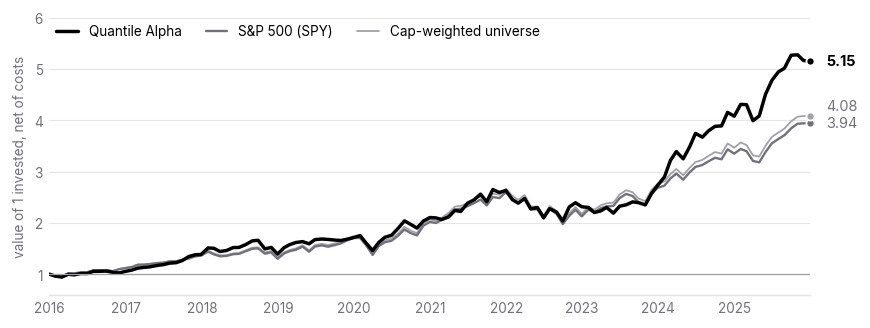

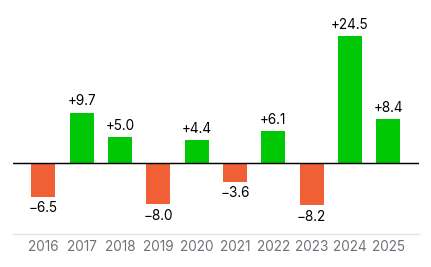

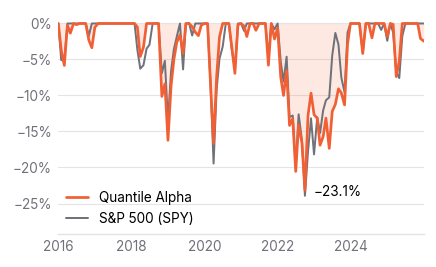

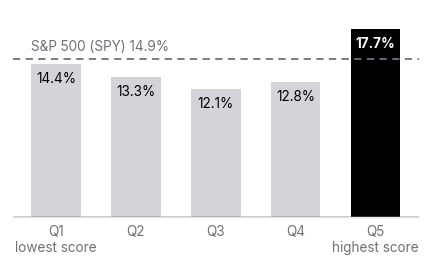

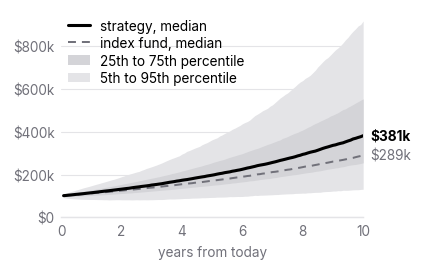

In [53]:
# ---- style of the prospectus: black and greys; green for gains and highlights; orange for risk and losses only ----
PX_DIR = os.path.join(OUT_DIR, "prospectus"); os.makedirs(PX_DIR, exist_ok=True)
PX_INK, PX_GREY, PX_LIGHT, PX_RULE, PX_BAND = "#000000", "#71717A", "#A1A1AA", "#E4E4E7", "#D4D4D8"
PX_GREEN, PX_ORANGE = "#00C805", "#F16034"

def prospectus_typeface():
    """Register Inter with matplotlib: from the repository folder when the notebook runs inside it, otherwise fetched
    from the public repository. Without it the figures are drawn in matplotlib's default typeface."""
    from matplotlib import font_manager
    files = ("Inter-Regular.ttf", "Inter-Bold.ttf")
    folder = "static"                                        # the repository keeps the typeface there (the app serves it too)
    if not all(os.path.exists(os.path.join(folder, f)) for f in files):
        folder = os.path.join(CACHE_DIR, "fonts"); os.makedirs(folder, exist_ok=True)
    try:
        for f in files:
            path = os.path.join(folder, f)
            if not os.path.exists(path):
                content = http_get("https://raw.githubusercontent.com/benediktproebstl/quantile-alpha/main/static/" + f).content
                with open(path, "wb") as out:
                    out.write(content)
            font_manager.fontManager.addfont(path)
        return ["Inter"]
    except Exception as exc:
        print(f"Inter is not available ({type(exc).__name__}); the figures use matplotlib's default typeface.")
        return list(plt.rcParams["font.family"])

PX_RC = {"font.family": prospectus_typeface(), "font.size": 7.5, "text.color": PX_INK, "axes.labelcolor": PX_GREY, "axes.labelsize": 7.5,
         "axes.edgecolor": PX_RULE, "axes.linewidth": 0.8, "xtick.color": PX_RULE, "ytick.color": PX_RULE, "xtick.labelcolor": PX_GREY,
         "ytick.labelcolor": PX_GREY, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "xtick.major.size": 0, "ytick.major.size": 0,
         "axes.grid": True, "axes.grid.axis": "y", "grid.color": PX_RULE, "grid.linewidth": 0.6, "axes.spines.left": False,
         "axes.spines.top": False, "axes.spines.right": False, "svg.fonttype": "none", "legend.frameon": False, "legend.fontsize": 7.5,
         "lines.solid_capstyle": "round", "figure.dpi": 130, "svg.hashsalt": "quantile-alpha"}

def px_save(fig, name):
    """Save a prospectus figure as SVG (set into the PDF) and as PNG (for viewing), then show it."""
    fig.savefig(os.path.join(PX_DIR, name + ".svg"), metadata={"Date": None}, transparent=True)   # sits on the page or on a tile
    fig.savefig(os.path.join(PX_DIR, name + ".png"), dpi=300)
    plt.show()

import matplotlib.dates as mdates
XD = PANEL["sessions"].reindex(NAV.index).to_numpy()                 # the month-end dates of the value series
DASH = (0, (4, 3))
minus = lambda text: text.replace("-", "\u2212")                    # a typographic minus sign in the figure labels

with plt.rc_context(PX_RC):
    # 1. cumulative performance, every series starting at 1
    fig, ax = plt.subplots(figsize=(6.69, 2.45)); fig.subplots_adjust(left=0.05, right=0.925, top=0.97, bottom=0.10)
    for key, color, lw in (("Universe", PX_LIGHT, 1.0), ("SPY", PX_GREY, 1.3), (STRAT, PX_INK, 1.9)):
        ax.plot(XD, NAV[key], color=color, lw=lw, label=LABEL[key])
    ends = {k: float(NAV[k].iloc[-1]) for k in (STRAT, "SPY", "Universe")}
    where, last = {}, -np.inf
    for k in sorted(ends, key=ends.get):                              # keep the value labels at the line ends apart
        where[k] = max(ends[k], last + 0.34); last = where[k]
    for k, color in ((STRAT, PX_INK), ("SPY", PX_GREY), ("Universe", PX_LIGHT)):
        ax.plot([XD[-1]], [ends[k]], "o", ms=4.5, color=color, mec="white", mew=1.0, clip_on=False, zorder=5)
        ax.annotate(f"{ends[k]:.2f}", (XD[-1], ends[k]), xytext=(XD[-1] + np.timedelta64(75, "D"), where[k]), va="center", ha="left",
                    fontsize=8, fontweight="bold" if k == STRAT else "normal", color=PX_INK if k == STRAT else PX_GREY, annotation_clip=False)
    ax.axhline(1.0, color=PX_LIGHT, lw=0.7)
    ax.set_ylim(0.6, math.ceil(max(ends.values()) + 0.4)); ax.set_xlim(XD[0], XD[-1])
    ax.set_ylabel("value of 1 invested, net of costs")
    handles, names = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], names[::-1], loc="upper left", ncol=3, handlelength=1.6, columnspacing=1.8, borderaxespad=0.1)
    px_save(fig, "px_cumulative_performance")

    # 2. calendar years: strategy minus SPY, in percentage points
    fig, ax = plt.subplots(figsize=(3.25, 2.0)); fig.subplots_adjust(left=0.02, right=0.98, top=0.96, bottom=0.11)
    gap_pp = yearly["Strategy minus SPY"] * 100
    xs = np.arange(len(gap_pp))
    ax.bar(xs, gap_pp, width=0.62, color=[PX_GREEN if v >= 0 else PX_ORANGE for v in gap_pp])
    for xk, v in zip(xs, gap_pp):
        ax.annotate(minus(f"{v:+.1f}"), (xk, v), xytext=(0, 2.5 if v >= 0 else -2.5), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=7.5, color=PX_INK)
    ax.axhline(0, color=PX_INK, lw=0.8); ax.grid(False); ax.set_yticks([])
    ax.set_xticks(xs, [str(y) for y in gap_pp.index]); ax.set_ylim(gap_pp.min() - 5.5, gap_pp.max() + 4.5)
    px_save(fig, "px_calendar_years")

    # 3. drawdowns: percentage below the previous peak
    fig, ax = plt.subplots(figsize=(3.25, 2.0)); fig.subplots_adjust(left=0.115, right=0.98, top=0.96, bottom=0.11)
    dd = DD[[STRAT, "SPY"]] * 100
    ax.fill_between(XD, dd[STRAT].to_numpy(), 0, color=PX_ORANGE, alpha=0.14, lw=0)
    ax.plot(XD, dd["SPY"], color=PX_GREY, lw=1.1, label=LABEL["SPY"])
    ax.plot(XD, dd[STRAT], color=PX_ORANGE, lw=1.5, label=LABEL[STRAT])
    low = dd[STRAT].idxmin()
    ax.annotate(minus(f"{dd[STRAT].min():.1f}%"), (PANEL["sessions"][low], dd[STRAT].min()), xytext=(5, -1), textcoords="offset points",
                ha="left", va="center", fontsize=7.5, color=PX_INK)
    ax.set_ylim(min(dd.min().min() * 1.22, -5), 1.5); ax.set_xlim(XD[0], XD[-1])
    ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))   # every second year fits
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: minus(f"{v:.0f}%")))
    handles, names = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], names[::-1], loc="lower left", ncol=1, handlelength=1.6, borderaxespad=0.2)
    px_save(fig, "px_drawdowns")

    # 4. average net return of the five score groups
    fig, ax = plt.subplots(figsize=(3.25, 2.0)); fig.subplots_adjust(left=0.02, right=0.98, top=0.96, bottom=0.17)
    q_ret = TQ["Average return p.a."] * 100
    ax.bar(np.arange(5), q_ret, width=0.62, color=[PX_BAND] * 4 + [PX_INK])
    for xk, v in enumerate(q_ret):                                        # the value sits inside its bar, clear of the benchmark line
        ax.annotate(f"{v:.1f}%", (xk, v), xytext=(0, -4), textcoords="offset points", ha="center", va="top", fontsize=7.5,
                    color="white" if xk == 4 else PX_INK, fontweight="bold" if xk == 4 else "normal")
    spy_pct = M.loc["SPY", "ann_return"] * 100
    ax.axhline(spy_pct, color=PX_GREY, lw=1.0, ls=DASH)
    ax.annotate(f"{LABEL['SPY']} {spy_pct:.1f}%", (-0.31, spy_pct), xytext=(0, 3), textcoords="offset points", ha="left", va="bottom",
                fontsize=7.5, color=PX_GREY)
    ax.grid(False); ax.set_yticks([]); ax.set_ylim(0, q_ret.max() + 1.6); ax.axhline(0, color=PX_INK, lw=0.8)
    ax.set_xticks(np.arange(5), ["Q1\nlowest score", "Q2", "Q3", "Q4", "Q5\nhighest score"])
    px_save(fig, "px_score_groups")

    # 5. Monte Carlo: range of outcomes for the strategy, with the index fund's median for comparison
    fig, ax = plt.subplots(figsize=(3.25, 2.0)); fig.subplots_adjust(left=0.135, right=0.85, top=0.96, bottom=0.17)
    w_s, w_b = W_MARKOV["strategy"] / 1000, W_MARKOV["benchmark"] / 1000
    yrs = np.arange(1, N_STEPS + 1) / 12
    ax.fill_between(yrs, np.percentile(w_s, 5, axis=0), np.percentile(w_s, 95, axis=0), color=PX_RULE, lw=0, label="5th to 95th percentile")
    ax.fill_between(yrs, np.percentile(w_s, 25, axis=0), np.percentile(w_s, 75, axis=0), color=PX_BAND, lw=0, label="25th to 75th percentile")
    ax.plot(yrs, np.median(w_b, axis=0), color=PX_GREY, lw=1.1, ls=DASH, label="index fund, median")
    ax.plot(yrs, np.median(w_s, axis=0), color=PX_INK, lw=1.7, label="strategy, median")
    for value, bold in ((float(np.median(w_s[:, -1])), True), (float(np.median(w_b[:, -1])), False)):
        ax.annotate(f"${value:,.0f}k", (yrs[-1], value), xytext=(4, 0), textcoords="offset points", ha="left", va="center", fontsize=7.5,
                    fontweight="bold" if bold else "normal", color=PX_INK if bold else PX_GREY, annotation_clip=False)
    ax.set_xlim(0, CFG.mc_years); ax.set_ylim(0, None); ax.set_xlabel("years from today")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: "$0" if v == 0 else f"${v:,.0f}k"))
    handles, names = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], names[::-1], loc="upper left", ncol=1, handlelength=1.6, borderaxespad=0.1, labelspacing=0.25)
    px_save(fig, "px_monte_carlo")

In [54]:
# ---- every number the prospectus quotes, with the text exactly as printed there and the section it comes from ----
KEY = []
def kf(key, value, text, source):
    KEY.append({"key": key, "value": value, "as printed": text, "source": source})

s, g_, b, e = M.loc[STRAT], BT["metrics_gross"].loc[STRAT], M.loc["SPY"], M.loc["Universe"]
usd = lambda v: f"${v:,.0f}"
kf("sample_first", str(R.index[0]), R.index[0].strftime("%B %Y"), "1"); kf("sample_last", str(R.index[-1]), R.index[-1].strftime("%B %Y"), "1")
kf("n_months", len(R), str(len(R)), "6.2"); kf("n_years", len(yearly), str(len(yearly)), "6.4")

# the rule's parameters, as the configuration holds them
month_name = lambda m: pd.Timestamp(2000, (m - 1) % 12 + 1, 1).strftime("%B")
kf("rule_lookback", CFG.lookback, str(CFG.lookback), "4.1"); kf("rule_skip", CFG.skip, str(CFG.skip), "4.1")
kf("rule_winsor", CFG.winsor_z, f"{CFG.winsor_z:.0f}", "4.1")
kf("rule_fraction", 1 / CFG.n_groups, {4: "quarter", 5: "fifth", 10: "tenth"}.get(CFG.n_groups, f"1/{CFG.n_groups}"), "4.2")
kf("rule_buffer", CFG.buffer, pct(CFG.buffer, 0), "4.2"); kf("rule_cap_multiple", CFG.max_cap_multiple, f"{CFG.max_cap_multiple:.0f}", "4.3")
kf("rule_trade_months", str(CFG.rebalance_months), " and ".join(month_name(m) for m in CFG.rebalance_months), "4.4")
kf("rule_reference_months", str(tuple((m - CFG.reference_lag - 1) % 12 + 1 for m in CFG.rebalance_months)),
   " and ".join(month_name(m - CFG.reference_lag) for m in CFG.rebalance_months), "4.4")
kf("rule_trades_per_year", len(CFG.rebalance_months), {1: "once", 2: "twice", 4: "four times"}.get(len(CFG.rebalance_months), f"{len(CFG.rebalance_months)} times"), "4.4")
kf("data_from", CFG.data_start, pd.Timestamp(CFG.data_start).strftime("%B %Y"), "2")
for name, row in (("s", s), ("g", g_), ("spy", b), ("uni", e)):
    kf(f"ret_{name}", row["ann_return"], pct(row["ann_return"]), "6.2"); kf(f"vol_{name}", row["ann_vol"], pct(row["ann_vol"]), "6.2")
    kf(f"sharpe_{name}", row["sharpe"], num(row["sharpe"]), "6.2"); kf(f"mdd_{name}", row["max_drawdown"], pct(row["max_drawdown"]), "6.3")
    kf(f"cagr_{name}", row["cagr"], pct(row["cagr"]), "6.2")
kf("vol_s_pts", s["ann_vol"] * 100, f"{s['ann_vol'] * 100:.0f}", "6.2")
for name, row in (("s", s), ("g", g_), ("uni", e)):
    kf(f"alpha_{name}", row["alpha"], pct(row["alpha"]), "6.2"); kf(f"beta_{name}", row["beta"], num(row["beta"]), "6.2")
    kf(f"ir_{name}", row["info_ratio"], num(row["info_ratio"]), "6.2")
kf("lead_pp", s["ann_return"] - b["ann_return"], f"{(s['ann_return'] - b['ann_return']) * 100:.1f}", "6.2")
kf("alpha_t", reg["t-statistic of alpha"], num(reg["t-statistic of alpha"]), "6.2"); kf("alpha_p", reg["p-value of alpha"], num(reg["p-value of alpha"]), "6.2")
kf("alpha_ci_low", reg["95% CI alpha p.a., low"], pct(reg["95% CI alpha p.a., low"]), "6.2"); kf("alpha_ci_high", reg["95% CI alpha p.a., high"], pct(reg["95% CI alpha p.a., high"]), "6.2")
kf("beta_ci_low", reg["95% CI beta, low"], num(reg["95% CI beta, low"]), "6.2"); kf("beta_ci_high", reg["95% CI beta, high"], num(reg["95% CI beta, high"]), "6.2")
kf("te_s", s["tracking_error"], pct(s["tracking_error"]), "6.2"); kf("months_ahead", s["share_months_ahead"], pct(s["share_months_ahead"], 0), "6.2")
kf("worst_month_s", s["worst_month"], pct(s["worst_month"]), "6.2"); kf("worst_month_spy", b["worst_month"], pct(b["worst_month"]), "6.2")
for name, key in (("s", STRAT), ("spy", "SPY"), ("uni", "Universe")):
    kf(f"value_{name}", NAV[key].iloc[-1], f"{NAV[key].iloc[-1]:.2f}", "6.1"); kf(f"usd10k_{name}", 10_000 * NAV[key].iloc[-1], usd(10_000 * NAV[key].iloc[-1]), "6.1")
gap = yearly["Strategy minus SPY"]
kf("years_ahead", ahead, str(ahead), "6.4"); kf("best_gap", gap.max(), f"{gap.max() * 100:.1f}", "6.4"); kf("best_gap_year", int(gap.idxmax()), str(gap.idxmax()), "6.4")
kf("worst_gap", gap.min(), f"{abs(gap.min()) * 100:.1f}", "6.4"); kf("worst_gap_year", int(gap.idxmin()), str(gap.idxmin()), "6.4")
kf("worst_year_s", yearly[LABEL[STRAT]].min(), pct(yearly[LABEL[STRAT]].min()), "6.4"); kf("worst_year_s_year", int(yearly[LABEL[STRAT]].idxmin()), str(yearly[LABEL[STRAT]].idxmin()), "6.4")
kf("worst_year_spy", yearly[LABEL["SPY"]].loc[yearly[LABEL[STRAT]].idxmin()], pct(yearly[LABEL["SPY"]].loc[yearly[LABEL[STRAT]].idxmin()]), "6.4")
for y, row in yearly.iterrows():                                   # the calendar-year table of the prospectus
    kf(f"yr{y}_s", row[LABEL[STRAT]], pct(row[LABEL[STRAT]]), "6.4"); kf(f"yr{y}_spy", row[LABEL["SPY"]], pct(row[LABEL["SPY"]]), "6.4")
kf("lead_2023", lead_to_2023, pct(lead_to_2023, 0), "8.3"); kf("lead_end", lead_total, pct(lead_total, 0), "8.3"); kf("late_share", late_share, pct(late_share, 0), "8.3")
ep = drawdown_episodes(NAV[STRAT], top=1).iloc[0]
kf("dd_months", ep["months under water"], str(int(ep["months under water"])), "6.3"); kf("dd_peak", str(ep["peak"]), ep["peak"].strftime("%B %Y"), "6.3")
kf("dd_trough", str(ep["trough"]), ep["trough"].strftime("%B %Y"), "6.3")
kf("dd_recovered", str(ep["recovered"]), ep["recovered"].strftime("%B %Y") if ep["recovered"] is not None and not pd.isna(ep["recovered"]) else "not yet", "6.3")
kf("years_behind", len(yearly) - ahead, str(len(yearly) - ahead), "6.4")
kf("rolling12_ahead", (w12 > 0).mean(), pct((w12 > 0).mean(), 0), "8.5"); kf("r_squared", MM["r_squared"], num(MM["r_squared"]), "6.2")
kf("rf_avg", 12 * BT["rf"].mean(), pct(12 * BT["rf"].mean()), "6.2")
kf("first_trade", str(PANEL["sessions"][BT["start"]].date()), f"{PANEL['sessions'][BT['start']]:%d %B %Y}".lstrip("0"), "5")
kf("n_rebalances", len(SEL), str(len(SEL)), "5")

# holdings, trading and costs
kf("holdings_avg", t5["avg_holdings"], f"{t5['avg_holdings']:.0f}", "6.4"); kf("holdings_eff", t5["avg_effective_holdings"], f"{t5['avg_effective_holdings']:.0f}", "6.4")
kf("holdings_min", SEL["bought"].min(), str(int(SEL["bought"].min())), "5"); kf("holdings_max", SEL["bought"].max(), str(int(SEL["bought"].max())), "5")
kf("top10_avg", SEL["ten largest weights"].mean(), pct(SEL["ten largest weights"].mean(), 0), "6.4"); kf("max_weight_reached", t5["max_weight"], pct(t5["max_weight"]), "6.4")
kf("weight_limit", CFG.max_weight, pct(CFG.max_weight, 0), "4.3"); kf("turnover", t5["one_way_turnover_pa"], pct(t5["one_way_turnover_pa"], 0), "6.4")
kf("cost_pa", t5["cost_pa"], pct(t5["cost_pa"], 2), "6.4"); kf("cost_bp", CFG.cost_rate * 1e4, f"{CFG.cost_rate * 1e4:.0f}", "4.6")
kf("break_even_bp", BE["SPY"]["break_even"] * 1e4, f"{BE['SPY']['break_even'] * 1e4:.0f}", "8.2")
last_m = BT["formation_months"][-1]; w_last = TARGETS[last_m].sort_values(ascending=False)
kf("last_rebalance", str(PANEL["sessions"][last_m].date()), f"{PANEL['sessions'][last_m]:%d %B %Y}".lstrip("0"), "5")
kf("holdings_last", len(w_last), str(len(w_last)), "5"); kf("top10_last", w_last.head(10).sum(), pct(w_last.head(10).sum(), 0), "5")
for i, (sym, w) in enumerate(w_last.head(10).items(), start=1):
    kf(f"top{i}_name", sym, FORMS[last_m].loc[sym, "name"], "5"); kf(f"top{i}_weight", w, pct(w), "5")
kf("sector_max", W5.max().max(), pct(W5.max().max(), 0), "9.1"); kf("sector_max_name", W5.max().idxmax(), W5.max().idxmax(), "9.1")

# data
kf("coverage_first", COVERAGE["coverage"].iloc[0], pct(COVERAGE["coverage"].iloc[0], 0), "3.3"); kf("coverage_last", COVERAGE["coverage"].iloc[-1], pct(COVERAGE["coverage"].iloc[-1], 0), "3.3")
kf("eligible_first", COVERAGE["eligible"].iloc[0], str(int(COVERAGE["eligible"].iloc[0])), "3.3"); kf("eligible_last", COVERAGE["eligible"].iloc[-1], str(int(COVERAGE["eligible"].iloc[-1])), "3.3")
kf("bias_pp", bias, f"{bias * 100:.1f}", "5.2"); kf("uni_corr", uni["Correlation of monthly returns"], f"{uni['Correlation of monthly returns']:.3f}", "5.2")
kf("spmo_backtest", rep["Average return p.a."], pct(rep["Average return p.a."]), "5.2"); kf("spmo_fund", rep["Fund, return p.a."], pct(rep["Fund, return p.a."]), "5.2")
kf("spmo_corr", rep["Correlation of monthly returns"], f"{rep['Correlation of monthly returns']:.2f}", "5.2")
kf("spmo_year_low", years["Difference"].min(), f"{abs(years['Difference'].min()) * 100:.1f}", "5.2"); kf("spmo_year_high", years["Difference"].max(), f"{years['Difference'].max() * 100:.1f}", "5.2")
kf("gates_passed", int((gates["passed"] == "PASS").sum()), str(int((gates["passed"] == "PASS").sum())), "3.4"); kf("gates_total", len(gates), str(len(gates)), "3.4")
kf("tests", len(TEST_TABLE), str(len(TEST_TABLE)), "11.1"); kf("checks", len(CHECKS), str(len(CHECKS)), "11.2")
kf("data_retrieved", LOG.loc[LOG["provider"].str.startswith("Yahoo"), "retrieved_utc"].min(),
   f"{pd.Timestamp(LOG.loc[LOG['provider'].str.startswith('Yahoo'), 'retrieved_utc'].min()):%d %B %Y}".lstrip("0"), "11.4")

# evidence on the score, uncertainty and sensitivities
for i, q in enumerate(QUINT, start=1):
    kf(f"q{i}_ret", TQ.loc[q, "Average return p.a."], pct(TQ.loc[q, "Average return p.a."]), "7")
kf("spread_pp", sp_n["mean"], f"{sp_n['mean'] * 100:.1f}", "7"); kf("spread_t", sp_n["t_hac"], num(sp_n["t_hac"]), "7"); kf("slope_t", slope["t_simple"], num(slope["t_simple"]), "7")
kf("boot_low", b1["ci_low"], f"{b1['ci_low'] * 100:+.1f}", "8.6"); kf("boot_high", b1["ci_high"], f"{b1['ci_high'] * 100:+.1f}", "8.6"); kf("boot_below", b1["share_below_zero"], pct(b1["share_below_zero"], 0), "8.6")
kf("random_pctile", pctile_ret, f"{pctile_ret * 100:.1f}", "8.7"); kf("random_n", CFG.random_portfolios, f"{CFG.random_portfolios:,}", "8.7")
sens_ret = lambda family, name: SENS.loc[(family, name), "Average return p.a."]
for key, family, name in (("sens_equal", "weighting", "Equal weights"), ("sens_cap", "weighting", "Market value only (no score)"),
                          ("sens_nolimit", "weighting", "No weight limits"), ("sens_top10", "selection", "Top 10%"),
                          ("sens_100", "selection", "One fifth of the index (100 stocks)"), ("sens_fewer", "selection", "One stock fewer at every rebalance"),
                          ("sens_more", "selection", "One stock more at every rebalance"), ("sens_nobuffer", "selection", "No buffer rule"),
                          ("sens_norisk", "signal", "No risk adjustment"), ("sens_quarterly", "rebalancing frequency", "Quarterly"),
                          ("sens_yearly", "rebalancing frequency", "Once a year (March)"), ("sens_cost50", "transaction cost", "50 bp")):
    kf(key, sens_ret(family, name), pct(sens_ret(family, name)), "8.1")
    kf(key + "_vs_spy", SENS.loc[(family, name), "vs SPY p.a."], f"{SENS.loc[(family, name), 'vs SPY p.a.'] * 100:+.1f}", "8.1")
kf("sens_nolimit_maxw", SENS.loc[("weighting", "No weight limits"), "Largest weight reached"], pct(SENS.loc[("weighting", "No weight limits"), "Largest weight reached"], 0), "8.1")
lagging = own_gap[own_gap < 0]             # the strategy against SPY in the five worst months for high against low scores
kf("worst_rel_count", len(lagging), str(len(lagging)), "7")
kf("worst_rel_low", abs(lagging.max()), f"{abs(lagging.max()) * 100:.1f}", "7"); kf("worst_rel_high", abs(lagging.min()), f"{abs(lagging.min()) * 100:.1f}", "7")

# Monte Carlo and the retail example
kf("mc_start", START_VALUE, usd(START_VALUE), "10"); kf("mc_years", CFG.mc_years, str(CFG.mc_years), "10"); kf("mc_paths", CFG.mc_paths, f"{CFG.mc_paths:,}", "10")
for key, col in (("s", "Strategy, historical alpha"), ("b", "Index fund"), ("s0", "Strategy, alpha = 0")):
    kf(f"mc_median_{key}", MC.loc["median final value", col], usd(round(MC.loc["median final value", col], -3)), "10")
kf("mc_p5", s_mc["5th percentile"], usd(round(s_mc["5th percentile"], -3)), "10"); kf("mc_p95", s_mc["95th percentile"], usd(round(s_mc["95th percentile"], -3)), "10")
kf("mc_loss1", s_mc["probability of a loss after 1 year"], pct(s_mc["probability of a loss after 1 year"], 0), "10")
kf("mc_loss3", s_mc["probability of a loss after 3 years"], pct(s_mc["probability of a loss after 3 years"], 0), "10")
kf("mc_loss10", s_mc["probability of a loss at the horizon"], pct(s_mc["probability of a loss at the horizon"], 0), "10")
kf("mc_dd30", s_mc["probability of a drawdown worse than 30%"], pct(s_mc["probability of a drawdown worse than 30%"], 0), "10")
kf("mc_dd30_coin", DESIGN.loc["probability of a drawdown worse than 30%", "Independent coin flip"], pct(DESIGN.loc["probability of a drawdown worse than 30%", "Independent coin flip"], 0), "10")
kf("mc_behind", behind, pct(behind, 0), "10"); kf("mc_behind0", behind0, pct(behind0, 0), "10")
kf("mc_recession_share", SHARE, pct(SHARE, 0), "10"); kf("mc_recession_stays", TM[1, 1], pct(TM[1, 1], 0), "10")
kf("mc_regime_from", CFG.mc_regime_start, P(CFG.mc_regime_start).strftime("%Y"), "10"); kf("mc_market_from", CFG.mc_market_start, P(CFG.mc_market_start).strftime("%Y"), "10")
kf("mc_recessions", len(hist_sp), str(len(hist_sp)), "10"); kf("mc_rf", (1 + RF_M) ** 12 - 1, pct((1 + RF_M) ** 12 - 1), "10")
base_case = RETAIL.iloc[:, 0]
kf("retail_capital", CAPITAL, usd(CAPITAL), "9.2"); kf("retail_positions", base_case["holdings"], f"{base_case['holdings']:.0f}", "9.2")
kf("retail_largest", base_case["largest position"], usd(base_case["largest position"]), "9.2"); kf("retail_smallest", base_case["smallest position"], usd(base_case["smallest position"]), "9.2")
kf("retail_below_one", base_case["positions smaller than one share"], f"{base_case['positions smaller than one share']:.0f}", "9.2")
kf("retail_orders", base_case["historical orders per year"], f"{round(base_case['historical orders per year'], -1):.0f}", "9.2")
kf("retail_cost_usd", base_case["historical trading cost p.a. (USD)"], usd(round(base_case["historical trading cost p.a. (USD)"], -1)), "9.2")

KEYFIG = pd.DataFrame(KEY).set_index("key")
assert KEYFIG.index.is_unique and not KEYFIG["as printed"].isin(["n/a", "nan"]).any()
savetable(KEYFIG, "tab_prospectus_key_figures")
print(f"{len(KEYFIG)} key figures for the prospectus written; five figures saved to {PX_DIR} as SVG and PNG")
display(KEYFIG[["as printed", "source"]].head(12))

223 key figures for the prospectus written; five figures saved to outputs/prospectus as SVG and PNG


,as printed,source
key,,
sample_first,January 2016,1
sample_last,December 2025,1
n_months,120,6.2
n_years,10,6.4
rule_lookback,12,4.1
rule_skip,1,4.1
rule_winsor,3,4.1
rule_fraction,fifth,4.2
rule_buffer,20%,4.2


### 12.7 Files written by this notebook

In [55]:
written = []
for folder in ("figures", "tables", "prospectus"):
    for name in sorted(os.listdir(os.path.join(OUT_DIR, folder))):
        written.append({"folder": f"{OUT_DIR}/{folder}", "file": name, "kB": round(os.path.getsize(os.path.join(OUT_DIR, folder, name)) / 1024, 1)})
FILES = pd.DataFrame(written)
print(f"{len(FILES)} files written: {int((FILES['folder'].str.endswith('figures')).sum())} figures (200 dpi PNG), "
      f"{int((FILES['folder'].str.endswith('tables')).sum())} tables (CSV, full precision) and "
      f"{int((FILES['folder'].str.endswith('prospectus')).sum())} files for the prospectus, {FILES['kB'].sum() / 1024:.1f} MB in total.")
display(FILES.set_index("file"))
print(f"total run time: {(dt.datetime.now(dt.timezone.utc) - RUN_STARTED).total_seconds() / 60:.1f} minutes")

73 files written: 18 figures (200 dpi PNG), 45 tables (CSV, full precision) and 10 files for the prospectus, 2.6 MB in total.


,folder,kB
file,,
fig_bootstrap_intervals.png,outputs/figures,61.9
fig_coverage.png,outputs/figures,79.6
fig_cumulative_performance.png,outputs/figures,124.5
fig_drawdowns.png,outputs/figures,127.4
fig_mc_design_comparison.png,outputs/figures,126.5
...,...,...
px_drawdowns.svg,outputs/prospectus,18.6
px_monte_carlo.png,outputs/prospectus,63.8
px_monte_carlo.svg,outputs/prospectus,24.0


total run time: 0.6 minutes
